# <span style="color:darkorange">Analisis Efisiensi Promo dan Retensi Pengguna Tokopedia</span>
**Capstone Modul 3 — Studi Kasus Data Analyst E-commerce | Periode analisis: Januari 2023 – Desember 2024**

<a id="RINGKASAN-EKSEKUTIF"></a>
# <span style="color:darkorange">RINGKASAN EKSEKUTIF</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Tokopedia, yang kini beroperasi dalam satu ekosistem dengan TikTok Shop, tercatat menguasai sekitar 34% pangsa pasar GMV e-commerce nasional pada 2024. Volume transaksi yang besar tersebut selama ini banyak ditopang oleh insentif harga — kampanye Waktu Indonesia Belanja (WIB), cashback, dan subsidi ongkos kirim — yang efektif mendatangkan transaksi, tetapi berisiko hanya menarik pembeli yang pergi begitu promo berhenti.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Secara internal, tim Growth & Marketing melaporkan rasio CLV:CAC mulai tergerus mendekati bahkan di bawah acuan sehat 3:1, sementara repeat order rate turut menurun dalam dua tahun terakhir. Tim Operations juga melaporkan kenaikan komplain pasca-pembelian pada periode yang sama.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Proyek ini mengolah lima tabel (users, sellers, transactions, deliveries, customer service tickets) yang diekstrak dari Google BigQuery, membersihkannya dalam satu alur, menjaga integritas relasi antar tabel, lalu memuat kembali data bersih ke BigQuery sebagai dasar analisis efisiensi promo dan retensi pengguna. Setelah cleansing, tersedia 268.076 transaksi bersih, 260.208 data pengiriman, dan 31.428 tiket layanan pelanggan yang konsisten satu sama lain.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Analisis difokuskan pada pertanyaan: <strong>"Apakah masalah fulfillment membuat Tokopedia kehilangan peluang repeat revenue meskipun sudah mengalokasikan insentif promosi?"</strong>
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Temuan utama:</strong>
</p>

1. **Promo pada order pertama tidak berkaitan dengan repeat purchase.** Repeat 60 hari pengguna dengan promo 74,74% vs tanpa promo 74,70% (p = 0,921), konsisten di semua kanal akuisisi dan tidak berbeda antara pengguna churn dan bertahan.
2. **Keterlambatan pengiriman berkaitan kuat dengan hilangnya repeat purchase.** Repeat 60 hari turun dari 79,2% (tepat waktu) menjadi 66,2% (terlambat). Gap ini muncul di seluruh 29 segmen yang diuji (−10,2 s.d. −21,5 pp) dan tetap −12,5 pp setelah pengguna dibandingkan di dalam kombinasi zona, kategori, kanal, kampanye, dan promo yang sama. Pola memburuk seiring lama keterlambatan (22,6% bila terlambat > 5 hari), pada pengiriman gagal (27,1%), dan pada pengguna yang mengeluhkan keterlambatan (17,9%).
3. **Promo tidak menutup gap tersebut** (gap pada pengguna berpromo −12,7 pp vs tanpa promo −13,7 pp; selisih tidak signifikan, p = 0,27), sementara 34,9% pengiriman terlambat dan pengiriman berlabel zona luar_pulau (kelas SLA panjang) paling berisiko (42,9% terlambat).
4. **Potensi nilai yang hilang:** ±1.697 pengguna dengan order pertama terlambat berpotensi tidak kembali, setara **±Rp2,10 miliar GMV repeat 60 hari** selama ±22 bulan kohort, ditambah ±Rp1,32 miliar dari pengiriman gagal. Bila dihitung dengan horizon belanja 365 hari, GMV berisiko mencapai **±Rp5,03 miliar per tahun**. Rp246 juta promo telah dikeluarkan untuk pengguna terlambat yang akhirnya tidak kembali.
5. **Promo tidak efisien.** Promo tercatat ±Rp6,39 miliar per tahun (4,45% dari GMV completed ±Rp143,5 miliar per tahun). Sebanyak **59% anggaran promo (±Rp3,77 miliar per tahun) terserap oleh 4,4% order yang promonya melebihi nilai belanja**, padahal GMV kelompok ini hanya ±Rp1,44 miliar per tahun (median promo Rp750.647 vs median belanja Rp235.980), tanpa retensi maupun GMV 365 hari yang lebih baik. Sebanyak 96% di antaranya berasal dari voucher bernominal Rp400 ribu–Rp1 juta yang diterbitkan tanpa melihat nilai belanja dan tersebar merata di seluruh pengguna, seller, dan tanggal. Polanya menunjukkan aturan voucher yang keliru, bukan penyalahgunaan oleh sekelompok akun.
6. **Lonjakan keterlambatan saat kampanye berasal dari satu kurir pada satu kelas rute:** GoTo Logistics pada label luar_pulau naik dari 38,6% ke 67,7% saat kampanye, sedangkan kurir lain tetap ±39,5%. Label `shipping_zone` sendiri tidak mencerminkan jarak geografis (tidak cocok dengan kota seller → kota tujuan), sehingga temuan zona dibaca sebagai kelas SLA.
7. **Sebagian besar keterlambatan adalah soal janji:** 81,5% keterlambatan hanya lewat 1–2 hari dari SLA, dan janji +1 hari akan menurunkan tingkat keterlambatan dari 34,9% ke 12,2%. Dampaknya juga dapat dipulihkan: pengguna yang terlambat di order pertama tetapi tepat waktu di order kedua kembali dengan tingkat yang sama seperti pengguna yang selalu tepat waktu. Sebaliknya, mempercepat penanganan tiket saja tidak terlihat memulihkan: selisih repeat tiket cepat vs lambat (+22,3 pp) hilang setelah keparahan kasus dikontrol (+0,5 pp, p = 0,84).

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Rekomendasi utama:</strong> (1) perbaiki aturan voucher: batas promo per order (promo tidak melebihi nilai belanja) dan minimum belanja untuk voucher ≥ Rp400 ribu — penghematan ±Rp2,33 miliar per tahun; (2) gunakan sebagian kecil penghematan untuk voucher pemulihan terarah pada kasus pengiriman berat (pada kenaikan retensi 10 pp: tambahan GMV ±Rp1,31 miliar per tahun dengan biaya voucher ±Rp15,4 juta; kelayakan finansialnya diuji lewat pilot karena margin aktual tidak tersedia); (3) jalankan langkah operasional berbiaya rendah — estimasi tiba realistis (SLA + 1 hari), notifikasi proaktif, dan pengalihan volume label luar_pulau dari GoTo Logistics ke kurir lain saat kampanye. Investasi gudang regional dan kargo massal belum layak bila hanya dibenarkan oleh manfaat retensi. Seluruh temuan bersifat asosiasi dan perlu divalidasi dengan pilot.
</p>

<a id="DAFTAR-SISI"></a>
# <span style="color:darkorange">DAFTAR ISI</span>

[**RINGKASAN EKSEKUTIF**](#RINGKASAN-EKSEKUTIF)

[**DAFTAR ISI**](#DAFTAR-SISI)

[**Business Understanding**](#Business-Understanding)

&emsp;[Latar Belakang](#Latar-Belakang)

&emsp;[Stakeholder](#Stakeholder)

&emsp;[Pernyataan Masalah & Goal](#Pernyataan-Masalah-&-Goal)

[**Data Extract**](#Data-Extract)

&emsp;[Extract Data from BigQuery](#Extract-Data-from-BigQuery)

[**Data Cleaning**](#Data-Cleaning)

&emsp;[Missing Values](#Missing-Values)

&emsp;[Data Types](#Data-Types)

&emsp;[Standardisasi Kategori](#Standardisasi-Kategori)

&emsp;[Data Duplicates](#Data-Duplicates)

&emsp;[Data Range Constrains](#Data-Range-Constrains)

&emsp;[Outliers](#Outliers)

&emsp;[Integritas Relasi Antar Tabel](#Integritas-Relasi-Antar-Tabel)

&emsp;[Ringkasan Data Cleaning](#Ringkasan-Data-Cleaning)

[**Data Merging**](#Data-Merging)

[**Load Data to BigQuery**](#Load-Data-to-BigQuery)

[**Data Analysis**](#Data-Analysis)

&emsp;[Exploratory Data Analysis](#Exploratory-Data-Analysis)

&emsp;[Analisis Lanjutan (Deep Dive)](#Analisis-Lanjutan)

&emsp;[Visualisasi Eksekutif](#Visualisasi-Eksekutif)

[**Penutup**](#PENUTUP)

&emsp;[Kesimpulan](#Kesimpulan)

&emsp;[Rekomendasi](#Rekomendasi)

<a id="Business-Understanding"></a>
# <span style="color:darkorange">Business Understanding</span>


<a id="Latar-Belakang"></a>
## <span style="color:darkorange">Latar Belakang</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Industri e-commerce Indonesia mencatatkan Gross Merchandise Value (GMV) sekitar <strong>US$65 miliar pada 2024</strong>, tumbuh 11% dibanding tahun sebelumnya<sup>1</sup>. Tokopedia, yang kini beroperasi dalam satu ekosistem dengan TikTok Shop, menguasai sekitar <strong>34% pangsa pasar GMV nasional</strong> pada tahun yang sama<sup>2</sup>. Namun skala transaksi yang besar tidak otomatis berarti model bisnis yang sehat, terutama jika volume tersebut banyak ditopang oleh insentif harga yang mahal untuk terus dipertahankan.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Riset Snapcart Indonesia menemukan bahwa <strong>51% konsumen belanja online di Indonesia tergolong <em>discount seekers</em></strong> — keputusan belanjanya didorong oleh ketersediaan promo, bukan loyalitas terhadap platform<sup>3</sup>. Temuan ini relevan dengan strategi "bakar uang" yang dijalankan Tokopedia melalui kampanye WIB, cashback, dan subsidi ongkir. Survei Populix (2023) sempat mencatat Tokopedia sebagai platform dengan tingkat loyalitas pengguna tertinggi dibanding Shopee dan Lazada<sup>4</sup>, namun tren data internal 2023–2024 justru bergerak ke arah sebaliknya.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Grup GoTo — induk Tokopedia — pada kuartal IV 2022 memangkas belanja insentif dan pemasaran produk sebesar <strong>Rp2,8 triliun (34% YoY)</strong> dan menargetkan pengurangan <em>cash burn</em> 2023 sebesar 60–65% dibanding 2022, dengan pergeseran fokus ke "pengguna berkualitas tinggi yang menguntungkan"<sup>6</sup>. Secara internal, tim Growth & Marketing melaporkan rasio CLV:CAC mulai tergerus mendekati bahkan di bawah acuan sehat 3:1<sup>5</sup>, sementara repeat order rate turun dalam dua tahun terakhir. Tim Operations juga melaporkan kenaikan komplain pasca-pembelian pada periode yang sama (konteks pendukung).
</p>

---

<sup>1</sup> Google, Temasek & Bain and Company — *e-Conomy SEA 2024*. blog.google/intl/id-id/e-conomy-sea-2024-perekonomian-digital-indonesia-akan-mencapai-gmv-90-miliar-pada-tahun-2024/

<sup>2</sup> Kementerian Perdagangan RI — *Laporan Kinerja Perdagangan Melalui Sistem Elektronik (PMSE) 2025*. bkperdag.kemendag.go.id/unduhan-file/a11ba920-123c-4a4f-856b-cdbb1f0f64c4

<sup>3</sup> Snapcart Indonesia — *Karakteristik Perilaku Konsumen dan Preferensi dalam Berbelanja Online* (via youngster.id). youngster.id/headline/digital-business/ini-karakteristik-perilaku-konsumen-belanja-online/

<sup>4</sup> Populix via Katadata.co.id — *Survei: Pengguna Tokopedia Lebih Loyal Ketimbang Shopee dan Lazada*. katadata.co.id/digital/e-commerce/64edaab826c26/survei-pengguna-tokopedia-lebih-loyal-ketimbang-shopee-dan-lazada

<sup>5</sup> TrueProfit — *LTV:CAC for E-commerce: Definition, Benchmark, Tips to Improve*. trueprofit.io/blog/ltv-cac-ratio

<sup>6</sup> GoTo Group — *4Q and FY22 Earnings Call Transcript*. assets.tokopedia.net/asts/4Q22%20Earnings%20Script%20vUploadB.pdf


<a id="Stakeholder"></a>
## <span style="color:darkorange">Stakeholder</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Tim Growth & Marketing Tokopedia</strong><br>Pemilik budget promo (WIB, cashback, voucher, subsidi ongkir) dan pihak yang melaporkan penurunan rasio CLV:CAC serta repeat order rate. Membutuhkan dasar data untuk mengalokasikan promo ke segmen yang memberi nilai jangka panjang.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Manajemen Tokopedia (unit bisnis di bawah Grup GoTo)</strong><br>Menghadapi tekanan efisiensi yang sejalan dengan langkah GoTo di level korporasi, sehingga membutuhkan insight kuantitatif untuk menyeimbangkan pertumbuhan transaksi dan profitabilitas.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Tim Operations</strong><br>Melaporkan kenaikan komplain terkait pengalaman pasca-pembelian (pengiriman dan layanan pelanggan). Data deliveries dan tickets menjadi konteks pendukung untuk melihat faktor lain di luar promo.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Pemilik data / tim Data Engineering</strong><br>Pihak yang perlu menindaklanjuti temuan kualitas data (definisi nominal, konflik primary key, relasi antar tabel) yang dilaporkan pada bagian rekomendasi.
</p>


<a id="Pernyataan-Masalah-&-Goal"></a>
## <span style="color:darkorange">Pernyataan Masalah & Goal</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Selama periode Januari 2023 – Desember 2024, evaluasi internal Tokopedia menunjukkan penurunan efisiensi alokasi budget promo dan retensi pengguna, dengan indikasi:
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>1. Rasio CLV:CAC tergerus</strong><br>Tim Growth & Marketing melaporkan rasio CLV:CAC mendekati bahkan di bawah acuan sehat 3:1.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>2. Penurunan repeat order rate</strong><br>Proporsi pengguna yang kembali bertransaksi dilaporkan menurun dalam dua tahun terakhir.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Problem Statement Analisis — Revenue Leakage from First-Purchase Fulfillment Failure</strong><br>Pada dataset transaksi Tokopedia periode 2023–2024, penggunaan promo pada pembelian pertama yang teramati tidak menunjukkan perbedaan repeat purchase 60 hari yang signifikan antara pelanggan yang menerima dan tidak menerima promo. Sebaliknya, pelanggan yang mengalami keterlambatan pengiriman menunjukkan tingkat pembelian ulang yang jauh lebih rendah (kedua pernyataan ini divalidasi pada bagian Data Analysis). Temuan ini menimbulkan pertanyaan strategis mengenai efektivitas alokasi insentif promosi ketika pengalaman pascapembelian berpotensi menghambat terbentuknya loyalitas pelanggan.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Indikasi tambahan dari data — efisiensi promo:</strong>
</p>

- Promo tercatat **±Rp6,39 miliar per tahun**, setara **4,45% dari GMV completed** (±Rp143,5 miliar per tahun).
- **10.299 order completed (4,38%)** — 11.667 transaksi atau 4,36% bila semua status dihitung — memiliki promo yang **melebihi nilai belanja**. Kelompok kecil ini menyerap **59% anggaran promo (±Rp3,77 miliar per tahun)**, sedangkan GMV-nya hanya ±Rp1,44 miliar per tahun (promo ±2,6× GMV yang dihasilkannya).
- Pada kelompok ini, **median promo Rp750.647 jauh di atas median belanja Rp235.980 (±3,2×)**. Pola ini tidak dapat dijelaskan oleh kemungkinan `total_amount` sudah dikurangi promo, dan pengguna yang menerimanya tidak lebih sering kembali berbelanja.

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Pertanyaan utama:</strong> <em>"Apakah masalah fulfillment membuat Tokopedia kehilangan peluang repeat revenue meskipun sudah mengalokasikan insentif promosi?"</em><br>Analisis bertujuan mengidentifikasi faktor yang paling berkaitan dengan hilangnya peluang repeat purchase, menilai efisiensi pengeluaran promo, mengukur potensi GMV yang dapat dipertahankan, dan menentukan segmen pelanggan yang paling relevan untuk intervensi operasional maupun promosi — dengan membedakan temuan korelasional dari dampak bisnis yang masih memerlukan validasi kausal.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Analisis ini diarahkan pada dua goal:
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Goal 1 — Optimalisasi Budget Promo:</strong> memastikan alokasi promo mendorong nilai jangka panjang (CLV), bukan sekadar transaksi sesaat.<br><strong>Baseline:</strong> promo ±Rp6,39 miliar per tahun (4,45% dari GMV completed); 59% di antaranya terserap oleh 4,4% order dengan promo melebihi nilai belanja; promo pada order pertama tidak berkaitan dengan repeat purchase.<br><strong>Usulan target:</strong> menerapkan batas promo maksimal sebesar nilai belanja, sehingga pengeluaran promo turun ±Rp2,33 miliar per tahun (±37% anggaran promo; rasio promo terhadap GMV dari 4,45% menjadi ±2,8%) tanpa penurunan repeat 60 hari; sebagian kecil penghematan dialihkan ke voucher pemulihan terarah. Target perlu disepakati dengan tim Growth & Marketing setelah porsi promo yang ditanggung platform vs seller diketahui.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Goal 2 — Peningkatan Retensi Pengguna:</strong> meningkatkan proporsi pengguna yang kembali bertransaksi secara berkelanjutan.<br><strong>Baseline:</strong> repeat 60 hari 74,7%; pengguna dengan order pertama terlambat (13.596 orang) hanya 66,2% dibanding 79,2% bila tepat waktu; tingkat keterlambatan 34,9%.<br><strong>Usulan target:</strong> menutup 25% gap retensi akibat keterlambatan, setara ±424 repeat customer tambahan dan ±Rp524 juta GMV repeat 60 hari pada kohort yang dianalisis (skenario berbasis asosiasi, bukan dampak kausal yang terjamin).
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pertanyaan analisis (dari pertanyaan pemantik brief):
</p>

1. Apakah efektivitas promo (dalam mendorong repeat order) berbeda antar kanal akuisisi (organic vs ads vs referral vs affiliate)?
2. Segmen user seperti apa yang paling banyak menyerap budget promo, tetapi memberi kontribusi paling rendah terhadap repeat order atau profitabilitas?
3. Apakah pola penggunaan promo pada user yang berhenti bertransaksi (churn) berbeda dari user yang tetap bertahan?
4. Selain variabel promo, adakah faktor lain — misalnya karakteristik transaksi awal pengguna — yang berkaitan dengan keputusan bertransaksi kembali?
5. Berapa estimasi potensi dampak finansial (revenue at risk) dari pola yang ditemukan, dan rekomendasi apa yang paling prioritas?

<a id="Data-Extract"></a>
# <span style="color:darkorange">Data Extract</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Data mentah kelima tabel disimpan pada dataset <code>datalake_tokped</code> di Google BigQuery. Relasi antar tabel mengikuti ERD berikut: <code>transactions</code> adalah tabel fakta utama (PK <code>order_id</code>) yang terhubung ke dimensi <code>users</code> dan <code>sellers</code> (1 : 0..N), ke <code>deliveries</code> (1 : 0..1) dan ke <code>customer_service_tickets</code> (1 : 0..N).
</p>

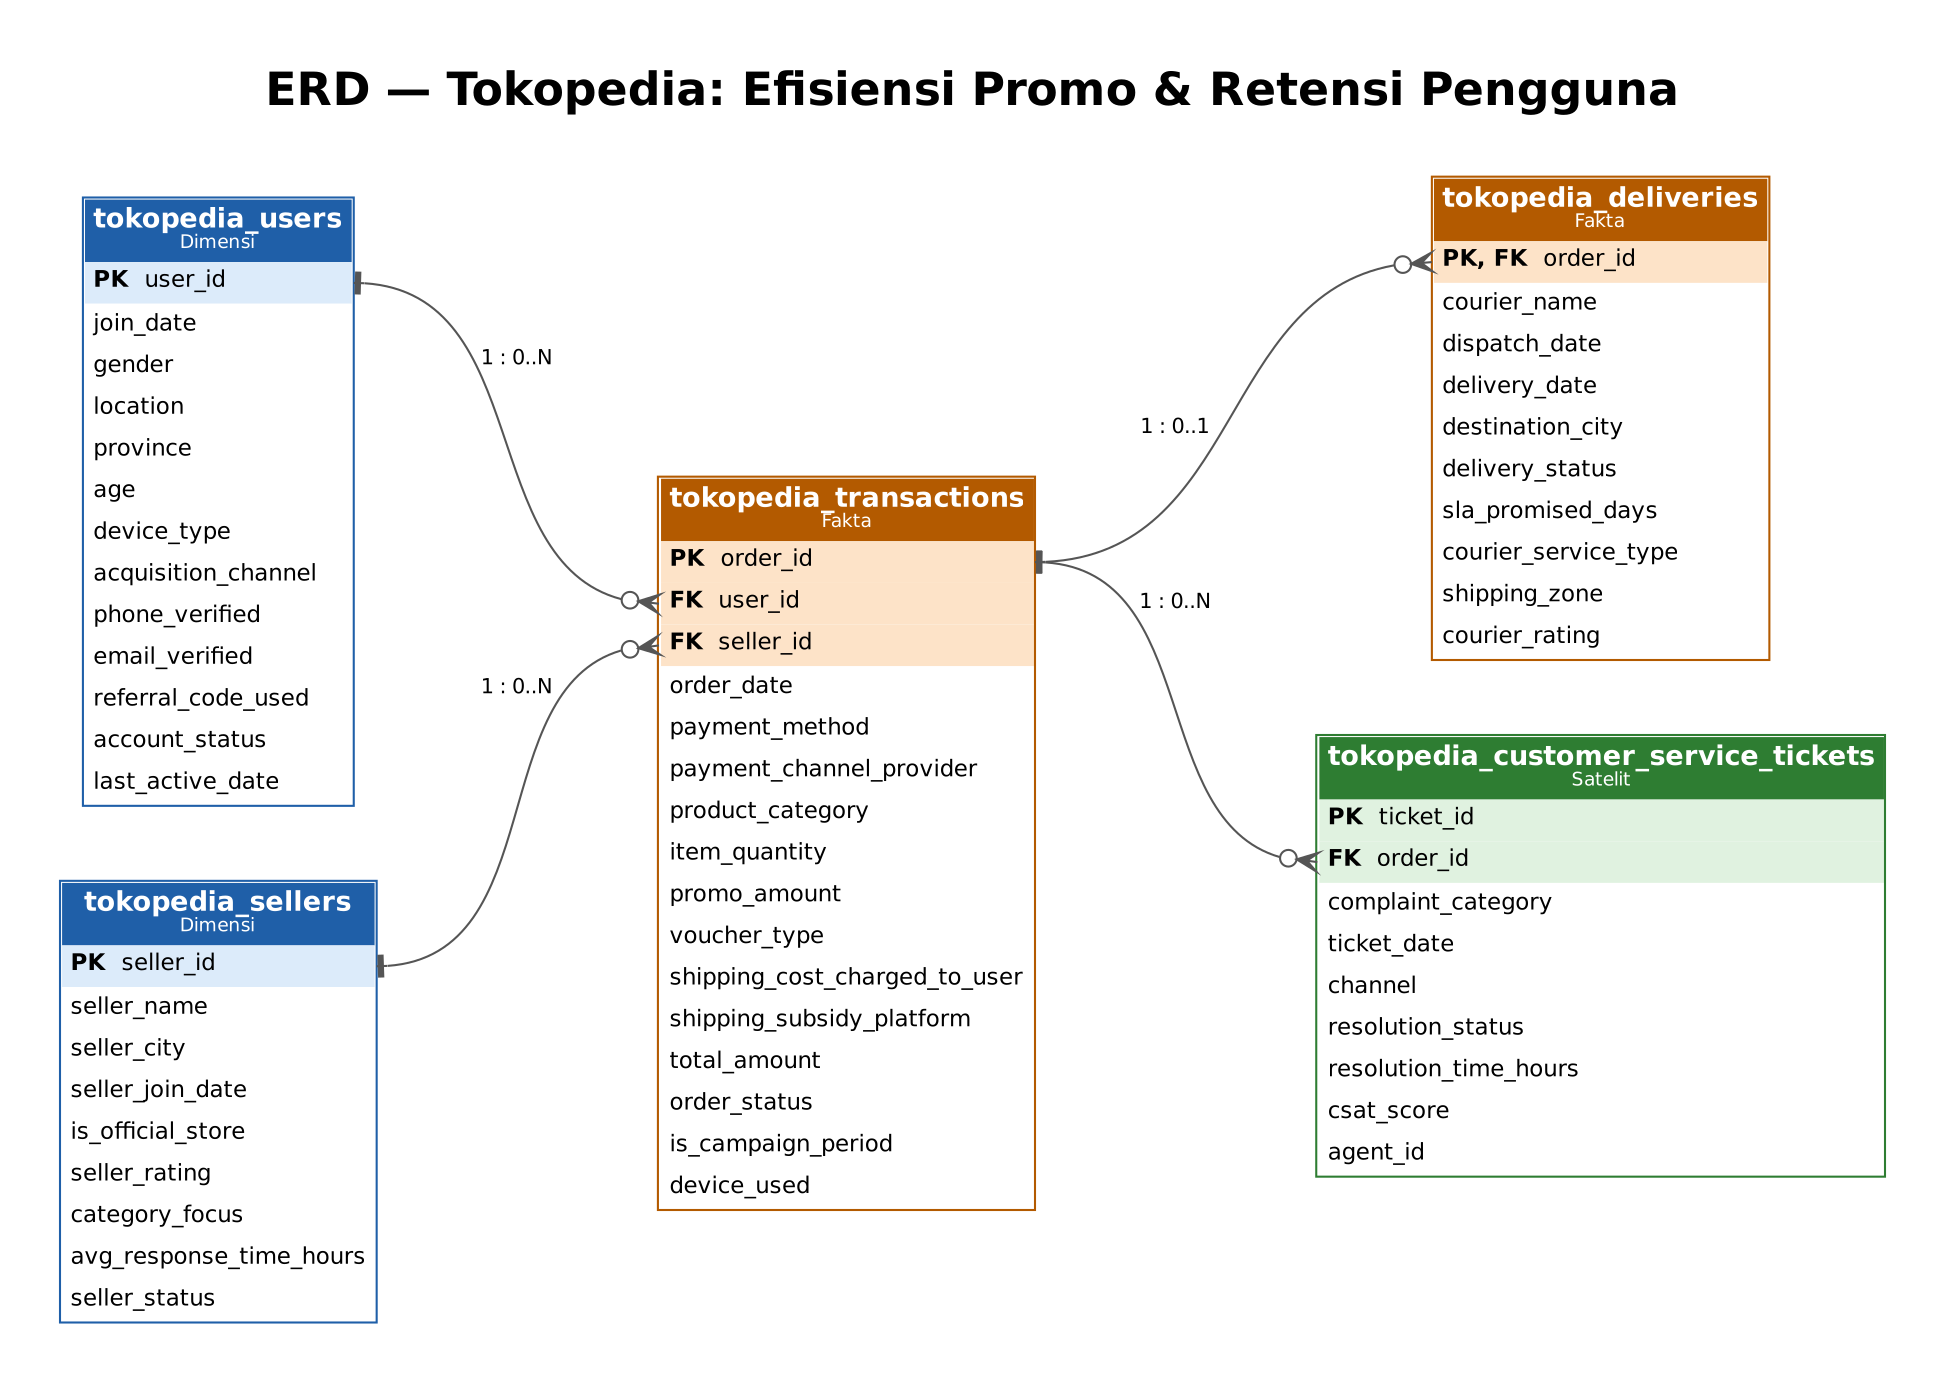


<a id="Extract-Data-from-BigQuery"></a>
## <span style="color:darkorange">Extract Data from BigQuery</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada tahap awal ini dilakukan impor library yang diperlukan serta proses ekstrak data dari Google BigQuery untuk analisis lebih lanjut. Upload file JSON service account ke Colab terlebih dahulu, lalu sesuaikan <code>key_path</code>. Nama tabel mentah diatur pada dictionary <code>raw_tables</code>.
</p>


In [8]:
# Import libraries
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Koneksi ke Google BigQuery
import pandas_gbq
from google.oauth2 import service_account
from google.cloud import bigquery

from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
print('pandas', pd.__version__, '| numpy', np.__version__, '| pandas_gbq', pandas_gbq.__version__)

pandas 2.2.3 | numpy 2.4.6 | pandas_gbq 0.30.0


In [9]:
# BigQuery configurations
project_id = 'tokopedia-data-analysis'
dataset_id = 'datalake_tokped'
key_path = 'tokopedia-data-analysis-c9e821d3bc45.json' # key path of json file (upload file JSON ke Colab, lalu ganti nama ini)

# Set up credentials
credentials = service_account.Credentials.from_service_account_file(
   key_path ,
    scopes=["https://www.googleapis.com/auth/bigquery"]
)

# Nama tabel mentah di dataset datalake_tokped (sesuaikan bila nama tabel di BigQuery berbeda)
raw_tables = {
    'users': 'tokopedia_users',
    'sellers': 'tokopedia_sellers',
    'transactions': 'tokopedia_transactions',
    'deliveries': 'tokopedia_deliveries',
    'tickets': 'tokopedia_customer_service_tickets',
}

# Dataset tujuan untuk data yang sudah dibersihkan (data warehouse)
dw_dataset_id = 'datawarehouse_tokped'

# Periode analisis sesuai brief
analysis_start = pd.Timestamp('2023-01-01')
analysis_end = pd.Timestamp('2024-12-31')

<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Setiap tabel diekstrak dengan <code>SELECT *</code>. Hasilnya disamakan menjadi teks (string) seperti saat CSV dibaca pada notebook cleansing per tabel, sehingga keputusan cleansing sebelumnya dapat diterapkan apa adanya — tidak bergantung pada tipe data hasil <em>autodetect</em> BigQuery. Salinan mentah disimpan pada variabel <code>*_raw</code> untuk audit.
</p>


In [10]:
def to_text_frame(df):
    """Samakan representasi hasil BigQuery dengan isi CSV mentah (semua kolom string).
    Dengan begitu keputusan cleansing dari notebook per tabel (yang membaca CSV sebagai string)
    dapat diterapkan apa adanya, apa pun tipe data hasil autodetect BigQuery."""
    out = pd.DataFrame(index=df.index)
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_datetime64_any_dtype(s):                       # DATETIME / TIMESTAMP
            out[col] = s.dt.strftime('%Y-%m-%d').astype('string')
        elif str(s.dtype) == 'dbdate' or (s.dtype == object and s.dropna().map(type).eq(dt.date).any()):  # DATE
            out[col] = s.astype(object).map(lambda v: pd.NA if pd.isna(v) else v.isoformat()).astype('string')
        else:
            out[col] = s.astype('string')
    return out.reset_index(drop=True)


def extract_table(table_name):
    sql_query = f"""
    SELECT *
    FROM `{project_id}.{dataset_id}.{table_name}`
    """
    # Retrieve data from BigQuery into a DataFrame
    df = pandas_gbq.read_gbq(sql_query, project_id=project_id, credentials=credentials)
    return to_text_frame(df)


users_raw = extract_table(raw_tables['users'])
sellers_raw = extract_table(raw_tables['sellers'])
transactions_raw = extract_table(raw_tables['transactions'])
deliveries_raw = extract_table(raw_tables['deliveries'])
tickets_raw = extract_table(raw_tables['tickets'])

# Schema sesuai brief & ERD
schema = {
    'users': ['user_id', 'join_date', 'gender', 'location', 'province', 'age', 'device_type',
              'acquisition_channel', 'phone_verified', 'email_verified', 'referral_code_used',
              'account_status', 'last_active_date'],
    'sellers': ['seller_id', 'seller_name', 'seller_city', 'seller_join_date', 'is_official_store',
                'seller_rating', 'category_focus', 'avg_response_time_hours', 'seller_status'],
    'transactions': ['order_id', 'user_id', 'order_date', 'payment_method', 'promo_amount', 'total_amount',
                     'product_category', 'item_quantity', 'seller_id', 'shipping_cost_charged_to_user',
                     'shipping_subsidy_platform', 'voucher_type', 'payment_channel_provider', 'order_status',
                     'is_campaign_period', 'device_used'],
    'deliveries': ['order_id', 'courier_name', 'dispatch_date', 'delivery_date', 'destination_city',
                   'delivery_status', 'sla_promised_days', 'courier_service_type', 'shipping_zone',
                   'courier_rating'],
    'tickets': ['ticket_id', 'order_id', 'complaint_category', 'ticket_date', 'channel',
                'resolution_status', 'resolution_time_hours', 'csat_score', 'agent_id'],
}
raw = {'users': users_raw, 'sellers': sellers_raw, 'transactions': transactions_raw,
       'deliveries': deliveries_raw, 'tickets': tickets_raw}
for name, df in raw.items():
    assert set(df.columns) == set(schema[name]), f'Kolom tabel {name} berbeda dari brief/ERD.'
    raw[name] = df[schema[name]]  # urutkan kolom sesuai schema
users_raw, sellers_raw, transactions_raw = raw['users'], raw['sellers'], raw['transactions']
deliveries_raw, tickets_raw = raw['deliveries'], raw['tickets']

# Salinan kerja; *_raw tidak diubah dan dipakai untuk audit
users = users_raw.copy()
sellers = sellers_raw.copy()
transactions = transactions_raw.copy()
deliveries = deliveries_raw.copy()
tickets = tickets_raw.copy()

# Catatan seluruh record yang dikeluarkan beserta alasannya (audit trail)
removed_log = []

display(pd.DataFrame({name: df.shape for name, df in raw.items()}, index=['baris', 'kolom']).T)
display('Users', users.head(), 'Sellers', sellers.head(), 'Transactions', transactions.head(),
        'Deliveries', deliveries.head(), 'Tickets', tickets.head())

Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|
Downloading: 100%|██████████|


,baris,kolom
users,52847,13
sellers,1238,9
transactions,269953,16
deliveries,261525,10
tickets,31553,9


'Users'

,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
0,ECYJBCRQPG,2021-06-04,Female,Bandung,Jawa Barat,10,iOS,organic,True,False,<NA>,active,2021-06-27
1,U7SSTB3KDS,2024-08-26,Male,Denpasar,Bali,10,Android,organic,True,True,<NA>,active,2024-09-07
2,D66J2Y56Z7,2021-01-20,Female,Jakarta,DKI Jakarta,10,Web,ads,True,True,<NA>,active,2021-01-22
3,PSTCSHL4QN,2021-01-13,Male,Jakarta,DKI Jakarta,10,Android,organic,True,True,<NA>,active,2021-02-04
4,TDLJPYZXA3,2022-01-04,<NA>,Jakarta,DKI Jakarta,10,Android,organic,True,False,<NA>,active,2022-01-09


'Sellers'

,seller_id,seller_name,seller_city,seller_join_date,is_official_store,seller_rating,category_focus,avg_response_time_hours,seller_status
0,tirta-tech-official-2284,Tirta Tech Official,Tangerang,2019-09-17,False,4.3,elektronik,0.3,active
1,damar-official-7733,Damar Official,Semarang,2022-12-11,False,4.64,elektronik,0.4,active
2,makara-store-4873,Makara Store,Jakarta,2019-07-07,False,4.34,elektronik,0.5,active
3,wadi-official-7215,Wadi Official,Jakarta,2019-04-03,False,4.89,elektronik,0.5,active
4,kamal-mart-5832,Kamal Mart,Surabaya,2020-02-04,False,4.29,elektronik,0.5,active


... (2 outputs left out)

'Deliveries'

,order_id,courier_name,dispatch_date,delivery_date,destination_city,delivery_status,sla_promised_days,courier_service_type,shipping_zone,courier_rating
0,INV/230101/1057055,GoTo Logistics,2023-01-01,2023-01-01,DKI Jakarta,delivered,1,express,dalam_kota,4.5
1,INV/230101/9742821,JNE,2023-01-01,2023-01-01,Jakarta,delivered,1,reguler,dalam_kota,4.4
2,INV/230101/8984372,GoTo Logistics,2023-01-01,2023-01-01,Surabaya,delivered,1,reguler,dalam_kota,4.9
3,INV/230101/6534492,AnterAja,2023-01-01,2023-01-01,Pontianak,delivered,1,reguler,dalam_kota,4.7
4,INV/230101/3803188,AnterAja,2023-01-01,2023-01-01,Medan,delivered,1,reguler,dalam_kota,5.0


'Tickets'

,ticket_id,order_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,agent_id
0,TKT-230925-2100,INV/230920/3441041,produk_rusak,2023-09-25,chat,resolved,0.5,<NA>,AG-MKS-010
1,TKT-230501-3843,INV/230426/9958020,produk_rusak,2023-05-01,sosmed,resolved,0.5,<NA>,AG-MDN-004
2,TKT-240108-5873,INV/240104/9187551,produk_rusak,2024-01-08,chat,escalated,0.5,<NA>,AG-BDG-018
3,TKT-230820-6864,INV/230811/4657542,keterlambatan,2023-08-20,telepon,pending,0.5,<NA>,AG-MKS-011
4,TKT-230617-2888,INV/230613/9225644,kurir_kasar,2023-06-17,chat,resolved,0.5,<NA>,AG-SBY-019


### Users
Dataset `tokopedia_users` terdiri atas **13 fitur** dengan total **52.847 records** (dimensi pengguna).
| Feature | Description |
|---|---|
| user_id | ID unik pengguna (PK) |
| join_date | Tanggal pengguna mendaftar |
| gender | Jenis kelamin pengguna |
| location, province | Kota & provinsi domisili pengguna |
| age | Umur pengguna |
| device_type | Perangkat yang digunakan (Android/iOS/Web) |
| acquisition_channel | Kanal akuisisi user (organic/ads/referral/affiliate) |
| phone_verified, email_verified | Status verifikasi akun |
| referral_code_used | Kode referral yang digunakan (jika ada) |
| account_status | Status akun (active/inactive/suspended) |
| last_active_date | Tanggal aktivitas terakhir pengguna |

### Sellers
Dataset `tokopedia_sellers` terdiri atas **9 fitur** dengan total **1.238 records** (dimensi penjual).
| Feature | Description |
|---|---|
| seller_id | ID unik toko/penjual (PK) |
| seller_name | Nama toko |
| seller_city | Kota domisili penjual |
| seller_join_date | Tanggal penjual bergabung |
| is_official_store | Status toko resmi (official store) |
| seller_rating | Rating rata-rata toko |
| category_focus | Kategori utama produk yang dijual |
| avg_response_time_hours | Rata-rata waktu respons penjual sebelum menyerahkan barang ke kurir |
| seller_status | Status keaktifan toko |

### Transactions
Dataset `tokopedia_transactions` terdiri atas **16 fitur** dengan total **269.953 records** (fakta transaksi).
| Feature | Description |
|---|---|
| order_id | ID unik transaksi (PK) |
| user_id | Pengguna yang bertransaksi (FK users) |
| order_date | Tanggal transaksi dilakukan |
| payment_method, payment_channel_provider | Metode & provider pembayaran |
| promo_amount, voucher_type | Nominal & jenis promo/diskon yang digunakan |
| total_amount | Total nilai belanja |
| product_category, item_quantity | Kategori produk & jumlah barang |
| seller_id | Penjual terkait transaksi (FK sellers) |
| shipping_cost_charged_to_user, shipping_subsidy_platform | Ongkir yang dibayar user vs disubsidi platform |
| order_status | Status order (completed/cancelled/returned/refund) |
| is_campaign_period | Penanda transaksi terjadi saat periode kampanye/flash sale |
| device_used | Perangkat yang dipakai saat transaksi |

### Deliveries
Dataset `tokopedia_deliveries` terdiri atas **10 fitur** dengan total **261.525 records** (fakta pengiriman).
| Feature | Description |
|---|---|
| order_id | Transaksi yang dikirim (PK, FK transactions) |
| courier_name | Nama ekspedisi pengiriman |
| dispatch_date | Tanggal barang diserahkan penjual ke kurir |
| delivery_date | Tanggal barang sampai ke pembeli |
| destination_city | Kota tujuan pengiriman |
| delivery_status | Status pengiriman (delivered/failed/returned/in_transit) |
| sla_promised_days | Janji SLA pengiriman |
| courier_service_type | Jenis layanan (reguler/express/same_day/instant) |
| shipping_zone | Zona pengiriman (dalam_kota/luar_kota/luar_pulau) |
| courier_rating | Rating yang diberikan pengguna terhadap kurir |

### Customer Service Tickets
Dataset `tokopedia_customer_service_tickets` terdiri atas **9 fitur** dengan total **31.553 records** (fakta tiket layanan pelanggan).
| Feature | Description |
|---|---|
| ticket_id | ID unik tiket (PK) |
| order_id | Transaksi terkait tiket (FK transactions) |
| complaint_category | Kategori keluhan |
| ticket_date | Tanggal tiket dibuat |
| channel | Kanal komunikasi (chat/email/telepon/sosmed) |
| resolution_status | Status penyelesaian tiket |
| resolution_time_hours | Lama waktu penyelesaian tiket |
| csat_score | Skor kepuasan pengguna terhadap penanganan tiket |
| agent_id | Kode agent customer service yang menangani |


<a id="Data-Cleaning"></a>
# <span style="color:darkorange">Data Cleaning</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Cleansing dilakukan pada kelima tabel dalam satu alur, dengan <strong>keputusan penanganan yang sama</strong> seperti notebook cleansing per tabel sebelumnya (Users R00, Sellers, Transactions, Deliveries, dan Customer Service Tickets — Final Version). Setiap sub-bagian di bawah memproses seluruh tabel untuk satu jenis masalah.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Penggabungan (<em>merge</em>) seluruh tabel menjadi satu tabel analisis dilakukan <strong>setelah</strong> cleansing dan pemeriksaan integritas relasi. Alasannya: tabel tiket berelasi 1 : 0..N terhadap transaksi, dan transaksi masih mengandung duplikat <code>order_id</code>; menggabungkan data mentah akan menggandakan baris dan nilai transaksi. Dengan urutan ini, setiap <code>order_id</code> yang dihapus dari transaksi dapat ikut dihapus dari deliveries dan tickets (cascade) sebelum data digabung.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Prinsip umum: tidak ada imputasi nilai yang tidak diketahui; data mentah tetap tersedia di <code>*_raw</code>; setiap record yang dikeluarkan dicatat pada <code>removed_log</code> beserta alasannya.
</p>


<a id="Missing-Values"></a>
## <span style="color:darkorange">Missing Values</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada bagian ini dianalisis nilai kosong (null, string kosong, atau spasi saja) dan kandidat placeholder (NA, null, unknown, dsb.) pada setiap tabel.
</p>


In [11]:
placeholder_tokens = ['na', 'n/a', 'null', 'none', 'nan', 'unknown', '-']

def missing_profile(df, name):
    blank = df.apply(lambda col: col.str.strip().eq('')).fillna(False)
    placeholder = df.apply(lambda col: col.str.strip().str.lower().isin(placeholder_tokens)).fillna(False)
    missing = df.isna() | blank
    return pd.DataFrame({'tabel': name,
                         'missing': missing.sum(),
                         'persen': (missing.mean() * 100).round(2),
                         'kandidat_placeholder': placeholder.sum()})

missing_before = pd.concat([missing_profile(df, name) for name, df in raw.items()])
display(missing_before[missing_before['missing'].gt(0) | missing_before['kandidat_placeholder'].gt(0)])

,tabel,missing,persen,kandidat_placeholder
gender,users,5149,9.74,0
referral_code_used,users,44865,84.9,0
voucher_type,transactions,113288,41.97,0
courier_name,deliveries,9977,3.81,0
courier_rating,deliveries,77844,29.77,0
csat_score,tickets,9969,31.59,0


<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Terdapat 6 kolom dengan <em>missing values</em> dan tidak ada token placeholder pada seluruh tabel:
</p>

| Tabel | Kolom | Missing | Persen |
|---|---|---|---|
| users | gender | 5.149 | 9,74% |
| users | referral_code_used | 44.865 | 84,90% |
| transactions | voucher_type | 113.288 | 41,97% |
| deliveries | courier_name | 9.977 | 3,81% |
| deliveries | courier_rating | 77.844 | 29,77% |
| tickets | csat_score | 9.969 | 31,59% |

Selanjutnya representasi kosong diseragamkan menjadi `pd.NA`, lalu pola missing diperiksa terhadap konteks bisnisnya.

In [12]:
# Ubah string kosong / spasi saja menjadi missing (pd.NA) agar isna() bekerja konsisten
for df in [users, sellers, transactions, deliveries, tickets]:
    df.replace(r'^\s*$', pd.NA, regex=True, inplace=True)

# Users: rapikan spasi tepi pada atribut non-ID (ID dan kode referral tidak diubah)
for col in ['gender', 'location', 'province', 'device_type', 'acquisition_channel', 'account_status',
            'join_date', 'last_active_date', 'age', 'phone_verified', 'email_verified']:
    users[col] = users[col].str.strip()

# 1) Transactions: voucher kosong vs promo
promo_check = pd.to_numeric(transactions['promo_amount'], errors='coerce')
subsidy_check = pd.to_numeric(transactions['shipping_subsidy_platform'], errors='coerce')
display(pd.crosstab(transactions['voucher_type'].isna().rename('voucher_kosong'),
                    promo_check.eq(0).rename('promo_nol')))
print('Voucher kosong & promo positif :', int((transactions['voucher_type'].isna() & promo_check.gt(0)).sum()))
print('Voucher kosong & subsidi ongkir positif :', int((transactions['voucher_type'].isna() & subsidy_check.gt(0)).sum()))

# 2) Users: referral kosong vs kanal akuisisi
display(pd.crosstab(users['acquisition_channel'], users['referral_code_used'].notna().rename('ada_kode_referral')))

# 3) Deliveries: missing kurir & rating per status pengiriman
display(deliveries.groupby('delivery_status').agg(
    total=('order_id', 'size'),
    courier_missing=('courier_name', lambda s: s.isna().sum()),
    rating_missing=('courier_rating', lambda s: s.isna().sum())))

# 4) Tickets: CSAT kosong per status tiket
display(tickets.groupby('resolution_status').agg(
    total=('ticket_id', 'size'),
    csat_missing=('csat_score', lambda s: s.isna().sum())))

promo_nol,False,True
voucher_kosong,,
False,156665,0
True,0,113288


Voucher kosong & promo positif : 0
Voucher kosong & subsidi ongkir positif : 113275


ada_kode_referral,False,True
acquisition_channel,,
ads,16022,0
affiliate,5238,0
organic,23605,0
referral,0,7982


,total,courier_missing,rating_missing
delivery_status,,,
delivered,237643,9046,59309
failed,11546,444,11546
in_transit,5202,195,5202
returned,7134,292,1787


,total,csat_missing
resolution_status,,
escalated,2482,2482
pending,3762,3762
resolved,25309,3725


**Keputusan:** seluruh *missing values* **dipertahankan tanpa imputasi dan tanpa penghapusan baris**, karena sebagian besar mengikuti alur bisnis:

1. **`voucher_type` kosong (113.288)** — seluruhnya memiliki `promo_amount = 0`, sehingga konsisten dengan pesanan tanpa voucher. Tidak diisi `no_promo`, karena 113.275 di antaranya tetap memiliki subsidi ongkir platform positif.
2. **`referral_code_used` kosong (44.865)** — seluruh pengguna kanal `referral` (7.982) memiliki kode, dan tidak ada kode pada kanal lain; kosong berarti tidak memakai referral.
3. **`gender` kosong (5.149)** — tidak ada dasar untuk menebak; label `Unknown` hanya boleh dipakai pada salinan untuk visualisasi.
4. **`courier_rating` kosong (77.844)** — seluruh `failed` (11.546) dan `in_transit` (5.202) tidak memiliki rating; 59.309 `delivered` dan 1.787 `returned` tanpa rating dapat berarti pengguna tidak menilai. Missing rating bukan rating nol.
5. **`courier_name` kosong (9.977)** — dipertahankan; tidak ditebak dari zona/layanan.
6. **`csat_score` kosong (9.969)** — seluruh tiket `pending` (3.762) dan `escalated` (2.482) belum memiliki CSAT; 3.725 dari 25.309 tiket `resolved` tanpa CSAT perlu investigasi non-respons survei.

Selanjutnya, penyesuaian terhadap `data type` akan dilakukan.

<a id="Data-Types"></a>
## <span style="color:darkorange">Data Types</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada bagian ini tipe data setiap kolom disesuaikan: tanggal menjadi <code>datetime</code>, nominal dan skor menjadi numerik, status verifikasi/official store/kampanye menjadi <code>boolean</code> (memakai mapping eksplisit True/False — bukan <code>astype(bool)</code> yang akan mengubah teks "False" menjadi True), sedangkan ID dan kategori tetap <code>string</code>. Konversi yang gagal dihitung dan proses dihentikan bila ada, agar tidak ada nilai yang diam-diam berubah menjadi kosong.
</p>


In [13]:
date_pattern = r'\d{4}-\d{2}-\d{2}'

def to_date(s):
    ok = s.str.fullmatch(date_pattern, na=False)
    return pd.to_datetime(s.where(ok), format='%Y-%m-%d', errors='coerce')

def to_bool(s):
    return s.str.strip().str.lower().map({'true': True, 'false': False}).astype('boolean')

def to_float(s):
    out = pd.to_numeric(s, errors='coerce').astype('Float64')
    return out.where(np.isfinite(out.astype('float64')), pd.NA)

parse_failed = {}
def convert(df, name, col, func):
    before = df[col].copy()
    df[col] = func(before)
    parse_failed[(name, col)] = int((before.notna() & df[col].isna()).sum())

# Users
for col in ['join_date', 'last_active_date']:
    convert(users, 'users', col, to_date)
convert(users, 'users', 'age', to_float)
for col in ['phone_verified', 'email_verified']:
    convert(users, 'users', col, to_bool)

# Sellers
convert(sellers, 'sellers', 'seller_join_date', to_date)
convert(sellers, 'sellers', 'is_official_store', to_bool)
for col in ['seller_rating', 'avg_response_time_hours']:
    convert(sellers, 'sellers', col, to_float)

# Transactions (nominal & kuantitas: Int64 bila seluruh nilai bulat, selain itu Float64)
convert(transactions, 'transactions', 'order_date', to_date)
convert(transactions, 'transactions', 'is_campaign_period', to_bool)
trx_numeric = ['promo_amount', 'total_amount', 'item_quantity',
               'shipping_cost_charged_to_user', 'shipping_subsidy_platform']
for col in trx_numeric:
    convert(transactions, 'transactions', col, to_float)
    if transactions[col].dropna().mod(1).eq(0).all():
        transactions[col] = transactions[col].astype('Int64')

# Deliveries
for col in ['dispatch_date', 'delivery_date']:
    convert(deliveries, 'deliveries', col, to_date)
for col in ['sla_promised_days', 'courier_rating']:
    convert(deliveries, 'deliveries', col, to_float)

# Tickets
convert(tickets, 'tickets', 'ticket_date', to_date)
for col in ['resolution_time_hours', 'csat_score']:
    convert(tickets, 'tickets', col, to_float)

parse_failed = pd.Series(parse_failed, name='gagal_konversi')
display(parse_failed.to_frame())
assert parse_failed.sum() == 0, 'Ada nilai yang gagal dikonversi: periksa nilai asli di *_raw sebelum melanjutkan.'

for name, df in [('users', users), ('sellers', sellers), ('transactions', transactions),
                 ('deliveries', deliveries), ('tickets', tickets)]:
    print(f'\n{name}'); print(df.dtypes.to_string())

gagal_konversi
users        join_date                                   0
             last_active_date                            0
             age                                         0
             phone_verified                              0
             email_verified                              0
sellers      seller_join_date                            0
             is_official_store                           0
             seller_rating                               0
             avg_response_time_hours                     0
transactions order_date                                  0
             is_campaign_period                          0
             promo_amount                                0
             total_amount                                0
             item_quantity                               0
             shipping_cost_charged_to_user               0
             shipping_subsidy_platform                   0
deliveries   dispatch_date                               0
             delivery_date                               0
             sla_promised_days                           0
             courier_rating                              0
tickets      ticket_date                                 0
             resolution_time_hours                       0
             csat_score                                  0


users
user_id                string[python]
join_date              datetime64[ns]
gender                 string[python]
location               string[python]
province               string[python]
age                           Float64
device_type            string[python]
acquisition_channel    string[python]
phone_verified                boolean
email_verified                boolean
referral_code_used     string[python]
account_status         string[python]
last_active_date       datetime64[ns]

sellers
seller_id                  string[python]
seller_name                string[python]
seller_city                string[python]
seller_join_date           datetime64[ns]
is_official_store                 boolean
seller_rating                     Float64
category_focus             string[python]
avg_response_time_hours           Float64
seller_status              string[python]

transactions
order_id                         string[python]
user_id                          string[python]
or

Seluruh tanggal (format `YYYY-MM-DD`), angka, dan boolean pada kelima tabel **berhasil dikonversi tanpa kegagalan**. Nominal transaksi dan `item_quantity` disimpan sebagai `Int64` karena seluruh nilainya bilangan bulat. Setelah tipe data sesuai, konsistensi label kategori diperiksa.

<a id="Standardisasi-Kategori"></a>
## <span style="color:darkorange">Standardisasi Kategori</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Brief menyebutkan sejumlah kolom kategorikal (mis. lokasi dan metode pembayaran) memiliki variasi penulisan. Pada bagian ini dibandingkan jumlah label unik sebelum dan sesudah huruf kecil untuk mendeteksi variasi kapitalisasi/sinonim.
</p>


In [14]:
check_categories = {
    'users': ['gender', 'location', 'province', 'device_type', 'acquisition_channel', 'account_status'],
    'sellers': ['seller_city', 'category_focus', 'seller_status'],
    'transactions': ['payment_method', 'payment_channel_provider', 'product_category',
                     'voucher_type', 'order_status', 'device_used'],
    'deliveries': ['courier_name', 'destination_city', 'delivery_status', 'courier_service_type', 'shipping_zone'],
    'tickets': ['complaint_category', 'channel', 'resolution_status'],
}
frames = {'users': users, 'sellers': sellers, 'transactions': transactions,
          'deliveries': deliveries, 'tickets': tickets}
rows = []
for name, cols in check_categories.items():
    for col in cols:
        values = frames[name][col].dropna()
        rows.append([name, col, values.nunique(), values.str.strip().str.lower().nunique(),
                     ', '.join(sorted(values.unique())[:30])])
category_overview = pd.DataFrame(rows, columns=['tabel', 'kolom', 'label_unik', 'label_unik_setelah_lower', 'contoh_label'])
display(category_overview)

,tabel,kolom,label_unik,label_unik_setelah_lower,contoh_label
0,users,gender,2,2,"Female, Male"
1,users,location,18,16,"Balikpapan, Bandung, Batam, DKI Jakarta, Denpa..."
2,users,province,14,14,"Bali, DI Yogyakarta, DKI Jakarta, Jawa Barat, ..."
3,users,device_type,3,3,"Android, Web, iOS"
4,users,acquisition_channel,4,4,"ads, affiliate, organic, referral"
5,users,account_status,3,3,"active, inactive, suspended"
6,sellers,seller_city,8,8,"Bandung, Denpasar, Jakarta, Medan, Semarang, S..."
7,sellers,category_focus,7,7,"elektronik, fashion, grocery, kesehatan, lainn..."
8,sellers,seller_status,3,3,"active, inactive, suspended"
9,transactions,payment_method,27,16,"BCA VA, BNI VA, Bank Transfer, COD, Cash on De..."


Variasi penulisan ditemukan pada tiga kolom:
- `transactions.payment_method` — **27 label** untuk 16 metode (mis. `cod`, `Cash on Delivery`, `COD`; `GO-PAY`, `Gopay`, `gopay`).
- `users.location` — `jakarta` dan `JAKARTA` di samping `Jakarta`, serta `DKI Jakarta` (label tingkat provinsi).
- `deliveries.destination_city` — `jakarta`, `JAKARTA`, dan `DKI Jakarta`.

Kolom kategori lainnya (termasuk seluruh kolom sellers dan tickets) sudah konsisten.

**Keputusan (sesuai notebook per tabel):**
1. **Transactions** — sinonim metode pembayaran dipetakan ke label canonical (`COD`, `GoPay`, `Bank Transfer`, `Credit Card`, dst.). Detail `BCA VA`, `BNI VA`, `Mandiri VA` **dipertahankan** karena menyimpan informasi bank.
2. **Users** — kapitalisasi `jakarta`/`JAKARTA` → `Jakarta`. `DKI Jakarta` pada kolom kota ditangani bersama koreksi provinsi pada bagian Data Range Constrains, setelah divalidasi terhadap data pengiriman.
3. **Deliveries** — `jakarta`, `JAKARTA`, dan `DKI Jakarta` → `Jakarta` sebagai label agregat kota tujuan.
4. **Tickets** — strip + lowercase (tidak ada nilai yang berubah).

In [15]:
category_changes = []
def standardize(df, name, col, mapping):
    before = df[col].copy()
    trimmed = before.str.strip()
    mapped = trimmed.str.lower().map(mapping).astype('string')
    df[col] = mapped.fillna(trimmed)               # label di luar mapping tidak dibuang
    changed = before.ne(df[col]).fillna(False)
    if changed.any():
        category_changes.append(pd.DataFrame({'tabel': name, 'kolom': col,
                                              'sebelum': before[changed], 'sesudah': df.loc[changed, col]}))

# Users (mapping exact-lowercase ke label canonical, sama seperti notebook Users R00)
city_province = {
    'Jakarta': 'DKI Jakarta', 'Surabaya': 'Jawa Timur', 'Bandung': 'Jawa Barat',
    'Medan': 'Sumatera Utara', 'Makassar': 'Sulawesi Selatan', 'Yogyakarta': 'DI Yogyakarta',
    'Semarang': 'Jawa Tengah', 'Palembang': 'Sumatera Selatan', 'Denpasar': 'Bali',
    'Malang': 'Jawa Timur', 'Balikpapan': 'Kalimantan Timur', 'Pontianak': 'Kalimantan Barat',
    'Manado': 'Sulawesi Utara', 'Padang': 'Sumatera Barat', 'Batam': 'Kepulauan Riau'}
user_labels = {
    'gender': ['Female', 'Male'],
    'location': list(city_province) + ['DKI Jakarta'],
    'province': sorted(set(city_province.values())),
    'device_type': ['Android', 'iOS', 'Web'],
    'acquisition_channel': ['organic', 'ads', 'referral', 'affiliate'],
    'account_status': ['active', 'inactive', 'suspended']}
for col, labels in user_labels.items():
    standardize(users, 'users', col, {x.lower(): x for x in labels})

# Transactions (sinonim metode pembayaran; detail BCA/BNI/Mandiri VA dipertahankan)
payment_mapping = {
    'bank transfer': 'Bank Transfer', 'transfer bank': 'Bank Transfer',
    'cod': 'COD', 'cash on delivery': 'COD', 'gopay': 'GoPay', 'go-pay': 'GoPay',
    'qris': 'QRIS', 'ovo': 'OVO', 'shopeepay': 'ShopeePay', 'shopee pay': 'ShopeePay',
    'dana': 'DANA', 'credit card': 'Credit Card', 'kartu kredit': 'Credit Card',
    'bca va': 'BCA VA', 'bni va': 'BNI VA', 'mandiri va': 'Mandiri VA'}
trx_mapping = {
    'payment_method': payment_mapping,
    'payment_channel_provider': payment_mapping,
    'product_category': {x: x for x in ['fashion', 'grocery', 'elektronik', 'kesehatan', 'perabotan', 'lainnya', 'olahraga']},
    'voucher_type': {x: x for x in ['free_ongkir', 'cashback', 'diskon_persen']},
    'order_status': {x: x for x in ['completed', 'cancelled', 'returned', 'refund']},
    'device_used': {'android': 'Android', 'ios': 'iOS', 'web': 'Web'}}
for col, mapping in trx_mapping.items():
    standardize(transactions, 'transactions', col, mapping)

# Deliveries (jakarta / JAKARTA / DKI Jakarta -> Jakarta pada destination_city)
delivery_labels = {
    'courier_name': ['GoTo Logistics', 'JNE', 'SiCepat', 'AnterAja'],
    'destination_city': ['Jakarta', 'Surabaya', 'Bandung', 'Medan', 'Makassar', 'Yogyakarta', 'Semarang',
                         'Palembang', 'Denpasar', 'Malang', 'Balikpapan', 'Pontianak', 'Manado', 'Padang', 'Batam'],
    'delivery_status': ['delivered', 'failed', 'returned', 'in_transit'],
    'courier_service_type': ['reguler', 'express', 'same_day', 'instant'],
    'shipping_zone': ['dalam_kota', 'luar_kota', 'luar_pulau']}
for col, labels in delivery_labels.items():
    mapping = {x.lower(): x for x in labels}
    if col == 'destination_city':
        mapping['dki jakarta'] = 'Jakarta'
    standardize(deliveries, 'deliveries', col, mapping)

# Tickets (strip + lowercase)
ticket_labels = {
    'complaint_category': ['keterlambatan', 'produk_rusak', 'refund', 'lainnya', 'kurir_kasar'],
    'channel': ['chat', 'email', 'telepon', 'sosmed'],
    'resolution_status': ['resolved', 'pending', 'escalated']}
for col, labels in ticket_labels.items():
    standardize(tickets, 'tickets', col, {x: x for x in labels})

# Sellers: label sudah konsisten -> tidak ada perubahan

category_changes = (pd.concat(category_changes) if category_changes
                    else pd.DataFrame(columns=['tabel', 'kolom', 'sebelum', 'sesudah']))
display(category_changes.value_counts(['tabel', 'kolom', 'sebelum', 'sesudah']).rename('jumlah').reset_index())

# Label di luar daftar kerja (harus 0; bila ada, tinjau sebelum lanjut)
unexpected = {}
for name, df, labels in [('users', users, user_labels), ('deliveries', deliveries, delivery_labels),
                         ('tickets', tickets, ticket_labels),
                         ('transactions', transactions, {k: list(v.values()) for k, v in trx_mapping.items()})]:
    for col, allowed in labels.items():
        unexpected[(name, col)] = int((df[col].notna() & ~df[col].isin(allowed)).sum())
display(pd.Series(unexpected, name='label_di_luar_daftar').to_frame().query('label_di_luar_daftar > 0'))

,tabel,kolom,sebelum,sesudah,jumlah
0,deliveries,destination_city,DKI Jakarta,Jakarta,9759
1,deliveries,destination_city,jakarta,Jakarta,6519
2,deliveries,destination_city,JAKARTA,Jakarta,3038
3,transactions,payment_method,qris,QRIS,2209
4,transactions,payment_method,cod,COD,1986
5,transactions,payment_method,Cash on Delivery,COD,1925
6,users,location,jakarta,Jakarta,1599
7,transactions,payment_method,GO-PAY,GoPay,1345
8,transactions,payment_method,gopay,GoPay,1304
9,transactions,payment_method,Gopay,GoPay,1228


,,label_di_luar_daftar


In [16]:
# Validasi pasangan metode pembayaran vs provider (VA dikelompokkan sementara ke Bank Transfer)
method_group = transactions['payment_method'].replace({'BCA VA': 'Bank Transfer', 'BNI VA': 'Bank Transfer',
                                                       'Mandiri VA': 'Bank Transfer'})
display(pd.crosstab(method_group, transactions['payment_channel_provider']))
print('Pasangan metode-provider tidak cocok:',
      int(method_group.ne(transactions['payment_channel_provider']).fillna(False).sum()))

payment_channel_provider,Bank Transfer,COD,Credit Card,DANA,GoPay,OVO,QRIS,ShopeePay
payment_method,,,,,,,,
Bank Transfer,53618,0,0,0,0,0,0,0
COD,0,49664,0,0,0,0,0,0
Credit Card,0,0,13401,0,0,0,0,0
DANA,0,0,0,21553,0,0,0,0
GoPay,0,0,0,0,43000,0,0,0
OVO,0,0,0,0,0,26931,0,0
QRIS,0,0,0,0,0,0,37534,0
ShopeePay,0,0,0,0,0,0,0,24252


Pasangan metode-provider tidak cocok: 0


Sebanyak **19.316** label kota tujuan pengiriman, **2.397** label kota pengguna, dan **19.004** label metode pembayaran distandardisasi. Tidak ada label di luar daftar kerja, dan setelah VA dikelompokkan sementara ke `Bank Transfer`, **seluruh pasangan metode–provider pembayaran konsisten** (0 ketidakcocokan).

Pada bagian berikutnya akan dilakukan analisis untuk mengidentifikasi keberadaan data duplikat.

<a id="Data-Duplicates"></a>
## <span style="color:darkorange">Data Duplicates</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada bagian ini dibedakan dua jenis duplikat: (1) <strong>duplikat identik</strong> — seluruh atribut sama, dan (2) <strong>konflik primary key</strong> — PK sama tetapi atributnya berbeda. Pemeriksaan dilakukan pada data mentah agar tidak terpengaruh standardisasi.
</p>


In [17]:
dup_rows = []
for name, df_raw_, key in [('users', users_raw, 'user_id'), ('sellers', sellers_raw, 'seller_id'),
                          ('transactions', transactions_raw, 'order_id'), ('deliveries', deliveries_raw, 'order_id'),
                          ('tickets', tickets_raw, 'ticket_id')]:
    exact = df_raw_.duplicated(keep='first')
    unique_records = df_raw_.loc[~exact]
    conflict = unique_records[key].notna() & unique_records[key].duplicated(keep=False)
    dup_rows.append([name, key, int(exact.sum()), int(conflict.sum()), int(unique_records.loc[conflict, key].nunique())])
duplicate_summary = pd.DataFrame(dup_rows, columns=['tabel', 'primary_key', 'duplikat_identik_berlebih',
                                                    'record_konflik_PK', 'jumlah_PK_konflik'])
display(duplicate_summary)

# Tickets: satu order boleh memiliki >1 tiket (relasi 1 : 0..N)
order_ticket_counts = tickets.groupby('order_id').size()
print('Order dengan lebih dari satu tiket:', int(order_ticket_counts.gt(1).sum()))

,tabel,primary_key,duplikat_identik_berlebih,record_konflik_PK,jumlah_PK_konflik
0,users,user_id,0,0,0
1,sellers,seller_id,0,0,0
2,transactions,order_id,1071,32,16
3,deliveries,order_id,0,24,12
4,tickets,ticket_id,0,0,0


Order dengan lebih dari satu tiket: 1


Hasil pemeriksaan:
- **Transactions**: 1.071 salinan identik berlebih, serta **16 `order_id` konflik (32 record)** setelah salinan identik disisihkan.
- **Deliveries**: tidak ada salinan identik, tetapi **12 `order_id` konflik (24 record)**.
- **Users, sellers, tickets**: PK unik, tidak ada duplikat. Satu order memiliki 2 tiket; ini sah karena relasi transactions → tickets adalah 1 : 0..N.

**Keputusan 1 — salinan identik transaksi dihapus.** Salinan identik hanya menggandakan penghitungan total, sehingga hanya salinan berlebih yang dihapus; jumlah `order_id` unik tidak berubah.

In [18]:
# Transactions — hapus salinan identik berlebih (dibandingkan pada 16 kolom mentah)
exact_dup_trx = transactions_raw.duplicated(keep='first')
removed_log.append(transactions.loc[exact_dup_trx, ['order_id']].assign(
    tabel='transactions', alasan='duplikat identik (salinan berlebih)'))
before = len(transactions)
transactions = transactions.loc[~exact_dup_trx].copy()
print('Transactions:', before, '->', len(transactions), '| salinan identik dihapus:', int(exact_dup_trx.sum()))
print('order_id unik tidak berubah:', transactions['order_id'].nunique() == transactions_raw['order_id'].nunique())

Transactions: 269953 -> 268882 | salinan identik dihapus: 1071
order_id unik tidak berubah: True


**Keputusan 2 — seluruh record dengan `order_id` konflik pada transaksi dihapus.** Konflik mencakup perbedaan `user_id` (16 ID), `seller_id`, `total_amount`, `product_category`, dan atribut lain. Karena `order_id` adalah PK dan tidak ada sumber validasi untuk menentukan record yang benar, seluruh 32 record dikeluarkan untuk mencegah duplikasi dan salah atribusi saat digabung dengan users, sellers, deliveries, dan tickets.

In [19]:
# Transactions — order_id konflik (PK sama, atribut berbeda) setelah salinan identik disisihkan
unique_trx_raw = transactions_raw.loc[~exact_dup_trx]
conflict_mask = unique_trx_raw['order_id'].notna() & unique_trx_raw['order_id'].duplicated(keep=False)
trx_conflict_ids = unique_trx_raw.loc[conflict_mask, 'order_id'].drop_duplicates()
conflicts = unique_trx_raw.loc[conflict_mask].sort_values('order_id')
different_fields = conflicts.groupby('order_id').nunique(dropna=False).gt(1)
display(conflicts.head(10))
display(different_fields.loc[:, different_fields.any()].sum().rename('jumlah_ID_dengan_atribut_berbeda').to_frame())

# Keputusan (notebook Transactions): hapus SELURUH record dengan order_id konflik
mask = transactions['order_id'].isin(trx_conflict_ids)
removed_log.append(transactions.loc[mask, ['order_id']].assign(tabel='transactions', alasan='order_id konflik (PK duplikat)'))
transactions = transactions.loc[~mask].copy()
print('ID konflik:', len(trx_conflict_ids), '| record dihapus:', int(mask.sum()), '| sisa:', len(transactions))
assert transactions['order_id'].is_unique

,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used
26601,INV/230107/8172465,NUW6239FWB,2023-01-07,DANA,2938,531357,perabotan,1,balangga-mart-8571,9164,2340,cashback,DANA,completed,False,Android
183821,INV/230107/8172465,6EYLP8DCXG,2023-01-07,OVO,0,667297,olahraga,2,putri-house-4155,16267,4299,<NA>,OVO,completed,False,Android
32183,INV/230109/3602533,YZMJSQEJHJ,2023-01-09,QRIS,0,3764524,perabotan,5,batari-shop-3868,9225,728,<NA>,QRIS,completed,False,Android
70643,INV/230109/3602533,NRWH64MCV9,2023-01-09,GoPay,0,630472,olahraga,4,faizah-house-6722,22996,1230,<NA>,GoPay,completed,False,Android
220059,INV/230110/1429548,3KNNATQ8M3,2023-01-10,GoPay,45675,742795,fashion,1,solace-mart-9284,13210,10474,free_ongkir,GoPay,refund,False,iOS
107036,INV/230110/1429548,4QVNYH46P4,2023-01-10,Bank Transfer,15291,472210,grocery,2,kalyca-mart-boutique-5885,6814,5197,diskon_persen,Bank Transfer,completed,False,Android
128768,INV/230114/5205954,F8Q9J2CDA6,2023-01-14,OVO,0,214150,lainnya,1,kriya-id-4430,12233,1989,<NA>,OVO,completed,False,Android
247432,INV/230114/5205954,45E5Q3VZAN,2023-01-14,GoPay,31088,2776711,perabotan,4,wangsa-furnitur-store-3853,13869,2456,cashback,GoPay,completed,False,Android
15199,INV/230114/9288474,GQVR8DN4LC,2023-01-14,GoPay,26850,268854,lainnya,1,anggun-shop-gallery-1539,15060,6698,cashback,GoPay,completed,False,iOS
235813,INV/230114/9288474,3ZQ6X6PQK4,2023-01-14,COD,3309,117498,kesehatan,1,tirta-official-9840,12084,706,cashback,COD,completed,False,Android


,jumlah_ID_dengan_atribut_berbeda
user_id,16
payment_method,11
promo_amount,11
total_amount,12
product_category,12
item_quantity,10
seller_id,12
shipping_cost_charged_to_user,12
shipping_subsidy_platform,12
voucher_type,10


ID konflik: 16 | record dihapus: 32 | sisa: 268850


**Keputusan 3 — seluruh record dengan `order_id` konflik pada deliveries dikarantina.** Tanpa `updated_at` atau sumber otoritatif, status `delivered` bukan alasan memilih salah satu record. Seluruh 24 record dikeluarkan (0,0092% data deliveries) dan disimpan pada `deliveries_quarantine_pk`.

In [20]:
# Deliveries — order_id konflik (PK sama, atribut berbeda)
exact_dup_dlv = deliveries_raw.duplicated(keep='first')
deliveries = deliveries.loc[~exact_dup_dlv].copy()
dlv_conflict = deliveries['order_id'].notna() & deliveries['order_id'].duplicated(keep=False)
dlv_missing_key = deliveries['order_id'].isna()
deliveries_quarantine_pk = deliveries.loc[dlv_conflict | dlv_missing_key].copy()
display(deliveries_quarantine_pk.sort_values('order_id').head(24))

# Keputusan (notebook Deliveries): seluruh record konflik dikeluarkan (karantina)
removed_log.append(deliveries.loc[dlv_conflict | dlv_missing_key, ['order_id']].assign(
    tabel='deliveries', alasan='order_id konflik / kosong (PK duplikat)'))
deliveries = deliveries.loc[~(dlv_conflict | dlv_missing_key)].copy()
print('Deliveries: ID konflik', deliveries_quarantine_pk['order_id'].nunique(),
      '| record dikarantina', len(deliveries_quarantine_pk), '| sisa', len(deliveries))
assert deliveries['order_id'].is_unique

# Users, sellers, tickets: PK unik dan tidak kosong
for name, df, key in [('users', users, 'user_id'), ('sellers', sellers, 'seller_id'), ('tickets', tickets, 'ticket_id')]:
    assert df[key].notna().all() and df[key].is_unique, f'PK {name} tidak unik'
print('PK users, sellers, tickets unik.')

,order_id,courier_name,dispatch_date,delivery_date,destination_city,delivery_status,sla_promised_days,courier_service_type,shipping_zone,courier_rating
8792,INV/230107/8172465,SiCepat,2023-01-07,2023-01-10,Surabaya,delivered,2.0,reguler,dalam_kota,4.8
24708,INV/230107/8172465,SiCepat,2023-01-08,2023-01-17,Bandung,delivered,10.0,express,luar_pulau,4.9
12145,INV/230109/3602533,SiCepat,2023-01-11,2023-01-12,Palembang,in_transit,1.0,reguler,dalam_kota,<NA>
12786,INV/230109/3602533,GoTo Logistics,2023-01-09,2023-01-12,Semarang,delivered,2.0,instant,dalam_kota,4.8
16967,INV/230110/1429548,JNE,2023-01-11,2023-01-14,Jakarta,delivered,2.0,instant,dalam_kota,4.1
17807,INV/230110/1429548,GoTo Logistics,2023-01-11,2023-01-14,Jakarta,delivered,4.0,same_day,luar_kota,4.3
18854,INV/230114/5205954,AnterAja,2023-01-14,2023-01-15,Bandung,delivered,1.0,reguler,dalam_kota,<NA>
29389,INV/230114/5205954,AnterAja,2023-01-15,2023-01-21,Makassar,returned,5.0,reguler,luar_kota,4.2
29061,INV/230114/9288474,SiCepat,2023-01-20,2023-01-21,Makassar,delivered,2.0,same_day,dalam_kota,<NA>
29468,INV/230114/9288474,JNE,2023-01-14,2023-01-21,Bandung,delivered,5.0,reguler,luar_kota,<NA>


Deliveries: ID konflik 12 | record dikarantina 24 | sisa 261501
PK users, sellers, tickets unik.


Setelah langkah ini, setiap primary key pada kelima tabel sudah unik. Pada tahap berikutnya, analisis dilakukan untuk mengidentifikasi data yang berada di luar batasan wajar atau `data range constraints`.

<a id="Data-Range-Constrains"></a>
## <span style="color:darkorange">Data Range Constrains</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada bagian ini diperiksa nilai yang berada di luar batasan wajar, misalnya tanggal di luar rentang operasional, nominal negatif, usia tidak lazim, dan urutan tanggal yang tidak logis.
</p>


### <span style="color:darkorange">Transactions — tanggal transaksi</span>


In [21]:
display(transactions[trx_numeric].describe(percentiles=[.5, .95, .99]).T)
display(transactions['order_date'].dt.year.value_counts().sort_index().rename('jumlah_order').to_frame())
print('Rentang order_date:', transactions['order_date'].min().date(), 's.d.', transactions['order_date'].max().date())

,count,mean,std,min,50%,95%,99%,max
promo_amount,268850.0,54220.084571,176660.738867,0.0,6881.0,569102.65,913714.67,999993.0
total_amount,268850.0,2180686.065494,25872661.556475,-199974.0,356565.5,5035261.15,17373280.63,999793731.0
item_quantity,268850.0,2.297482,1.140137,1.0,2.0,4.0,6.0,10.0
shipping_cost_charged_to_user,268850.0,9679.742976,5590.731024,1.0,9352.0,19633.0,22578.0,24984.0
shipping_subsidy_platform,268850.0,7317.737616,5324.141426,0.0,6260.0,17942.0,21755.0,24955.0


,jumlah_order
order_date,
1970,409
2023,179885
2024,88173
2030,383


Rentang order_date: 1970-01-01 s.d. 2030-11-27


Teridentifikasi **792 transaksi dengan `order_date` tahun 1970 (409) dan 2030 (383)** — jauh di luar periode analisis 2023–2024. Untuk menentukan metode koreksi, `order_date` dibandingkan dengan tanggal yang tersirat pada `order_id` (pola `INV/YYMMDD/XXXXXXX`).

In [22]:
# Tanggal yang tersirat pada order_id (pola INV/YYMMDD/XXXXXXX)
id_text = transactions['order_id'].str.extract(r'^INV/(\d{6})/\d+$', expand=False)
date_from_id = pd.to_datetime('20' + id_text, format='%Y%m%d', errors='coerce')

in_period = transactions['order_date'].between(analysis_start, analysis_end) & date_from_id.notna()
agreement = (transactions.loc[in_period, 'order_date'] == date_from_id[in_period]).mean() * 100
print(f'Kesesuaian order_date vs tanggal pada order_id (periode 2023–2024): {agreement:.2f}%')

date_anomaly = transactions['order_date'].dt.year.isin([1970, 2030]) & date_from_id.notna()
print('Order dengan tanggal 1970/2030:', int(date_anomaly.sum()))
display(transactions.loc[date_anomaly, ['order_id', 'order_date']].assign(tanggal_dari_id=date_from_id[date_anomaly]).head(10))

Kesesuaian order_date vs tanggal pada order_id (periode 2023–2024): 100.00%
Order dengan tanggal 1970/2030: 792


,order_id,order_date,tanggal_dari_id
257,INV/230325/4001285,1970-01-01,2023-03-25
291,INV/230313/8398457,2030-04-19,2023-03-13
405,INV/230308/4326187,1970-01-01,2023-03-08
1776,INV/230103/5936146,2030-07-13,2023-01-03
1989,INV/230225/8295934,2030-10-13,2023-02-25
2065,INV/230128/6622819,1970-01-01,2023-01-28
2353,INV/231113/7508440,1970-01-01,2023-11-13
2648,INV/230316/5666745,1970-01-01,2023-03-16
3329,INV/230908/4214777,2030-04-20,2023-09-08
3497,INV/241112/8891910,2030-02-27,2024-11-12


Pada transaksi periode 2023–2024, kesesuaian `order_date` dengan tanggal pada `order_id` mencapai **100%**.

**Keputusan:** dilakukan *rule-based date correction* — `order_date` tahun 1970/2030 diganti dengan tanggal hasil ekstraksi `order_id`. Hanya record anomali dengan tanggal ID valid yang dikoreksi; nilai asli disimpan pada `date_correction_audit`. *Limitasi:* konsistensi 100% tidak membuktikan secara absolut bahwa tanggal pada ID adalah tanggal transaksi yang benar; koreksi ini adalah inferensi berbasis pola data.

In [23]:
# Keputusan (notebook Transactions): rule-based correction dengan tanggal dari order_id
date_correction_audit = transactions.loc[date_anomaly, ['order_id', 'order_date']].rename(
    columns={'order_date': 'order_date_original'})
date_correction_audit['order_date_corrected'] = date_from_id[date_anomaly]
transactions.loc[date_anomaly, 'order_date'] = date_from_id[date_anomaly]

print('Tanggal dikoreksi:', len(date_correction_audit))
print('Sisa tahun 1970/2030:', int(transactions['order_date'].dt.year.isin([1970, 2030]).sum()))
print('Rentang order_date setelah koreksi:', transactions['order_date'].min().date(), 's.d.', transactions['order_date'].max().date())

Tanggal dikoreksi: 792
Sisa tahun 1970/2030: 0
Rentang order_date setelah koreksi: 2023-01-01 s.d. 2024-12-31


### <span style="color:darkorange">Transactions — nominal negatif</span>


Ditemukan **390 transaksi dengan `total_amount` negatif**: 332 berstatus `completed` dan 58 berstatus lain (refund 27, cancelled 16, returned 15). Tidak ada `total_amount` bernilai nol.

**Keputusan:** seluruh transaksi dengan **`total_amount` ≤ 0 dikarantina** (390 transaksi), sehingga tidak masuk ke transaksi bersih maupun `order_master`. Nilai belanja ≤ 0 tidak mungkin terjadi pada definisi `total_amount` mana pun, baik nilai sebelum promo maupun nilai yang dibayar setelah promo. Karena itu nilai ini bukan outlier yang dapat diinterpretasikan, melainkan data yang tidak valid. Penyesuaian nominal akibat refund, retur, atau pembatalan seharusnya tercatat di tabel tersendiri, bukan sebagai nilai transaksi.

Notebook Transactions menunjukkan bahwa transaksi negatif tidak berkaitan dengan kategori produk (Chi-Square p = 0,1546) maupun periode kampanye (p = 0,2754). Pengecualian transaksi negatif berstatus `completed` hanya mengubah total nilai belanja 0,0071% dan repeat buyer rate −0,0582 poin persentase. Pengecualian 58 transaksi non-completed hanya menambah 5 pengguna ke kohort 60 hari (39.358 → 39.363) tanpa mengubah kesimpulan analisis. Data pengiriman (42) dan tiket (4) milik transaksi ini ikut terhapus melalui *cascade* pada bagian Integritas Relasi.

In [24]:
negative = transactions['total_amount'].lt(0).fillna(False)
print('Transaksi dengan total_amount negatif:', int(negative.sum()),
      '| total_amount = 0:', int(transactions['total_amount'].eq(0).fillna(False).sum()))
display(transactions.loc[negative, 'order_status'].value_counts().rename('jumlah').to_frame())

# Keputusan: total_amount <= 0 tidak mungkin pada definisi mana pun (nilai sebelum maupun sesudah promo)
# -> seluruhnya dikarantina, apa pun order_status-nya
invalid_amount = transactions['total_amount'].le(0).fillna(False)
removed_log.append(transactions.loc[invalid_amount, ['order_id']].assign(tabel='transactions', alasan='total_amount <= 0'))
transactions = transactions.loc[~invalid_amount].copy()
print('Dikarantina (total_amount <= 0):', int(invalid_amount.sum()), '| sisa:', len(transactions))

Transaksi dengan total_amount negatif: 390 | total_amount = 0: 0


,jumlah
order_status,
completed,332
refund,27
cancelled,16
returned,15


Dikarantina (total_amount <= 0): 390 | sisa: 268460


In [25]:
# Pemeriksaan rentang lain pada transactions
print('item_quantity <= 0 atau pecahan :', int((transactions['item_quantity'].le(0) | transactions['item_quantity'].mod(1).ne(0)).fillna(False).sum()))
for col in ['promo_amount', 'shipping_cost_charged_to_user', 'shipping_subsidy_platform']:
    print(f'{col} negatif :', int(transactions[col].lt(0).fillna(False).sum()))
print('Voucher terisi tetapi promo <= 0 :', int((transactions['voucher_type'].notna() & transactions['promo_amount'].le(0)).fillna(False).sum()))

# Keputusan: promo_amount negatif tidak mungkin pada definisi mana pun -> dikarantina bila ada
negative_promo = transactions['promo_amount'].lt(0).fillna(False)
removed_log.append(transactions.loc[negative_promo, ['order_id']].assign(tabel='transactions', alasan='promo_amount negatif'))
transactions = transactions.loc[~negative_promo].copy()
print('Dikarantina (promo_amount negatif):', int(negative_promo.sum()), '| sisa:', len(transactions))

item_quantity <= 0 atau pecahan : 0
promo_amount negatif : 0
shipping_cost_charged_to_user negatif : 0
shipping_subsidy_platform negatif : 0
Voucher terisi tetapi promo <= 0 : 0
Dikarantina (promo_amount negatif): 0 | sisa: 268460


Kolom nominal lain tidak memiliki nilai negatif. Tidak ada `promo_amount` negatif, sehingga tidak ada transaksi yang dikarantina. Aturan karantinanya tetap dipasang agar otomatis berlaku bila data diperbarui. `item_quantity` seluruhnya bilangan bulat 1–10, dan setiap voucher terisi memiliki promo positif.

### <span style="color:darkorange">Users</span>


In [26]:
display(users['age'].describe().to_frame())

# --- Lokasi: validasi kota vs provinsi memakai kota tujuan pengiriman pada order milik user ---
expected_province = users['location'].replace({'DKI Jakarta': 'Jakarta'}).map(city_province)
location_granularity = users['location'].eq('DKI Jakarta').fillna(False)
location_mismatch = (expected_province.notna() & users['province'].notna()
                     & users['province'].ne(expected_province)).fillna(False)

user_dest = (transactions[['order_id', 'user_id']]
             .merge(deliveries[['order_id', 'destination_city']], on='order_id')
             .merge(users[['user_id', 'location', 'province']], on='user_id'))
user_dest['city'] = user_dest['location'].replace({'DKI Jakarta': 'Jakarta'})
user_dest['group'] = np.select(
    [user_dest['user_id'].isin(users.loc[location_mismatch, 'user_id']),
     user_dest['user_id'].isin(users.loc[location_granularity, 'user_id'])],
    ['kota-provinsi tidak cocok', 'DKI Jakarta di kolom kota'], default='konsisten')
display(user_dest.groupby('group').apply(lambda x: pd.Series({
    'jumlah_order': len(x),
    'tujuan_sama_dengan_kota_%': round((x['destination_city'] == x['city']).mean() * 100, 1),
    'provinsi_tujuan_sama_dengan_province_%': round((x['destination_city'].map(city_province) == x['province']).mean() * 100, 1)})))

# Keputusan: kolom kota (location) dipercaya, province dikoreksi dari mapping kota;
# 'DKI Jakarta' pada kolom kota diseragamkan menjadi 'Jakarta' (sama dengan deliveries).
location_changes = pd.concat([
    users.loc[location_granularity, ['user_id', 'location']].rename(columns={'location': 'sebelum'})
         .assign(kolom='location', sesudah='Jakarta'),
    users.loc[location_mismatch, ['user_id', 'province']].rename(columns={'province': 'sebelum'})
         .assign(kolom='province', sesudah=expected_province[location_mismatch])])
users.loc[location_granularity, 'location'] = 'Jakarta'
users.loc[location_mismatch, 'province'] = expected_province[location_mismatch]
assert users['location'].map(city_province).eq(users['province']).all()
print('location DKI Jakarta -> Jakarta:', int(location_granularity.sum()),
      '| province dikoreksi:', int(location_mismatch.sum()))

# --- Flag review lain (usia: semua usia diterima, hanya nilai tidak mungkin yang ditandai) ---
user_flags = pd.DataFrame(index=users.index)
user_flags['age_nonpositive'] = users['age'].le(0).fillna(False)
user_flags['age_fraction'] = users['age'].mod(1).ne(0).fillna(False)
user_flags['activity_before_join'] = (users['last_active_date'] < users['join_date']).fillna(False)
has_code = users['referral_code_used'].notna()
is_referral = users['acquisition_channel'].eq('referral').fillna(False)
user_flags['referral_no_code'] = is_referral & ~has_code
user_flags['code_other_channel'] = has_code & ~is_referral

display(user_flags.sum().rename('jumlah').to_frame())

# --- last_active_date sebelum join_date ---
# join_date dapat dipercaya (tidak ada order sebelum join_date pada kelompok ini dan jarak daftar -> order pertama
# setara user normal), sehingga last_active_date yang tidak mungkin dikosongkan (NaT).
first_order = transactions.groupby('user_id')['order_date'].min()
anomaly = user_flags['activity_before_join']
normal = ~anomaly & users['user_id'].isin(first_order.index)
check = pd.DataFrame({
    'jumlah_user': [int(anomaly.sum()), int(normal.sum())],
    'selisih_join_ke_last_active_hari': [
        (users.loc[anomaly, 'join_date'] - users.loc[anomaly, 'last_active_date']).dt.days.agg(['min', 'max']).tolist(), '-'],
    'order_pertama_sebelum_join': [
        int((users.loc[anomaly, 'user_id'].map(first_order) < users.loc[anomaly, 'join_date']).sum()),
        int((users.loc[normal, 'user_id'].map(first_order) < users.loc[normal, 'join_date']).sum())],
    'median_hari_join_ke_order_pertama': [
        (users.loc[anomaly, 'user_id'].map(first_order) - users.loc[anomaly, 'join_date']).dt.days.median(),
        (users.loc[normal, 'user_id'].map(first_order) - users.loc[normal, 'join_date']).dt.days.median()],
}, index=['last_active < join', 'user lain'])
display(check)
last_order = transactions.groupby('user_id')['order_date'].max()
after_last_active = users['user_id'].map(last_order) > users['last_active_date']
print('User normal dengan transaksi SETELAH last_active_date:',
      f"{after_last_active[normal].mean() * 100:.1f}%  -> last_active_date tidak dipakai untuk mengukur churn")

user_changes = pd.concat([
    location_changes,
    users.loc[anomaly, ['user_id', 'last_active_date']].rename(columns={'last_active_date': 'sebelum'})
         .assign(kolom='last_active_date', sesudah=pd.NaT)])
users.loc[anomaly, 'last_active_date'] = pd.NaT
print('last_active_date dikosongkan:', int(anomaly.sum()))
display(user_changes.groupby('kolom').size().rename('jumlah_perubahan').to_frame())
print('join_date:', users['join_date'].min().date(), 's.d.', users['join_date'].max().date(),
      '| last_active_date:', users['last_active_date'].min().date(), 's.d.', users['last_active_date'].max().date())

,age
count,52847.0
mean,44.310576
std,11.120819
min,10.0
25%,36.0
50%,43.0
75%,52.0
max,84.0


,jumlah_order,tujuan_sama_dengan_kota_%,provinsi_tujuan_sama_dengan_province_%
group,,,
DKI Jakarta di kolom kota,11900.0,81.7,81.7
konsisten,244308.0,81.2,81.4
kota-provinsi tidak cocok,4523.0,82.2,1.3


location DKI Jakarta -> Jakarta: 2395 | province dikoreksi: 952


,jumlah
age_nonpositive,0
age_fraction,0
activity_before_join,792
referral_no_code,0
code_other_channel,0


,jumlah_user,selisih_join_ke_last_active_hari,order_pertama_sebelum_join,median_hari_join_ke_order_pertama
last_active < join,792,"[1, 14]",0,13.0
user lain,51778,-,19,13.0


User normal dengan transaksi SETELAH last_active_date: 78.2%  -> last_active_date tidak dipakai untuk mengukur churn
last_active_date dikosongkan: 792


,jumlah_perubahan
kolom,
last_active_date,792
location,2395
province,952


join_date: 2020-01-04 s.d. 2024-12-30 | last_active_date: 2020-01-11 s.d. 2024-12-31


Usia berada pada rentang 10–84 tahun. **Seluruh usia diterima** sebagai nilai valid; hanya usia ≤ 0 atau pecahan yang ditandai (tidak ditemukan).

**Konsistensi kota–provinsi.** Ditemukan 2.395 pengguna dengan `DKI Jakarta` pada kolom kota (label tingkat provinsi) dan 910 pengguna dengan pasangan kota–provinsi yang tidak cocok. Untuk menentukan kolom mana yang benar, lokasi pengguna dibandingkan dengan kota tujuan pengiriman pada order milik pengguna tersebut:
- Pada pengguna yang tidak cocok, kota tujuan pengiriman sama dengan `location` pada **82,2%** order (setara pengguna konsisten, 81,2%), tetapi provinsi tujuan sama dengan `province` hanya pada **1,3%** order.
- Provinsi yang tidak cocok tersebar acak, sehingga mengindikasikan kesalahan input pada kolom `province`.

**Keputusan:** kolom `location` dijadikan acuan. `DKI Jakarta` pada kolom kota diseragamkan menjadi `Jakarta` (2.395 pengguna, sama dengan keputusan pada deliveries), lalu `province` dikoreksi berdasarkan kota (**952 pengguna**: 910 kasus awal ditambah 42 pengguna `DKI Jakarta` yang provinsinya bukan DKI Jakarta). Nilai sebelum/sesudah disimpan pada `location_changes`.

**`last_active_date` sebelum `join_date` (792 pengguna).** Selisihnya 1–14 hari dan tersebar merata. `join_date` kelompok ini dapat dipercaya: tidak ada order sebelum `join_date`, dan median jarak daftar ke order pertama (13 hari) sama dengan pengguna lain. Selain itu, **78,2% pengguna lain bertransaksi setelah `last_active_date`-nya**, sehingga kolom ini tidak mencerminkan aktivitas terakhir.

**Keputusan:** seluruh 792 pengguna dipertahankan (790 di antaranya memiliki transaksi); hanya `last_active_date` mereka yang dikosongkan (NaT) karena nilainya tidak mungkin dan nilai yang benar tidak diketahui. `last_active_date` **tidak digunakan** untuk mengukur churn atau aktivitas; churn dan retensi didefinisikan dari `order_date`. Seluruh perubahan nilai users (lokasi, provinsi, `last_active_date`) disimpan pada `user_changes`. Tidak ada lagi kasus yang menunggu keputusan, sehingga kolom `needs_review` tidak dibuat pada tabel users.

### <span style="color:darkorange">Sellers</span>


In [27]:
seller_checks = pd.Series({
    'rating_di_luar_0_5': int((~sellers['seller_rating'].between(0, 5)).fillna(False).sum()),
    'respons_negatif': int(sellers['avg_response_time_hours'].lt(0).fillna(False).sum()),
    'respons_nol': int(sellers['avg_response_time_hours'].eq(0).fillna(False).sum()),
    'join_date_setelah_2024': int(sellers['seller_join_date'].gt(analysis_end).fillna(False).sum()),
    'join_date_sebelum_2023 (informasi)': int(sellers['seller_join_date'].lt(analysis_start).fillna(False).sum()),
}, name='jumlah')
display(sellers[['seller_rating', 'avg_response_time_hours']].describe().T)
display(seller_checks.to_frame())

,count,mean,std,min,25%,50%,75%,max
seller_rating,1238.0,4.35399,0.435755,1.1,4.14,4.39,4.62,5.0
avg_response_time_hours,1238.0,8.239984,24.884713,0.1,2.3,4.2,6.9,236.0


,jumlah
rating_di_luar_0_5,0
respons_negatif,0
respons_nol,0
join_date_setelah_2024,0
join_date_sebelum_2023 (informasi),816


Rating penjual berada pada rentang 1,10–5,00 dan waktu respons 0,1–236 jam; tidak ada nilai negatif, nol, atau tanggal bergabung setelah 2024. Sebanyak 816 penjual bergabung sebelum 2023 — **valid secara konteks** karena penjual dapat bergabung sebelum periode transaksi. Tidak ada perubahan nilai.

### <span style="color:darkorange">Deliveries</span>


In [28]:
sla = deliveries['sla_promised_days']
rating = deliveries['courier_rating']
dispatch, delivery, status = deliveries['dispatch_date'], deliveries['delivery_date'], deliveries['delivery_status']
service = deliveries['courier_service_type']

invalid = pd.Series({'sla_negatif': int(sla.lt(0).fillna(False).sum()),
                     'rating_di_luar_1_5': int((rating.notna() & ~rating.between(1, 5)).fillna(False).sum()),
                     'delivery_sebelum_dispatch': int(delivery.lt(dispatch).fillna(False).sum())})
display(invalid.rename('jumlah_invalid').to_frame())
assert invalid.sum() == 0

delivery_checks = pd.DataFrame({
    'dispatch_before_period': dispatch.lt(analysis_start),
    'dispatch_after_period': dispatch.gt(analysis_end),
    'delivery_before_period': delivery.lt(analysis_start),
    'delivery_after_period': delivery.gt(analysis_end),
    'in_transit_with_delivery_date': status.eq('in_transit') & delivery.notna(),
    'failed_returned_with_delivery_date': status.isin(['failed', 'returned']) & delivery.notna(),
    'delivered_missing_dates': status.eq('delivered') & (dispatch.isna() | delivery.isna()),
    'missing_courier': deliveries['courier_name'].isna(),
    'delivered_without_rating': status.eq('delivered') & rating.isna(),
    'sla_over_7': sla.gt(7),
    'sla_zero': sla.eq(0),
    'sla_fraction': sla.notna() & sla.mod(1).ne(0),
    'fast_service_sla_over_1': service.isin(['instant', 'same_day']) & sla.gt(1),
}).fillna(False)
display(delivery_checks.sum().rename('jumlah').to_frame())

# 1) Tanggal di luar 2023–2024: tahun & bulan order induknya
order_dates_tmp = transactions.drop_duplicates('order_id').set_index('order_id')['order_date']
for col in ['dispatch_date', 'delivery_date']:
    outside = deliveries[col].dt.year.isin([2022, 2025])
    print(f'\n{col} di luar 2023–2024 per bulan, beserta bulan order induknya:')
    display(pd.crosstab(deliveries.loc[outside, col].dt.to_period('M').rename(col),
                        deliveries.loc[outside, 'order_id'].map(order_dates_tmp).dt.to_period('M').rename('bulan_order')))

# 2) Double check: delivery_date terisi pada seluruh status?
display(deliveries.groupby('delivery_status').agg(
    total=('order_id', 'size'),
    delivery_date_kosong=('delivery_date', lambda s: int(s.isna().sum())),
    dispatch_date_kosong=('dispatch_date', lambda s: int(s.isna().sum()))))

# 3) Pola courier_name kosong
missing_courier = deliveries['courier_name'].isna()
display(pd.concat({c: missing_courier.groupby(deliveries[c]).mean().mul(100).round(2)
                   for c in ['delivery_status', 'courier_service_type', 'shipping_zone']}).rename('persen_kurir_kosong').to_frame())
print('Kurir kosong tetapi memiliki courier_rating:', int((missing_courier & rating.notna()).sum()))

# 4) Layanan instant/same_day: SLA dan durasi aktual dibanding layanan lain
display(pd.crosstab(service, sla.astype('float64'), colnames=['sla_promised_days']))
display(pd.crosstab(deliveries.loc[service.isin(['instant', 'same_day']), 'shipping_zone'],
                    sla[service.isin(['instant', 'same_day'])].gt(1).rename('sla_lebih_dari_1_hari')))
gap = (delivery - dispatch).dt.days
delivered = status.eq('delivered').fillna(False).astype(bool)
display(gap[delivered].groupby(service[delivered]).describe()[['count', 'mean', '50%', 'max']]
        .rename(columns={'50%': 'median'}).round(2).rename_axis('durasi_aktual_delivered (hari)'))

# Durasi pengiriman hanya untuk delivered dengan urutan tanggal benar
valid_duration = (delivered & dispatch.notna() & delivery.notna() & gap.ge(0)).fillna(False).astype(bool)
deliveries['delivery_duration_days'] = gap.where(valid_duration).astype('Float64')

# Keputusan: seluruh pola di atas diterima (tidak ada koreksi/penghapusan di tahap ini).
# Kolom needs_review tidak dibuat karena tidak ada kasus yang masih menunggu keputusan;
# record dispatch sebelum order ditangani pada bagian Integritas Relasi Antar Tabel.

,jumlah_invalid
sla_negatif,0
rating_di_luar_1_5,0
delivery_sebelum_dispatch,0


,jumlah
dispatch_before_period,8
dispatch_after_period,109
delivery_before_period,0
delivery_after_period,1425
in_transit_with_delivery_date,5201
failed_returned_with_delivery_date,18676
delivered_missing_dates,0
missing_courier,9976
delivered_without_rating,59303
sla_over_7,19685



dispatch_date di luar 2023–2024 per bulan, beserta bulan order induknya:


bulan_order,2023-01,2024-12
dispatch_date,,
2022-12,8,0
2025-01,0,108



delivery_date di luar 2023–2024 per bulan, beserta bulan order induknya:


bulan_order,2024-12
delivery_date,
2025-01,1422


... (2 outputs left out)

Kurir kosong tetapi memiliki courier_rating: 7049


sla_promised_days,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
courier_service_type,,,,,,,,,,
express,13103,12925,9808,9731,11603,1553,1637,1537,1636,1575
instant,2565,2551,1983,2043,2265,346,319,310,347,345
reguler,31322,31365,23611,23542,27547,3825,3972,3889,4071,3933
same_day,5294,5202,3918,3987,4536,618,645,675,675,692


sla_lebih_dari_1_hari,False,True
shipping_zone,,
dalam_kota,7859,7753
luar_kota,0,17747
luar_pulau,0,5957


,count,mean,median,max
durasi_aktual_delivered (hari),,,,
express,59316.0,4.28,3.0,28.0
instant,11840.0,4.35,3.0,28.0
reguler,142681.0,4.30,3.0,28.0
same_day,23787.0,4.34,3.0,28.0


Tidak ada SLA negatif, rating di luar 1–5, maupun `delivery_date` sebelum `dispatch_date`. Keputusan untuk setiap pola yang ditemukan:

| Pemeriksaan | Jumlah | Temuan | Keputusan |
|---|---|---|---|
| `dispatch_date` 2022 | 8 | Seluruh order induk bertanggal 1–4 Januari 2023; barang tercatat dikirim 1–4 hari sebelum dipesan | Dikarantina pada bagian Integritas Relasi (dispatch < order) |
| `dispatch_date` 2025 | 109 | Seluruhnya Januari 2025; order induk Desember 2024 (1 order induk sudah dihapus pada cleansing transaksi) | Diterima |
| `delivery_date` 2025 | 1.425 | Seluruhnya Januari 2025; order induk Desember 2024 (3 order induk sudah dihapus pada cleansing transaksi) | Diterima |
| `in_transit` dengan `delivery_date` | 5.201 | Hasil double check: `delivery_date` dan `dispatch_date` terisi pada **100% record di semua status**; kolom ini kemungkinan tanggal estimasi/referensi | Diterima; durasi hanya dihitung untuk `delivered` |
| `failed`/`returned` dengan `delivery_date` | 18.676 | Sama seperti di atas | Diterima |
| `courier_name` kosong | 9.976 | Proporsi ±3,8% merata di semua status, layanan, dan zona; 7.049 di antaranya tetap memiliki `courier_rating` (nama kurir hilang saat pencatatan) | Diterima, dibiarkan kosong; saat analisis per kurir dikelompokkan sebagai "Tidak diketahui" pada salinan data saja |
| `delivered` tanpa rating | 59.303 | Pengguna dapat tidak mengisi rating | Diterima |
| SLA > 7 hari | 19.685 | Bukan batas invalid | Diterima |
| `instant`/`same_day` dengan SLA > 1 hari | 31.457 | Sebaran SLA (1–10 hari) setara dengan `reguler`/`express`; seluruh instant/same_day luar kota (17.747) dan luar pulau (5.957) memiliki SLA > 1 hari; durasi aktual `delivered` sama untuk semua layanan (median 3 hari, rata-rata ±4,3 hari) | Diterima; label layanan perlu dibaca hati-hati. Keterlambatan per jenis layanan dianalisis pada EDA (bagian 4.1) |

Ditambahkan kolom turunan `delivery_duration_days` yang hanya dihitung untuk status `delivered`. Validasi `dispatch_date` terhadap `order_date` dilakukan pada bagian Integritas Relasi Antar Tabel.

### <span style="color:darkorange">Customer Service Tickets</span>


In [29]:
csat = tickets['csat_score']
duration = tickets['resolution_time_hours']
ticket_checks = pd.Series({
    'durasi_negatif': int(duration.lt(0).fillna(False).sum()),
    'durasi_nol': int(duration.eq(0).fillna(False).sum()),
    'csat_di_luar_1_5': int((csat.notna() & ~csat.between(1, 5)).fillna(False).sum()),
    'csat_pecahan': int((csat.notna() & csat.mod(1).ne(0)).fillna(False).sum()),
    'tiket_sebelum_2023': int(tickets['ticket_date'].lt(analysis_start).fillna(False).sum()),
    'tiket_setelah_2024 (dipertahankan)': int(tickets['ticket_date'].gt(analysis_end).fillna(False).sum()),
}, name='jumlah')
display(ticket_checks.to_frame())
print('Rentang ticket_date:', tickets['ticket_date'].min().date(), 's.d.', tickets['ticket_date'].max().date())

,jumlah
durasi_negatif,0
durasi_nol,0
csat_di_luar_1_5,0
csat_pecahan,0
tiket_sebelum_2023,0
tiket_setelah_2024 (dipertahankan),394


Rentang ticket_date: 2023-01-02 s.d. 2025-02-01


Durasi penyelesaian dan CSAT berada dalam rentang wajar (CSAT bulat 1–5; durasi > 0). Sebanyak **394 tiket bertanggal 2025** (rentang 2 Januari 2023 – 1 Februari 2025) **dipertahankan**, karena tiket setelah periode dapat terkait transaksi akhir 2024.

Kini seluruh data telah berada dalam batasan yang wajar. Selanjutnya, analisis terhadap nilai ekstrem (*outliers*) akan dilakukan.

<a id="Outliers"></a>
## <span style="color:darkorange">Outliers</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Pada tahap ini dilakukan analisis terhadap nilai ekstrem. Fokus utama adalah <code>total_amount</code> transaksi, karena brief menyebutkan adanya nominal yang sangat ekstrem dan kolom ini memengaruhi agregasi nilai belanja secara langsung.
</p>


### <span style="color:darkorange">Transactions — total_amount</span>


Batas atas IQR total_amount (completed 2023–2024): Rp1,911,158
P99: Rp17,424,192 | maksimum: Rp999,793,731


,jumlah_transaksi,total_nilai,persen_nilai
total_amount,,,
<1 jt,182591,5.996546e+10,11.47
1–5 jt,41283,9.189402e+10,17.58
5–10 jt,7381,5.052072e+10,9.66
10–50 jt,4086,8.452027e+10,16.17
50–100 jt,8,4.898164e+08,0.09
100–200 jt,0,0.000000e+00,0.00
200–500 jt,137,4.846418e+10,9.27
>=500 jt,247,1.868926e+11,35.75


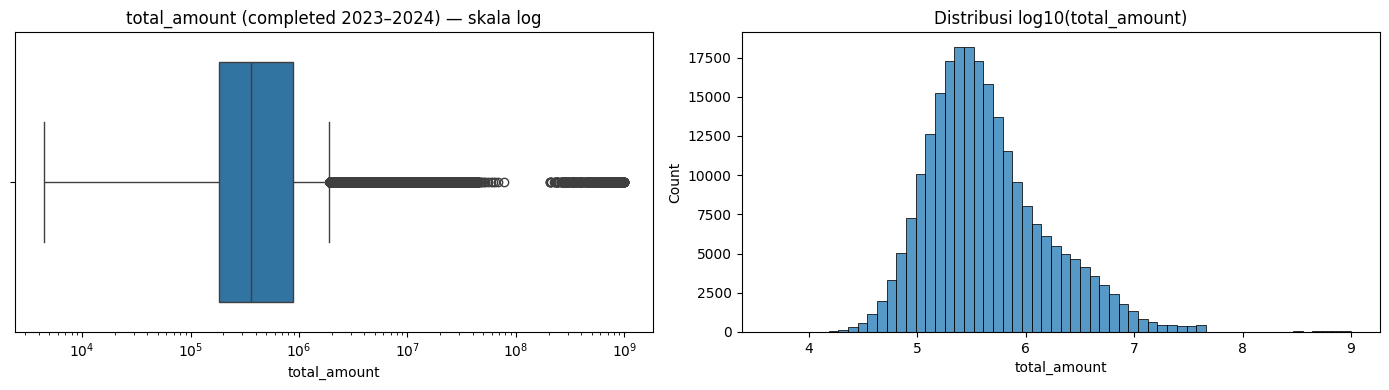

In [30]:
completed_period = (transactions['order_status'].eq('completed').fillna(False)
                    & transactions['order_date'].between(analysis_start, analysis_end))
amount = transactions.loc[completed_period, 'total_amount'].astype('float64')

q1, q3 = amount.quantile([.25, .75])
iqr_upper = q3 + 1.5 * (q3 - q1)
print(f'Batas atas IQR total_amount (completed 2023–2024): Rp{iqr_upper:,.0f}')
print(f'P99: Rp{amount.quantile(.99):,.0f} | maksimum: Rp{amount.max():,.0f}')

bins = [0, 1e6, 5e6, 10e6, 50e6, 100e6, 200e6, 500e6, np.inf]
labels = ['<1 jt', '1–5 jt', '5–10 jt', '10–50 jt', '50–100 jt', '100–200 jt', '200–500 jt', '>=500 jt']
dist = pd.cut(amount, bins=bins, labels=labels, right=False).value_counts(sort=False).to_frame('jumlah_transaksi')
dist['total_nilai'] = amount.groupby(pd.cut(amount, bins=bins, labels=labels, right=False), observed=False).sum()
dist['persen_nilai'] = (dist['total_nilai'] / amount.sum() * 100).round(2)
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=amount, ax=axes[0]); axes[0].set_xscale('log')
axes[0].set_title('total_amount (completed 2023–2024) — skala log')
sns.histplot(np.log10(amount[amount > 0]), bins=60, ax=axes[1])
axes[1].set_title('Distribusi log10(total_amount)')
plt.tight_layout(); plt.show()

Distribusi `total_amount` transaksi `completed` periode 2023–2024 menunjukkan pola yang tidak biasa:
- Batas atas IQR adalah Rp1.911.158 dan P99 Rp17.424.192, sedangkan nilai maksimum mencapai **Rp999.793.731**.
- **Tidak ada transaksi pada rentang Rp100–200 juta**, tetapi terdapat **384 transaksi ≥ Rp200 juta** (137 pada Rp200–500 juta dan 247 ≥ Rp500 juta).
- Kelompok ini hanya ±0,16% transaksi `completed`, tetapi menyumbang **45,02% total nilai belanja**, dengan median kuantitas hanya 2–3 item dan tersebar di semua kategori produk.

**Keputusan (notebook Transactions):** **384 transaksi `completed` periode 2023–2024 dengan `total_amount` ≥ Rp200.000.000 dikeluarkan** dari dataset analisis. Ambang Rp200 juta ditetapkan dari investigasi distribusi (celah kosong Rp100–200 juta), bukan batas transaksi valid dari sistem sumber. Batas IQR tidak dipakai karena akan menghapus ribuan transaksi bernilai wajar.

In [31]:
# Keputusan (notebook Transactions): keluarkan transaksi completed 2023–2024 dengan total_amount >= Rp200 juta
high_value = (transactions['total_amount'].ge(200_000_000).fillna(False)
              & transactions['order_status'].eq('completed').fillna(False)
              & transactions['order_date'].between(analysis_start, analysis_end))
share = transactions.loc[high_value, 'total_amount'].sum() / transactions.loc[completed_period, 'total_amount'].sum() * 100
print('Transaksi >= Rp200 juta (completed 2023–2024):', int(high_value.sum()),
      f'| porsi nilai belanja: {share:.2f}%')
display(transactions.loc[high_value].groupby('product_category')['item_quantity'].agg(['size', 'median']))

removed_log.append(transactions.loc[high_value, ['order_id']].assign(tabel='transactions', alasan='total_amount >= Rp200 juta (completed 2023–2024)'))
transactions = transactions.loc[~high_value].copy()
print('Sisa transactions:', len(transactions))

Transaksi >= Rp200 juta (completed 2023–2024): 384 | porsi nilai belanja: 45.02%


,size,median
product_category,,
elektronik,57,2.0
fashion,97,2.0
grocery,65,2.0
kesehatan,57,3.0
lainnya,37,3.0
olahraga,30,2.0
perabotan,41,2.0


Sisa transactions: 268076


### <span style="color:darkorange">Transactions — promo melebihi total belanja</span>


In [32]:
# Promo melebihi total_amount positif — dipertahankan (keputusan notebook Transactions)
promo_exceeds = (transactions['total_amount'].gt(0) & transactions['promo_amount'].gt(transactions['total_amount'])).fillna(False)
print('promo_amount > total_amount positif:', int(promo_exceeds.sum()),
      '| di antaranya completed:', int((promo_exceeds & transactions['order_status'].eq('completed')).sum()))

# Flag voucher besar: nominal promo Rp400 rb - Rp1 jt membentuk populasi terpisah (rentang Rp100-400 rb kosong).
# Flag ini tidak bergantung pada definisi total_amount (sebelum/sesudah promo) dan ikut masuk ke order_master.
VOUCHER_BESAR_MIN = 400_000
transactions['voucher_besar'] = transactions['promo_amount'].ge(VOUCHER_BESAR_MIN).fillna(False)
print(f"Promo di rentang Rp100-400 rb: {int(transactions['promo_amount'].between(100_000, VOUCHER_BESAR_MIN, inclusive='left').sum())} | "
      f"voucher_besar (promo >= Rp400.000): {int(transactions['voucher_besar'].sum()):,} transaksi, "
      f"{transactions.loc[transactions['voucher_besar'], 'promo_amount'].sum() / transactions['promo_amount'].sum():.1%} dari total promo")
display(pd.crosstab(promo_exceeds.rename('promo > total_amount'), transactions['voucher_besar'], margins=True))

promo_review = transactions.loc[promo_exceeds | transactions['voucher_besar'],
                                ['order_id', 'order_date', 'product_category', 'promo_amount', 'total_amount',
                                 'voucher_type', 'order_status', 'voucher_besar']].copy()
promo_review['promo_gt_total'] = promo_exceeds[promo_review.index]
promo_review['promo_ratio_pct'] = (promo_review['promo_amount'] / promo_review['total_amount'] * 100).round(1)
print('promo_review:', len(promo_review), 'transaksi (promo > total_amount atau voucher_besar)')
display(promo_review.sort_values('promo_ratio_pct', ascending=False).head(10))

promo_amount > total_amount positif: 11681 | di antaranya completed: 10310
Promo di rentang Rp100-400 rb: 0 | voucher_besar (promo >= Rp400.000): 15,591 transaksi, 80.3% dari total promo


voucher_besar,False,True,All
promo > total_amount,,,
False,252060,4335,256395
True,425,11256,11681
All,252485,15591,268076


promo_review: 16016 transaksi (promo > total_amount atau voucher_besar)


,order_id,order_date,product_category,promo_amount,total_amount,voucher_type,order_status,voucher_besar,promo_gt_total,promo_ratio_pct
170950,INV/241010/6349904,2024-10-10,grocery,741525,4443,free_ongkir,completed,True,True,16689.7
262322,INV/230201/5448448,2023-02-01,grocery,919316,11527,cashback,completed,True,True,7975.3
83292,INV/230928/1953906,2023-09-28,kesehatan,928471,18547,free_ongkir,completed,True,True,5006.0
59224,INV/230914/7599631,2023-09-14,grocery,934770,18676,cashback,returned,True,True,5005.2
172853,INV/230805/3721848,2023-08-05,grocery,954161,19162,free_ongkir,completed,True,True,4979.4
9123,INV/230407/6818766,2023-04-07,grocery,994081,20838,free_ongkir,completed,True,True,4770.5
10449,INV/230325/9637843,2023-03-25,grocery,958348,20177,cashback,completed,True,True,4749.7
148316,INV/230103/6153020,2023-01-03,grocery,671368,15512,diskon_persen,completed,True,True,4328.1
104922,INV/230115/5465535,2023-01-15,grocery,907577,21565,free_ongkir,completed,True,True,4208.6
139987,INV/231206/9420772,2023-12-06,grocery,867072,24140,free_ongkir,completed,True,True,3591.8


Terdapat **11.681 transaksi dengan `promo_amount` > `total_amount` positif** (10.310 berstatus `completed`). Sensitivity analysis pada notebook Transactions menunjukkan pengecualian kelompok ini menurunkan total promo 59,03% dan repeat buyer rate 1,52 poin persentase — dampak material terhadap analisis promo dan retensi.

**Keputusan:** transaksi ini **dipertahankan** dan tercatat pada `promo_review`, karena belum dipastikan apakah `total_amount` bernilai gross atau net dan apakah `promo_amount` mencakup cashback. Hasil analisis efisiensi promo perlu disertai keterangan keterbatasan ini.

**Flag `voucher_besar`:** nominal promo membentuk dua populasi terpisah. Promo reguler hampir seluruhnya ≤ Rp100 ribu, tidak ada satu pun promo di rentang Rp100–400 ribu, dan sisanya berada di Rp400 ribu–Rp1 juta. Transaksi dengan `promo_amount` ≥ Rp400.000 ditandai `voucher_besar = True` (**15.591 transaksi**, menyerap ±80% total promo) dan dicatat bersama kelompok promo > belanja pada `promo_review` (16.016 transaksi). Dari 11.681 transaksi promo > belanja, 11.256 adalah voucher besar. Sebanyak 4.335 voucher besar lainnya jatuh pada keranjang yang nilainya lebih besar dari voucher. Berbeda dengan label promo > belanja, flag ini **tidak bergantung pada definisi `total_amount`** (sebelum atau sesudah promo). Transaksi tetap dipertahankan; flag dipakai untuk segmentasi dan analisis sensitivitas, bukan karantina.

### <span style="color:darkorange">Tabel lain</span>


,kolom,ambang_review,jumlah,tindakan
0,sellers.avg_response_time_hours,> 72 jam,24,Dipertahankan
1,deliveries.sla_promised_days,> 7 hari,19685,Dipertahankan
2,tickets.resolution_time_hours,> 49.65 jam (IQR),3392,Dipertahankan


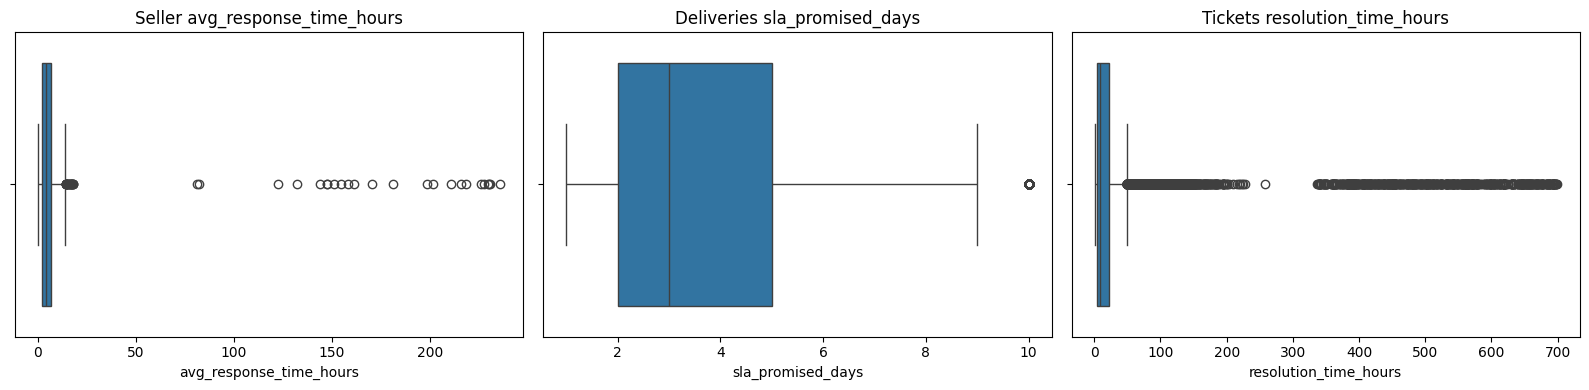

In [33]:
# Outlier pada tabel lain — dipertahankan sesuai keputusan masing-masing notebook
resp = sellers['avg_response_time_hours']
sla = deliveries['sla_promised_days']
dur = tickets['resolution_time_hours']
t_q1, t_q3 = dur.quantile([.25, .75]); t_upper = t_q3 + 1.5 * (t_q3 - t_q1)

display(pd.DataFrame({
    'kolom': ['sellers.avg_response_time_hours', 'deliveries.sla_promised_days', 'tickets.resolution_time_hours'],
    'ambang_review': ['> 72 jam', '> 7 hari', f'> {t_upper:.2f} jam (IQR)'],
    'jumlah': [int(resp.gt(72).sum()), int(sla.gt(7).sum()), int(dur.gt(t_upper).sum())],
    'tindakan': ['Dipertahankan', 'Dipertahankan', 'Dipertahankan']}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x=resp.astype('float64'), ax=axes[0]); axes[0].set_title('Seller avg_response_time_hours')
sns.boxplot(x=sla.astype('float64'), ax=axes[1]); axes[1].set_title('Deliveries sla_promised_days')
sns.boxplot(x=dur.astype('float64'), ax=axes[2]); axes[2].set_title('Tickets resolution_time_hours')
plt.tight_layout(); plt.show()

Nilai ekstrem pada tabel lain **dipertahankan** sesuai keputusan masing-masing notebook, karena ambang yang dipakai hanya sinyal review, bukan batas validitas:
- **24 penjual** dengan rata-rata waktu respons > 72 jam (maksimum 236 jam).
- **19.685 pengiriman** dengan SLA > 7 hari.
- **3.392 tiket** dengan durasi penyelesaian di atas batas IQR 49,65 jam.

<a id="Integritas-Relasi-Antar-Tabel"></a>
## <span style="color:darkorange">Integritas Relasi Antar Tabel</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Karena cleansing sebelumnya dilakukan per tabel, <code>order_id</code> yang dihapus dari transaksi (nominal ≤ 0, nominal ekstrem, dan konflik PK) masih tersisa pada deliveries dan tickets. Pada bagian ini relasi antar tabel diperiksa sesuai ERD sebelum data digabung.
</p>

In [34]:
valid_orders = set(transactions['order_id'])
removed_trx_ids = set(pd.concat([r for r in removed_log if (r['tabel'] == 'transactions').all()])['order_id'])
all_raw_orders = set(transactions_raw['order_id'].dropna())

def fk_status(order_ids):
    return np.select([order_ids.isin(valid_orders), order_ids.isin(removed_trx_ids), order_ids.isin(all_raw_orders)],
                     ['valid', 'order dihapus saat cleansing transaksi', 'ada di transaksi mentah, tidak di data bersih'], default='tidak ada di transaksi mentah')

deliveries['_fk'] = fk_status(deliveries['order_id'])
tickets['_fk'] = fk_status(tickets['order_id'])
display(pd.concat([deliveries['_fk'].value_counts().rename('deliveries'),
                   tickets['_fk'].value_counts().rename('tickets')], axis=1).fillna(0).astype(int))

# FK transactions -> users & sellers
orphan_user = ~transactions['user_id'].isin(users['user_id'])
print('transactions.user_id tidak ada di users  :', int(orphan_user.sum()),
      '| user_id unik:', transactions.loc[orphan_user, 'user_id'].nunique())
print('transactions.seller_id tidak ada di sellers:', int((~transactions['seller_id'].isin(sellers['seller_id'])).sum()))

,deliveries,tickets
_fk,,
valid,260739,31433
order dihapus saat cleansing transaksi,762,120


transactions.user_id tidak ada di users  : 399 | user_id unik: 399
transactions.seller_id tidak ada di sellers: 0


Hasil pemeriksaan foreign key:
- **762 deliveries** dan **120 tickets** merujuk ke `order_id` yang **telah dihapus** saat cleansing transaksi. Tidak ada deliveries/tickets yang merujuk ke order yang tidak pernah ada di transaksi mentah.
- Seluruh `seller_id` pada transaksi ditemukan di tabel sellers.
- **399 transaksi (399 `user_id` berbeda) merujuk ke `user_id` yang tidak ada di tabel users.** Transaksinya terlihat normal — pemakaian promo (58,1% vs 58,0%), porsi transaksi kampanye (34,8% vs 36,2%), dan median nilai belanja (Rp357.804 vs Rp356.482) setara dengan seluruh transaksi — dan setiap `user_id` tersebut hanya memiliki 1 transaksi. **Keputusan:** transaksi **dipertahankan** untuk metrik tingkat transaksi (total belanja, promo, subsidi ongkir), tidak diisi data pengguna buatan, dan ditandai dengan kolom `user_in_master = False` pada `order_master`. Transaksi ini **dikeluarkan dari analisis berbasis pengguna** (retensi/repeat order, churn, CLV, segmentasi kanal dan demografi), karena riwayatnya tidak lengkap dan akan otomatis tercatat sebagai pengguna yang tidak kembali.

**Keputusan — cascade delete:** deliveries dan tickets yang `order_id`-nya tidak ada di transaksi bersih **ikut dihapus**, agar tidak ada aktivitas pengiriman/komplain yang tidak memiliki transaksi induk.

In [35]:
# Cascade: deliveries & tickets yang order_id-nya tidak ada di transactions bersih ikut dihapus
for name in ['deliveries', 'tickets']:
    df = deliveries if name == 'deliveries' else tickets
    mask = df['_fk'].ne('valid')
    removed_log.append(df.loc[mask, ['order_id'] + (['ticket_id'] if name == 'tickets' else [])].assign(
        tabel=name, alasan='cascade: ' + df.loc[mask, '_fk']))
    print(f'{name}: dihapus {int(mask.sum())} record')
    display(df.loc[mask, '_fk'].value_counts().rename('jumlah').to_frame())

deliveries = deliveries.loc[deliveries['_fk'].eq('valid')].drop(columns='_fk').copy()
tickets = tickets.loc[tickets['_fk'].eq('valid')].drop(columns='_fk').copy()
assert deliveries['order_id'].isin(valid_orders).all() and tickets['order_id'].isin(valid_orders).all()
print('Deliveries tersisa:', len(deliveries), '| Tickets tersisa:', len(tickets))

deliveries: dihapus 762 record


,jumlah
_fk,
order dihapus saat cleansing transaksi,762


tickets: dihapus 120 record


,jumlah
_fk,
order dihapus saat cleansing transaksi,120


Deliveries tersisa: 260739 | Tickets tersisa: 31433


Selanjutnya diperiksa urutan kronologis antar tabel. Pengiriman tidak seharusnya terjadi sebelum transaksi dibuat (`dispatch_date < order_date`), dan tiket tidak seharusnya dibuat sebelum transaksi (`ticket_date < order_date`).

In [36]:
# Urutan kronologis: aktivitas turunan (pengiriman/tiket) tidak boleh terjadi sebelum transaksi induknya.
# order_date dijadikan acuan karena 100% konsisten dengan tanggal pada order_id.
order_dates = transactions.set_index('order_id')['order_date']

# 1) Deliveries: dispatch_date < order_date
dlv_order_date = deliveries['order_id'].map(order_dates)
dispatch_before_order = deliveries['dispatch_date'].lt(dlv_order_date).fillna(False).astype(bool)
delivery_before_order = deliveries['delivery_date'].lt(dlv_order_date).fillna(False).astype(bool)
out_of_range = (~deliveries['dispatch_date'].between(analysis_start, analysis_end)
                | ~deliveries['delivery_date'].between(analysis_start, analysis_end))
dlv_gap = (dlv_order_date - deliveries['dispatch_date']).dt.days[dispatch_before_order]

print('dispatch_date < order_date        :', int(dispatch_before_order.sum()),
      f'({dispatch_before_order.mean()*100:.2f}% deliveries)')
print('  - pada kelompok tanggal di luar 2023–2024:', int((dispatch_before_order & out_of_range).sum()))
print('  - delivery_date juga < order_date :', int((dispatch_before_order & delivery_before_order).sum()))
display(dlv_gap.value_counts().sort_index().rename_axis('selisih_hari').rename('jumlah').to_frame())
display(deliveries.loc[dispatch_before_order, 'delivery_status'].value_counts().rename('jumlah').to_frame())
display(deliveries.loc[dispatch_before_order, ['order_id', 'dispatch_date', 'delivery_date', 'delivery_status']]
        .assign(order_date=dlv_order_date[dispatch_before_order]).head(10))

# 2) Tickets: ticket_date < order_date
tkt_order_date = tickets['order_id'].map(order_dates)
ticket_before_order = tickets['ticket_date'].lt(tkt_order_date).fillna(False).astype(bool)
print('ticket_date < order_date          :', int(ticket_before_order.sum()))
display(tickets.loc[ticket_before_order, ['ticket_id', 'order_id', 'ticket_date', 'complaint_category', 'resolution_status']]
        .assign(order_date=tkt_order_date[ticket_before_order]))

# Keputusan: seluruh record deliveries & tickets yang terjadi sebelum order_date dikarantina.
# Transaksi induknya tetap dipertahankan karena transaksinya sendiri valid.
deliveries_quarantine_date = deliveries.loc[dispatch_before_order].assign(order_date=dlv_order_date[dispatch_before_order])
tickets_quarantine_date = tickets.loc[ticket_before_order].assign(order_date=tkt_order_date[ticket_before_order])

removed_log.append(deliveries.loc[dispatch_before_order, ['order_id']].assign(
    tabel='deliveries', alasan='dispatch_date < order_date'))
removed_log.append(tickets.loc[ticket_before_order, ['order_id', 'ticket_id']].assign(
    tabel='tickets', alasan='ticket_date < order_date'))

deliveries = deliveries.loc[~dispatch_before_order].copy()
tickets = tickets.loc[~ticket_before_order].copy()

assert not deliveries['dispatch_date'].lt(deliveries['order_id'].map(order_dates)).fillna(False).any()
assert not tickets['ticket_date'].lt(tickets['order_id'].map(order_dates)).fillna(False).any()
print('Deliveries dikarantina:', len(deliveries_quarantine_date), '| tersisa:', len(deliveries))
print('Tickets dikarantina   :', len(tickets_quarantine_date), '| tersisa:', len(tickets))

dispatch_date < order_date        : 531 (0.20% deliveries)
  - pada kelompok tanggal di luar 2023–2024: 10
  - delivery_date juga < order_date : 140


,jumlah
selisih_hari,
1,145
2,130
3,126
4,130


,jumlah
delivery_status,
delivered,477
failed,25
returned,18
in_transit,11


,order_id,dispatch_date,delivery_date,delivery_status,order_date
137,INV/230102/9387476,2023-01-01,2023-01-02,delivered,2023-01-02
199,INV/230104/8998122,2022-12-31,2023-01-02,delivered,2023-01-04
644,INV/230102/3389209,2022-12-30,2023-01-03,delivered,2023-01-02
1116,INV/230104/5467597,2023-01-03,2023-01-04,delivered,2023-01-04
1835,INV/230105/7077679,2023-01-04,2023-01-05,failed,2023-01-05
1935,INV/230106/7832210,2023-01-03,2023-01-05,delivered,2023-01-06
1937,INV/230105/9215143,2023-01-03,2023-01-05,delivered,2023-01-05
2231,INV/230105/1996383,2023-01-01,2023-01-05,delivered,2023-01-05
2284,INV/230102/6005303,2022-12-30,2023-01-05,delivered,2023-01-02
2388,INV/230106/3718188,2023-01-05,2023-01-06,delivered,2023-01-06


ticket_date < order_date          : 5


,ticket_id,order_id,ticket_date,complaint_category,resolution_status,order_date
4241,TKT-231007-8764,INV/231008/1775481,2023-10-07,keterlambatan,pending,2023-10-08
4670,TKT-230221-7957,INV/230225/8205011,2023-02-21,lainnya,pending,2023-02-25
19373,TKT-230724-1560,INV/230725/7679471,2023-07-24,refund,resolved,2023-07-25
20867,TKT-230623-6981,INV/230625/9785722,2023-06-23,produk_rusak,resolved,2023-06-25
25408,TKT-230822-1049,INV/230824/7614749,2023-08-22,lainnya,resolved,2023-08-24


Deliveries dikarantina: 531 | tersisa: 260208
Tickets dikarantina   : 5 | tersisa: 31428


Ditemukan **531 deliveries dengan `dispatch_date` < `order_date`** (0,20% data pengiriman) dan **5 tiket dengan `ticket_date` < `order_date`**. Notebook Deliveries sebelumnya hanya memeriksa kelompok tanggal di luar 2023–2024 (10 record). Setelah tabel dihubungkan, pola yang sama ternyata juga muncul pada periode 2023–2024.

Karakteristik record tersebut:
- `order_date` dapat dipercaya karena 100% konsisten dengan tanggal pada `order_id`; ketidaksesuaian berada pada sisi pengiriman/tiket.
- **140** dari 531 pengiriman bahkan memiliki `delivery_date` sebelum `order_date` (barang tercatat sampai sebelum dipesan).
- Selisih selalu 1–4 hari dan tersebar merata (145 / 130 / 126 / 130 record), mengindikasikan kesalahan pencatatan yang sistematis. Termasuk di dalamnya 8 pengiriman bertanggal dispatch Desember 2022.
- Kelima tiket juga dibuat 1–4 hari sebelum order, termasuk keluhan `keterlambatan` dan `produk_rusak` yang tidak mungkin terjadi sebelum order dibuat.

**Keputusan:** aktivitas turunan yang terjadi sebelum transaksi induknya dianggap tidak valid. **531 deliveries dan 5 tickets dikarantina**, karena tanggal yang benar tidak dapat diverifikasi. Transaksi induknya tetap dipertahankan karena transaksinya sendiri valid; pada tabel gabungan order tersebut tercatat tanpa data pengiriman/tiket. Record yang dikarantina disimpan pada `deliveries_quarantine_date` dan `tickets_quarantine_date` untuk audit.

Terakhir, diperiksa konsistensi lintas tabel lain yang belum tercakup pada notebook per tabel: tanggal order terhadap tanggal bergabung seller dan user, status order terhadap status pengiriman, serta durasi tiket yang belum selesai.

In [37]:
# Pemeriksaan konsistensi lintas tabel lainnya (tidak ada record yang dihapus)
chk = (transactions[['order_id', 'user_id', 'seller_id', 'order_date', 'order_status']]
       .merge(users[['user_id', 'join_date']], on='user_id', how='left')
       .merge(sellers[['seller_id', 'seller_join_date']], on='seller_id', how='left')
       .merge(deliveries[['order_id', 'delivery_status']], on='order_id', how='left'))

# 1) Order sebelum seller bergabung
before_seller = chk['order_date'] < chk['seller_join_date']
print('Order sebelum seller_join_date:', int(before_seller.sum()), f'({before_seller.mean() * 100:.1f}% transaksi)',
      '| seller:', chk.loc[before_seller, 'seller_id'].nunique())
display((chk['seller_join_date'] - chk['order_date']).dt.days[before_seller].describe().round(1).to_frame('selisih_hari'))

# 2) Order sebelum user mendaftar
before_user = chk['order_date'] < chk['join_date']
print('Order sebelum join_date user:', int(before_user.sum()))
display((chk['join_date'] - chk['order_date']).dt.days[before_user].value_counts().sort_index()
        .rename_axis('selisih_hari').rename('jumlah').to_frame())

# 3) Status order vs status pengiriman
display(pd.crosstab(chk['order_status'], chk['delivery_status'].fillna('<tidak ada data>')))

# 4) Durasi tiket yang belum final
nonfinal = tickets['resolution_status'].isin(['pending', 'escalated'])
print('Tiket pending/escalated:', int(nonfinal.sum()), '| dengan CSAT:', int((nonfinal & tickets['csat_score'].notna()).sum()))
display(tickets.groupby('resolution_status')['resolution_time_hours'].describe().round(1))

Order sebelum seller_join_date: 63548 (23.7% transaksi) | seller: 422


,selisih_hari
count,63548.0
mean,278.5
std,199.4
min,1.0
25%,91.0
50%,249.0
75%,447.0
max,729.0


Order sebelum join_date user: 20


,jumlah
selisih_hari,
1.0,10
2.0,8
3.0,2


delivery_status,<tidak ada data>,delivered,failed,in_transit,returned
order_status,,,,,
cancelled,7337,0,0,0,0
completed,477,213449,10364,4668,6391
refund,31,13692,653,312,442
returned,23,9316,460,202,259


Tiket pending/escalated: 6226 | dengan CSAT: 0


,count,mean,std,min,25%,50%,75%,max
resolution_status,,,,,,,,
escalated,2476.0,27.9,76.0,0.5,4.3,8.8,23.6,698.9
pending,3750.0,27.4,74.3,0.5,4.4,9.0,21.8,694.6
resolved,25202.0,27.3,72.9,0.5,4.4,9.1,22.5,698.3


| Pemeriksaan | Jumlah | Temuan | Keputusan |
|---|---|---|---|
| Order sebelum `seller_join_date` | 63.548 (23,7%) dari 422 seller | Selisih 1–729 hari (median 249 hari); terlalu besar untuk dianggap kesalahan transaksi, sehingga yang tidak dapat dipercaya adalah `seller_join_date` | Transaksi dipertahankan; `seller_join_date` **tidak digunakan** dalam analisis (mis. umur toko) |
| Order sebelum `join_date` user | 20 | Selisih 1–3 hari | Dipertahankan; tidak memengaruhi retensi karena retensi dihitung dari `order_date` |
| `order_status` vs `delivery_status` | ±21 ribu `completed` dengan pengiriman `failed` (10.364), `in_transit` (4.668), atau `returned` (6.391); `refund`/`returned` dengan pengiriman `delivered` (13.692 / 9.316) | Status tidak sejalan; order `cancelled` konsisten tanpa data pengiriman. Order tanpa data pengiriman (477 completed, 31 refund, 23 returned) adalah 531 record yang dikarantina | Tidak ada status yang diubah. Transaksi sukses untuk analisis promo dan retensi tetap didefinisikan sebagai `order_status = completed`; analisis pengiriman memakai `delivery_status` secara terpisah |
| Durasi tiket `pending`/`escalated` | 6.226 | Durasi belum final dan seluruhnya tanpa CSAT | Dipertahankan; rata-rata waktu penyelesaian dan CSAT hanya dihitung dari tiket `resolved` |

Temuan lain yang dicatat tanpa tindakan: 394 tiket bertanggal 2025 seluruhnya berasal dari order Desember 2024; jeda dispatch setelah order 0–6 hari; subsidi ongkir lebih besar dari ongkir yang dibayar user pada 96.934 transaksi (wajar bila ongkir user dihitung setelah subsidi); 3 transaksi `free_ongkir` dengan subsidi 0; status `suspended`/`inactive` pada user dan seller adalah kondisi saat data diambil sehingga riwayat transaksinya tidak dihapus.

<a id="Ringkasan-Data-Cleaning"></a>
## <span style="color:darkorange">Ringkasan Data Cleaning</span>


In [38]:
removed_all = pd.concat(removed_log, ignore_index=True)
display(removed_all.groupby(['tabel', 'alasan']).size().rename('record_dikeluarkan').reset_index())

final_tables = {'users': users, 'sellers': sellers, 'transactions': transactions,
                'deliveries': deliveries, 'tickets': tickets}
pk = {'users': 'user_id', 'sellers': 'seller_id', 'transactions': 'order_id', 'deliveries': 'order_id', 'tickets': 'ticket_id'}
cleaning_overview = pd.DataFrame({
    'baris_awal': {n: len(raw[n]) for n in raw},
    'baris_akhir': {n: len(df) for n, df in final_tables.items()},
    'kolom_akhir': {n: df.shape[1] for n, df in final_tables.items()},
    'PK_unik': {n: bool(df[pk[n]].is_unique) for n, df in final_tables.items()},
})
cleaning_overview['dikeluarkan'] = cleaning_overview['baris_awal'] - cleaning_overview['baris_akhir']
cleaning_overview['persen_dikeluarkan'] = (cleaning_overview['dikeluarkan'] / cleaning_overview['baris_awal'] * 100).round(3)
display(cleaning_overview)

for name, df in final_tables.items():
    df.reset_index(drop=True, inplace=True)
    assert df[pk[name]].notna().all() and df[pk[name]].is_unique
print('Missing akhir per tabel:')
display(pd.concat({n: df.isna().sum()[df.isna().sum() > 0] for n, df in final_tables.items()}).rename('missing').to_frame())

,tabel,alasan,record_dikeluarkan
0,deliveries,cascade: order dihapus saat cleansing transaksi,762
1,deliveries,dispatch_date < order_date,531
2,deliveries,order_id konflik / kosong (PK duplikat),24
3,tickets,cascade: order dihapus saat cleansing transaksi,120
4,tickets,ticket_date < order_date,5
5,transactions,duplikat identik (salinan berlebih),1071
6,transactions,order_id konflik (PK duplikat),32
7,transactions,total_amount <= 0,390
8,transactions,total_amount >= Rp200 juta (completed 2023–2024),384


,baris_awal,baris_akhir,kolom_akhir,PK_unik,dikeluarkan,persen_dikeluarkan
users,52847,52847,13,True,0,0.000
sellers,1238,1238,9,True,0,0.000
transactions,269953,268076,17,True,1877,0.695
deliveries,261525,260208,11,True,1317,0.504
tickets,31553,31428,9,True,125,0.396


Missing akhir per tabel:


missing
users        gender                     5149
             referral_code_used        44865
             last_active_date            792
transactions voucher_type             112495
deliveries   courier_name               9933
             courier_rating            77447
             delivery_duration_days    23751
tickets      csat_score                 9935

| Tabel | Masalah | Jumlah | Tindakan |
|---|---|---|---|
| Semua | Missing values (gender, referral, voucher, kurir, rating, CSAT) | lihat Missing Values | Dipertahankan, tanpa imputasi |
| Transactions | Variasi label `payment_method` | 27 → 16 label | Standardisasi (detail VA dipertahankan) |
| Users / Deliveries | Variasi label Jakarta | 2.397 / 19.316 | Standardisasi ke `Jakarta` |
| Transactions | Duplikat identik | 1.071 | Dihapus |
| Transactions | `order_id` konflik | 16 ID / 32 record | Dihapus |
| Deliveries | `order_id` konflik | 12 ID / 24 record | Dikarantina |
| Transactions | `order_date` 1970/2030 | 792 | Dikoreksi dari `order_id` |
| Transactions | `total_amount` ≤ 0 (negatif; 332 completed, 58 non-completed) | 390 | Dikarantina |
| Transactions | `promo_amount` negatif | 0 | Aturan karantina dipasang (tidak ada kasus) |
| Transactions | `total_amount` ≥ Rp200 juta (completed 2023–2024) | 384 | Dihapus |
| Transactions | `promo_amount` > `total_amount` | 11.681 | Dipertahankan, perlu review (`promo_review`) |
| Transactions | Voucher besar (`promo_amount` ≥ Rp400 ribu) | 15.591 | Dipertahankan; ditandai `voucher_besar` |
| Users | `DKI Jakarta` pada kolom kota | 2.395 | Diseragamkan menjadi `Jakarta` |
| Users | Provinsi tidak sesuai kota | 952 | `province` dikoreksi dari kota |
| Users | `last_active_date` sebelum `join_date` | 792 | `last_active_date` dikosongkan (NaT); kolom tidak dipakai untuk churn |
| Deliveries | Tanggal 2025, tanggal pada status non-delivered, kurir kosong, SLA & layanan tidak lazim | lihat Data Range Constrains | Diterima; keterlambatan per jenis layanan dianalisis pada EDA |
| Deliveries / Tickets | `order_id` dihapus dari transaksi (cascade) | 762 / 120 | Dihapus |
| Deliveries / Tickets | Tanggal pengiriman/tiket sebelum `order_date` | 531 / 5 | Dikarantina |
| Transactions | `user_id` tidak ada di users | 399 | Dipertahankan; `user_in_master = False`, dikeluarkan dari analisis berbasis pengguna |
| Transactions / Sellers | Order sebelum `seller_join_date` | 63.548 | Dipertahankan; `seller_join_date` tidak dipakai |
| Transactions / Users | Order sebelum `join_date` | 20 | Dipertahankan |
| Transactions / Deliveries | `order_status` tidak sejalan dengan `delivery_status` | ±21 ribu | Dipertahankan; transaksi sukses = `completed` |
| Tickets | Durasi `pending`/`escalated` | 6.226 | Dipertahankan; durasi & CSAT hanya dari `resolved` |

**Hasil akhir:** users 52.847 (tetap), sellers 1.238 (tetap), transactions **268.076** (−1.877; 0,695%), deliveries **260.208** (−1.317; 0,504%), tickets **31.428** (−125; 0,396%). Seluruh primary key unik dan tidak kosong.

<a id="Data-Merging"></a>
# <span style="color:darkorange">Data Merging</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Setelah seluruh tabel bersih dan relasinya konsisten, data digabung menjadi tabel analisis berlevel order (<code>order_master</code>): transaksi sebagai tabel kiri digabung dengan users dan sellers (many-to-one), deliveries (one-to-one), serta jumlah tiket per order. Tiket diagregasi terlebih dahulu agar nilai transaksi tidak tergandakan pada order dengan lebih dari satu tiket. Parameter <code>validate</code> memastikan tidak ada baris yang bertambah akibat join.
</p>


In [39]:
# Agregasi tiket ke level order (relasi 1 : 0..N) agar nilai transaksi tidak tergandakan
ticket_per_order = tickets.groupby('order_id').agg(ticket_count=('ticket_id', 'size')).reset_index()


order_master = (transactions
    .merge(users, on='user_id', how='left', validate='many_to_one', indicator='user_match')
    .merge(sellers, on='seller_id', how='left', validate='many_to_one')
    .merge(deliveries, on='order_id', how='left', validate='one_to_one', indicator='delivery_match')
    .merge(ticket_per_order, on='order_id', how='left', validate='one_to_one'))

order_master['has_delivery'] = order_master.pop('delivery_match').eq('both')
order_master['ticket_count'] = order_master['ticket_count'].fillna(0).astype('Int64')
order_master['user_in_master'] = order_master.pop('user_match').eq('both')

assert len(order_master) == len(transactions) and order_master['order_id'].is_unique
print('order_master:', order_master.shape)
print('Order dengan data pengiriman:', int(order_master['has_delivery'].sum()),
      '| order dengan tiket:', int(order_master['ticket_count'].gt(0).sum()),
      '| order tanpa data user (user_in_master = False):', int((~order_master['user_in_master']).sum()))
display(order_master.head())

order_master: (268076, 50)
Order dengan data pengiriman: 260208 | order dengan tiket: 31428 | order tanpa data user (user_in_master = False): 399


,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used,voucher_besar,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date,seller_name,seller_city,seller_join_date,is_official_store,seller_rating,category_focus,avg_response_time_hours,seller_status,courier_name,dispatch_date,delivery_date,destination_city,delivery_status,sla_promised_days,courier_service_type,shipping_zone,courier_rating,delivery_duration_days,ticket_count,has_delivery,user_in_master
0,INV/240425/2808734,84HYARD9MT,2024-04-25,BNI VA,28547,137995,grocery,1,adhiarja-store-6855,1756,17647,free_ongkir,Bank Transfer,completed,True,iOS,False,2023-11-10,Male,Manado,Sulawesi Utara,42.0,iOS,organic,True,True,<NA>,active,2023-11-18,Adhiarja Store,Medan,2019-10-06,False,4.1,grocery,15.3,active,GoTo Logistics,2024-04-26,2024-04-30,Manado,delivered,3.0,reguler,luar_kota,<NA>,4.0,0,True,True
1,INV/231010/9230021,WVURB9FA77,2023-10-10,Bank Transfer,10691,110431,grocery,2,adhiarja-store-6855,5399,10019,cashback,Bank Transfer,completed,True,Android,False,2023-09-26,Male,Semarang,Jawa Tengah,43.0,Android,ads,False,True,<NA>,active,2023-09-29,Adhiarja Store,Medan,2019-10-06,False,4.1,grocery,15.3,active,AnterAja,2023-10-12,2023-10-16,Denpasar,delivered,5.0,reguler,luar_pulau,5.0,4.0,0,True,True
2,INV/241003/9388967,66MKJ5224E,2024-10-03,Bank Transfer,11100,114575,grocery,1,adhiarja-store-6855,8000,6627,diskon_persen,Bank Transfer,completed,False,Android,False,2024-04-28,Female,Pontianak,Kalimantan Barat,57.0,Android,ads,True,True,<NA>,active,2024-05-19,Adhiarja Store,Medan,2019-10-06,False,4.1,grocery,15.3,active,GoTo Logistics,2024-10-04,2024-10-17,Bandung,delivered,4.0,same_day,luar_kota,3.1,13.0,0,True,True
3,INV/240305/7687566,ZUKS9KUS4Y,2024-03-05,Bank Transfer,0,127884,grocery,1,adhiarja-store-6855,7501,3329,<NA>,Bank Transfer,completed,False,Android,False,2024-01-23,Female,Pontianak,Kalimantan Barat,77.0,Android,organic,True,True,<NA>,active,2024-01-29,Adhiarja Store,Medan,2019-10-06,False,4.1,grocery,15.3,active,GoTo Logistics,2024-03-06,2024-03-06,Pontianak,delivered,1.0,reguler,dalam_kota,<NA>,0.0,0,True,True
4,INV/231101/2944963,YKXAJSWHUD,2023-11-01,Bank Transfer,9742,143477,grocery,6,adhiarja-store-6855,13669,1031,free_ongkir,Bank Transfer,completed,False,Android,False,2023-10-25,<NA>,Surabaya,Jawa Timur,40.0,Android,organic,True,True,<NA>,active,2023-11-18,Adhiarja Store,Medan,2019-10-06,False,4.1,grocery,15.3,active,SiCepat,2023-11-02,2023-11-06,Palembang,delivered,4.0,reguler,luar_kota,5.0,4.0,0,True,True


Tabel `order_master` berisi **268.076 order × 50 kolom** (satu baris per order), termasuk flag `voucher_besar`. Sebanyak 260.208 order memiliki data pengiriman (`has_delivery`) dan 31.428 order memiliki tiket (`ticket_count` > 0). Kolom `user_in_master` bernilai False untuk 399 order yang `user_id`-nya tidak ada di tabel users. Order tanpa pengiriman/tiket diperbolehkan oleh ERD (cakupan kedua tabel bersifat parsial). Ke-12 `order_id` deliveries yang dikarantina karena konflik PK tidak lagi terdapat pada transaksi bersih, sehingga tidak memengaruhi tabel ini.

<a id="Load-Data-to-BigQuery"></a>
# <span style="color:darkorange">Load Data to BigQuery</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Data bersih diunggah kembali ke Google BigQuery pada dataset <code>datawarehouse_tokped</code> (dibuat otomatis bila belum ada). Lima tabel bersih, tabel gabungan <code>order_master</code>, dan catatan record yang dikeluarkan (<code>audit_removed_records</code>) diunggah dengan <code>if_exists='replace'</code>.
</p>


In [40]:
# Pastikan dataset tujuan tersedia
client = bigquery.Client(project=project_id, credentials=credentials)
client.create_dataset(f'{project_id}.{dw_dataset_id}', exists_ok=True)

def prepare_for_bq(df):
    out = df.copy()
    for col in out.columns:
        if isinstance(out[col].dtype, pd.StringDtype):
            out[col] = out[col].astype(object).where(out[col].notna(), None)
    return out

clean_outputs = {
    'users_clean': users,
    'sellers_clean': sellers,
    'transactions_clean': transactions,
    'deliveries_clean': deliveries,
    'customer_service_tickets_clean': tickets,
    'order_master': order_master,
    'audit_removed_records': removed_all,
}

# Upload the clean data to BigQuery
for table_name, df in clean_outputs.items():
    pandas_gbq.to_gbq(
        prepare_for_bq(df),
        f'{dw_dataset_id}.{table_name}',
        project_id=project_id,
        if_exists='replace',
        credentials=credentials
    )
    print(f'Uploaded {dw_dataset_id}.{table_name}: {df.shape}')

100%|██████████| 1/1 [00:00<00:00, 7231.56it/s]


Uploaded datawarehouse_tokped.users_clean: (52847, 13)


100%|██████████| 1/1 [00:00<00:00, 6831.11it/s]


Uploaded datawarehouse_tokped.sellers_clean: (1238, 9)


100%|██████████| 1/1 [00:00<00:00, 7973.96it/s]


Uploaded datawarehouse_tokped.transactions_clean: (268076, 17)


... (4 outputs left out)

100%|██████████| 1/1 [00:00<00:00, 7710.12it/s]


Uploaded datawarehouse_tokped.order_master: (268076, 50)


100%|██████████| 1/1 [00:00<00:00, 8065.97it/s]

Uploaded datawarehouse_tokped.audit_removed_records: (3319, 4)


In [41]:
# Verifikasi jumlah baris di BigQuery
verify = pandas_gbq.read_gbq(
    ' UNION ALL '.join(f"SELECT '{t}' AS table_name, COUNT(*) AS row_count FROM `{project_id}.{dw_dataset_id}.{t}`"
                       for t in clean_outputs),
    project_id=project_id, credentials=credentials)
verify['rows_dataframe'] = verify['table_name'].map({t: len(df) for t, df in clean_outputs.items()})
verify['sama'] = verify['row_count'].eq(verify['rows_dataframe'])
display(verify)

Downloading: 100%|██████████|


,table_name,row_count,rows_dataframe,sama
0,users_clean,52847,52847,True
1,sellers_clean,1238,1238,True
2,transactions_clean,268076,268076,True
3,deliveries_clean,260208,260208,True
4,customer_service_tickets_clean,31428,31428,True
5,order_master,268076,268076,True
6,audit_removed_records,3319,3319,True


In [42]:
# (Opsional) simpan salinan CSV hasil cleansing
for table_name, df in clean_outputs.items():
    df.to_csv(f'{table_name}.csv', index=False, date_format='%Y-%m-%d')
print('CSV tersimpan:', list(clean_outputs))

CSV tersimpan: ['users_clean', 'sellers_clean', 'transactions_clean', 'deliveries_clean', 'customer_service_tickets_clean', 'order_master', 'audit_removed_records']


<a id="Data-Analysis"></a>
# <span style="color:darkorange">Data Analysis</span>


<a id="Exploratory-Data-Analysis"></a>
## <span style="color:darkorange">Exploratory Data Analysis</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Analisis menggunakan tabel <code>order_master</code> (atau tabel bersih per entitas) hasil tahap sebelumnya. Aturan penggunaan data dari tahap cleansing: (1) transaksi sukses = <code>order_status = completed</code>; (2) churn dan retensi dihitung dari <code>order_date</code>, bukan <code>last_active_date</code>; (3) analisis berbasis pengguna hanya memakai order dengan <code>user_in_master = True</code> (399 order dikecualikan); (4) transaksi dengan <code>promo_amount</code> > <code>total_amount</code> masih termasuk di dalam data, dan transaksi dengan promo ≥ Rp400 ribu ditandai <code>voucher_besar</code>; (5) <code>seller_join_date</code> tidak digunakan; (6) durasi penyelesaian dan CSAT tiket hanya dari status <code>resolved</code>; (7) <code>courier_name</code> kosong dikelompokkan sebagai "Tidak diketahui" hanya pada salinan data untuk analisis per kurir; (8) perhitungan repeat order 90 hari memerlukan jendela observasi lengkap (pengguna yang bertransaksi pertama mendekati akhir 2024 belum tentu dapat diamati 90 hari).
</p>

### <span style="color:darkorange">0. Definisi Kohort & Validasi Problem Statement</span>


| Metrik | Definisi operasional |
|---|---|
| Populasi | Order dengan `user_in_master = True`; transaksi sukses = `order_status = completed` |
| Order pertama | Order pertama yang teramati per user (semua status), diurutkan `order_date` lalu `order_id` |
| Kohort | Order pertama berstatus `completed` dan `delivered`, dengan `delivery_date` ≤ 31 Des 2024 − jendela (60/90 hari) agar masa observasi lengkap |
| Repeat | Ada order `completed` berikutnya dengan `order_date` > `delivery_date` dan ≤ `delivery_date` + jendela |
| Churn | Tidak ada repeat dalam 90 hari (definisi brief) |
| Jendela | **60 hari** sebagai baseline repeat dan **90 hari** untuk churn; alasannya ditunjukkan pada tabel penentuan jendela di bawah |
| Terlambat | `delivery_duration_days` > `sla_promised_days` (hanya status `delivered`) |
| Promo order pertama | `promo_amount` > 0 pada order pertama |

Catatan: "order pertama" adalah order pertama yang **teramati** sejak Januari 2023, bukan pasti pembelian pertama sepanjang riwayat pengguna. Penggunaan promo dan keterlambatan bukan hasil penugasan acak, sehingga seluruh hubungan bersifat **asosiasi**, bukan sebab-akibat.

In [43]:
from scipy import stats

ALPHA = 0.05
PRIMARY, TEAL, ORANGE, GRAY = '#163B65', '#168A79', '#D7764F', '#748296'
sns.set_theme(style='whitegrid', context='notebook')

def pct(x, d=1): return f'{x*100:.{d}f}%'
def rp(x): return 'Rp' + f'{x:,.0f}'.replace(',', '.')

def wilson(x, n, z=1.959964):
    p = x / n; den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

def two_prop(x1, n1, x2, n2):
    """Uji z dua proporsi (pooled) + 95% CI selisih metode Newcombe (A - B)."""
    p1, p2 = x1 / n1, x2 / n2
    p = (x1 + x2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    l1, u1 = wilson(x1, n1); l2, u2 = wilson(x2, n2)
    d = p1 - p2
    low = d - np.sqrt((p1 - l1)**2 + (u2 - p2)**2)
    high = d + np.sqrt((u1 - p1)**2 + (p2 - l2)**2)
    return dict(p_a=p1, p_b=p2, diff=d, low=low, high=high, p=2 * stats.norm.sf(abs(z)))

def holm(pvals):
    pvals = np.asarray(pvals); order = np.argsort(pvals); m = len(pvals)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(running, 1)
    return adj

# ---------------- Data dasar sesuai aturan penggunaan data ----------------
om = order_master.copy()
for col in ['order_date', 'join_date', 'dispatch_date', 'delivery_date']:
    om[col] = pd.to_datetime(om[col])
END = om['order_date'].max()

base = om.loc[om['user_in_master']].copy()                  # aturan (3)
completed = base.loc[base['order_status'].eq('completed')].copy()   # aturan (1)

delivered_ok = (base['delivery_status'].eq('delivered') & base['delivery_duration_days'].notna()
                & base['sla_promised_days'].notna())             # durasi hanya tersedia untuk status delivered
base['late_delivery'] = np.where(delivered_ok, base['delivery_duration_days'] > base['sla_promised_days'], np.nan)
base['days_over_sla'] = np.where(delivered_ok, (base['delivery_duration_days'] - base['sla_promised_days']).clip(lower=0), np.nan)

# Order pertama yang teramati per user (semua status), diurutkan order_date lalu order_id
first_order = base.sort_values(['user_id', 'order_date', 'order_id']).drop_duplicates('user_id')

def build_cohort(window):
    """Kohort first order completed & delivered dengan jendela observasi penuh (aturan 8).
    Repeat = order completed berikutnya dengan order_date > delivery_date dan <= delivery_date + window hari."""
    c = first_order.loc[first_order['order_status'].eq('completed') & first_order['late_delivery'].notna()].copy()
    c = c.loc[c['delivery_date'] <= END - pd.Timedelta(days=window)]
    nxt = completed[['user_id', 'order_id', 'order_date', 'total_amount']].merge(
        c[['user_id', 'order_id', 'delivery_date']].rename(columns={'order_id': 'first_order_id'}), on='user_id')
    nxt = nxt.loc[nxt['order_id'].ne(nxt['first_order_id']) & nxt['order_date'].gt(nxt['delivery_date'])
                  & nxt['order_date'].le(nxt['delivery_date'] + pd.Timedelta(days=window))]
    agg = nxt.groupby('user_id').agg(first_repeat_date=('order_date', 'min'), repeat_orders=('order_id', 'nunique'),
                                    repeat_gmv=('total_amount', 'sum'))
    c = c.join(agg, on='user_id')
    c['repeat'] = c['repeat_orders'].notna().astype(int)
    c['repeat_gmv'] = c['repeat_gmv'].fillna(0)
    c['repeat_days'] = (c['first_repeat_date'] - c['delivery_date']).dt.days
    c['late_delivery'] = c['late_delivery'].astype(int)
    c['promo_first'] = c['promo_amount'].gt(0).astype(int)
    c['campaign_first'] = c['is_campaign_period'].astype(int)
    c['voucher'] = c['voucher_type'].fillna('tanpa_voucher')
    return c

cohort60 = build_cohort(60)
cohort90 = build_cohort(90)
display(pd.DataFrame({
    'Indikator': ['User (user_in_master = True)', 'Kohort 60 hari (first order completed & delivered, follow-up penuh)',
                  'Repeat 60 hari', 'Kohort 90 hari', 'Repeat 90 hari'],
    'Nilai': [f"{base['user_id'].nunique():,}", f'{len(cohort60):,}', pct(cohort60["repeat"].mean()),
              f'{len(cohort90):,}', pct(cohort90["repeat"].mean())]}))

,Indikator,Nilai
0,User (user_in_master = True),"52,550"
1,Kohort 60 hari (first order completed & delive...,"39,363"
2,Repeat 60 hari,74.7%
3,Kohort 90 hari,"38,276"
4,Repeat 90 hari,77.0%


**Asal jumlah kohort dan penentuan jendela repeat.** Sel berikut menunjukkan (a) bagaimana 52.550 pengguna menyusut menjadi kohort 60 hari, dan (b) dasar pemilihan jendela 60 dan 90 hari berdasarkan waktu yang dibutuhkan pengguna untuk melakukan pembelian kedua, pada kohort yang dapat diamati penuh selama 365 hari.

,Tahap,User,Dikeluarkan
0,User (user_in_master = True),52550,NaN
1,Order pertama completed,46136,6414.0
2,Order pertama delivered (durasi & SLA valid),41821,4315.0
3,Barang pertama diterima paling lambat 31 Des 2...,39363,2458.0


Order pertama tidak completed : {'refund': 2912, 'returned': 2035, 'cancelled': 1467}
Order pertama completed tetapi tidak delivered : {'failed': 2073, 'returned': 1243, 'in_transit': 914, 'tanpa data pengiriman': 85}

Kohort dengan follow-up 365 hari: 28,724 user | 22,274 kembali dalam 1 tahun


,sudah kembali dalam (hari)
50% user yang kembali,13
75% user yang kembali,24
90% user yang kembali,43
95% user yang kembali,55
99% user yang kembali,86


,Jendela (hari),% kohort repeat,% dari user yang kembali dalam 1 tahun,User yang dapat dianalisis,Gap tepat waktu - terlambat (pp)
0,7,23.5,30.3,41282,4.73
1,14,42.4,54.7,41072,7.60
2,30,64.0,82.5,40476,10.92
3,45,71.0,91.6,39901,11.96
4,55,73.8,95.2,39503,12.86
5,60,74.7,96.3,39363,12.99
6,90,77.0,99.3,38276,13.14
7,120,77.4,99.9,37188,13.39
8,180,77.5,100.0,34999,13.32
9,365,77.5,100.0,28724,13.32


Tambahan % kohort yang kembali per 10 hari:


,1-10,11-20,21-30,31-40,41-50,51-60,61-70,71-80,81-90,91-100,101-110,111-120,121-130,131-140,141-150,151-160,161-170,171-180
tambahan_repeat_pp,32.35,21.03,10.59,4.79,3.87,2.03,1.11,0.73,0.47,0.22,0.16,0.08,0.04,0.03,0.01,0.01,0.0,0.0


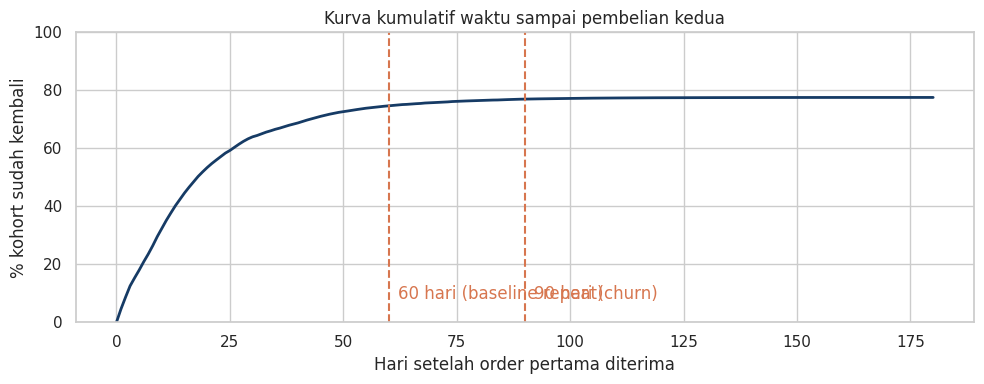

In [44]:
# (a) Dari mana jumlah kohort berasal: 52.550 user -> kohort 60 hari
fo_all = first_order.copy()
step1 = fo_all.loc[fo_all['order_status'].eq('completed')]
step2 = step1.loc[step1['late_delivery'].notna()]
step3 = step2.loc[step2['delivery_date'] <= END - pd.Timedelta(days=60)]
funnel = pd.DataFrame({
    'Tahap': ['User (user_in_master = True)', 'Order pertama completed', 'Order pertama delivered (durasi & SLA valid)',
              'Barang pertama diterima paling lambat 31 Des 2024 - 60 hari'],
    'User': [len(fo_all), len(step1), len(step2), len(step3)]})
funnel['Dikeluarkan'] = funnel['User'].shift(1) - funnel['User']
display(funnel)
print('Order pertama tidak completed :', fo_all.loc[fo_all['order_status'].ne('completed'), 'order_status'].value_counts().to_dict())
print('Order pertama completed tetapi tidak delivered :',
      step1.loc[step1['late_delivery'].isna(), 'delivery_status'].fillna('tanpa data pengiriman').value_counts().to_dict())

# (b) Penentuan jendela repeat: waktu sampai pembelian kedua pada kohort dengan follow-up penuh 365 hari
HORIZON = 365
cand = step2.loc[step2['delivery_date'] <= END - pd.Timedelta(days=HORIZON)].copy()
nxt_w = completed[['user_id', 'order_id', 'order_date']].merge(
    cand[['user_id', 'order_id', 'delivery_date']].rename(columns={'order_id': 'fo'}), on='user_id')
nxt_w = nxt_w.loc[nxt_w['order_id'].ne(nxt_w['fo']) & nxt_w['order_date'].gt(nxt_w['delivery_date'])]
days_to_repeat = (nxt_w.groupby('user_id')['order_date'].min() - cand.set_index('user_id')['delivery_date']).dt.days
days_to_repeat = days_to_repeat[days_to_repeat.le(HORIZON)]
cand['days_to_repeat'] = cand['user_id'].map(days_to_repeat)

print(f'\nKohort dengan follow-up {HORIZON} hari: {len(cand):,} user | {len(days_to_repeat):,} kembali dalam 1 tahun')
display(pd.Series({f'{int(q*100)}% user yang kembali': int(np.ceil(days_to_repeat.quantile(q)))
                   for q in [.5, .75, .9, .95, .99]}, name='sudah kembali dalam (hari)').to_frame())

rows = []
for w in [7, 14, 30, 45, 55, 60, 90, 120, 180, 365]:
    rep = cand['days_to_repeat'].le(w)
    by_late = rep.groupby(cand['late_delivery'].astype(int)).mean()
    rows.append({'Jendela (hari)': w, '% kohort repeat': round(rep.mean() * 100, 1),
                 '% dari user yang kembali dalam 1 tahun': round(days_to_repeat.le(w).mean() * 100, 1),
                 'User yang dapat dianalisis': int((step2['delivery_date'] <= END - pd.Timedelta(days=w)).sum()),
                 'Gap tepat waktu - terlambat (pp)': round((by_late[0] - by_late[1]) * 100, 2)})
window_table = pd.DataFrame(rows)
display(window_table)

edges = list(range(0, 181, 10))
cum = [cand['days_to_repeat'].le(x).mean() * 100 for x in edges]
increments = pd.Series([b - a for a, b in zip(cum, cum[1:])],
                       index=[f'{a + 1}-{b}' for a, b in zip(edges, edges[1:])], name='tambahan_repeat_pp')
print('Tambahan % kohort yang kembali per 10 hari:')
display(increments.round(2).to_frame().T)

fig, ax = plt.subplots(figsize=(10, 4))
xs = np.arange(0, 181)
ax.plot(xs, [cand['days_to_repeat'].le(x).mean() * 100 for x in xs], color=PRIMARY, lw=2)
for w, lab in [(60, 'baseline repeat'), (90, 'churn')]:
    ax.axvline(w, color=ORANGE, ls='--'); ax.text(w + 2, 8, f'{w} hari ({lab})', color=ORANGE)
ax.set_xlabel('Hari setelah order pertama diterima'); ax.set_ylabel('% kohort sudah kembali')
ax.set_title('Kurva kumulatif waktu sampai pembelian kedua'); ax.set_ylim(0, 100)
plt.tight_layout(); plt.show()

**Interpretasi kohort:**
- Dari **52.550** pengguna, **39.363** masuk kohort 60 hari. Sebanyak 6.414 dikeluarkan karena order pertamanya tidak completed (refund 2.912, returned 2.035, cancelled 1.467), 4.315 karena order pertamanya tidak delivered (failed 2.073, returned 1.243, in_transit 914, tanpa data pengiriman 85), dan 2.458 karena barangnya diterima setelah 1 November 2024 sehingga belum dapat diamati penuh 60 hari (aturan 8).
- Dari 39.363 pengguna tersebut, **74,7% kembali berbelanja dalam 60 hari** — angka ini menjadi baseline retensi untuk semua perbandingan berikutnya. Kohort 90 hari (38.276 pengguna) memiliki repeat 77,0% karena waktu pengamatannya lebih panjang.
- Pengguna dengan order pertama gagal dikirim tidak masuk kohort utama dan dianalisis terpisah pada pertanyaan 4–5 (repeat hanya 27,1%), sehingga kohort utama sedikit lebih "sehat" daripada keseluruhan pengguna.

**Alasan pemilihan jendela:**
- **Pengguna yang kembali umumnya kembali dengan cepat:** separuhnya dalam 13 hari, 90% dalam 43 hari.
- **60 hari dipilih sebagai baseline repeat** karena menangkap 95% pengguna yang kembali (titik 95% = 55 hari, dibulatkan ke 60 hari; 96,3% pada 60 hari), dengan data yang hilang sedikit (39.363 vs 40.476 pengguna pada jendela 30 hari). Jendela 30 hari terlalu pendek: ±17,5% pengguna yang sebenarnya kembali akan salah terhitung tidak kembali.
- **90 hari dipakai untuk churn** karena kurva sudah mendatar: 99% pengguna yang kembali sudah kembali di hari ke-86, dan tambahan setelah hari ke-90 kurang dari 0,25 pp per 10 hari. Jendela ini juga sesuai definisi repeat order pada brief.
- **Jendela yang lebih panjang mahal:** jumlah pengguna yang dapat dianalisis turun menjadi 34.999 (180 hari) dan 28.724 (365 hari), hanya untuk tambahan repeat ±0,5 pp dibanding 90 hari.
- **Kesimpulan tidak bergantung pada pilihan jendela:** gap repeat antara tepat waktu dan terlambat 13,0 pp (60 hari), 13,1 pp (90 hari), dan 13,3 pp (180–365 hari).

Gambaran umum insentif promo dan kinerja pengiriman pada data yang dianalisis:

In [45]:
comp_all = completed
deliv = base.loc[base['late_delivery'].notna()]
display(pd.DataFrame({'Indikator': ['Order completed', 'GMV (total_amount)', 'Promo tercatat', 'Subsidi ongkir platform',
                                    'Rasio promo/GMV', 'Order completed dengan promo', 'Tingkat keterlambatan (delivered)',
                                    'Pengiriman gagal (dari seluruh pengiriman)'],
                      'Nilai': [f'{len(comp_all):,}', rp(comp_all['total_amount'].sum()), rp(comp_all['promo_amount'].sum()),
                                rp(comp_all['shipping_subsidy_platform'].sum()),
                                pct(comp_all['promo_amount'].sum() / comp_all['total_amount'].sum(), 2),
                                pct(comp_all['promo_amount'].gt(0).mean()), pct(deliv['late_delivery'].mean()),
                                pct(base['delivery_status'].eq('failed').sum() / base['has_delivery'].sum())]}))
display(pd.concat({'Zona': deliv.groupby('shipping_zone')['late_delivery'].mean(),
                   'Kampanye': deliv.groupby('is_campaign_period')['late_delivery'].mean()})
        .mul(100).round(2).rename('tingkat_keterlambatan_%').to_frame())

,Indikator,Nilai
0,Order completed,"235,006"
1,GMV (total_amount),Rp286.837.962.579
2,Promo tercatat,Rp12.769.432.001
3,Subsidi ongkir platform,Rp1.719.604.151
4,Rasio promo/GMV,4.45%
5,Order completed dengan promo,58.1%
6,Tingkat keterlambatan (delivered),34.9%
7,Pengiriman gagal (dari seluruh pengiriman),4.4%


tingkat_keterlambatan_%
Zona     dalam_kota               33.567478
         luar_kota                33.373365
         luar_pulau               42.930328
Kampanye False                     33.72659
         True                      36.89985

Problem statement memuat dua pernyataan yang perlu dibuktikan. Keduanya diuji dengan empat definisi repeat (60/90 hari, dihitung sejak barang diterima atau sejak order pertama) untuk memastikan hasilnya tidak bergantung pada satu definisi.

In [46]:
# Validasi dua pernyataan problem statement dengan beberapa definisi repeat
def repeat_from(cohort_df, anchor, window):
    nxt = completed[['user_id', 'order_id', 'order_date']].merge(
        cohort_df[['user_id', 'order_id', anchor]].rename(columns={'order_id': 'fo', anchor: 'anchor'}), on='user_id')
    nxt = nxt.loc[nxt['order_id'].ne(nxt['fo']) & nxt['order_date'].gt(nxt['anchor'])
                  & nxt['order_date'].le(nxt['anchor'] + pd.Timedelta(days=window))]
    return cohort_df['user_id'].isin(nxt['user_id']).astype(int)

rows = []
cand = first_order.loc[first_order['order_status'].eq('completed') & first_order['late_delivery'].notna()]
for window in [60, 90]:
    for anchor, label in [('delivery_date', 'sejak barang diterima'), ('order_date', 'sejak order pertama')]:
        c = cand.loc[cand[anchor] <= END - pd.Timedelta(days=window)].copy()
        c['rep'] = repeat_from(c, anchor, window).values
        pr = c.groupby(c['promo_amount'].gt(0))['rep'].agg(['sum', 'size'])
        lt = c.groupby(c['late_delivery'].astype(int))['rep'].agg(['sum', 'size'])
        tp = two_prop(pr.loc[True, 'sum'], pr.loc[True, 'size'], pr.loc[False, 'sum'], pr.loc[False, 'size'])
        tl = two_prop(lt.loc[1, 'sum'], lt.loc[1, 'size'], lt.loc[0, 'sum'], lt.loc[0, 'size'])
        rows.append([f'{window} hari {label}', len(c),
                     pct(tp['p_a']), pct(tp['p_b']), f"{tp['diff']*100:+.2f} pp", f"{tp['p']:.3f}",
                     pct(tl['p_b']), pct(tl['p_a']), f"{tl['diff']*100:+.2f} pp", f"{tl['p']:.1e}"])
validation = pd.DataFrame(rows, columns=['Definisi repeat', 'N user', 'Promo', 'Tanpa promo', 'Selisih promo', 'p promo',
                                         'Tepat waktu', 'Terlambat', 'Selisih late', 'p late'])
display(validation)
trend = cohort90.groupby(cohort90['order_date'].dt.to_period('Q').astype(str)).agg(
    user=('user_id', 'size'), repeat_90d=('repeat', 'mean'), late_rate=('late_delivery', 'mean'), promo_rate=('promo_first', 'mean'))
trend = trend.loc[trend['user'] >= 100]   # kuartal dengan jumlah user sangat kecil (akhir periode) tidak ditampilkan
print('Tren per kuartal order pertama (kohort 90 hari):')
display(trend.round(4))
print('Median hari order -> diterima: tepat waktu',
      int((cand.loc[cand['late_delivery'].eq(0), 'delivery_date'] - cand.loc[cand['late_delivery'].eq(0), 'order_date']).dt.days.median()),
      '| terlambat',
      int((cand.loc[cand['late_delivery'].eq(1), 'delivery_date'] - cand.loc[cand['late_delivery'].eq(1), 'order_date']).dt.days.median()))

,Definisi repeat,N user,Promo,Tanpa promo,Selisih promo,p promo,Tepat waktu,Terlambat,Selisih late,p late
0,60 hari sejak barang diterima,39363,74.7%,74.7%,+0.04 pp,0.921,79.2%,66.2%,-13.10 pp,8.5e-178
1,60 hari sejak order pertama,39555,77.6%,77.6%,-0.01 pp,0.990,81.5%,70.3%,-11.30 pp,3.8e-145
2,90 hari sejak barang diterima,38276,77.0%,77.0%,-0.06 pp,0.888,81.6%,68.3%,-13.33 pp,1.1e-190
3,90 hari sejak order pertama,38426,80.1%,80.0%,+0.09 pp,0.831,84.0%,72.6%,-11.43 pp,7.5e-157


Tren per kuartal order pertama (kohort 90 hari):


,user,repeat_90d,late_rate,promo_rate
order_date,,,,
2023Q1,20277,0.7707,0.3383,0.5822
2023Q2,2770,0.7549,0.3520,0.5736
2023Q3,2884,0.7701,0.3506,0.5756
2023Q4,2903,0.7682,0.3579,0.5849
2024Q1,3011,0.7688,0.3603,0.5865
2024Q2,3189,0.7701,0.3565,0.5782
2024Q3,3240,0.7830,0.3383,0.5861


Median hari order -> diterima: tepat waktu 3 | terlambat 6


**Hasil validasi:**

1. **"Promo tidak menunjukkan perbedaan repeat purchase 60 hari yang signifikan" — TERBUKTI.** Repeat 60 hari: promo **74,74%** vs tanpa promo **74,70%** (selisih +0,04 pp; 95% CI −0,82 s.d. +0,92 pp; p = 0,921). Hasilnya konsisten pada keempat definisi (selisih ≤ 0,08 pp; p ≥ 0,84). Karena interval kepercayaannya sempit, data juga menunjukkan bahwa efek promo — jika ada — kemungkinan kecil (di bawah ±1 pp). Ini bukan bukti bahwa promo sama sekali tidak bermanfaat, karena promo dapat berpengaruh pada akuisisi atau nilai belanja.
2. **"Pelanggan yang mengalami keterlambatan menunjukkan repeat purchase jauh lebih rendah" — TERBUKTI.** Repeat 60 hari: tepat waktu **79,2%** vs terlambat **66,2%** (−13,10 pp; p < 0,001). Gap tetap −11,3 s.d. −13,3 pp pada keempat definisi. Definisi "sejak order pertama" dipakai untuk memastikan gap bukan artefak masa tunggu pengiriman yang lebih panjang (median 6 hari vs 3 hari).

**Catatan terhadap brief:** di dataset ini repeat 90 hari berada di kisaran **75–78% dan relatif stabil per kuartal** (2023Q2–2024Q3), sehingga indikasi penurunan repeat order rate pada brief **tidak tercermin** di data. Kuartal 2023Q1 lebih besar karena mencakup pelanggan lama yang order pertamanya baru teramati di awal periode.

### <span style="color:darkorange"> 0.1 Cohort Analysis: Retensi per 10 Hari hingga 150 Hari</span>
Pengguna dikelompokkan berdasarkan bulan order pertama. Untuk setiap rentang 10 hari setelah order pertama diterima, dihitung (1) persentase pengguna yang aktif bertransaksi pada rentang tersebut dan (2) retensi kumulatif, yaitu persentase pengguna yang sudah melakukan repeat hingga akhir rentang. Kohort hanya mencakup pengguna yang dapat diamati penuh selama 150 hari (barang pertama diterima paling lambat 3 Agustus 2024).

Kohort bulanan tidak ditampilkan (< 100 user): 2024-08
Kohort 150 hari: 36,102 user | order pertama 01 Jan 2023 - 01 Aug 2024

1) % user aktif (>= 1 order completed) per rentang 10 hari - per bulan order pertama


period,n_user,1-10,11-20,21-30,31-40,41-50,51-60,61-70,71-80,81-90,91-100,101-110,111-120,121-130,131-140,141-150
cohort_month,,,,,,,,,,,,,,,,
2023-01,18701,32.1,33.7,29.2,21.3,23.9,20.0,15.3,17.3,15.3,11.0,11.7,10.8,7.9,8.0,7.6
2023-02,781,33.0,27.8,28.2,23.6,21.3,19.0,17.0,16.3,16.0,12.9,11.5,11.4,9.1,10.2,8.7
2023-03,795,33.8,28.8,27.3,22.9,20.8,19.2,15.2,15.5,14.5,9.7,9.9,8.3,8.1,7.4,6.2
2023-04,897,33.9,27.6,26.6,23.1,21.9,18.5,15.9,15.5,15.8,12.4,11.1,11.3,8.8,6.6,7.4
2023-05,934,32.2,30.1,27.4,24.5,21.0,21.3,20.6,17.8,15.7,13.7,12.3,11.1,9.6,8.2,7.9
2023-06,939,34.2,29.3,26.5,22.2,21.4,19.3,17.5,19.1,14.3,12.6,11.3,8.6,8.5,7.8,8.0
2023-07,938,33.5,31.1,31.6,22.3,21.9,22.3,16.6,15.6,13.5,11.9,11.9,10.7,7.6,9.5,7.8
2023-08,972,32.1,31.1,27.8,21.8,22.7,21.8,17.7,16.2,14.3,12.3,12.2,10.3,10.8,7.9,9.0
2023-09,974,29.8,33.2,28.2,22.9,24.1,18.7,13.1,15.3,14.3,12.5,11.0,10.2,7.4,7.6,7.5



2) Retensi kumulatif (% sudah repeat) hingga akhir rentang - per bulan order pertama


,n_user,1-10,11-20,21-30,31-40,41-50,51-60,61-70,71-80,81-90,91-100,101-110,111-120,121-130,131-140,141-150
cohort_month,,,,,,,,,,,,,,,,
2023-01,18701,32.1,53.7,64.4,68.8,72.9,74.9,76.0,76.7,77.1,77.3,77.5,77.6,77.7,77.7,77.7
2023-02,781,33.0,48.7,60.1,66.1,69.8,71.8,72.9,74.3,75.4,75.7,75.7,75.8,75.9,75.9,75.9
2023-03,795,33.8,52.3,62.5,68.6,71.3,73.5,75.3,76.0,77.0,77.0,77.1,77.1,77.1,77.1,77.1
2023-04,897,33.9,50.8,60.2,65.8,68.9,70.8,72.2,72.7,73.4,73.6,73.6,73.6,73.7,73.7,73.8
2023-05,934,32.2,52.2,62.1,66.8,70.3,72.9,74.8,75.4,76.0,76.3,76.3,76.3,76.3,76.4,76.4
2023-06,939,34.2,51.5,60.9,67.0,71.5,74.0,75.4,76.4,77.0,77.0,77.1,77.2,77.2,77.2,77.2
2023-07,938,33.5,54.9,66.8,72.9,76.1,77.3,77.9,78.4,78.7,79.0,79.0,79.0,79.1,79.1,79.1
2023-08,972,32.1,53.4,63.4,68.3,72.6,74.5,75.4,76.2,76.7,77.1,77.1,77.2,77.3,77.3,77.3
2023-09,974,29.8,51.6,62.5,67.8,71.6,73.3,74.2,75.2,75.7,76.0,76.1,76.4,76.4,76.5,76.5



3) Tepat waktu vs terlambat pada order pertama


n_user  1-10  11-20  21-30  31-40  41-50  \
                      fulfillment                                             
Aktif per rentang (%) Tepat waktu   23653  34.9   34.0   30.7   23.7   24.5   
                      Terlambat     12449  29.0   28.6   24.8   19.7   20.0   
Kumulatif (%)         Tepat waktu   23653  34.9   56.6   68.0   73.1   77.0   
                      Terlambat     12449  29.0   47.3   56.5   61.0   64.3   

                                   51-60  61-70  71-80  81-90  91-100  \
                      fulfillment                                       
Aktif per rentang (%) Tepat waktu   21.6   16.8   17.7   15.9    12.4   
                      Terlambat     17.3   14.6   14.9   13.3    10.6   
Kumulatif (%)         Tepat waktu   79.2   80.2   81.0   81.5    81.8   
                      Terlambat     66.0   67.3   67.8   68.2    68.4   

                                   101-110  111-120  121-130  131-140  141-150  
                      fulfillment                                               
Aktif per rentang (%) Tepat waktu     12.1     11.0      8.5      8.7      8.0  
                      Terlambat       11.0      9.5      7.9      7.2      6.9  
Kumulatif (%)         Tepat waktu     82.0     82.1     82.1     82.1     82.2  
                      Terlambat       68.5     68.6     68.6     68.7     68.7

,1-10,11-20,21-30,31-40,41-50,51-60,61-70,71-80,81-90,91-100,101-110,111-120,121-130,131-140,141-150
Gap kumulatif (pp),5.9,9.3,11.5,12.1,12.7,13.2,12.9,13.2,13.3,13.4,13.5,13.5,13.5,13.4,13.5


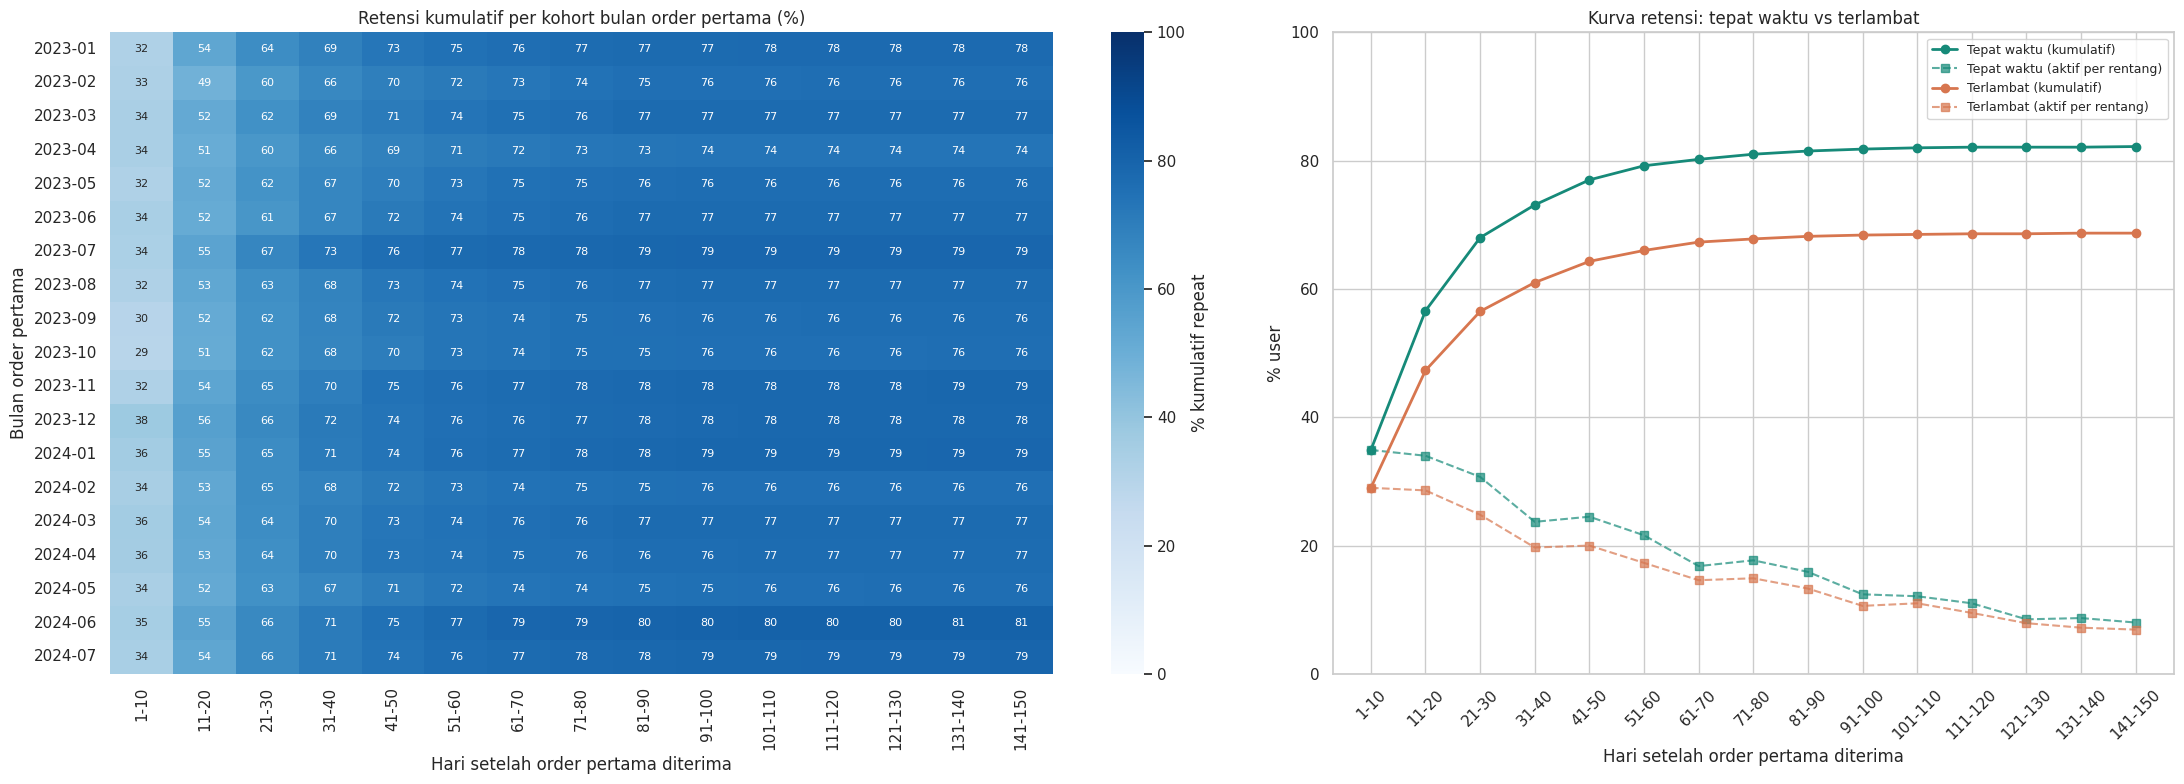

In [47]:
# Cohort analysis: repeat purchase per rentang 10 hari hingga 150 hari setelah order pertama diterima
STEP, MAX_DAY = 10, 150
bins = list(range(0, MAX_DAY + STEP, STEP))                       # 0, 10, ..., 150
labels = [f'{b + 1}-{b + STEP}' for b in bins[:-1]]               # '1-10', '11-20', ..., '141-150'

# Kohort: first order completed & delivered, dapat diamati penuh 150 hari (aturan 8)
coh = first_order.loc[first_order['order_status'].eq('completed') & first_order['late_delivery'].notna()].copy()
coh = coh.loc[coh['delivery_date'] <= END - pd.Timedelta(days=MAX_DAY)]
coh['cohort_month'] = coh['order_date'].dt.to_period('M')
coh['fulfillment'] = np.where(coh['late_delivery'].eq(1), 'Terlambat', 'Tepat waktu')

# Seluruh order completed berikutnya dalam 1-150 hari setelah barang pertama diterima
nxt = completed[['user_id', 'order_id', 'order_date']].merge(
    coh[['user_id', 'order_id', 'delivery_date', 'cohort_month', 'fulfillment']].rename(columns={'order_id': 'fo'}),
    on='user_id')
nxt['day'] = (nxt['order_date'] - nxt['delivery_date']).dt.days
nxt = nxt.loc[nxt['order_id'].ne(nxt['fo']) & nxt['day'].between(1, MAX_DAY)].copy()
nxt['period'] = pd.cut(nxt['day'], bins=bins, labels=labels)
coh['first_repeat_day'] = coh['user_id'].map(nxt.groupby('user_id')['day'].min())

def active_table(group_col):
    """% user kohort yang melakukan >= 1 order completed pada setiap rentang 10 hari."""
    size = coh.groupby(group_col).size()
    act = nxt.groupby([group_col, 'period'], observed=False)['user_id'].nunique().unstack()
    return act.div(size, axis=0).mul(100).round(1).assign(n_user=size)[['n_user'] + labels]

def cumulative_table(group_col):
    """% user kohort yang sudah melakukan repeat pertama hingga akhir setiap rentang (kumulatif)."""
    size = coh.groupby(group_col).size()
    out = pd.DataFrame({lab: coh.groupby(group_col)['first_repeat_day'].apply(lambda s, e=end: s.le(e).sum())
                        for lab, end in zip(labels, bins[1:])})
    return out.div(size, axis=0).mul(100).round(1).assign(n_user=size)[['n_user'] + labels]

MIN_COHORT = 100   # kohort bulanan dengan < 100 user (akhir periode) tidak ditampilkan pada tabel bulanan
active_month, cum_month = active_table('cohort_month'), cumulative_table('cohort_month')
small = cum_month.index[cum_month['n_user'] < MIN_COHORT]
active_month, cum_month = active_month.drop(small), cum_month.drop(small)
if len(small): print('Kohort bulanan tidak ditampilkan (< 100 user):', ', '.join(map(str, small)))
active_ful, cum_ful = active_table('fulfillment'), cumulative_table('fulfillment')

print(f'Kohort {MAX_DAY} hari: {len(coh):,} user | order pertama {coh["order_date"].min():%d %b %Y} - {coh["order_date"].max():%d %b %Y}')
print('\n1) % user aktif (>= 1 order completed) per rentang 10 hari - per bulan order pertama')
display(active_month)
print('\n2) Retensi kumulatif (% sudah repeat) hingga akhir rentang - per bulan order pertama')
display(cum_month)
print('\n3) Tepat waktu vs terlambat pada order pertama')
gap = (cum_ful.loc['Tepat waktu', labels] - cum_ful.loc['Terlambat', labels]).rename('Gap kumulatif (pp)')
display(pd.concat({'Aktif per rentang (%)': active_ful, 'Kumulatif (%)': cum_ful}))
display(gap.round(1).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(22, 8), gridspec_kw={'width_ratios': [1.4, 1]})
sns.heatmap(cum_month[labels].set_index(cum_month.index.astype(str)), annot=True, fmt='.0f', cmap='Blues',
            vmin=0, vmax=100, cbar_kws={'label': '% kumulatif repeat'}, annot_kws={'size': 8}, ax=axes[0])
axes[0].set_title('Retensi kumulatif per kohort bulan order pertama (%)')
axes[0].set_xlabel('Hari setelah order pertama diterima'); axes[0].set_ylabel('Bulan order pertama')
for name, color in [('Tepat waktu', TEAL), ('Terlambat', ORANGE)]:
    axes[1].plot(labels, cum_ful.loc[name, labels], marker='o', color=color, lw=2, label=f'{name} (kumulatif)')
    axes[1].plot(labels, active_ful.loc[name, labels], marker='s', ls='--', color=color, alpha=.7,
                 label=f'{name} (aktif per rentang)')
axes[1].set_ylim(0, 100); axes[1].set_ylabel('% user'); axes[1].set_xlabel('Hari setelah order pertama diterima')
axes[1].set_title('Kurva retensi: tepat waktu vs terlambat'); axes[1].legend(fontsize=9)
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Insight:**
- **Sebagian besar repeat terjadi di awal.** Pada 10 hari pertama, 29–38% pengguna (per kohort bulanan) sudah bertransaksi lagi; retensi kumulatif mencapai ±64% di hari ke-30 dan ±75% di hari ke-60. Setelah ±90 hari kurva mendatar (±77–78%), sehingga hampir tidak ada pengguna baru yang kembali setelahnya — sejalan dengan penentuan jendela churn 90 hari di atas.
- **Retensi antar kohort bulanan stabil.** Retensi kumulatif 150 hari berada di kisaran 73,8–80,6% tanpa tren menurun dari 2023 ke 2024. Kohort Januari 2023 (18.701 user) jauh lebih besar karena mencakup pengguna lama yang order pertamanya baru teramati di awal periode.
- **Gap akibat keterlambatan terbentuk di awal dan tidak menutup.** Retensi kumulatif tepat waktu vs terlambat: 34,9% vs 29,0% (hari 1–10, gap 5,9 pp), 68,0% vs 56,5% (hari 21–30, gap 11,5 pp), lalu stabil di ±13,5 pp hingga hari ke-150 (82,2% vs 68,7%). Pengguna yang mengalami keterlambatan tidak "menyusul" kembali di periode berikutnya, sehingga intervensi *service recovery* paling relevan dilakukan dalam 30 hari pertama.
- **Churn 90 hari adalah kebalikan dari retensi kumulatif di hari ke-90:** ±23%, konsisten dengan churn 23,0% pada pertanyaan 3. Churn antar kohort bulanan stabil di 20–27%.
- **Keterlambatan hampir menggandakan churn:** 31,8% bila order pertama terlambat vs 18,5% bila tepat waktu (retensi kumulatif hari ke-81–90: 68,2% vs 81,5%). Setelah hari ke-90 hampir tidak ada pengguna yang kembali (hanya 0,5–0,7 pp hingga hari ke-150), sehingga churn praktis terkunci. Penurunan tabel "aktif per rentang" (±33% → ±8%) bukan churn, karena pengguna yang sudah kembali tidak harus berbelanja di setiap rentang.

### <span style="color:darkorange"> 1. Apakah Efektivitas Promo dalam Mendorong Repeat Order Berbeda antar Kanal Akuisisi?</span>
Untuk tiap kanal, repeat 60 hari dibandingkan antara user yang memakai dan tidak memakai promo pada order pertama (uji dua proporsi, koreksi Holm untuk 4 kanal). Sebagai pembanding, ditampilkan juga gap repeat antara pengiriman tepat waktu dan terlambat pada kanal yang sama.

,Kanal,N user,Repeat promo,Repeat tanpa promo,Efek promo (pp),CI low,CI high,p promo,Gap tepat waktu - terlambat (pp),p late,p promo (Holm),p late (Holm)
3,referral,5884,0.7428,0.7323,1.0546,-1.2159,3.3459,0.3640,14.0250,0.0,1.0,0.0
1,affiliate,3910,0.7464,0.7449,0.1457,-2.6055,2.9318,0.9179,14.8552,0.0,1.0,0.0
0,ads,11999,0.7571,0.7586,-0.1476,-1.6945,1.4109,0.8522,10.8175,0.0,1.0,0.0
2,organic,17570,0.7426,0.7444,-0.1788,-1.4840,1.1340,0.7890,13.9204,0.0,1.0,0.0


Keseluruhan: promo 74.74% vs tanpa promo 74.70%; selisih +0.04 pp (95% CI -0.82 s.d. +0.92); p = 0.921


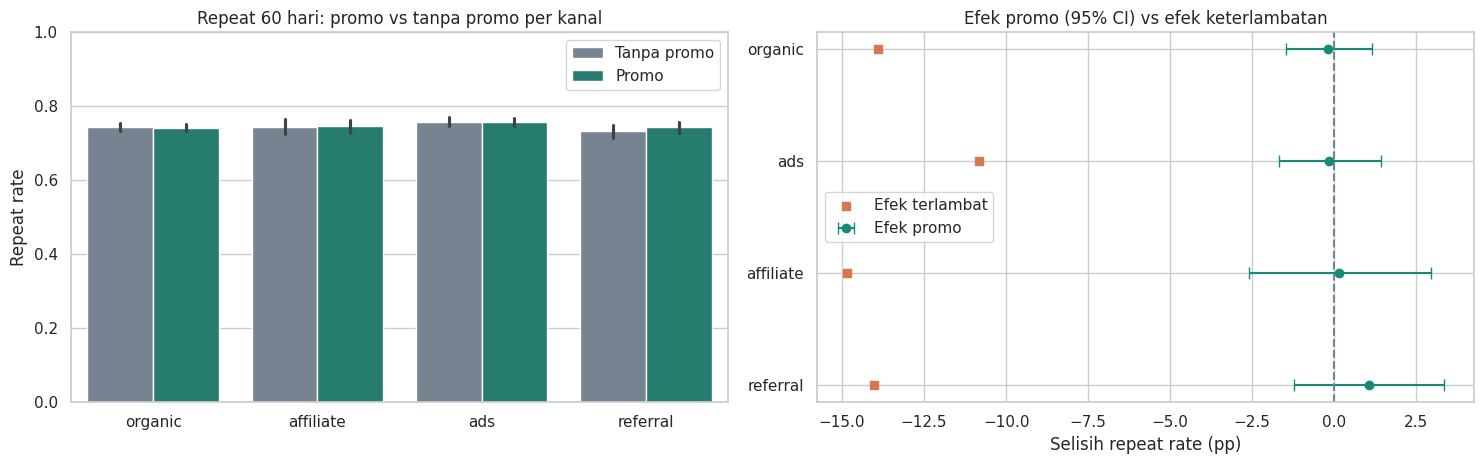

In [48]:
c = cohort60.copy()
overall = c.groupby('promo_first')['repeat'].agg(['sum', 'size'])
t_all = two_prop(overall.loc[1, 'sum'], overall.loc[1, 'size'], overall.loc[0, 'sum'], overall.loc[0, 'size'])

rows = []
for ch, g in c.groupby('acquisition_channel'):
    a = g.groupby('promo_first')['repeat'].agg(['sum', 'size'])
    t = two_prop(a.loc[1, 'sum'], a.loc[1, 'size'], a.loc[0, 'sum'], a.loc[0, 'size'])
    l = g.groupby('late_delivery')['repeat'].agg(['sum', 'size'])
    tl = two_prop(l.loc[0, 'sum'], l.loc[0, 'size'], l.loc[1, 'sum'], l.loc[1, 'size'])
    rows.append({'Kanal': ch, 'N user': len(g), 'Repeat promo': t['p_a'], 'Repeat tanpa promo': t['p_b'],
                 'Efek promo (pp)': t['diff'] * 100, 'CI low': t['low'] * 100, 'CI high': t['high'] * 100,
                 'p promo': t['p'], 'Gap tepat waktu - terlambat (pp)': tl['diff'] * 100, 'p late': tl['p']})
q1 = pd.DataFrame(rows)
q1['p promo (Holm)'] = holm(q1['p promo'])
q1['p late (Holm)'] = holm(q1['p late'])
q1 = q1.sort_values('Efek promo (pp)', ascending=False)
display(q1.round(4))
print(f"Keseluruhan: promo {pct(t_all['p_a'],2)} vs tanpa promo {pct(t_all['p_b'],2)}; "
      f"selisih {t_all['diff']*100:+.2f} pp (95% CI {t_all['low']*100:+.2f} s.d. {t_all['high']*100:+.2f}); p = {t_all['p']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot = c.assign(Promo=np.where(c['promo_first'].eq(1), 'Promo', 'Tanpa promo'))
sns.barplot(data=plot, x='acquisition_channel', y='repeat', hue='Promo', hue_order=['Tanpa promo', 'Promo'],
            palette=[GRAY, TEAL], errorbar=('ci', 95), ax=axes[0])
axes[0].set_ylim(0, 1); axes[0].set_title('Repeat 60 hari: promo vs tanpa promo per kanal')
axes[0].set_xlabel(''); axes[0].set_ylabel('Repeat rate'); axes[0].legend(title='')
y = np.arange(len(q1))
axes[1].errorbar(q1['Efek promo (pp)'], y, xerr=[q1['Efek promo (pp)'] - q1['CI low'], q1['CI high'] - q1['Efek promo (pp)']],
                 fmt='o', color=TEAL, capsize=4, label='Efek promo')
axes[1].scatter(-q1['Gap tepat waktu - terlambat (pp)'], y, color=ORANGE, marker='s', label='Efek terlambat')
axes[1].axvline(0, color=GRAY, ls='--'); axes[1].set_yticks(y, q1['Kanal'])
axes[1].set_xlabel('Selisih repeat rate (pp)'); axes[1].set_title('Efek promo (95% CI) vs efek keterlambatan')
axes[1].legend()
plt.tight_layout(); plt.show()

**Insight:**
- **Efektivitas promo tidak berbeda antar kanal.** Selisih repeat promo vs tanpa promo hanya −0,18 s.d. +1,02 pp di keempat kanal (referral +1,02; affiliate +0,13; ads −0,15; organic −0,18), dan tidak ada yang signifikan (p Holm = 1,0). Seluruh interval kepercayaan melintasi nol.
- **Keterlambatan berdampak jauh lebih besar di semua kanal:** gap repeat tepat waktu vs terlambat 10,8–14,8 pp dan signifikan di keempat kanal (p Holm < 0,001). Gap terbesar ada pada affiliate (14,8 pp), referral (14,0 pp), dan organic (13,9 pp).
- Implikasi: di data ini, promo pada order pertama tidak tampak menjadi pembeda retensi untuk kanal mana pun, sedangkan pengalaman pengiriman konsisten berkaitan dengan retensi lintas kanal.

### <span style="color:darkorange"> 2. Segmen User Mana yang Paling Banyak Menyerap Budget Promo namun Kontribusinya Paling Rendah?</span>
Kontribusi diukur dari porsi GMV (`total_amount` order completed) dan repeat 60 hari. **Indeks efisiensi = porsi GMV ÷ porsi promo**; nilai < 1 berarti segmen menyerap promo lebih besar daripada kontribusi GMV-nya.

,Dimensi,Rentang promo/GMV (%),Segmen indeks terendah,Indeks terendah
0,acquisition_channel,4.19 – 4.62,referral,0.96
1,device_type,4.40 – 4.59,iOS,0.97
2,age_band,4.37 – 4.86,65+,0.92
3,gender,4.45 – 4.48,Female,0.99
4,location,4.18 – 4.79,Semarang,0.93
5,product_category,1.11 – 11.80,grocery,0.38
6,voucher_type,6.65 – 8.40,diskon_persen,0.53


Segmen kategori produk (kategori order):


,user,order,promo,gmv,porsi_promo_%,porsi_gmv_%,promo_per_gmv_%,indeks_efisiensi,repeat_60d
product_category,,,,,,,,,
grocery,26168,44721,2403457996,20364188430,18.822,7.1,11.802,0.377,0.749
kesehatan,20765,30658,1725948249,15582625710,13.516,5.433,11.076,0.402,0.746
fashion,30603,58872,3232965514,33331321725,25.318,11.62,9.699,0.459,0.748
lainnya,17258,23779,1261223724,14558040074,9.877,5.075,8.663,0.514,0.738
olahraga,14505,18844,1050569026,15646511183,8.227,5.455,6.714,0.663,0.742
perabotan,18706,26770,1469618706,41050435722,11.509,14.311,3.58,1.244,0.756
elektronik,21047,31362,1625648786,146304839735,12.731,51.006,1.111,4.007,0.747


Segmen user menurut kategori order pertama:


,user,promo,gmv,porsi_promo_%,porsi_gmv_%,indeks_efisiensi,promo_per_user,gmv_per_user,repeat_60d
kategori_order_pertama,,,,,,,,,
kesehatan,5213,1391267809,27062071016,13.387,11.642,0.87,266884.291,5191266.261,0.746
grocery,7495,1977424861,38810194420,19.027,16.695,0.877,263832.536,5178144.686,0.749
lainnya,3959,1059552458,20864124327,10.195,8.975,0.88,267631.336,5270049.085,0.738
fashion,9808,2520711852,51073869187,24.255,21.971,0.906,257005.695,5207368.392,0.748
olahraga,3107,810856056,16902631334,7.802,7.271,0.932,260977.166,5440177.449,0.742
perabotan,4486,1201634940,28775033180,11.562,12.378,1.071,267863.339,6414407.753,0.756
elektronik,5295,1431226512,48973098279,13.771,21.067,1.53,270297.736,9248932.631,0.747


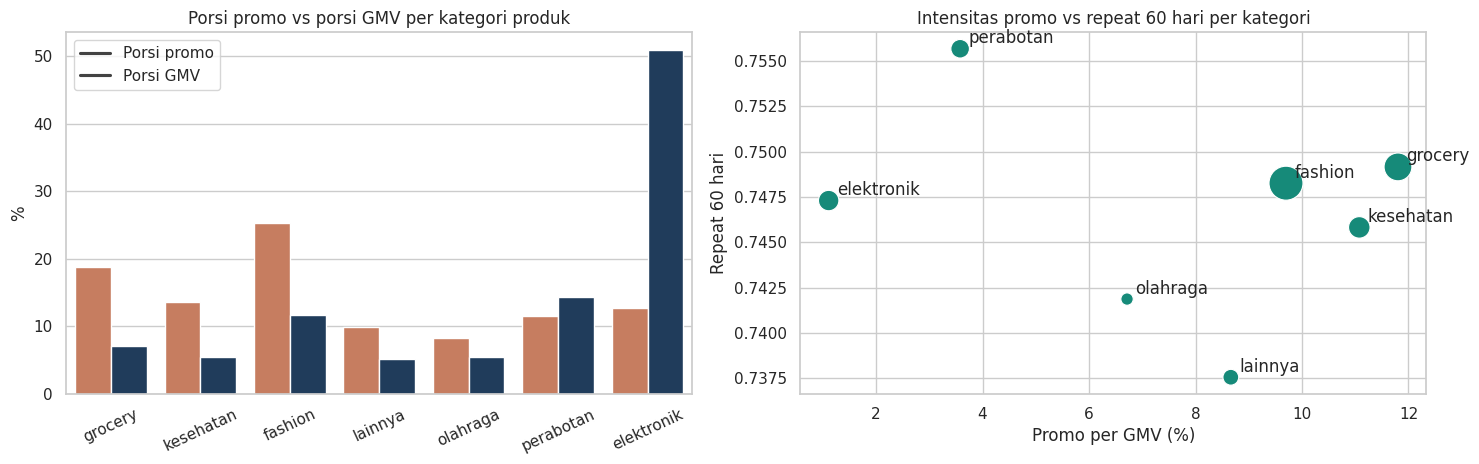

In [49]:
comp = completed.copy()
comp['age_band'] = pd.cut(comp['age'], [0, 24, 34, 44, 54, 64, 120], labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])
total_promo, total_gmv = comp['promo_amount'].sum(), comp['total_amount'].sum()

def segment_table(dim, cohort_dim=None):
    g = comp.groupby(dim, observed=True).agg(user=('user_id', 'nunique'), order=('order_id', 'size'),
                                             promo=('promo_amount', 'sum'), gmv=('total_amount', 'sum'))
    g['porsi_promo_%'] = g['promo'] / total_promo * 100
    g['porsi_gmv_%'] = g['gmv'] / total_gmv * 100
    g['promo_per_gmv_%'] = g['promo'] / g['gmv'] * 100
    g['indeks_efisiensi'] = g['porsi_gmv_%'] / g['porsi_promo_%']        # < 1: menyerap promo > kontribusi GMV
    r = cohort60.groupby(cohort_dim or dim, observed=True)['repeat'].mean().rename('repeat_60d')
    return g.join(r).sort_values('indeks_efisiensi')

c60 = cohort60.copy()
c60['age_band'] = pd.cut(c60['age'], [0, 24, 34, 44, 54, 64, 120], labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])
cohort60 = c60
summary = []
for dim in ['acquisition_channel', 'device_type', 'age_band', 'gender', 'location', 'product_category', 'voucher_type']:
    t = segment_table(dim)
    summary.append({'Dimensi': dim, 'Rentang promo/GMV (%)': f"{t['promo_per_gmv_%'].min():.2f} – {t['promo_per_gmv_%'].max():.2f}",
                    'Segmen indeks terendah': t.index[0], 'Indeks terendah': round(t['indeks_efisiensi'].iloc[0], 2)})
display(pd.DataFrame(summary))

print('Segmen kategori produk (kategori order):')
q2_cat = segment_table('product_category')
display(q2_cat.round(3))

# Segmen user (kohort 60 hari) berdasarkan kategori yang dibeli pada order pertama:
# seluruh order completed user tersebut selama periode, dibandingkan dengan repeat 60 hari
first_cat = cohort60.set_index('user_id')['product_category']
cu = comp.loc[comp['user_id'].isin(first_cat.index)].assign(kategori_order_pertama=lambda d: d['user_id'].map(first_cat))
q2_user = cu.groupby('kategori_order_pertama').agg(user=('user_id', 'nunique'), promo=('promo_amount', 'sum'),
                                                    gmv=('total_amount', 'sum'))
q2_user['porsi_promo_%'] = q2_user['promo'] / q2_user['promo'].sum() * 100
q2_user['porsi_gmv_%'] = q2_user['gmv'] / q2_user['gmv'].sum() * 100
q2_user['indeks_efisiensi'] = q2_user['porsi_gmv_%'] / q2_user['porsi_promo_%']
q2_user['promo_per_user'] = q2_user['promo'] / q2_user['user']
q2_user['gmv_per_user'] = q2_user['gmv'] / q2_user['user']
q2_user = q2_user.join(cohort60.groupby('product_category')['repeat'].mean().rename('repeat_60d')).sort_values('indeks_efisiensi')
print('Segmen user menurut kategori order pertama:')
display(q2_user.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot = q2_cat.reset_index().melt(id_vars='product_category', value_vars=['porsi_promo_%', 'porsi_gmv_%'])
sns.barplot(data=plot, x='product_category', y='value', hue='variable', palette=[ORANGE, PRIMARY], ax=axes[0])
axes[0].set_title('Porsi promo vs porsi GMV per kategori produk'); axes[0].set_ylabel('%'); axes[0].set_xlabel('')
axes[0].legend(title='', labels=['Porsi promo', 'Porsi GMV']); axes[0].tick_params(axis='x', rotation=25)
sns.scatterplot(data=q2_cat.reset_index(), x='promo_per_gmv_%', y='repeat_60d', size='porsi_promo_%',
                sizes=(80, 600), color=TEAL, legend=False, ax=axes[1])
for _, r in q2_cat.reset_index().iterrows():
    axes[1].annotate(r['product_category'], (r['promo_per_gmv_%'], r['repeat_60d']), xytext=(6, 4), textcoords='offset points')
axes[1].set_title('Intensitas promo vs repeat 60 hari per kategori')
axes[1].set_xlabel('Promo per GMV (%)'); axes[1].set_ylabel('Repeat 60 hari')
plt.tight_layout(); plt.show()

**Insight:**
- **Segmen demografis dan kanal relatif seimbang.** Pada kanal akuisisi, perangkat, usia, gender, dan kota, rasio promo/GMV hanya berkisar 4,2–4,9% (indeks 0,92–0,99). Tidak ada segmen pengguna yang menonjol menyerap promo jauh di atas kontribusinya.
- **Sekilas, kategori produk tampak menjadi pembeda:** order grocery, kesehatan, dan fashion menyerap 57,7% promo tetapi hanya 24,2% GMV (promo/GMV 9,7–11,8%), sedangkan elektronik menyerap 12,7% promo dan menyumbang 51,0% GMV.
- **Namun pola kategori ini digerakkan oleh transaksi dengan promo melebihi nilai belanja** (bagian 2.1). Setelah transaksi tersebut dikeluarkan, rasio promo/GMV semua kategori nyaris sama (2,50–2,75%), kecuali elektronik (1,08%) yang nilai belanjanya jauh lebih besar. Repeat 60 hari per kategori juga hampir sama (73,8–75,6%).
- **Jawaban:** tidak ada segmen pengguna (kanal, demografi, maupun kategori) yang secara struktural menyerap promo jauh di atas kontribusinya. Yang menyerap promo secara tidak proporsional adalah **sekelompok kecil transaksi dengan promo melebihi nilai belanja: 4,4% order completed yang menyerap 59% anggaran promo**, tanpa retensi yang lebih baik.

### <span style="color:darkorange"> 2.1 Investigasi Transaksi dengan Promo Melebihi Nilai Belanja</span>
Transaksi dengan `promo_amount` > `total_amount` dipertahankan pada tahap cleansing (aturan 4) karena definisi nominalnya belum terkonfirmasi. Bagian ini mengukur besarnya, menguji apakah `total_amount` mungkin sudah merupakan nilai setelah dikurangi promo, dan membandingkan pengeluaran promo dengan GMV yang dihasilkan. Pendapatan platform tidak dihitung karena take rate tidak tersedia di dataset maupun brief.

Seluruh transaksi (user_in_master): 11,667 dari 267,677 (4.36%) | per status: {'completed': 10299, 'refund': 623, 'returned': 447, 'cancelled': 298}

1) Order completed menurut kelompok promo


,order,% order,% promo,median_promo,median_belanja,median promo / median belanja,promo per tahun,GMV per tahun
grup_promo,,,,,,,,
promo > belanja,10299,4.38,59.04,750647.0,235980.0,3.18,3772426767.9,1438228163.03
promo normal,126256,53.72,40.96,17316.0,373085.0,0.05,2616662325.75,81474962226.869995
tanpa promo,98451,41.89,0.0,0.0,357190.0,0.0,0.0,60604023078.57


Total promo per tahun Rp6.389.089.094 vs GMV completed per tahun Rp143.517.213.468 (promo/GMV 4.45%)

2) Sebaran nominal promo per kelompok


grup_promo,promo > belanja,promo normal
promo_amount,,
<=100rb,366,122474
400-600rb,1861,966
600-800rb,3890,1561
800rb-1jt,4182,1255



3a) Median total_amount per kategori & jenis voucher (tanpa kelompok promo > belanja)


voucher,cashback,diskon_persen,free_ongkir,tanpa voucher
product_category,,,,
elektronik,3380927.0,3391250.0,3355259.0,3355051.0
fashion,284361.0,282110.0,280738.0,276621.0
grocery,185060.0,191524.0,190166.0,185065.0
kesehatan,227990.0,237592.0,231058.0,236703.0
lainnya,318230.0,305516.0,308135.0,309459.0
olahraga,475551.0,478204.0,482097.0,466153.0
perabotan,1054748.0,1028162.0,1040298.0,1005058.0


... (3 outputs left out)

,Semua order,Tanpa promo > belanja
product_category,,
elektronik,1.11,1.08
fashion,9.70,2.70
grocery,11.80,2.73
kesehatan,11.08,2.75
lainnya,8.66,2.73
olahraga,6.71,2.64
perabotan,3.58,2.50



5) Repeat 60 hari menurut kelompok promo order pertama


,repeat,user,repeat_rate
grup_promo,,,
promo > belanja,1336,1758,0.7600
promo normal,15784,21147,0.7464
tanpa promo,12294,16458,0.7470


promo > belanja vs promo normal: +1.36 pp; p = 0.209


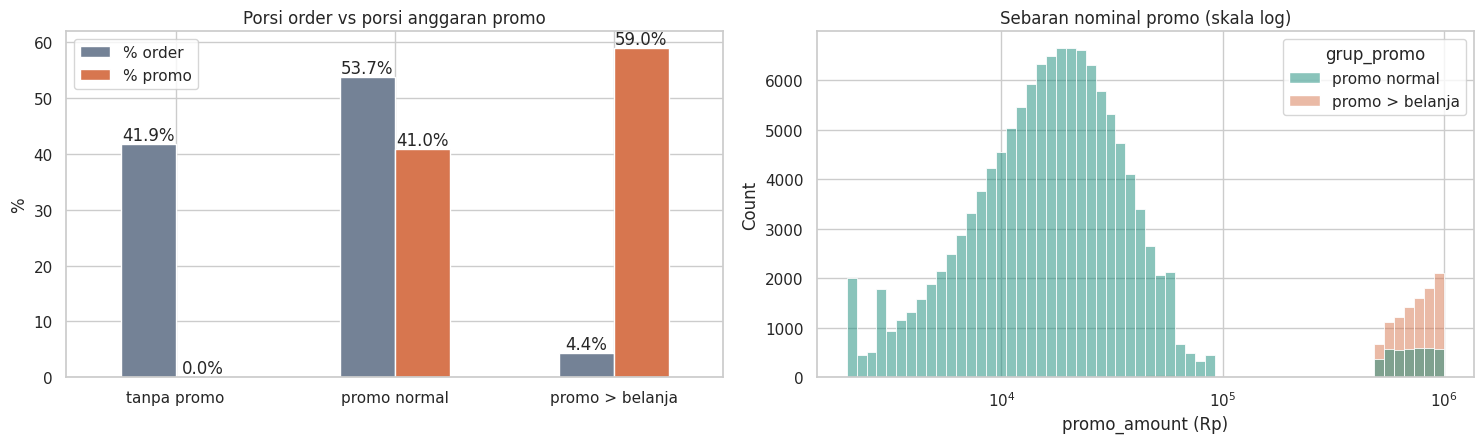

In [50]:
# Investigasi transaksi dengan promo_amount > total_amount (aturan 4: masih termasuk di data)
YEARS = (END - om['order_date'].min()).days / 365.25

allo = base.copy()
allo['promo_gt_belanja'] = allo['total_amount'].gt(0) & allo['promo_amount'].gt(allo['total_amount'])
print(f"Seluruh transaksi (user_in_master): {allo['promo_gt_belanja'].sum():,} dari {len(allo):,} "
      f"({pct(allo['promo_gt_belanja'].mean(), 2)}) | per status: {allo.loc[allo['promo_gt_belanja'], 'order_status'].value_counts().to_dict()}")

pc = completed.loc[completed['total_amount'].gt(0)].copy()
pc['grup_promo'] = np.select([pc['promo_amount'].gt(pc['total_amount']), pc['promo_amount'].gt(0)],
                             ['promo > belanja', 'promo normal'], 'tanpa promo')
g = pc.groupby('grup_promo').agg(order=('order_id', 'size'), promo=('promo_amount', 'sum'), gmv=('total_amount', 'sum'),
                                 median_promo=('promo_amount', 'median'), median_belanja=('total_amount', 'median'))
g['% order'] = g['order'] / g['order'].sum() * 100
g['% promo'] = g['promo'] / g['promo'].sum() * 100
g['promo per tahun'] = g['promo'] / YEARS
g['GMV per tahun'] = g['gmv'] / YEARS
g['median promo / median belanja'] = g['median_promo'] / g['median_belanja']
print('\n1) Order completed menurut kelompok promo')
display(g[['order', '% order', '% promo', 'median_promo', 'median_belanja', 'median promo / median belanja',
           'promo per tahun', 'GMV per tahun']].round(2))
tot_promo, tot_gmv = pc['promo_amount'].sum() / YEARS, pc['total_amount'].sum() / YEARS
print(f'Total promo per tahun {rp(tot_promo)} vs GMV completed per tahun {rp(tot_gmv)} (promo/GMV {pct(tot_promo / tot_gmv, 2)})')

# 2) Sebaran nominal promo: kelompok promo > belanja membentuk populasi terpisah
promo_bins = [0, 1e5, 2e5, 4e5, 6e5, 8e5, 1e6 + 1]
bin_labels = ['<=100rb', '100-200rb', '200-400rb', '400-600rb', '600-800rb', '800rb-1jt']
print('\n2) Sebaran nominal promo per kelompok')
display(pd.crosstab(pd.cut(pc.loc[pc['promo_amount'].gt(0), 'promo_amount'], promo_bins, labels=bin_labels),
                    pc.loc[pc['promo_amount'].gt(0), 'grup_promo']))

# 3) Uji hipotesis: apakah total_amount sudah dikurangi promo (nilai net)?
normal = pc.loc[pc['grup_promo'].ne('promo > belanja')].assign(voucher=lambda d: d['voucher_type'].fillna('tanpa voucher'))
print('\n3a) Median total_amount per kategori & jenis voucher (tanpa kelompok promo > belanja)')
display(normal.pivot_table(index='product_category', columns='voucher', values='total_amount', aggfunc='median').round(0))
pc['nilai_per_item'] = pc['total_amount'] / pc['item_quantity']
pc['nilai_per_item_bila_net'] = (pc['total_amount'] + pc['promo_amount']) / pc['item_quantity']
print('3b) Median nilai per item: apa adanya vs bila total_amount dianggap sudah dikurangi promo')
display(pc.groupby('grup_promo')[['nilai_per_item', 'nilai_per_item_bila_net']].median().round(0))

# 4) Rasio promo/GMV per kategori dengan dan tanpa kelompok promo > belanja
cat = pd.concat({'Semua order': pc.groupby('product_category').apply(lambda d: d['promo_amount'].sum() / d['total_amount'].sum() * 100),
                 'Tanpa promo > belanja': pc.loc[pc['grup_promo'].ne('promo > belanja')].groupby('product_category')
                     .apply(lambda d: d['promo_amount'].sum() / d['total_amount'].sum() * 100)}, axis=1)
print('\n4) Promo per GMV (%) per kategori')
display(cat.round(2))

# 5) Retensi: repeat 60 hari menurut kelompok promo pada order pertama
c60 = cohort60.copy()
c60['grup_promo'] = np.select([c60['total_amount'].gt(0) & c60['promo_amount'].gt(c60['total_amount']), c60['promo_amount'].gt(0)],
                              ['promo > belanja', 'promo normal'], 'tanpa promo')
rr = c60.groupby('grup_promo')['repeat'].agg(['sum', 'size', 'mean'])
t = two_prop(rr.loc['promo > belanja', 'sum'], rr.loc['promo > belanja', 'size'], rr.loc['promo normal', 'sum'], rr.loc['promo normal', 'size'])
print('\n5) Repeat 60 hari menurut kelompok promo order pertama')
display(rr.rename(columns={'sum': 'repeat', 'size': 'user', 'mean': 'repeat_rate'}).round(4))
print(f"promo > belanja vs promo normal: {t['diff']*100:+.2f} pp; p = {t['p']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
share = g[['% order', '% promo']].reindex(['tanpa promo', 'promo normal', 'promo > belanja'])
share.plot(kind='bar', color=[GRAY, ORANGE], rot=0, ax=axes[0])
for cont in axes[0].containers: axes[0].bar_label(cont, fmt='%.1f%%')
axes[0].set_title('Porsi order vs porsi anggaran promo'); axes[0].set_ylabel('%'); axes[0].set_xlabel('')
sns.histplot(data=pc.loc[pc['promo_amount'].gt(0)], x='promo_amount', hue='grup_promo', bins=60, log_scale=True,
             palette={'promo normal': TEAL, 'promo > belanja': ORANGE}, ax=axes[1])
axes[1].set_title('Sebaran nominal promo (skala log)'); axes[1].set_xlabel('promo_amount (Rp)')
plt.tight_layout(); plt.show()

**Insight:**
- **Jumlah:** 11.667 transaksi (4,36% dari 267.677 transaksi pengguna terdaftar), terdiri dari 10.299 completed, 623 refund, 447 returned, dan 298 cancelled. Pada order completed, jumlahnya **4,38%** dari 235.006 order, atau 7,5% dari order yang memakai promo.
- **Menyerap 59,0% anggaran promo** (±Rp3,77 miliar per tahun). Median promo **Rp750.647**, sedangkan median belanjanya **Rp235.980** (promo ±3,2× nilai belanja). Kelompok ini hanya menghasilkan GMV ±Rp1,44 miliar per tahun, lebih kecil dari promo yang diterimanya (promo ±2,6× GMV).
- **Total promo ±Rp6,39 miliar per tahun, setara 4,45% dari GMV completed (±Rp143,5 miliar per tahun).** Tanpa kelompok ini, promo turun menjadi ±Rp2,62 miliar per tahun.
- **Apakah `total_amount` sudah dikurangi promo? Data tidak mendukung kemungkinan ini:**
  1. Pada order lain, median `total_amount` per kategori hampir sama antara order bervoucher dan tanpa voucher (mis. grocery Rp185–192 ribu untuk semua jenis voucher maupun tanpa voucher). Jika promo mengurangi `total_amount`, order bervoucher seharusnya lebih rendah.
  2. Jika `total_amount` dianggap sudah dikurangi promo, nilai per item kelompok ini menjadi **Rp496.749**, ±2,6–2,9× kelompok lain (Rp173–195 ribu), dengan diskon rata-rata sekitar 76% — tidak wajar.
  3. Nominal promonya membentuk populasi terpisah: 96% berada di rentang Rp400 ribu–Rp1 juta dan tidak ada yang berada di rentang Rp100–400 ribu, sedangkan 97% promo pada order lain ≤ Rp100 ribu.
- **Tidak ada manfaat retensi:** pengguna yang order pertamanya termasuk kelompok ini kembali dalam 60 hari sebanyak 76,0% vs 74,6% pada promo normal (p = 0,209).
- **Interpretasi:** pola ini lebih konsisten dengan promo yang tidak wajar (salah input, promo bertumpuk, atau penyalahgunaan voucher) daripada dengan perbedaan definisi nominal. Ini sejalan dengan catatan brief tentang nilai nominal yang tidak wajar, dan menjadi dasar rekomendasi pembatasan promo serta audit.

### <span style="color:darkorange"> 3. Apakah Pola Penggunaan Promo pada User Churn Berbeda dari User yang Bertahan?</span>
Churn = tidak ada order completed dalam 90 hari setelah order pertama diterima. Karakteristik order pertama dibandingkan antara user churn dan bertahan.

Kohort 90 hari: 38,276 user | churn 23.0% | bertahan 77.0%


,Indikator order pertama,Churn,Bertahan,Selisih,p-value,Uji
0,Memakai promo,58.2%,58.1%,+0.08 pp,0.888,Uji dua proporsi
1,Order saat kampanye,27.5%,25.0%,+2.55 pp,1.49e-06,Uji dua proporsi
2,Pengiriman terlambat,47.6%,30.6%,+17.01 pp,1.15e-190,Uji dua proporsi
3,Nominal promo (median),Rp6.773,Rp6.707,-,0.84,Mann-Whitney U
4,Rasio promo/total (median),0.008,0.008,-,0.777,Mann-Whitney U
5,Nilai order pertama (median),Rp355.883,Rp358.076,-,0.543,Mann-Whitney U


status,Bertahan,Churn
voucher,,
cashback,17.66,18.40
diskon_persen,17.27,17.07
free_ongkir,23.21,22.76
tanpa_voucher,41.85,41.77


Chi-square jenis voucher vs status: p = 0.408


,user,repeat_90d
voucher,,
cashback,6824,0.7627
diskon_persen,6594,0.7722
free_ongkir,8845,0.7737
tanpa_voucher,16013,0.7705


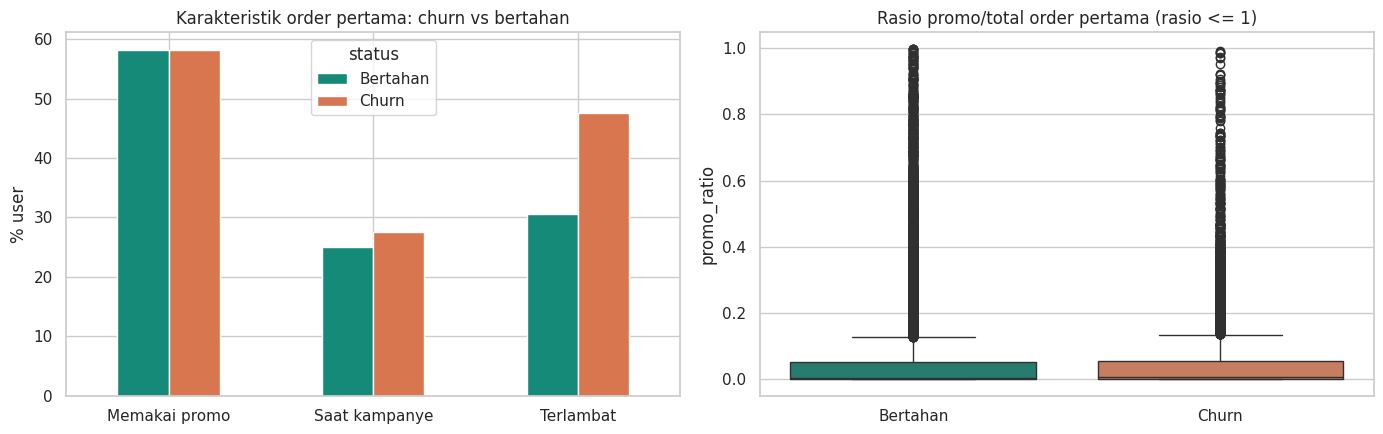

In [51]:
# Churn = tidak ada order completed dalam 90 hari setelah order pertama diterima (kohort 90 hari, aturan 8)
c = cohort90.copy()
c['status'] = np.where(c['repeat'].eq(1), 'Bertahan', 'Churn')
c['promo_ratio'] = np.where(c['total_amount'] > 0, c['promo_amount'] / c['total_amount'], np.nan)
churn, kept = c.loc[c['status'].eq('Churn')], c.loc[c['status'].eq('Bertahan')]

rows = []
for col, label in [('promo_first', 'Memakai promo'), ('campaign_first', 'Order saat kampanye'), ('late_delivery', 'Pengiriman terlambat')]:
    t = two_prop(churn[col].sum(), len(churn), kept[col].sum(), len(kept))
    rows.append([label, pct(t['p_a']), pct(t['p_b']), f"{t['diff']*100:+.2f} pp", f"{t['p']:.3g}", 'Uji dua proporsi'])
for col, label in [('promo_amount', 'Nominal promo (median)'), ('promo_ratio', 'Rasio promo/total (median)'),
                   ('total_amount', 'Nilai order pertama (median)')]:
    a, b = churn[col].dropna(), kept[col].dropna()
    u = stats.mannwhitneyu(a, b)
    fmt = (lambda v: f'{v:.3f}') if col == 'promo_ratio' else rp
    rows.append([label, fmt(a.median()), fmt(b.median()), '-', f'{u.pvalue:.3g}', 'Mann-Whitney U'])
q3 = pd.DataFrame(rows, columns=['Indikator order pertama', 'Churn', 'Bertahan', 'Selisih', 'p-value', 'Uji'])
print(f"Kohort 90 hari: {len(c):,} user | churn {pct(len(churn)/len(c))} | bertahan {pct(len(kept)/len(c))}")
display(q3)

vt = pd.crosstab(c['voucher'], c['status'])
chi = stats.chi2_contingency(vt)
display((pd.crosstab(c['voucher'], c['status'], normalize='columns') * 100).round(2))
print(f'Chi-square jenis voucher vs status: p = {chi.pvalue:.3f}')
display(c.groupby('voucher')['repeat'].agg(['size', 'mean']).rename(columns={'size': 'user', 'mean': 'repeat_90d'}).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
share = c.groupby('status')[['promo_first', 'campaign_first', 'late_delivery']].mean().T * 100
share.index = ['Memakai promo', 'Saat kampanye', 'Terlambat']
share[['Bertahan', 'Churn']].plot(kind='bar', color=[TEAL, ORANGE], ax=axes[0], rot=0)
axes[0].set_title('Karakteristik order pertama: churn vs bertahan'); axes[0].set_ylabel('% user')
sns.boxplot(data=c.loc[c['promo_ratio'].le(1)], x='status', y='promo_ratio', order=['Bertahan', 'Churn'],
            hue='status', palette=[TEAL, ORANGE], legend=False, ax=axes[1])
axes[1].set_title('Rasio promo/total order pertama (rasio <= 1)'); axes[1].set_xlabel('')
plt.tight_layout(); plt.show()

**Insight:**
- Pada kohort 90 hari (38.276 user), **23,0% churn**.
- **Pola promo tidak berbeda:** pemakaian promo (58,2% vs 58,1%; p = 0,888), median nominal promo (Rp6.773 vs Rp6.707; p = 0,84), rasio promo/total (p = 0,777), maupun jenis voucher (p = 0,408) sama antara user churn dan bertahan. Repeat 90 hari per jenis voucher juga hampir sama (76,3–77,4%).
- **Yang berbeda adalah pengalaman pengiriman:** **47,6% user churn mengalami keterlambatan** pada order pertama, dibanding 30,6% user bertahan (+17,0 pp; p < 0,001).
- User churn sedikit lebih banyak memulai di periode kampanye (27,5% vs 25,0%; p < 0,001), sedangkan nilai order pertama tidak berbeda.

### <span style="color:darkorange"> 4. Faktor Lain di Luar Promo yang Berkaitan dengan Keputusan Bertransaksi Kembali</span>
Faktor dibandingkan secara univariat (chi-square). Ketahanan gap keterlambatan lalu diuji dengan **stratifikasi**: pengguna terlambat dibandingkan dengan pengguna tepat waktu di dalam segmen yang sama (zona, kategori, kanal, perangkat, kampanye, promo, nilai order, official store, tahun), lalu selisihnya digabung dengan bobot Mantel-Haenszel. Pendekatan ini tidak memakai model prediktif. Status pengiriman non-delivered dianalisis terpisah, dan keluhan dianalisis dengan desain *landmark* 7 hari agar tiket yang muncul setelah repeat tidak ikut dihitung.

,Faktor,Repeat terendah,Repeat tertinggi,Rentang (pp),p (chi-square)
0,hari_lewat_sla,>5 (22.6%),0 (tepat) (79.2%),56.60,0.000000e+00
1,shipping_zone,luar_pulau (65.7%),dalam_kota (77.4%),11.75,8.570122e-70
8,payment_channel_provider,DANA (73.7%),Credit Card (76.2%),2.48,1.962286e-01
4,campaign_first,1 (73.1%),0 (75.3%),2.19,1.170377e-05
6,acquisition_channel,referral (73.8%),ads (75.8%),1.93,1.262695e-02
3,product_category,lainnya (73.8%),perabotan (75.6%),1.81,6.242131e-01
7,device_type,Android (74.4%),Web (76.0%),1.69,2.801078e-02
2,nilai_order,Q2 (74.4%),Q3 (75.1%),0.64,7.194644e-01
5,official,official (74.3%),non-official (74.8%),0.42,6.075509e-01


,size,mean
hari_lewat_sla,,
0 (tepat),25767,0.7925
1-2,11259,0.7444
3-5,231,0.5887
>5,2106,0.2265


,user,repeat_60d_sejak_order
status_kirim,,
delivered - tepat waktu,25850,0.8155
delivered - terlambat,13705,0.7025
failed,1965,0.2712
in_transit,852,0.7840
returned,1171,0.7617


,size,mean
keluhan_7_hari,,
keterlambatan,1332,0.1787
lainnya,285,0.6772
produk_rusak,595,0.6807
refund,466,0.6867
tidak ada tiket,26964,0.6906
kurir_kasar,283,0.6996


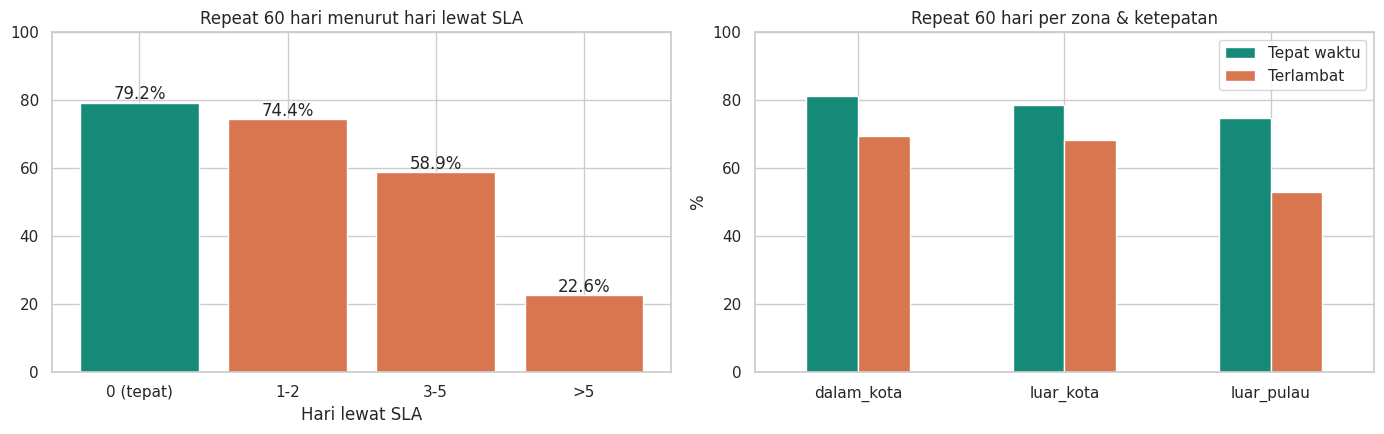

In [52]:
c = cohort60.copy()
c['hari_lewat_sla'] = pd.cut(c['days_over_sla'], [-1, 0, 2, 5, 100], labels=['0 (tepat)', '1-2', '3-5', '>5'])
c['nilai_order'] = pd.qcut(c['total_amount'], 4, labels=['Q1 rendah', 'Q2', 'Q3', 'Q4 tinggi'])
c['official'] = np.where(c['is_official_store'], 'official', 'non-official')
factors = ['hari_lewat_sla', 'shipping_zone', 'nilai_order', 'product_category', 'campaign_first', 'official',
           'acquisition_channel', 'device_type', 'payment_channel_provider']
rows = []
for f in factors:
    g = c.groupby(f, observed=True)['repeat'].agg(['size', 'mean'])
    chi = stats.chi2_contingency(pd.crosstab(c[f], c['repeat']))
    rows.append({'Faktor': f, 'Repeat terendah': f"{g['mean'].idxmin()} ({pct(g['mean'].min())})",
                 'Repeat tertinggi': f"{g['mean'].idxmax()} ({pct(g['mean'].max())})",
                 'Rentang (pp)': round((g['mean'].max() - g['mean'].min()) * 100, 2), 'p (chi-square)': chi.pvalue})
q4_uni = pd.DataFrame(rows).sort_values('Rentang (pp)', ascending=False)
display(q4_uni)
display(c.groupby('hari_lewat_sla', observed=True)['repeat'].agg(['size', 'mean']).round(4))

# Status pengiriman order pertama (termasuk failed/returned/in_transit) - repeat 60 hari sejak order_date
fo = first_order.loc[first_order['order_status'].eq('completed') & first_order['has_delivery']
                     & first_order['order_date'].le(END - pd.Timedelta(days=60))].copy()
fo['rep'] = repeat_from(fo, 'order_date', 60).values
fo['status_kirim'] = np.where(fo['delivery_status'].eq('delivered'),
                              np.where(fo['late_delivery'].eq(1), 'delivered - terlambat', 'delivered - tepat waktu'),
                              fo['delivery_status'])
display(fo.groupby('status_kirim')['rep'].agg(['size', 'mean']).rename(columns={'size': 'user', 'mean': 'repeat_60d_sejak_order'}).round(4))

# Keluhan dalam 7 hari pertama setelah diterima (landmark): repeat hari 8-60
tk = tickets.merge(c[['order_id', 'order_date', 'delivery_date']], on='order_id')
tk = tk.loc[tk['ticket_date'].ge(tk['order_date']) & tk['ticket_date'].le(tk['delivery_date'] + pd.Timedelta(days=7))]
flags = tk.groupby('order_id')['complaint_category'].agg(lambda s: s.iloc[0] if s.nunique() == 1 else 'lebih dari satu')
lm = c.loc[~c['repeat_days'].between(1, 7)].copy()
lm['keluhan_7_hari'] = lm['order_id'].map(flags).fillna('tidak ada tiket')
lm['repeat_8_60'] = lm['repeat_days'].between(8, 60).astype(int)
display(lm.groupby('keluhan_7_hari')['repeat_8_60'].agg(['size', 'mean']).sort_values('mean').round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
g = c.groupby('hari_lewat_sla', observed=True)['repeat'].mean() * 100
axes[0].bar(g.index.astype(str), g.values, color=[TEAL, ORANGE, ORANGE, ORANGE])
for i, v in enumerate(g.values): axes[0].text(i, v + 1, f'{v:.1f}%', ha='center')
axes[0].set_ylim(0, 100); axes[0].set_title('Repeat 60 hari menurut hari lewat SLA'); axes[0].set_xlabel('Hari lewat SLA')
g2 = c.groupby(['shipping_zone', 'late_delivery'])['repeat'].mean().unstack() * 100
g2.columns = ['Tepat waktu', 'Terlambat']
g2.plot(kind='bar', color=[TEAL, ORANGE], rot=0, ax=axes[1]); axes[1].set_ylim(0, 100)
axes[1].set_title('Repeat 60 hari per zona & ketepatan'); axes[1].set_xlabel(''); axes[1].set_ylabel('%')
plt.tight_layout(); plt.show()

**Insight (univariat):**
- **Lama keterlambatan memiliki pola dosis-respons yang kuat:** repeat 79,2% bila tepat waktu, turun ke 74,4% (terlambat 1–2 hari), 58,9% (3–5 hari), dan hanya **22,6% bila terlambat > 5 hari** (2.106 user).
- **Pengiriman gagal pada order pertama paling berisiko:** repeat 60 hari hanya **27,1%** (1.965 user) dibanding 81,5% pada pengiriman tepat waktu.
- **Keluhan keterlambatan dalam 7 hari pertama** berkaitan dengan repeat hari 8–60 sebesar **17,9%**, dibanding 68–70% pada user dengan jenis keluhan lain atau tanpa tiket.
- **Zona pengiriman:** luar pulau 65,7% vs dalam kota 77,4%.
- Faktor lain — nilai order, kategori produk, official store, metode pembayaran — rentangnya < 2,5 pp dan sebagian besar tidak signifikan.

n = 39,363 | repeat tepat waktu 79.25% vs terlambat 66.15%
1) Gap repeat 60 hari terlambat vs tepat waktu, sebelum dan sesudah stratifikasi (bobot Mantel-Haenszel)


,Dasar perbandingan,Strata,n,Gap (pp),CI low,CI high,p
0,Mentah (tanpa stratifikasi),1,39363,-13.0968,-14.0353,-12.1616,0.0
1,Dalam Label zona,3,39363,-12.6348,-13.5669,-11.7026,0.0
2,Dalam Kategori produk,7,39363,-13.0960,-14.0328,-12.1593,0.0
3,Dalam Kanal akuisisi,4,39363,-13.0882,-14.0247,-12.1518,0.0
4,Dalam Perangkat,3,39363,-13.0971,-14.0340,-12.1603,0.0
5,Dalam Kampanye,2,39363,-13.0612,-13.9975,-12.1249,0.0
6,Dalam Promo order pertama,2,39363,-13.0971,-14.0340,-12.1602,0.0
7,Dalam Nilai order,4,39363,-13.0952,-14.0320,-12.1583,0.0
8,Dalam Official store,2,39363,-13.0970,-14.0340,-12.1601,0.0
9,Dalam Tahun order,2,39363,-13.1028,-14.0397,-12.1659,0.0


2) Gap per segmen: 29 segmen, gap terkecil -10.2 pp, terbesar -21.5 pp, signifikan (p < 0,05) di 29 segmen


,Dimensi,Segmen,n,Repeat tepat waktu,Repeat terlambat,Gap (pp),CI low,CI high,p
0,Label zona,dalam_kota,15772,0.8133,0.6963,-11.6971,-13.1517,-10.2552,0.0
1,Label zona,luar_kota,17739,0.7870,0.6847,-10.2380,-11.6413,-8.8455,0.0
2,Label zona,luar_pulau,5852,0.7472,0.5317,-21.5468,-23.9881,-19.0801,0.0
3,Kategori produk,elektronik,5295,0.7879,0.6680,-11.9927,-14.5716,-9.4416,0.0
4,Kategori produk,fashion,9808,0.7977,0.6569,-14.0790,-15.9517,-12.2169,0.0
5,Kategori produk,grocery,7495,0.7887,0.6713,-11.7445,-13.9092,-9.6006,0.0
6,Kategori produk,kesehatan,5213,0.7885,0.6665,-12.2012,-14.7757,-9.6507,0.0
7,Kategori produk,lainnya,3959,0.7907,0.6354,-15.5282,-18.5375,-12.5397,0.0
8,Kategori produk,olahraga,3107,0.7915,0.6539,-13.7660,-17.0853,-10.4743,0.0
9,Kategori produk,perabotan,4486,0.7999,0.6710,-12.8863,-15.6571,-10.1472,0.0


3) Gap pada pengguna berpromo -12.65 pp vs tanpa promo -13.71 pp -> selisih +1.06 pp (95% CI -0.84 s.d. +2.96); p = 0.274
4) Faktor lain setelah distratifikasi menurut ketepatan pengiriman


,Perbandingan (dalam status ketepatan yang sama),Selisih repeat (pp),CI low,CI high,p
0,Label luar_pulau vs dalam_kota,-10.4984,-11.8526,-9.1442,0.0000
1,Label luar_kota vs dalam_kota,-2.1377,-3.0409,-1.2344,0.0000
2,Order pertama saat kampanye vs non-kampanye,-1.9043,-2.8804,-0.9282,0.0001
3,Promo vs tanpa promo,-0.0370,-0.8982,0.8243,0.9330


Repeat 60 hari menurut label zona dan ketepatan pengiriman:


late_delivery,Tepat waktu,Terlambat
shipping_zone,,
dalam_kota,81.33,69.63
luar_kota,78.70,68.47
luar_pulau,74.72,53.17


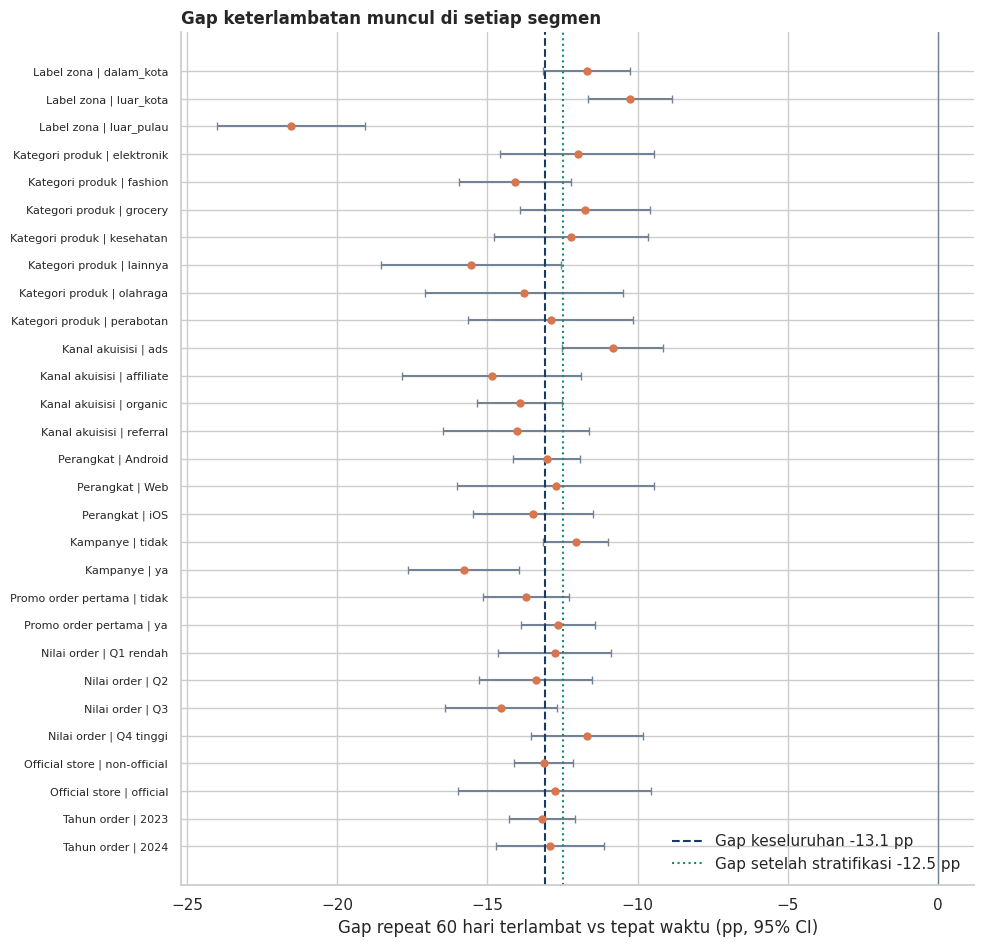

In [53]:
# Uji ketahanan gap keterlambatan dengan stratifikasi (tanpa model): apakah gap bertahan di dalam setiap segmen?
def mh_rd(df, outcome, treat, strata):
    """Selisih proporsi (treat=1 dikurangi treat=0) yang digabung lintas strata dengan bobot Mantel-Haenszel.
    Strata yang tidak memiliki kedua kelompok tidak dipakai."""
    num = wsum = var = 0.0; used = k_used = 0
    for _, d in df.groupby(strata, observed=True):
        a, b = d.loc[d[treat].eq(1), outcome], d.loc[d[treat].eq(0), outcome]
        n1, n0 = len(a), len(b)
        if n1 == 0 or n0 == 0: continue
        p1, p0_ = a.mean(), b.mean(); w = n1 * n0 / (n1 + n0)
        num += w * (p1 - p0_); wsum += w; var += w**2 * (p1 * (1 - p1) / n1 + p0_ * (1 - p0_) / n0)
        used += n1 + n0; k_used += 1
    rd, se = num / wsum, np.sqrt(var) / wsum
    return dict(diff=rd, low=rd - 1.959964 * se, high=rd + 1.959964 * se, p=2 * stats.norm.sf(abs(rd / se)),
                n=used, strata=k_used)

c = cohort60.copy()
c['nilai_order'] = pd.qcut(c['total_amount'], 4, labels=['Q1 rendah', 'Q2', 'Q3', 'Q4 tinggi'])
c['official'] = np.where(c['is_official_store'], 'official', 'non-official')
c['tahun'] = c['order_date'].dt.year.astype(str)
dims = {'shipping_zone': 'Label zona', 'product_category': 'Kategori produk', 'acquisition_channel': 'Kanal akuisisi',
        'device_type': 'Perangkat', 'campaign_first': 'Kampanye', 'promo_first': 'Promo order pertama',
        'nilai_order': 'Nilai order', 'official': 'Official store', 'tahun': 'Tahun order'}
combo = ['shipping_zone', 'product_category', 'acquisition_channel', 'campaign_first', 'promo_first']

# 1) Gap repeat 60 hari (terlambat - tepat waktu): mentah, per dimensi, dan gabungan lima dimensi
lt = c.groupby('late_delivery')['repeat'].agg(['sum', 'size'])
raw_gap = two_prop(lt.loc[1, 'sum'], lt.loc[1, 'size'], lt.loc[0, 'sum'], lt.loc[0, 'size'])
rows = [{'Dasar perbandingan': 'Mentah (tanpa stratifikasi)', 'Strata': 1, 'n': len(c), 'Gap (pp)': raw_gap['diff'] * 100,
         'CI low': raw_gap['low'] * 100, 'CI high': raw_gap['high'] * 100, 'p': raw_gap['p']}]
for col, label in dims.items():
    r = mh_rd(c, 'repeat', 'late_delivery', col)
    rows.append({'Dasar perbandingan': f'Dalam {label}', 'Strata': r['strata'], 'n': r['n'], 'Gap (pp)': r['diff'] * 100,
                 'CI low': r['low'] * 100, 'CI high': r['high'] * 100, 'p': r['p']})
mh_all = mh_rd(c, 'repeat', 'late_delivery', combo)
rows.append({'Dasar perbandingan': 'Dalam zona x kategori x kanal x kampanye x promo', 'Strata': mh_all['strata'], 'n': mh_all['n'],
             'Gap (pp)': mh_all['diff'] * 100, 'CI low': mh_all['low'] * 100, 'CI high': mh_all['high'] * 100, 'p': mh_all['p']})
q4_strat = pd.DataFrame(rows)
gap_strat = -mh_all['diff']                       # gap disesuaikan (positif = repeat lebih rendah bila terlambat)
print(f'n = {len(c):,} | repeat tepat waktu {pct(raw_gap["p_b"], 2)} vs terlambat {pct(raw_gap["p_a"], 2)}')
print('1) Gap repeat 60 hari terlambat vs tepat waktu, sebelum dan sesudah stratifikasi (bobot Mantel-Haenszel)')
display(q4_strat.round(4))

# 2) Gap per segmen (dasar forest plot)
seg_rows = []
for col, label in dims.items():
    for lvl, d in c.groupby(col, observed=True):
        g = d.groupby('late_delivery')['repeat'].agg(['sum', 'size'])
        t = two_prop(g.loc[1, 'sum'], g.loc[1, 'size'], g.loc[0, 'sum'], g.loc[0, 'size'])
        seg_rows.append({'Dimensi': label, 'Segmen': {0: 'tidak', 1: 'ya'}.get(lvl, str(lvl)) if col in ('campaign_first', 'promo_first') else str(lvl), 'n': len(d), 'Repeat tepat waktu': t['p_b'],
                         'Repeat terlambat': t['p_a'], 'Gap (pp)': t['diff'] * 100, 'CI low': t['low'] * 100,
                         'CI high': t['high'] * 100, 'p': t['p']})
q4_seg = pd.DataFrame(seg_rows)
print(f"2) Gap per segmen: {len(q4_seg)} segmen, gap terkecil {q4_seg['Gap (pp)'].max():.1f} pp, "
      f"terbesar {q4_seg['Gap (pp)'].min():.1f} pp, signifikan (p < 0,05) di {int((q4_seg['p'] < 0.05).sum())} segmen")
display(q4_seg.round(4))

# 3) Apakah promo menutup gap? Gap pada pengguna berpromo vs tanpa promo (selisih dua gap)
gp = {}
for v in [1, 0]:
    g = c.loc[c['promo_first'].eq(v)].groupby('late_delivery')['repeat'].agg(['sum', 'size'])
    gp[v] = two_prop(g.loc[1, 'sum'], g.loc[1, 'size'], g.loc[0, 'sum'], g.loc[0, 'size'])
se_ = lambda t: (t['high'] - t['low']) / (2 * 1.959964)
dd = gp[1]['diff'] - gp[0]['diff']; se_dd = np.sqrt(se_(gp[1])**2 + se_(gp[0])**2)
print(f"3) Gap pada pengguna berpromo {gp[1]['diff']*100:+.2f} pp vs tanpa promo {gp[0]['diff']*100:+.2f} pp -> "
      f"selisih {dd*100:+.2f} pp (95% CI {(dd - 1.959964*se_dd)*100:+.2f} s.d. {(dd + 1.959964*se_dd)*100:+.2f}); "
      f"p = {2 * stats.norm.sf(abs(dd / se_dd)):.3g}")

# 4) Faktor lain pada status ketepatan yang sama (stratifikasi menurut late_delivery)
c['luar_pulau'] = c['shipping_zone'].eq('luar_pulau').astype(int)
c['luar_kota_vs_dalam'] = np.where(c['shipping_zone'].eq('luar_kota'), 1, np.where(c['shipping_zone'].eq('dalam_kota'), 0, np.nan))
oth = []
for label, d, treat in [('Label luar_pulau vs dalam_kota', c.loc[c['shipping_zone'].ne('luar_kota')], 'luar_pulau'),
                        ('Label luar_kota vs dalam_kota', c.loc[c['luar_kota_vs_dalam'].notna()].assign(
                            luar_kota_vs_dalam=lambda x: x['luar_kota_vs_dalam'].astype(int)), 'luar_kota_vs_dalam'),
                        ('Order pertama saat kampanye vs non-kampanye', c, 'campaign_first'),
                        ('Promo vs tanpa promo', c, 'promo_first')]:
    r = mh_rd(d, 'repeat', treat, 'late_delivery')
    oth.append({'Perbandingan (dalam status ketepatan yang sama)': label, 'Selisih repeat (pp)': r['diff'] * 100,
                'CI low': r['low'] * 100, 'CI high': r['high'] * 100, 'p': r['p']})
q4_other = pd.DataFrame(oth)
print('4) Faktor lain setelah distratifikasi menurut ketepatan pengiriman')
display(q4_other.round(4))
print('Repeat 60 hari menurut label zona dan ketepatan pengiriman:')
display((c.pivot_table(index='shipping_zone', columns='late_delivery', values='repeat', aggfunc='mean')
         .rename(columns={0: 'Tepat waktu', 1: 'Terlambat'}) * 100).round(2))

# Forest plot: gap per segmen, diurutkan per dimensi
fp = q4_seg.copy()
fig, ax = plt.subplots(figsize=(10, 0.27 * len(fp) + 1.8))
yy = np.arange(len(fp))
ax.errorbar(fp['Gap (pp)'], yy, xerr=[fp['Gap (pp)'] - fp['CI low'], fp['CI high'] - fp['Gap (pp)']],
            fmt='o', color=ORANGE, ecolor=GRAY, capsize=3, ms=5)
ax.axvline(0, color=GRAY, lw=1)
ax.axvline(raw_gap['diff'] * 100, color=PRIMARY, ls='--', label=f"Gap keseluruhan {raw_gap['diff']*100:.1f} pp")
ax.axvline(mh_all['diff'] * 100, color=TEAL, ls=':', label=f"Gap setelah stratifikasi {mh_all['diff']*100:.1f} pp")
ax.set_yticks(yy, [f"{d} | {s}" for d, s in zip(fp['Dimensi'], fp['Segmen'])], fontsize=8); ax.invert_yaxis()
ax.set_xlabel('Gap repeat 60 hari terlambat vs tepat waktu (pp, 95% CI)'); ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Gap keterlambatan muncul di setiap segmen', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()


**Insight (stratifikasi, n = 39.363):**
- **Gap keterlambatan bukan artefak komposisi pengguna.** Gap mentah −13,10 pp (66,15% vs 79,25%). Setelah dibandingkan di dalam segmen yang sama, gap tetap −12,63 s.d. −13,10 pp untuk setiap dimensi, dan **−12,48 pp (95% CI −13,41 s.d. −11,56)** saat distratifikasi sekaligus menurut zona × kategori × kanal × kampanye × promo (336 strata). Angka −12,48 pp dipakai sebagai gap disesuaikan pada bagian 5.
- **Gap muncul di seluruh 29 segmen** dan signifikan di semuanya (p < 0,05): terkecil pada label luar_kota (−10,2 pp) dan ads (−10,8 pp), terbesar pada label **luar_pulau (−21,5 pp)**, order pertama saat kampanye (−15,8 pp), dan kategori lainnya (−15,5 pp).
- **Promo tidak menutup gap.** Gap pada pengguna berpromo −12,65 pp vs tanpa promo −13,71 pp; selisihnya +1,06 pp (95% CI −0,84 s.d. +2,96; p = 0,274). Pada status ketepatan yang sama, promo juga tidak mengubah repeat (−0,04 pp; p = 0,93).
- **Faktor lain pada status ketepatan yang sama:** label **luar_pulau** −10,5 pp dibanding dalam_kota (bahkan saat tepat waktu: 74,7% vs 81,3%), luar_kota −2,1 pp, dan order pertama saat **kampanye** −1,9 pp. Efek luar_kota dan kampanye jauh lebih kecil daripada efek keterlambatan; efek label luar_pulau besar karena label ini menggabungkan kelas SLA panjang dan ekor keterlambatan berat (bagian 6.5).
- Stratifikasi hanya menyeimbangkan variabel yang tercatat, sehingga hasilnya tetap asosiasi.


### <span style="color:darkorange"> 4.1 Keterlambatan menurut Jenis Layanan Kurir</span>
Keterlambatan (`delivery_duration_days` > `sla_promised_days`) dibandingkan antar jenis layanan (`courier_service_type`) secara deskriptif (95% CI Wilson, chi-square), lalu dirinci per zona agar perbedaan komposisi zona antar layanan terlihat. Keterkaitannya dengan retensi dilihat dari repeat 60 hari menurut layanan order pertama.

,pengiriman,terlambat,late_rate,median_sla,median_durasi,rata_durasi,CI low,CI high,rata_hari_lewat_sla (yang terlambat)
courier_service_type,,,,,,,,,
instant,11754,3989,0.3394,3.0,3.0,4.3515,0.3309,0.3480,3.4016
same_day,23636,8369,0.3541,3.0,3.0,4.344,0.3480,0.3602,3.2770
express,58960,20574,0.3489,3.0,3.0,4.2805,0.3451,0.3528,3.1987
reguler,141754,49405,0.3485,3.0,3.0,4.2937,0.3460,0.3510,3.1989


Chi-square keterlambatan vs jenis layanan: p = 0.0564
Tingkat keterlambatan per layanan x zona (%):


shipping_zone,dalam_kota,luar_kota,luar_pulau
courier_service_type,,,
instant,31.98,32.37,43.77
same_day,34.22,33.85,43.26
express,33.79,33.44,42.45
reguler,33.49,33.35,43.00


Repeat 60 hari menurut layanan order pertama:


,Repeat tepat waktu,Repeat terlambat,Gap (pp),Repeat keseluruhan
courier_service_type,,,,
instant,0.7853,0.6677,11.7655,0.7443
same_day,0.7989,0.6662,13.2756,0.7537
express,0.7963,0.6752,12.1130,0.7543
reguler,0.7904,0.6547,13.5764,0.7435


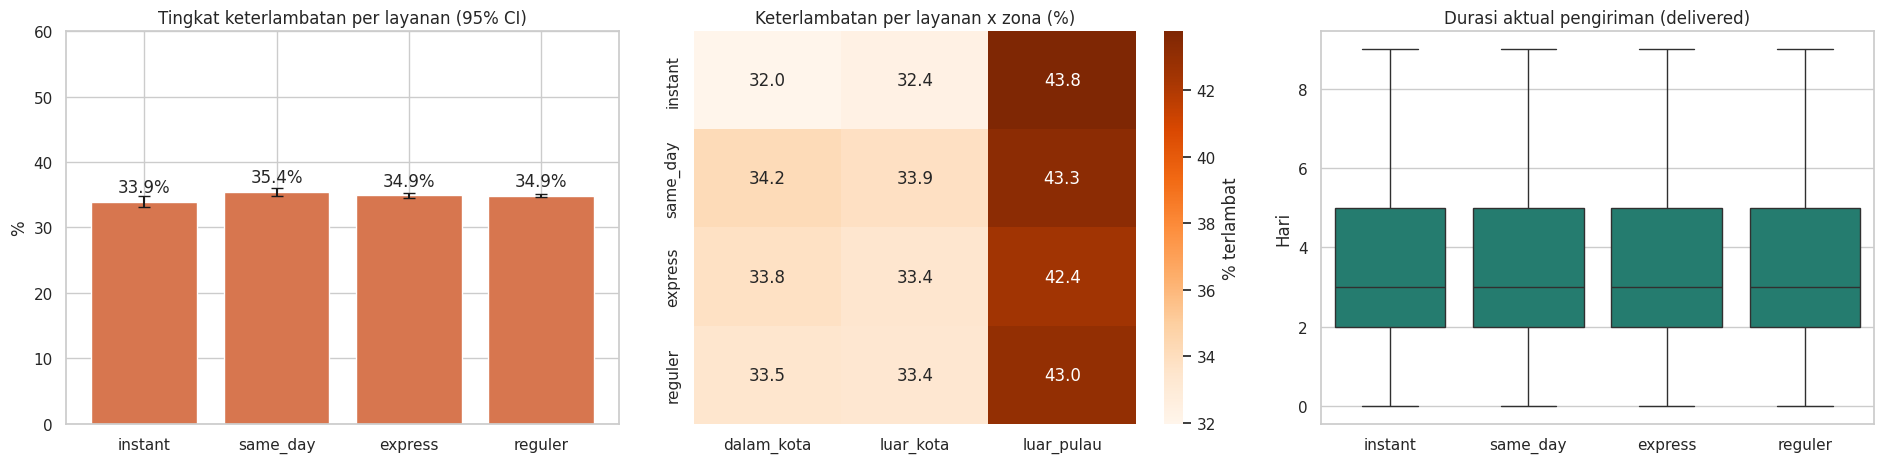

In [54]:
# Analisis keterlambatan menurut jenis layanan kurir (courier_service_type)
dv = base.loc[base['late_delivery'].notna()].copy()           # pengiriman delivered dengan durasi & SLA valid
dv['late_delivery'] = dv['late_delivery'].astype(int)
order_svc = ['instant', 'same_day', 'express', 'reguler']

svc = dv.groupby('courier_service_type').agg(
    pengiriman=('order_id', 'size'), terlambat=('late_delivery', 'sum'), late_rate=('late_delivery', 'mean'),
    median_sla=('sla_promised_days', 'median'), median_durasi=('delivery_duration_days', 'median'),
    rata_durasi=('delivery_duration_days', 'mean')).reindex(order_svc)
ci = [wilson(r.terlambat, r.pengiriman) for r in svc.itertuples()]
svc['CI low'], svc['CI high'] = [c[0] for c in ci], [c[1] for c in ci]
svc['rata_hari_lewat_sla (yang terlambat)'] = dv.loc[dv['late_delivery'].eq(1)].groupby('courier_service_type')['days_over_sla'].mean()
chi = stats.chi2_contingency(pd.crosstab(dv['courier_service_type'], dv['late_delivery']))
display(svc.round(4))
print(f'Chi-square keterlambatan vs jenis layanan: p = {chi.pvalue:.3g}')

zone_svc = dv.pivot_table(index='courier_service_type', columns='shipping_zone', values='late_delivery', aggfunc='mean').reindex(order_svc)
print('Tingkat keterlambatan per layanan x zona (%):')
display((zone_svc * 100).round(2))

# Kaitan dengan retensi: repeat 60 hari menurut layanan order pertama dan ketepatan pengiriman
rep_svc = cohort60.pivot_table(index='courier_service_type', columns='late_delivery', values='repeat', aggfunc='mean').reindex(order_svc)
rep_svc.columns = ['Repeat tepat waktu', 'Repeat terlambat']
rep_svc['Gap (pp)'] = (rep_svc['Repeat tepat waktu'] - rep_svc['Repeat terlambat']) * 100
rep_svc['Repeat keseluruhan'] = cohort60.groupby('courier_service_type')['repeat'].mean()
print('Repeat 60 hari menurut layanan order pertama:')
display(rep_svc.round(4))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
axes[0].bar(svc.index, svc['late_rate'] * 100, color=ORANGE,
            yerr=[(svc['late_rate'] - svc['CI low']) * 100, (svc['CI high'] - svc['late_rate']) * 100], capsize=4)
for i, v in enumerate(svc['late_rate'] * 100): axes[0].text(i, v + 1.5, f'{v:.1f}%', ha='center')
axes[0].set_ylim(0, 60); axes[0].set_title('Tingkat keterlambatan per layanan (95% CI)'); axes[0].set_ylabel('%')
sns.heatmap(zone_svc * 100, annot=True, fmt='.1f', cmap='Oranges', ax=axes[1], cbar_kws={'label': '% terlambat'})
axes[1].set_title('Keterlambatan per layanan x zona (%)'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
sns.boxplot(data=dv, x='courier_service_type', y='delivery_duration_days', order=order_svc, color=TEAL,
            showfliers=False, ax=axes[2])
axes[2].set_title('Durasi aktual pengiriman (delivered)'); axes[2].set_xlabel(''); axes[2].set_ylabel('Hari')
plt.tight_layout(); plt.show()

**Insight:**
- **Jenis layanan tidak membedakan keterlambatan.** Tingkat keterlambatan instant 33,9%, express 34,9%, reguler 34,9%, dan same_day 35,4%; perbedaannya tidak signifikan (chi-square p = 0,056). Pola yang sama terlihat di setiap zona (selisih antar layanan ≤ 2,3 pp di dalam zona yang sama).
- **Label layanan tidak mencerminkan kecepatan.** Median SLA dan median durasi aktual sama-sama 3 hari untuk semua layanan (rata-rata durasi 4,28–4,35 hari). Layanan instant/same_day yang seharusnya sampai di hari yang sama ternyata sama lambatnya dengan reguler.
- **Zona adalah pembeda utama.** Di setiap jenis layanan, keterlambatan zona luar pulau (42,5–43,8%) jauh lebih tinggi daripada dalam kota atau luar kota (32,0–34,2%).
- **Dampak ke retensi serupa di semua layanan:** gap repeat 60 hari antara tepat waktu dan terlambat 11,8–13,6 pp untuk setiap layanan.
- Implikasi: keterlambatan **tidak disebabkan oleh pilihan jenis layanan kurir** pada data ini. Perbaikan sebaiknya difokuskan pada zona pengiriman dan kinerja SLA secara umum, sambil mengonfirmasi definisi layanan ke pemilik data (lihat Rekomendasi Kualitas Data).

### <span style="color:darkorange"> 4.2 Faktor yang Berkaitan dengan Keterlambatan</span>
Seluruh faktor yang tersedia (zona, panjang SLA, kampanye, tanggal kembar, kurir, layanan, jeda dispatch, karakteristik seller, produk, pembayaran, lokasi, dan waktu) diskrining terhadap keterlambatan, lalu faktor yang lolos diuji dengan stratifikasi: selisih tingkat keterlambatan dihitung di dalam strata yang sama (mis. efek kampanye di dalam zona dan kurir yang sama) dan digabung dengan bobot Mantel-Haenszel. Hubungan bersifat asosiasi.

Pengiriman delivered: 236,104 | tingkat keterlambatan 34.9%


,Faktor,Terendah,Tertinggi,Rentang (pp),p (chi-square)
0,shipping_zone,luar_kota (33.4%),luar_pulau (42.9%),9.56,4.087672e-257
1,sla_band,SLA 1-5 (33.7%),SLA 6-10 (43.0%),9.33,6.206492e-215
6,dispatch_lag,3 (33.5%),5 (42.6%),9.03,8.455728e-01
2,is_campaign_period,False (33.7%),True (36.9%),3.17,1.916986e-54
3,twin_date,False (34.5%),True (36.9%),2.32,2.368935e-16
4,courier,SiCepat (34.0%),GoTo Logistics (35.9%),1.85,1.449498e-15
14,destination_city,Malang (34.0%),Semarang (35.6%),1.57,2.639921e-01
5,courier_service_type,instant (33.9%),same_day (35.4%),1.47,5.639600e-02
17,bulan,1 (34.5%),6 (35.7%),1.26,4.778800e-01
13,payment_channel_provider,DANA (34.4%),Credit Card (35.5%),1.13,1.007800e-01


Tingkat keterlambatan zona x SLA (%):


sla_band,SLA 1-5,SLA 6-10
shipping_zone,,
dalam_kota,33.57,NaN
luar_kota,33.37,NaN
luar_pulau,42.36,43.05


Jumlah pengiriman zona x SLA:


sla_band,SLA 1-5,SLA 6-10
shipping_zone,,
dalam_kota,94386.0,NaN
luar_kota,106582.0,NaN
luar_pulau,5954.0,29182.0


,Faktor,Distratifikasi menurut,Selisih keterlambatan (pp),CI low,CI high,p
0,Label luar_pulau vs label lain,kampanye x courier,9.4674,8.9199,10.0149,0.0000
1,SLA 6-10 vs SLA 1-5 (hanya label luar_pulau),kampanye x courier,0.2953,-1.0546,1.6452,0.6681
2,Kampanye vs non-kampanye,shipping_zone x courier,3.1652,2.7634,3.5671,0.0000
3,Tanggal kembar vs tanggal lain,kampanye x shipping_zone x courier,-0.0158,-0.6716,0.6400,0.9623
4,GoTo Logistics vs kurir lain,kampanye x shipping_zone,1.7135,1.3160,2.1110,0.0000


,Non-kampanye (%),Kampanye (%),Kenaikan (pp)
shipping_zone,,,
dalam_kota,32.98,34.60,1.61
luar_kota,32.77,34.43,1.66
luar_pulau,38.61,50.59,11.98


Rata-rata pengiriman per hari: kampanye 889 vs non-kampanye 237 (3.7x)
Kelebihan hari dari SLA pada pengiriman terlambat:


,mean,median
shipping_zone,,
dalam_kota,2.56,1.0
luar_kota,2.58,1.0
luar_pulau,6.10,2.0


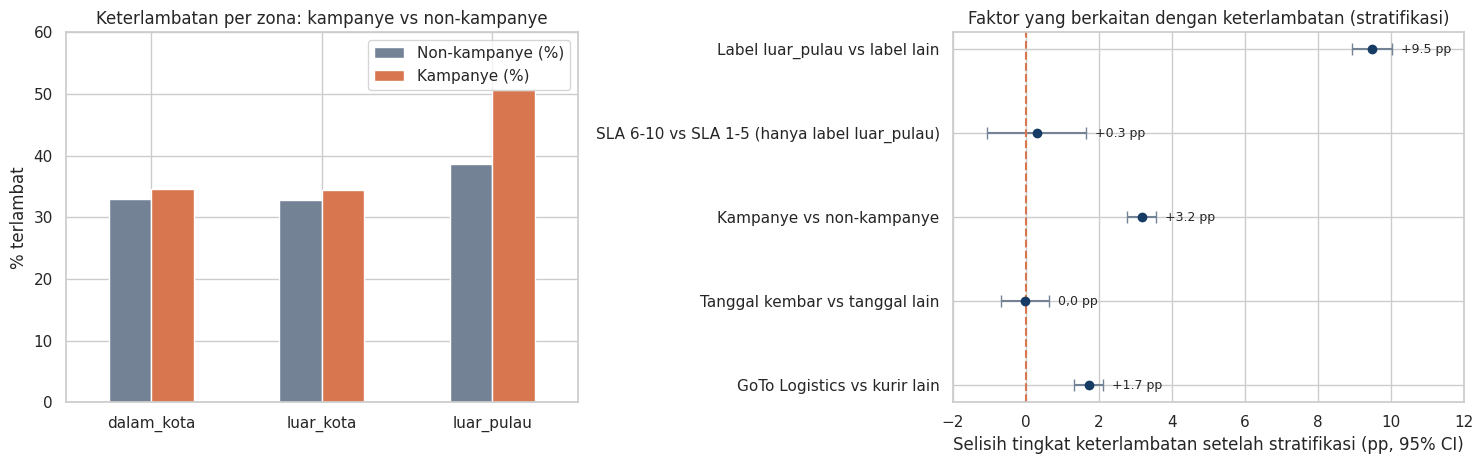

In [55]:
# Faktor yang berkaitan dengan keterlambatan pengiriman (delivered dengan durasi & SLA valid)
dl = base.loc[base['late_delivery'].notna()].copy()
dl['late_delivery'] = dl['late_delivery'].astype(int)
dl['dispatch_lag'] = (dl['dispatch_date'] - dl['order_date']).dt.days.clip(upper=6)
dl['courier'] = dl['courier_name'].fillna('Tidak diketahui')
dl['sla_band'] = np.where(dl['sla_promised_days'].ge(6), 'SLA 6-10', 'SLA 1-5')
dl['twin_date'] = dl['order_date'].dt.month.eq(dl['order_date'].dt.day)
dl['respon_seller'] = pd.cut(dl['avg_response_time_hours'], [0, 2, 6, 24, 72, 1000],
                             labels=['<=2 jam', '2-6 jam', '6-24 jam', '24-72 jam', '>72 jam'])
dl['rating_seller'] = pd.cut(dl['seller_rating'], [0, 4, 4.5, 5.01], labels=['<4', '4-4.5', '>=4.5'])
dl['qty'] = dl['item_quantity'].clip(upper=5)
dl['satu_kota'] = dl['seller_city'].eq(dl['destination_city'])
dl['bulan'] = dl['order_date'].dt.month
dl['hari'] = dl['order_date'].dt.dayofweek

# 1) Skrining univariat
factors = ['shipping_zone', 'sla_band', 'is_campaign_period', 'twin_date', 'courier', 'courier_service_type',
           'dispatch_lag', 'respon_seller', 'rating_seller', 'is_official_store', 'seller_status', 'product_category',
           'qty', 'payment_channel_provider', 'destination_city', 'seller_city', 'satu_kota', 'bulan', 'hari']
rows = []
for f in factors:
    g = dl.groupby(f, observed=True)['late_delivery'].mean()
    rows.append({'Faktor': f, 'Terendah': f'{g.idxmin()} ({pct(g.min())})', 'Tertinggi': f'{g.idxmax()} ({pct(g.max())})',
                 'Rentang (pp)': round((g.max() - g.min()) * 100, 2),
                 'p (chi-square)': stats.chi2_contingency(pd.crosstab(dl[f], dl['late_delivery'])).pvalue})
late_screen = pd.DataFrame(rows).sort_values('Rentang (pp)', ascending=False)
print(f'Pengiriman delivered: {len(dl):,} | tingkat keterlambatan {pct(dl["late_delivery"].mean())}')
display(late_screen)

# 2) Zona vs panjang SLA: SLA 6-10 hari hanya ada di luar pulau
print('Tingkat keterlambatan zona x SLA (%):')
display((dl.pivot_table(index='shipping_zone', columns='sla_band', values='late_delivery', aggfunc='mean') * 100).round(2))
print('Jumlah pengiriman zona x SLA:')
display(dl.pivot_table(index='shipping_zone', columns='sla_band', values='late_delivery', aggfunc='size'))

# 3) Uji stratifikasi (tanpa model) untuk faktor yang lolos skrining: selisih tingkat keterlambatan
#    dibandingkan di dalam strata yang sama, digabung dengan bobot Mantel-Haenszel
dl['luar_pulau'] = dl['shipping_zone'].eq('luar_pulau').astype(int)
dl['sla_panjang'] = dl['sla_band'].eq('SLA 6-10').astype(int)
dl['kampanye'] = dl['is_campaign_period'].astype(int)
dl['tanggal_kembar'] = dl['twin_date'].astype(int)
dl['goto'] = dl['courier'].eq('GoTo Logistics').astype(int)
late_strat = []
for label, d, treat, strata in [
        ('Label luar_pulau vs label lain', dl, 'luar_pulau', ['kampanye', 'courier']),
        ('SLA 6-10 vs SLA 1-5 (hanya label luar_pulau)', dl.loc[dl['luar_pulau'].eq(1)], 'sla_panjang', ['kampanye', 'courier']),
        ('Kampanye vs non-kampanye', dl, 'kampanye', ['shipping_zone', 'courier']),
        ('Tanggal kembar vs tanggal lain', dl, 'tanggal_kembar', ['kampanye', 'shipping_zone', 'courier']),
        ('GoTo Logistics vs kurir lain', dl.loc[dl['courier'].ne('Tidak diketahui')], 'goto', ['kampanye', 'shipping_zone'])]:
    r = mh_rd(d, 'late_delivery', treat, strata)
    late_strat.append({'Faktor': label, 'Distratifikasi menurut': ' x '.join(strata), 'Selisih keterlambatan (pp)': r['diff'] * 100,
                       'CI low': r['low'] * 100, 'CI high': r['high'] * 100, 'p': r['p']})
late_strat = pd.DataFrame(late_strat)
display(late_strat.round(4))

# 4) Interaksi kampanye x zona dan beban volume harian
camp_zone = dl.pivot_table(index='shipping_zone', columns='is_campaign_period', values='late_delivery', aggfunc='mean') * 100
camp_zone.columns = ['Non-kampanye (%)', 'Kampanye (%)']
camp_zone['Kenaikan (pp)'] = camp_zone['Kampanye (%)'] - camp_zone['Non-kampanye (%)']
display(camp_zone.round(2))
vol = dl.groupby(['order_date', 'is_campaign_period']).size().groupby('is_campaign_period').mean()
print(f'Rata-rata pengiriman per hari: kampanye {vol[True]:,.0f} vs non-kampanye {vol[False]:,.0f} ({vol[True]/vol[False]:.1f}x)')
over = dl.loc[dl['late_delivery'].eq(1)].groupby('shipping_zone')['days_over_sla'].agg(['mean', 'median'])
print('Kelebihan hari dari SLA pada pengiriman terlambat:')
display(over.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
camp_zone[['Non-kampanye (%)', 'Kampanye (%)']].plot(kind='bar', color=[GRAY, ORANGE], rot=0, ax=axes[0])
axes[0].set_ylim(0, 60); axes[0].set_ylabel('% terlambat'); axes[0].set_xlabel('')
axes[0].set_title('Keterlambatan per zona: kampanye vs non-kampanye')
yy = np.arange(len(late_strat)); v = late_strat['Selisih keterlambatan (pp)']
axes[1].errorbar(v, yy, xerr=[v - late_strat['CI low'], late_strat['CI high'] - v], fmt='o', color=PRIMARY, ecolor=GRAY, capsize=4)
for y, x, h in zip(yy, v, late_strat['CI high']): axes[1].text(h + 0.25, y, (f'{x:+.1f} pp' if abs(x) >= 0.05 else '0,0 pp'), va='center', fontsize=9)
axes[1].set_xlim(-2, 12)
axes[1].axvline(0, color=ORANGE, ls='--'); axes[1].set_yticks(yy, late_strat['Faktor']); axes[1].invert_yaxis()
axes[1].set_xlabel('Selisih tingkat keterlambatan setelah stratifikasi (pp, 95% CI)')
axes[1].set_title('Faktor yang berkaitan dengan keterlambatan (stratifikasi)')
plt.tight_layout(); plt.show()

**Insight:**
- **Label zona luar_pulau adalah faktor terkuat:** keterlambatan 42,9%, atau **+9,5 pp** dibanding label lain setelah distratifikasi menurut kampanye dan kurir (95% CI +8,9 s.d. +10,0), dengan kelebihan dari SLA rata-rata 6,1 hari dibanding ±2,6 hari di zona lain. SLA panjang (6–10 hari) hanya ada di label luar_pulau; di dalam label ini SLA pendek dan panjang sama-sama ±42–43% terlambat (+0,3 pp; p = 0,67), sehingga efek SLA adalah efek zona.
- **Kampanye memperbesar keterlambatan, terutama pada label luar_pulau:** saat volume pengiriman harian naik ±3,7× (889 vs 237), keterlambatan luar_pulau melonjak dari 38,6% ke **50,6%** (+12,0 pp), sedangkan zona lain hanya naik ±1,6 pp. Secara keseluruhan kampanye menambah +3,2 pp setelah distratifikasi zona dan kurir. Tanggal kembar tidak menambah risiko di luar efek kampanye (0,0 pp; p = 0,96).
- **Kurir GoTo Logistics** sedikit lebih sering terlambat (35,9% vs 34,0–34,3%; +1,7 pp setelah distratifikasi kampanye dan zona). Rata-rata ini menyembunyikan lonjakan besar pada label luar_pulau saat kampanye (bagian 6.7).
- **Tidak berkaitan:** jenis layanan, waktu respons seller, rating dan status seller, official store, kategori produk, jumlah barang, pembayaran, kota tujuan/seller, bulan, dan hari. Jeda dispatch juga tidak berkaitan (p = 0,85); rentangnya tampak besar hanya karena kelompok jeda 5 hari sangat kecil (47 pengiriman).
- **Kesimpulan:** keterlambatan bukan masalah seller, produk, atau pilihan layanan, melainkan **kelas SLA luar_pulau yang memburuk tajam saat kampanye**. Label ini mencerminkan kelas SLA menurut sistem, bukan jarak geografis (bagian 6.1). Sekitar sepertiga pengiriman di semua segmen tetap terlambat (±33%) dan tidak dijelaskan oleh variabel yang tersedia; kemungkinan dipengaruhi faktor di luar data seperti kapasitas hub, cuaca, atau proses sortir.


### <span style="color:darkorange"> 5. Estimasi Potensi Dampak Finansial (Revenue at Risk)</span>
`Revenue at risk = jumlah user terdampak × gap repeat × median GMV repeat 60 hari per repeat customer`. Gap disesuaikan diambil dari stratifikasi pada pertanyaan 4 (−12,48 pp). GMV (`total_amount`) adalah proksi nilai transaksi, **bukan** pendapatan bersih atau laba.

Pelanggan dengan order pertama terlambat: 13,596 | rentang kohort: 22.0 bulan
Median GMV repeat 60 hari per repeat customer: Rp1.236.021
Promo order pertama pada pelanggan terlambat yang tidak repeat: Rp246.320.199 (4,602 user)


,Dasar,Gap repeat,Repeat customer hilang,GMV repeat 60 hari at risk,Setara per 12 bulan
0,Gap observasi,13.10 pp,"1,781",Rp2.200.916.642,Rp1.201.621.530
1,Gap disesuaikan (stratifikasi),12.48 pp,"1,697",Rp2.097.939.119,Rp1.145.399.496


Pengiriman pertama failed: 1,965 user | repeat 27.1% vs tepat waktu 81.5% -> gap 54.42 pp | repeat customer hilang 1,069 | GMV repeat 60 hari at risk Rp1.321.808.508


,Gap ditutup,Repeat customer tambahan,GMV repeat 60 hari
0,10%,170.0,Rp209.793.912
1,25%,424.0,Rp524.484.780
2,50%,849.0,Rp1.048.969.559
3,100%,1697.0,Rp2.097.939.119


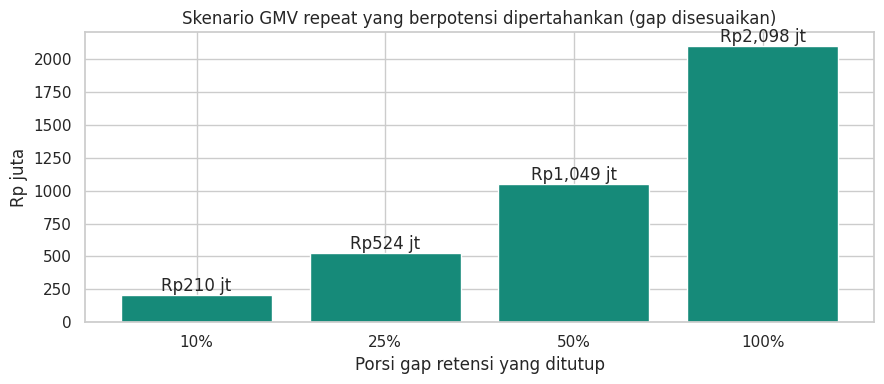

In [56]:
c = cohort60.copy()
late_c, ontime_c = c.loc[c['late_delivery'].eq(1)], c.loc[c['late_delivery'].eq(0)]
n_late = len(late_c)
months = (c['order_date'].max() - c['order_date'].min()).days / 30.4375
gap_obs = ontime_c['repeat'].mean() - late_c['repeat'].mean()
gap_adj = gap_strat                                       # gap setelah stratifikasi (pertanyaan 4)
gmv_per_repeater = c.loc[c['repeat'].eq(1), 'repeat_gmv'].median()     # median GMV repeat 60 hari per repeat customer

# Promo yang sudah dikeluarkan untuk order pertama pelanggan terlambat yang tidak kembali
promo_lost = late_c.loc[late_c['repeat'].eq(0), 'promo_amount'].sum()

rows = []
for label, gap in [('Gap observasi', gap_obs), ('Gap disesuaikan (stratifikasi)', gap_adj)]:
    lost_customers = n_late * gap
    rows.append([label, f'{gap*100:.2f} pp', f'{lost_customers:,.0f}', rp(lost_customers * gmv_per_repeater),
                 rp(lost_customers * gmv_per_repeater / months * 12)])
rar = pd.DataFrame(rows, columns=['Dasar', 'Gap repeat', 'Repeat customer hilang', 'GMV repeat 60 hari at risk',
                                  'Setara per 12 bulan'])
print(f'Pelanggan dengan order pertama terlambat: {n_late:,} | rentang kohort: {months:.1f} bulan')
print(f'Median GMV repeat 60 hari per repeat customer: {rp(gmv_per_repeater)}')
print(f'Promo order pertama pada pelanggan terlambat yang tidak repeat: {rp(promo_lost)} '
      f'({late_c.loc[late_c["repeat"].eq(0)].shape[0]:,} user)')
display(rar)

# Komponen kedua: order pertama dengan pengiriman gagal (failed) vs delivered tepat waktu, repeat 60 hari sejak order
fr = fo.groupby('status_kirim')['rep'].agg(['size', 'mean'])
n_failed = int(fr.loc['failed', 'size'])
gap_failed = fr.loc['delivered - tepat waktu', 'mean'] - fr.loc['failed', 'mean']
lost_failed = n_failed * gap_failed
print(f"Pengiriman pertama failed: {n_failed:,} user | repeat {pct(fr.loc['failed','mean'])} vs tepat waktu "
      f"{pct(fr.loc['delivered - tepat waktu','mean'])} -> gap {gap_failed*100:.2f} pp | "
      f"repeat customer hilang {lost_failed:,.0f} | GMV repeat 60 hari at risk {rp(lost_failed * gmv_per_repeater)}")

scen = pd.DataFrame({'Gap ditutup': [.10, .25, .50, 1.0]})
scen['Repeat customer tambahan'] = n_late * gap_adj * scen['Gap ditutup']
scen['GMV repeat 60 hari'] = scen['Repeat customer tambahan'] * gmv_per_repeater
display(scen.assign(**{'Gap ditutup': scen['Gap ditutup'].map('{:.0%}'.format),
                       'GMV repeat 60 hari': scen['GMV repeat 60 hari'].map(rp)}).round(0))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(scen['Gap ditutup'].map('{:.0%}'.format), scen['GMV repeat 60 hari'] / 1e6, color=TEAL)
for i, v in enumerate(scen['GMV repeat 60 hari'] / 1e6): ax.text(i, v, f'Rp{v:,.0f} jt', ha='center', va='bottom')
ax.set_title('Skenario GMV repeat yang berpotensi dipertahankan (gap disesuaikan)')
ax.set_xlabel('Porsi gap retensi yang ditutup'); ax.set_ylabel('Rp juta')
plt.tight_layout(); plt.show()

**Insight:**
- **13.596 user** mengalami keterlambatan pada order pertama. Dengan gap repeat yang disesuaikan 12,48 pp (stratifikasi), sekitar **1.697 user** berpotensi tidak kembali. Dengan median GMV repeat 60 hari Rp1.236.021 per repeat customer, nilai **GMV repeat at risk ≈ Rp2,10 miliar** selama ±22 bulan kohort (**≈ Rp1,15 miliar per 12 bulan**). Dengan gap mentah 13,10 pp, angkanya ±1.781 user atau ±Rp2,20 miliar.
- **Pengiriman gagal** menambah risiko: 1.965 user, gap 54,4 pp, ±1.069 user, **≈ Rp1,32 miliar GMV repeat at risk**. Komponen ini dihitung dengan definisi berbeda (sejak order pertama) sehingga ditampilkan terpisah, bukan dijumlahkan langsung.
- **Promo yang sudah dikeluarkan** untuk order pertama 4.602 user terlambat yang tidak kembali mencapai **Rp246,3 juta**. Insentif tetap diberikan, tetapi peluang repeat-nya hilang.
- **Skenario:** menutup 25% gap keterlambatan setara ±424 repeat customer tambahan atau **≈ Rp524 juta** GMV repeat 60 hari.
- Angka ini adalah **estimasi skenario berbasis asosiasi**, bukan kerugian aktual, pendapatan bersih, atau ROI. Validasi kausal membutuhkan pilot/eksperimen, misalnya perbaikan SLA atau *service recovery* pada label zona luar_pulau.


### <span style="color:darkorange"> 5.1 Cost-Benefit Rekomendasi</span>
Setiap rekomendasi dinilai dengan nilai rupiah sesuai data, tanpa asumsi eksternal: penghematan dinyatakan dalam rupiah promo, sedangkan manfaat retensi dinyatakan dalam GMV (bukan pendapatan atau laba, karena take rate dan margin tidak tersedia di dataset maupun brief). Dua nilai dasar dipakai: (a) **selisih GMV 365 hari per order pertama yang terlambat** untuk strategi yang mencegah keterlambatan, dan (b) **nilai GMV 365 hari per pengguna tambahan yang kembali** untuk strategi yang menaikkan retensi. Nilai voucher dihitung dengan asumsi voucher hanya dibayar saat pengguna kembali berbelanja.

In [57]:
# Cost-benefit rekomendasi (nilai rupiah sesuai data; manfaat retensi dalam GMV, tanpa asumsi take rate)
months = (cohort60['order_date'].max() - cohort60['order_date'].min()).days / 30.4375
per_year = 12 / months

# A. Nilai finansial dasar (horizon 365 hari setelah order pertama diterima)
c365 = build_cohort(365)
trim = c365['repeat_gmv'] <= c365['repeat_gmv'].quantile(.99)
gmv_late_gap = (c365.loc[trim & c365['late_delivery'].eq(0), 'repeat_gmv'].mean()
                - c365.loc[trim & c365['late_delivery'].eq(1), 'repeat_gmv'].mean())        # per order pertama terlambat
late365 = c365.loc[trim & c365['late_delivery'].eq(1)]
gmv_retained = (late365.loc[late365['repeat_days'].le(60), 'repeat_gmv'].mean()
                - late365.loc[~late365['repeat_days'].le(60), 'repeat_gmv'].mean())        # per pengguna tambahan yang kembali
n_late_year = cohort60['late_delivery'].sum() * per_year
base_values = pd.DataFrame({'Nilai': [
    rp(gmv_late_gap), rp(gmv_retained), f'{n_late_year:,.0f}', rp(n_late_year * gmv_late_gap)]},
    index=['Selisih GMV 365 hari per order pertama terlambat',
           'Nilai GMV 365 hari per pengguna tambahan yang kembali (dalam 60 hari)',
           'Pengguna dengan order pertama terlambat per tahun', 'GMV berisiko per tahun'])
display(base_values)

# B. Batas promo per order (guardrail)
cap_rows = []
for label, cap in [('Promo <= nilai belanja', 1.0), ('Promo <= 50% nilai belanja', 0.5)]:
    limit = pc['total_amount'] * cap
    saving = (pc['promo_amount'] - np.minimum(pc['promo_amount'], limit)).sum() / YEARS
    affected = pc['promo_amount'].gt(limit)
    worst_gmv = pc.loc[affected, 'total_amount'].sum() / YEARS
    cap_rows.append([label, f'{affected.sum():,}', rp(saving), rp(worst_gmv)])
display(pd.DataFrame(cap_rows, columns=['Batas promo', 'Order terdampak (2 tahun)', 'Penghematan promo per tahun',
                                        'GMV per tahun bila semua order terdampak batal (risiko terburuk)']))

# C. Voucher pemulihan: kasus berat
severe = cohort60.assign(keluhan=cohort60['order_id'].map(flags)).loc[
    lambda d: d['days_over_sla'].gt(5) | d['keluhan'].eq('keterlambatan')]
failed_first = fo.loc[fo['status_kirim'].eq('failed')]
n_severe = (len(severe) + len(failed_first)) * per_year
p0 = (severe['repeat'].sum() + failed_first['rep'].sum()) / (len(severe) + len(failed_first))
median_promo = pc.loc[pc['grup_promo'].eq('promo normal'), 'promo_amount'].median()
v_rows = []
for lift in [.05, .10, .20]:
    cost = n_severe * (p0 + lift) * median_promo                      # voucher senilai median promo, dibayar saat pengguna kembali
    v_rows.append([f'+{lift*100:.0f} pp', f'{n_severe * lift:,.0f}', rp(n_severe * lift * gmv_retained), rp(cost)])
print(f'Kasus berat per tahun: {n_severe:,.0f} pengguna (terlambat > 5 hari / mengeluh keterlambatan / pengiriman pertama gagal) '
      f'| repeat saat ini {pct(p0)} | median promo order berpromo (normal) {rp(median_promo)}')
display(pd.DataFrame(v_rows, columns=['Kenaikan retensi', 'Pengguna tambahan yang kembali per tahun', 'Tambahan GMV per tahun',
                                      'Biaya voucher per tahun (senilai median promo)']))
print('Catatan: manfaat bersih tidak dihitung karena take rate dan margin tidak tersedia di dataset maupun brief.')
print(f'Cek konsistensi: selisih GMV per order pertama terlambat / gap repeat 60 hari = '
      f'{rp(gmv_late_gap / (cohort60.loc[cohort60["late_delivery"].eq(0), "repeat"].mean() - cohort60.loc[cohort60["late_delivery"].eq(1), "repeat"].mean()))} '
      f'per pengguna yang tidak kembali (pembanding nilai per pengguna tambahan {rp(gmv_retained)})')
p_all = 1 - cohort60.loc[cohort60['late_delivery'].eq(1), 'repeat'].mean()
print(f'Pembanding - voucher untuk SEMUA pengguna terlambat: {pct(1 - p_all)} sudah kembali tanpa voucher, '
      f'sehingga sebagian besar biaya voucher tidak menambah retensi')

# D. Strategi operasional berbiaya rendah
first_year = len(cohort60) * per_year
goto_share = cohort60['courier_name'].eq('GoTo Logistics').mean()
late_by_courier = dl.groupby('courier')['late_delivery'].mean()
goto_diff = late_by_courier['GoTo Logistics'] - late_by_courier[['SiCepat', 'JNE', 'AnterAja']].mean()
ops = pd.DataFrame([
    ['Notifikasi proaktif & estimasi tiba realistis (per +1 pp retensi)', f'{n_late_year * .01:,.0f} pengguna kembali',
     rp(n_late_year * .01 * gmv_retained), 'Hampir nol'],
    ['Alokasi ulang volume GoTo Logistics ke kurir lain', f'{first_year * goto_share * goto_diff:,.0f} order pertama tidak terlambat',
     rp(first_year * goto_share * goto_diff * gmv_late_gap), 'Hampir nol bila tarif setara'],
], columns=['Strategi', 'Dampak per tahun', 'GMV per tahun', 'Biaya'])
display(ops)

# E. Investasi logistik antarpulau (pembanding)
lp_first = cohort60.loc[cohort60['shipping_zone'].eq('luar_pulau')]
lp_camp = lp_first.loc[lp_first['campaign_first'].eq(1)]
lp_noncamp = lp_first.loc[lp_first['campaign_first'].eq(0)]
other_late = cohort60.loc[cohort60['shipping_zone'].ne('luar_pulau'), 'late_delivery'].mean()
lp_ship_camp_year = dl.loc[dl['shipping_zone'].eq('luar_pulau') & dl['is_campaign_period']].shape[0] / YEARS
inv = pd.DataFrame([
    ['Stok regional luar Jawa (keterlambatan luar pulau -> setara zona lain)',
     len(lp_first) * per_year * (lp_first['late_delivery'].mean() - other_late)],
    ['Kapasitas kargo kampanye (keterlambatan kampanye luar pulau -> non-kampanye)',
     len(lp_camp) * per_year * (lp_camp['late_delivery'].mean() - lp_noncamp['late_delivery'].mean())],
], columns=['Strategi', 'Order pertama tidak terlambat per tahun'])
inv['GMV per tahun'] = (inv['Order pertama tidak terlambat per tahun'] * gmv_late_gap).map(rp)
display(inv.round(0))
print(f'Pengiriman kampanye luar pulau per tahun: {lp_ship_camp_year:,.0f} paket')

,Nilai
Selisih GMV 365 hari per order pertama terlambat,Rp678.273
Nilai GMV 365 hari per pengguna tambahan yang kembali (dalam 60 hari),Rp5.148.804
Pengguna dengan order pertama terlambat per tahun,"7,423"
GMV berisiko per tahun,Rp5.034.773.843


,Batas promo,Order terdampak (2 tahun),Penghematan promo per tahun,GMV per tahun bila semua order terdampak batal (risiko terburuk)
0,Promo <= nilai belanja,"10,299",Rp2.334.198.605,Rp1.438.228.163
1,Promo <= 50% nilai belanja,"13,805",Rp3.234.700.212,Rp2.305.582.791


Kasus berat per tahun: 2,540 pengguna (terlambat > 5 hari / mengeluh keterlambatan / pengiriman pertama gagal) | repeat saat ini 25.0% | median promo order berpromo (normal) Rp17.316


,Kenaikan retensi,Pengguna tambahan yang kembali per tahun,Tambahan GMV per tahun,Biaya voucher per tahun (senilai median promo)
0,+5 pp,127,Rp653.993.597,Rp13.203.810
1,+10 pp,254,Rp1.307.987.194,Rp15.403.263
2,+20 pp,508,Rp2.615.974.389,Rp19.802.170


Catatan: manfaat bersih tidak dihitung karena take rate dan margin tidak tersedia di dataset maupun brief.
Cek konsistensi: selisih GMV per order pertama terlambat / gap repeat 60 hari = Rp5.178.907 per pengguna yang tidak kembali (pembanding nilai per pengguna tambahan Rp5.148.804)
Pembanding - voucher untuk SEMUA pengguna terlambat: 66.2% sudah kembali tanpa voucher, sehingga sebagian besar biaya voucher tidak menambah retensi


,Strategi,Dampak per tahun,GMV per tahun,Biaya
0,Notifikasi proaktif & estimasi tiba realistis ...,74 pengguna kembali,Rp382.192.003,Hampir nol
1,Alokasi ulang volume GoTo Logistics ke kurir lain,147 order pertama tidak terlambat,Rp99.728.020,Hampir nol bila tarif setara


,Strategi,Order pertama tidak terlambat per tahun,GMV per tahun
0,Stok regional luar Jawa (keterlambatan luar pu...,280.0,Rp189.962.979
1,Kapasitas kargo kampanye (keterlambatan kampan...,87.0,Rp58.970.015


Pengiriman kampanye luar pulau per tahun: 6,344 paket


**Insight:**
- **Nilai dasar:** setiap order pertama yang terlambat berkaitan dengan GMV 365 hari **Rp678.273 lebih rendah**, dan setiap pengguna tambahan yang kembali bernilai **Rp5,15 juta GMV**. Kedua angka konsisten: Rp678.273 dibagi gap repeat 13,1 pp menghasilkan Rp5,18 juta per pengguna yang tidak kembali. Dengan ±7.423 pengguna terlambat per tahun, GMV berisiko ±Rp5,03 miliar per tahun.
- **Batas promo adalah tuas finansial terbesar:** membatasi promo maksimal sebesar nilai belanja menghemat **±Rp2,33 miliar promo per tahun** (±37% anggaran promo). Risiko terburuknya, bila semua order terdampak batal, adalah GMV ±Rp1,44 miliar per tahun — order yang promonya justru lebih besar dari nilai belanjanya. Batas 50% nilai belanja menghemat ±Rp3,23 miliar, tetapi menyentuh lebih banyak order normal.
- **Voucher pemulihan untuk kasus berat layak diuji:** ±2.540 pengguna per tahun dengan repeat saat ini 25,0%. Pada kenaikan retensi 10 pp, tambahan GMV ±Rp1,31 miliar per tahun dengan biaya voucher ±Rp15,4 juta (voucher senilai median promo Rp17.316, dibayar saat pengguna kembali). Manfaat bersihnya tidak dihitung karena take rate dan margin tidak tersedia di dataset maupun brief, sehingga kelayakan finansial perlu dikonfirmasi lewat pilot.
- **Voucher untuk semua pengguna terlambat tidak efisien:** 66,2% pengguna terlambat sudah kembali tanpa voucher, sehingga sebagian besar biaya voucher tidak menambah retensi.
- **Langkah operasional berbiaya rendah layak:** setiap +1 pp retensi dari notifikasi proaktif dan estimasi tiba realistis bernilai ±Rp382 juta GMV per tahun; alokasi ulang volume GoTo Logistics (147 order pertama) bernilai ±Rp100 juta GMV per tahun, dengan biaya hampir nol.
- **Investasi logistik besar belum layak dari sisi retensi:** stok regional luar Jawa hanya terkait ±Rp190 juta GMV per tahun dari retensi, dan kapasitas kargo kampanye ±Rp59 juta GMV per tahun untuk ±6.344 paket kampanye luar pulau — kecil dibanding biaya tetap gudang maupun tambahan biaya kargo.
- Semua nilai berlaku pada skala dataset, dinyatakan dalam GMV (bukan pendapatan atau laba), dan dampak strategi retensi berasal dari asosiasi sehingga perlu diukur melalui pilot A/B.

<a id="Analisis-Lanjutan"></a>
## <span style="color:darkorange">Analisis Lanjutan (Deep Dive)</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Bagian ini menguji ulang dan memperdalam argumen utama dari lima sudut: (1) validitas label zona pengiriman, (2) siapa di balik transaksi promo &gt; belanja, (3) apakah penanganan keluhan dapat memulihkan retensi, (4) apakah dampak keterlambatan bertumpuk pada order berikutnya, dan (5) apakah keterlambatan berasal dari janji SLA yang terlalu optimistis. Setelah itu promo diuji terhadap metrik nilai (bukan hanya repeat), lalu ditutup dengan heatmap kurir × label zona × kampanye sebagai dasar alokasi kurir.
</p>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Seluruh sel memakai variabel dari bagian EDA sebelumnya (<code>om</code>, <code>base</code>, <code>completed</code>, <code>first_order</code>, <code>cohort60</code>, <code>c365</code>, <code>coh</code>, <code>pc</code>, <code>dl</code>, <code>fo</code>, <code>mh_rd</code>, dan nilai finansial dari bagian 5.1), sehingga harus dijalankan setelah bagian 5.1. Hubungan yang ditemukan tetap bersifat asosiasi.
</p>

###  6.1 Kualitas Data: Label `shipping_zone` vs Rute Asli
Label `shipping_zone` (dalam_kota / luar_kota / luar_pulau) dibandingkan dengan **rute asli** yang diturunkan dari `seller_city` → `destination_city`: kota sama = dalam kota, beda kota satu pulau = luar kota, beda pulau = luar pulau. Bila label mencerminkan geografi, sebagian besar order seharusnya berada di diagonal tabel silang. Setelah itu diuji hipotesis alternatif bahwa label berbeda karena barang dikirim dari gudang lain (mis. stok gudang kota asal habis).

Kota tanpa pemetaan pulau: tidak ada

1) Jumlah pengiriman: rute asli (baris) vs label shipping_zone (kolom) | n = 260,208


shipping_zone,dalam_kota,luar_kota,luar_pulau,Total
rute_asli,,,,
dalam kota (asli),12780,14491,4860,32131
"luar kota, satu pulau (asli)",42682,48317,16177,107176
luar pulau (asli),48354,54554,17993,120901


% per baris (bila label mengikuti geografi, angka terbesar ada di diagonal):


shipping_zone,dalam_kota,luar_kota,luar_pulau
rute_asli,,,
dalam kota (asli),39.8,45.1,15.1
"luar kota, satu pulau (asli)",39.8,45.1,15.1
luar pulau (asli),40.0,45.1,14.9



2) Label cocok dengan rute asli: 30.4% | bila label acak: 30.5% | chi-square p = 0.617 | Cramér's V = 0.002

3) SLA, durasi, dan keterlambatan (delivered) menurut label vs menurut rute asli


pengiriman  \
Menurut label shipping_zone dalam_kota                         94531   
                            luar_kota                         106739   
                            luar_pulau                         35187   
Menurut rute asli           dalam kota (asli)                  29158   
                            luar kota, satu pulau (asli)       97414   
                            luar pulau (asli)                 109885   

                                                          rata_SLA  \
Menurut label shipping_zone dalam_kota                       1.499   
                            luar_kota                          4.0   
                            luar_pulau                       7.507   
Menurut rute asli           dalam kota (asli)                3.535   
                            luar kota, satu pulau (asli)     3.527   
                            luar pulau (asli)                3.514   

                                                          rata_durasi  \
Menurut label shipping_zone dalam_kota                          2.027   
                            luar_kota                           4.493   
                            luar_pulau                          9.813   
Menurut rute asli           dalam kota (asli)                   4.295   
                            luar kota, satu pulau (asli)        4.302   
                            luar pulau (asli)                   4.297   

                                                          terlambat  
Menurut label shipping_zone dalam_kota                        0.336  
                            luar_kota                         0.334  
                            luar_pulau                        0.429  
Menurut rute asli           dalam kota (asli)                 0.348  
                            luar kota, satu pulau (asli)      0.350  
                            luar pulau (asli)                 0.348


4) Contoh rute dan sebaran labelnya


,Rute,Order,dalam_kota,luar_kota,luar_pulau
0,Jakarta → Jakarta,20617,8215,9238,3164
1,Surabaya → Surabaya,3603,1409,1639,555
2,Jakarta → Bandung,7555,3047,3326,1182
3,Jakarta → Makassar,5336,2153,2386,797
4,Medan → Manado,613,214,310,89
5,Denpasar → Pontianak,518,202,225,91


,order_id,seller_city,destination_city,shipping_zone,sla_promised_days,delivery_duration_days,courier_name
239,INV/230407/5136930,Medan,Manado,dalam_kota,1.0,0.0,SiCepat
668,INV/230110/9060687,Medan,Manado,dalam_kota,1.0,0.0,GoTo Logistics
3950,INV/230814/4872012,Medan,Manado,dalam_kota,2.0,3.0,GoTo Logistics



5) Uji hipotesis beda gudang pada 32,131 order satu kota (porsi luar_pulau keseluruhan 15.1%)


,Indikator,Nilai
0,"Sebaran porsi luar_pulau antar seller (SD, 378...",5.8%
1,SD yang diharapkan bila murni acak (binomial),5.7%
2,Seller dengan 0% luar_pulau pada order satu kota,5 dari 378
3,Porsi luar_pulau: non-kampanye vs kampanye,15.0% vs 15.4%
4,Porsi luar_pulau: rentang antar kategori produk,14.8% – 15.7%
5,Porsi luar_pulau: non-official vs official store,15.2% vs 14.5%


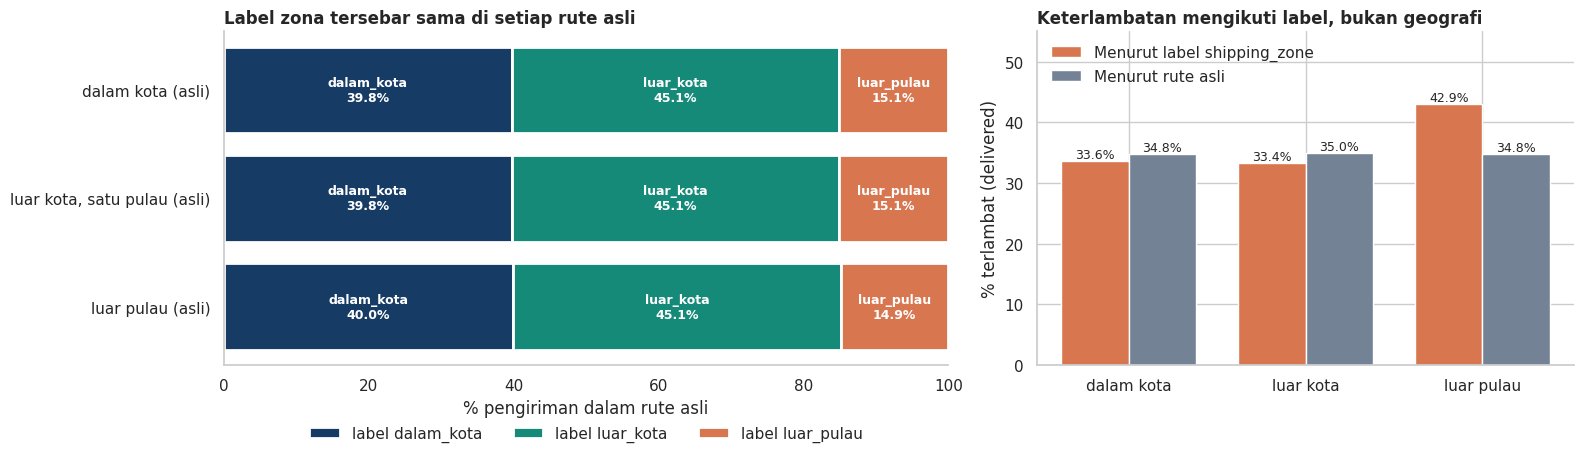

In [58]:
# 6.1 Label shipping_zone vs rute asli (seller_city -> destination_city, dikelompokkan per pulau)
ISLAND = {'Jakarta': 'Jawa', 'Tangerang': 'Jawa', 'Bandung': 'Jawa', 'Surabaya': 'Jawa', 'Semarang': 'Jawa',
          'Yogyakarta': 'Jawa', 'Malang': 'Jawa', 'Medan': 'Sumatera', 'Palembang': 'Sumatera', 'Padang': 'Sumatera',
          'Batam': 'Kepulauan Riau', 'Denpasar': 'Bali', 'Makassar': 'Sulawesi', 'Manado': 'Sulawesi',
          'Balikpapan': 'Kalimantan', 'Pontianak': 'Kalimantan'}
ROUTE_ORDER = ['dalam kota (asli)', 'luar kota, satu pulau (asli)', 'luar pulau (asli)']
ZONE_ORDER = ['dalam_kota', 'luar_kota', 'luar_pulau']

zr = om.loc[om['has_delivery'] & om['shipping_zone'].notna() & om['seller_city'].notna()
            & om['destination_city'].notna()].copy()
zr['pulau_asal'], zr['pulau_tujuan'] = zr['seller_city'].map(ISLAND), zr['destination_city'].map(ISLAND)
print('Kota tanpa pemetaan pulau:', sorted(set(zr.loc[zr['pulau_asal'].isna(), 'seller_city'])
                                           | set(zr.loc[zr['pulau_tujuan'].isna(), 'destination_city'])) or 'tidak ada')
zr['rute_asli'] = np.select([zr['seller_city'].eq(zr['destination_city']), zr['pulau_asal'].eq(zr['pulau_tujuan'])],
                            ROUTE_ORDER[:2], ROUTE_ORDER[2])

# 1) Tabel silang (jumlah order dan % per baris)
zone_ct = pd.crosstab(zr['rute_asli'], zr['shipping_zone']).reindex(index=ROUTE_ORDER, columns=ZONE_ORDER)
print(f'\n1) Jumlah pengiriman: rute asli (baris) vs label shipping_zone (kolom) | n = {len(zr):,}')
display(zone_ct.assign(Total=zone_ct.sum(axis=1)))
zone_pct = zone_ct.div(zone_ct.sum(axis=1), axis=0) * 100
print('% per baris (bila label mengikuti geografi, angka terbesar ada di diagonal):')
display(zone_pct.round(1))

# 2) Seberapa sering label cocok dengan rute asli, dibanding bila label diberikan acak
match = np.trace(zone_ct.values) / zone_ct.values.sum()
expected_random = (zone_ct.sum(axis=1).values / zone_ct.values.sum()) @ (zone_ct.sum(axis=0).values / zone_ct.values.sum())
chi_z = stats.chi2_contingency(zone_ct)
cramers_v = np.sqrt(chi_z.statistic / (zone_ct.values.sum() * (min(zone_ct.shape) - 1)))
print(f'\n2) Label cocok dengan rute asli: {pct(match)} | bila label acak: {pct(expected_random)} | '
      f"chi-square p = {chi_z.pvalue:.3f} | Cramér's V = {cramers_v:.3f}")

# 3) Yang mengikuti label: SLA dan durasi; yang mengikuti rute asli: tidak ada
zd = zr.loc[zr['delivery_status'].eq('delivered') & zr['delivery_duration_days'].notna() & zr['sla_promised_days'].notna()].copy()
zd['late'] = zd['delivery_duration_days'].gt(zd['sla_promised_days']).astype(int)
by_label = zd.groupby('shipping_zone').agg(pengiriman=('late', 'size'), rata_SLA=('sla_promised_days', 'mean'),
                                           rata_durasi=('delivery_duration_days', 'mean'), terlambat=('late', 'mean')).reindex(ZONE_ORDER)
by_route = zd.groupby('rute_asli').agg(pengiriman=('late', 'size'), rata_SLA=('sla_promised_days', 'mean'),
                                       rata_durasi=('delivery_duration_days', 'mean'), terlambat=('late', 'mean')).reindex(ROUTE_ORDER)
print('\n3) SLA, durasi, dan keterlambatan (delivered) menurut label vs menurut rute asli')
display(pd.concat({'Menurut label shipping_zone': by_label, 'Menurut rute asli': by_route}).round(3))

# 4) Contoh rute yang jelas
pairs = [('Jakarta', 'Jakarta'), ('Surabaya', 'Surabaya'), ('Jakarta', 'Bandung'),
         ('Jakarta', 'Makassar'), ('Medan', 'Manado'), ('Denpasar', 'Pontianak')]
ex_rows = []
for a_city, b_city in pairs:
    s = zr.loc[zr['seller_city'].eq(a_city) & zr['destination_city'].eq(b_city), 'shipping_zone'].value_counts()
    ex_rows.append({'Rute': f'{a_city} → {b_city}', 'Order': int(s.sum()), **{z: int(s.get(z, 0)) for z in ZONE_ORDER}})
print('\n4) Contoh rute dan sebaran labelnya')
display(pd.DataFrame(ex_rows))
display(zr.loc[zr['seller_city'].eq('Medan') & zr['destination_city'].eq('Manado') & zr['shipping_zone'].eq('dalam_kota'),
               ['order_id', 'seller_city', 'destination_city', 'shipping_zone', 'sla_promised_days',
                'delivery_duration_days', 'courier_name']].head(3))

# 5) Uji hipotesis "beda gudang" (mis. stok gudang kota asal habis): bila benar, porsi label luar_pulau pada
#    order satu kota seharusnya berbeda antar seller dan naik saat kampanye / berbeda antar kategori
same = zr.loc[zr['seller_city'].eq(zr['destination_city'])].copy()
same['lp'] = same['shipping_zone'].eq('luar_pulau')
p_lp = same['lp'].mean()
per_seller = same.groupby('seller_id')['lp'].agg(['size', 'mean']).query('size >= 20')
wh = pd.DataFrame({'Indikator': [
        f'Sebaran porsi luar_pulau antar seller (SD, {len(per_seller)} seller ≥ 20 order satu kota)',
        'SD yang diharapkan bila murni acak (binomial)',
        'Seller dengan 0% luar_pulau pada order satu kota',
        'Porsi luar_pulau: non-kampanye vs kampanye',
        'Porsi luar_pulau: rentang antar kategori produk',
        'Porsi luar_pulau: non-official vs official store'],
    'Nilai': [
        pct(per_seller['mean'].std()), pct(np.sqrt(p_lp * (1 - p_lp) / per_seller['size']).mean()),
        f"{int(per_seller['mean'].eq(0).sum())} dari {len(per_seller)}",
        ' vs '.join(pct(v) for v in same.groupby('is_campaign_period')['lp'].mean()),
        ' – '.join(pct(v) for v in same.groupby('product_category')['lp'].mean().agg(['min', 'max'])),
        ' vs '.join(pct(v) for v in same.groupby('is_official_store')['lp'].mean())]})
print(f'\n5) Uji hipotesis beda gudang pada {len(same):,} order satu kota (porsi luar_pulau keseluruhan {pct(p_lp)})')
display(wh)

# Grafik: (kiri) sebaran label per rute asli, (kanan) keterlambatan mengikuti label, bukan rute asli
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.35, 1]})
zone_colors = {'dalam_kota': PRIMARY, 'luar_kota': TEAL, 'luar_pulau': ORANGE}
left = np.zeros(len(ROUTE_ORDER))
for z in ZONE_ORDER:
    vals = zone_pct[z].values
    axes[0].barh(ROUTE_ORDER, vals, left=left, color=zone_colors[z], edgecolor='white', linewidth=2, label=f'label {z}')
    for i, (l, w) in enumerate(zip(left, vals)):
        axes[0].text(l + w / 2, i, f'{z}\n{w:.1f}%', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    left += vals
axes[0].invert_yaxis(); axes[0].set_xlim(0, 100); axes[0].set_xlabel('% pengiriman dalam rute asli')
axes[0].set_title('Label zona tersebar sama di setiap rute asli', loc='left', fontweight='bold')
axes[0].legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False)
axes[0].grid(False)
comp_late = pd.DataFrame({'Menurut label shipping_zone': by_label['terlambat'].values * 100,
                          'Menurut rute asli': by_route['terlambat'].values * 100},
                         index=['dalam kota', 'luar kota', 'luar pulau'])
xx = np.arange(3); w = 0.38
b1 = axes[1].bar(xx - w / 2, comp_late.iloc[:, 0], w, color=ORANGE, label=comp_late.columns[0])
b2 = axes[1].bar(xx + w / 2, comp_late.iloc[:, 1], w, color=GRAY, label=comp_late.columns[1])
for bars in (b1, b2): axes[1].bar_label(bars, fmt='%.1f%%', fontsize=9)
axes[1].set_xticks(xx, comp_late.index); axes[1].set_ylim(0, 55); axes[1].set_ylabel('% terlambat (delivered)')
axes[1].set_title('Keterlambatan mengikuti label, bukan geografi', loc='left', fontweight='bold')
axes[1].legend(frameon=False, loc='upper left')
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Insight:**
- **Label `shipping_zone` tidak mencerminkan geografi.** Di setiap rute asli, sebaran labelnya identik: ±40% `dalam_kota`, ±45% `luar_kota`, ±15% `luar_pulau`. Label hanya cocok dengan rute asli pada 30,4% pengiriman, sama dengan angka bila label diberikan acak (30,5%; chi-square p = 0,62; Cramér's V = 0,002).
- **Kontradiksinya terlihat jelas pada rute tertentu:** 3.164 pengiriman Jakarta → Jakarta berlabel `luar_pulau`, sedangkan 214 pengiriman Medan → Manado (beda pulau) berlabel `dalam_kota` dengan SLA 1 hari dan tiba di hari yang sama.
- **Hipotesis "beda gudang" tidak didukung.** Lokasi toko memang bisa berbeda dari lokasi gudang. Namun bila label `luar_pulau` pada order satu kota disebabkan stok gudang asal habis, porsinya seharusnya berbeda antar seller dan naik saat kampanye. Kenyataannya, sebaran antar seller (SD 5,8%) sama dengan sebaran acak (5,7%), hanya 5 dari 378 seller yang 0%, dan porsinya rata di kampanye (15,0% vs 15,4%), kategori (14,8–15,7%), maupun official store. Order Medan → kota di pulau lain yang berlabel `dalam_kota` juga mengharuskan hampir semua seller Medan memiliki gudang di kota tujuan.
- **Yang mengikuti label hanyalah SLA dan durasi** (SLA rata-rata 1,5 / 4,0 / 7,5 hari; keterlambatan 33,6% / 33,4% / 42,9%). Menurut rute asli, SLA, durasi, dan keterlambatan rata (±34,8%).
- **Implikasi:** `shipping_zone` diperlakukan sebagai **kelas SLA/rute menurut sistem**, bukan jarak geografis. Temuan "zona luar_pulau paling sering terlambat" tetap sah sebagai efek kelas SLA panjang, tetapi tidak dapat dibaca sebagai "pengiriman antarpulau", dan rekomendasi berbasis lokasi (mis. stok regional luar Jawa) tidak didukung data. Asal gudang (`origin_warehouse_city`) perlu ditambahkan oleh pemilik data sebelum analisis rute dilakukan.

###  6.2 Siapa di Balik Transaksi Promo > Belanja?
Bagian 2.1 menunjukkan 4,4% order completed menyerap 59% anggaran promo. Bila penyebabnya penyalahgunaan (*voucher abuse*), transaksinya akan **terkonsentrasi** pada sedikit user, seller, jenis voucher, atau tanggal tertentu, dan user yang sama akan memakainya berulang kali. Bila penyebabnya kesalahan konfigurasi, transaksinya akan **tersebar merata**. Konsentrasi diuji dengan kurva Pareto dan dibandingkan dengan sebaran yang diharapkan bila kejadiannya acak (binomial menurut jumlah order masing-masing user/seller).

1) 96.4% transaksi promo > belanja berasal dari voucher besar. Korelasi nominal voucher besar vs nilai belanja: r = -0.010


,order,promo_gt_belanja,median_promo,median_belanja,% order berpromo,% anggaran promo,% berakhir promo > belanja
voucher_besar,,,,,,,
promo < Rp400 rb,139777,423,16870.0,356518.0,90.0,19.7,0.3
voucher besar >= Rp400 rb,15572,11244,748715.5,354160.5,10.0,80.3,72.2


Per kategori: peluang mendapat voucher besar sama, tetapi keranjang kecil membuatnya melebihi belanja


,order,pct_dapat_voucher_besar,median_belanja,pct_voucher_besar_melebihi_belanja,pct_order_promo_gt
product_category,,,,,
grocery,50983,5.8,185333.0,95.5,6.0
kesehatan,34826,6.0,231956.5,92.4,5.8
fashion,67090,5.9,277990.0,89.1,5.4
lainnya,27116,5.6,307971.0,85.8,4.9
olahraga,21434,6.0,463234.5,74.3,4.5
perabotan,30472,5.9,1006363.5,36.2,2.1
elektronik,35756,5.5,3375663.0,2.9,0.2



2) Uji konsentrasi: observasi vs harapan bila kejadian acak


,Indikator,Observasi,Bila acak
0,User dengan >= 2 transaksi promo > belanja,"1,545","1,542"
1,User dengan >= 3 transaksi promo > belanja,232,251
2,Porsi nilai pada 1% user teratas,12.7%,12.7%
3,Porsi nilai pada 10% seller teratas,56.4%,56.4%
4,"SD z-score seller (disesuaikan kategori, 1057 ...",0.94,"±1,00"
5,Seller dengan |z| > 3,4,2.9
6,Porsi transaksi promo > belanja pada 10 tangga...,12.9%,12.2% (porsi order pada tanggal tsb)
7,Rentang tingkat promo > belanja per bulan (24 ...,3.9% – 4.9%,-


Distribusi jumlah transaksi promo > belanja per user: {np.int64(1): 8297, np.int64(2): 1313, np.int64(3): 192, np.int64(4): 33, np.int64(5): 6, np.int64(6): 1}

3) Tingkat promo > belanja per dimensi


,Dimensi,Terendah,Tertinggi
0,voucher_type,free_ongkir (6.21%),diskon_persen (8.43%)
1,acquisition_channel,affiliate (4.15%),ads (4.45%)
2,account_status,suspended (4.22%),inactive (4.41%)
3,device_used,Android (4.29%),iOS (4.50%)
4,payment_channel_provider,ShopeePay (4.22%),OVO (4.51%)
5,courier_name,<NA> (4.28%),SiCepat (4.38%)
6,is_official_store,False (4.35%),True (4.43%)
7,is_campaign_period,False (4.26%),True (4.52%)
8,order_status,cancelled (4.07%),completed (4.38%)


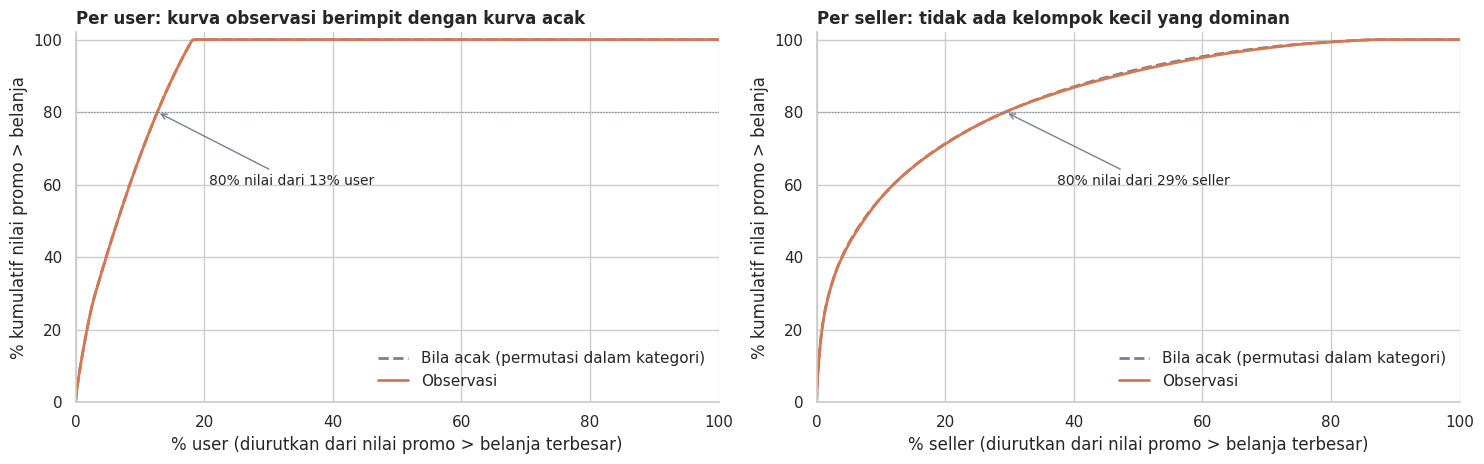

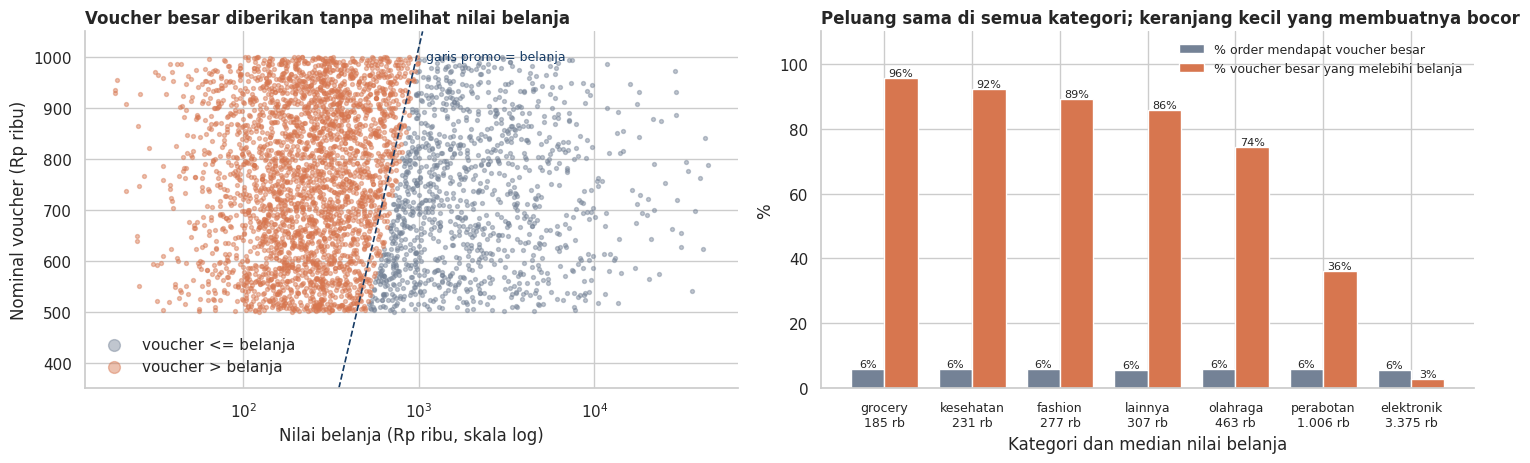

In [59]:
# 6.2 Konsentrasi transaksi promo > belanja: user, seller, voucher, tanggal (semua status, user_in_master)
pg = base.copy()
pg['promo_gt'] = pg['total_amount'].gt(0) & pg['promo_amount'].gt(pg['total_amount'])
pg['voucher_besar'] = pg['promo_amount'].ge(400_000)               # populasi nominal Rp400 rb - Rp1 jt (bagian 2.1)
pg['nilai_gt'] = np.where(pg['promo_gt'], pg['promo_amount'], 0)
p_gt = pg['promo_gt'].mean()
rng = np.random.default_rng(42)

# 1) Sumber: voucher besar (>= Rp400 rb) yang jatuh pada keranjang kecil
vb = pg.loc[pg['promo_amount'].gt(0)].groupby('voucher_besar').agg(
    order=('order_id', 'size'), promo=('promo_amount', 'sum'), promo_gt_belanja=('promo_gt', 'sum'),
    median_promo=('promo_amount', 'median'), median_belanja=('total_amount', 'median'))
vb.index = vb.index.map({False: 'promo < Rp400 rb', True: 'voucher besar >= Rp400 rb'})
vb['% order berpromo'] = vb['order'] / vb['order'].sum() * 100
vb['% anggaran promo'] = vb['promo'] / vb['promo'].sum() * 100
vb['% berakhir promo > belanja'] = vb['promo_gt_belanja'] / vb['order'] * 100
big = pg.loc[pg['voucher_besar']]
print(f"1) {pct(vb.loc['voucher besar >= Rp400 rb', 'promo_gt_belanja'] / pg['promo_gt'].sum())} transaksi promo > belanja "
      f"berasal dari voucher besar. Korelasi nominal voucher besar vs nilai belanja: r = "
      f"{big[['promo_amount', 'total_amount']].corr().iloc[0, 1]:.3f}")
display(vb.drop(columns='promo').round(1))
cat_big = pg.groupby('product_category').agg(order=('order_id', 'size'), pct_dapat_voucher_besar=('voucher_besar', 'mean'),
                                             median_belanja=('total_amount', 'median'))
cat_big['pct_voucher_besar_melebihi_belanja'] = big.groupby('product_category')['promo_gt'].mean()
cat_big['pct_order_promo_gt'] = pg.groupby('product_category')['promo_gt'].mean()
print('Per kategori: peluang mendapat voucher besar sama, tetapi keranjang kecil membuatnya melebihi belanja')
display((cat_big.sort_values('median_belanja') * [1, 100, 1, 100, 100]).round(1))

# 2) Uji konsentrasi: observasi vs bila acak
#    (a) user: jumlah user dengan >= 2 transaksi promo > belanja vs harapan binomial
n_ord_user = pg.groupby('user_id').size()
gt_user = pg.groupby('user_id')['promo_gt'].sum()
exp_ge2 = (1 - stats.binom.cdf(1, n_ord_user, p_gt)).sum()
#    (b) Pareto: porsi nilai promo > belanja pada 1% user / 10% seller teratas vs permutasi acak di dalam kategori
def top_share(values, top):
    v = np.sort(values)[::-1]; k = max(1, int(round(len(v) * top)))
    return v[:k].sum() / v.sum()
def permuted(entity, n_sim=30):
    sims = []
    for _ in range(n_sim):
        shuffled = pg.groupby('product_category')['nilai_gt'].transform(lambda s: rng.permutation(s.values))
        sims.append(shuffled.groupby(pg[entity]).sum().values)
    return sims
obs_user = pg.groupby('user_id')['nilai_gt'].sum().values
obs_seller = pg.groupby('seller_id')['nilai_gt'].sum().values
sim_user, sim_seller = permuted('user_id'), permuted('seller_id')
#    (c) seller: z-score porsi promo > belanja setelah disesuaikan kategori (acak -> SD z ±1)
pg['exp_gt'] = pg['product_category'].map(pg.groupby('product_category')['promo_gt'].mean())
sz = pg.groupby('seller_id').agg(n=('promo_gt', 'size'), obs=('promo_gt', 'mean'), exp=('exp_gt', 'mean')).query('n >= 50')
sz['z'] = (sz['obs'] - sz['exp']) / np.sqrt(sz['exp'] * (1 - sz['exp']) / sz['n'])
#    (d) tanggal: 10 tanggal dengan transaksi promo > belanja terbanyak vs porsi order pada tanggal tsb
daily = pg.groupby('order_date').agg(order=('order_id', 'size'), gt=('promo_gt', 'sum'))
top_days = daily.nlargest(10, 'gt')
conc = pd.DataFrame([
    ['User dengan >= 2 transaksi promo > belanja', f"{int(gt_user.ge(2).sum()):,}", f'{exp_ge2:,.0f}'],
    ['User dengan >= 3 transaksi promo > belanja', f"{int(gt_user.ge(3).sum()):,}",
     f"{(1 - stats.binom.cdf(2, n_ord_user, p_gt)).sum():,.0f}"],
    ['Porsi nilai pada 1% user teratas', pct(top_share(obs_user, .01)), pct(np.mean([top_share(s, .01) for s in sim_user]))],
    ['Porsi nilai pada 10% seller teratas', pct(top_share(obs_seller, .10)), pct(np.mean([top_share(s, .10) for s in sim_seller]))],
    [f'SD z-score seller (disesuaikan kategori, {len(sz)} seller >= 50 order)', f"{sz['z'].std():.2f}", '±1,00'],
    ['Seller dengan |z| > 3', f"{int(sz['z'].abs().gt(3).sum())}", f'{len(sz) * 0.0027:.1f}'],
    ['Porsi transaksi promo > belanja pada 10 tanggal teratas', pct(top_days['gt'].sum() / daily['gt'].sum()),
     pct(top_days['order'].sum() / daily['order'].sum()) + ' (porsi order pada tanggal tsb)'],
    ['Rentang tingkat promo > belanja per bulan (24 bulan)',
     ' – '.join(pct(v) for v in pg.groupby(pg['order_date'].dt.to_period('M'))['promo_gt'].mean().agg(['min', 'max'])), '-'],
], columns=['Indikator', 'Observasi', 'Bila acak'])
print('\n2) Uji konsentrasi: observasi vs harapan bila kejadian acak')
display(conc)
print('Distribusi jumlah transaksi promo > belanja per user:', gt_user[gt_user.gt(0)].value_counts().sort_index().to_dict())

# 3) Tingkat promo > belanja per dimensi (rentang sempit = tidak ada segmen yang menonjol)
dims = ['voucher_type', 'acquisition_channel', 'account_status', 'device_used', 'payment_channel_provider',
        'courier_name', 'is_official_store', 'is_campaign_period', 'order_status']
rng_rows = []
for d in dims:
    sub = pg.loc[pg['promo_amount'].gt(0)] if d == 'voucher_type' else pg   # voucher_type: hanya order berpromo
    r = sub.groupby(d, dropna=False)['promo_gt'].mean()
    rng_rows.append({'Dimensi': d, 'Terendah': f'{r.idxmin()} ({pct(r.min(), 2)})', 'Tertinggi': f'{r.idxmax()} ({pct(r.max(), 2)})'})
print('\n3) Tingkat promo > belanja per dimensi')
display(pd.DataFrame(rng_rows))

# Grafik 1: kurva Pareto observasi vs acak
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, obs, sims, label in [(axes[0], obs_user, sim_user, 'user'), (axes[1], obs_seller, sim_seller, 'seller')]:
    def curve(v):
        v = np.sort(v)[::-1]; return np.linspace(0, 100, len(v) + 1), np.r_[0, np.cumsum(v) / v.sum() * 100]
    sx, sy = curve(np.mean(np.sort(np.array(sims), axis=1)[:, ::-1], axis=0))
    ox, oy = curve(obs)
    ax.plot(sx, sy, color=GRAY, lw=2, ls='--', label='Bila acak (permutasi dalam kategori)')
    ax.plot(ox, oy, color=ORANGE, lw=2, label='Observasi')
    ax.axhline(80, color=GRAY, lw=0.8, ls=':')
    k80 = ox[np.searchsorted(oy, 80)]
    ax.annotate(f'80% nilai dari {k80:.0f}% {label}', (k80, 80), xytext=(k80 + 8, 60),
                arrowprops=dict(arrowstyle='->', color=GRAY), fontsize=10)
    ax.set_xlim(0, 100); ax.set_ylim(0, 102)
    ax.set_xlabel(f'% {label} (diurutkan dari nilai promo > belanja terbesar)'); ax.set_ylabel('% kumulatif nilai promo > belanja')
    ax.legend(frameon=False, loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
axes[0].set_title('Per user: kurva observasi berimpit dengan kurva acak', loc='left', fontweight='bold')
axes[1].set_title('Per seller: tidak ada kelompok kecil yang dominan', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

# Grafik 2: mekanisme - nominal voucher besar tidak mengikuti nilai belanja
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
smp = big.sample(min(4000, len(big)), random_state=1)
for flag, color, lab in [(False, GRAY, 'voucher <= belanja'), (True, ORANGE, 'voucher > belanja')]:
    s = smp.loc[smp['promo_gt'].eq(flag)]
    axes[0].scatter(s['total_amount'] / 1e3, s['promo_amount'] / 1e3, s=8, alpha=.45, color=color, label=lab)
axes[0].plot([350, 1050], [350, 1050], color=PRIMARY, lw=1.2, ls='--')
axes[0].text(1100, 1000, 'garis promo = belanja', color=PRIMARY, fontsize=9, ha='left', va='center')
axes[0].set_xscale('log'); axes[0].set_ylim(350, 1050)
axes[0].set_xlabel('Nilai belanja (Rp ribu, skala log)'); axes[0].set_ylabel('Nominal voucher (Rp ribu)')
axes[0].set_title('Voucher besar diberikan tanpa melihat nilai belanja', loc='left', fontweight='bold')
axes[0].legend(frameon=False, markerscale=3)
cb = cat_big.sort_values('median_belanja')
xx = np.arange(len(cb)); w = .38
b1 = axes[1].bar(xx - w / 2, cb['pct_dapat_voucher_besar'] * 100, w, color=GRAY, label='% order mendapat voucher besar')
b2 = axes[1].bar(xx + w / 2, cb['pct_voucher_besar_melebihi_belanja'] * 100, w, color=ORANGE, label='% voucher besar yang melebihi belanja')
axes[1].bar_label(b1, fmt='%.0f%%', fontsize=8); axes[1].bar_label(b2, fmt='%.0f%%', fontsize=8)
axes[1].set_xticks(xx, [f'{c}\n{rp(m)[2:-4]} rb' for c, m in zip(cb.index, cb['median_belanja'])], fontsize=9)
axes[1].set_xlabel('Kategori dan median nilai belanja')
axes[1].set_ylim(0, 110); axes[1].set_ylabel('%')
axes[1].set_title('Peluang sama di semua kategori; keranjang kecil yang membuatnya bocor', loc='left', fontweight='bold')
axes[1].legend(frameon=False, loc='upper right', fontsize=9)
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Insight:**
- **Sumbernya satu jenis promo: voucher besar (Rp400 ribu–Rp1 juta).** Voucher ini hanya ada di 10,0% order berpromo, tetapi menyerap **80,3% anggaran promo**. Sebanyak **96,4% transaksi promo > belanja** berasal dari voucher besar, dan 72,2% voucher besar berakhir melebihi nilai belanja.
- **Nominal voucher besar tidak mengikuti nilai belanja** (korelasi r = −0,01). Peluang sebuah order mendapat voucher besar hampir sama di semua kategori (5,5–6,0%). Yang membedakan hanya ukuran keranjang: voucher besar melebihi belanja pada 96% order grocery (median belanja ±Rp185 ribu), tetapi hanya 3% order elektronik (median ±Rp3,37 juta). Ini menjelaskan kenapa kategori kecil tampak "rakus promo" pada pertanyaan 2.
- **Tidak ada tanda konsentrasi.** Kurva Pareto observasi berimpit dengan kurva acak:
  - User dengan ≥ 2 transaksi promo > belanja ada 1.545, sedangkan harapan bila acak 1.542; untuk ≥ 3 transaksi 232 vs 251.
  - 1% user teratas memegang 12,7% nilai (acak: 12,7%), dan 10% seller teratas 56,4% (acak: 56,4%).
  - Setelah disesuaikan kategori, sebaran z-score seller (SD 0,94) setara acak, dengan hanya 4 seller |z| > 3 (harapan 2,9).
  - 10 tanggal teratas memuat 12,9% transaksi, setara porsi order pada tanggal tersebut (12,2%). Tingkatnya stabil 3,9–4,9% per bulan.
  - Akun `suspended` tidak lebih sering (4,22%). Perbedaan yang terlihat hanya antar jenis voucher (free_ongkir 6,2% vs diskon_persen 8,4% dari order berpromo).
- **Kesimpulan:** pola ini **tidak konsisten dengan penyalahgunaan oleh sekelompok akun atau seller**. Pola ini konsisten dengan **aturan voucher yang sistemik**: voucher bernominal besar diterbitkan tanpa syarat minimum belanja atau batas persentase, sehingga bocor setiap kali jatuh pada keranjang kecil. Karena itu tindakan yang tepat adalah **perbaikan aturan voucher** (minimum belanja dan batas promo ≤ nilai belanja), bukan audit akun satu per satu. Audit cukup diarahkan ke konfigurasi kampanye yang menerbitkan voucher ≥ Rp400 ribu.

###  6.3 Bukti Service Recovery: Apakah Penanganan Keluhan Memulihkan Retensi?
Rekomendasi #2 (voucher pemulihan) dan #3 (notifikasi proaktif) mengasumsikan bahwa pengalaman buruk masih dapat dipulihkan. Bagian ini menguji asumsi tersebut pada pengguna kohort 60 hari yang **order pertamanya terlambat dan membuat tiket** dalam 7 hari setelah barang diterima (desain *landmark* yang sama dengan pertanyaan 4). Repeat diukur pada hari 8–60. Pembandingnya:
1. status tiket: `resolved` vs belum selesai (`pending`/`escalated`), serta pengguna terlambat tanpa tiket;
2. kecepatan penyelesaian (tiket `resolved`): di bawah vs di atas median `resolution_time_hours`;
3. skor CSAT (tiket `resolved`): 1–2, 3, 4–5, dan tidak mengisi.

Bila tiket yang cepat selesai atau ber-CSAT tinggi memiliki repeat lebih tinggi, ada dasar data bahwa *service recovery* dapat menutup sebagian gap. Catatan: penanganan tiket tidak acak (mis. kasus sulit cenderung lebih lama), sehingga hasilnya tetap asosiasi.

Pengguna dengan order pertama terlambat (landmark): 10,803 | dengan tiket 7 hari: 1,800 | pembanding: tepat waktu tanpa tiket 72.2%

1) Repeat hari 8-60 menurut status tiket


,user,repeat,repeat_8_60,CI low,CI high
status_tiket,,,,,
tanpa tiket,9003,5662,0.6289,0.6189,0.6388
tiket resolved,1455,443,0.3045,0.2814,0.3286
tiket belum selesai (pending/escalated),345,96,0.2783,0.2336,0.3278



2) Tiket resolved: repeat menurut kecepatan penyelesaian


,user,repeat,repeat_8_60,CI low,CI high
kecepatan,,,,,
cepat (<= 19.1 jam),729,303,0.4156,0.3804,0.4518
lambat (> 19.1 jam),726,140,0.1928,0.1658,0.2231


3) Tiket resolved: repeat menurut skor CSAT


,user,repeat,repeat_8_60,CI low,CI high
csat,,,,,
CSAT 1-2,603,125,0.2073,0.1768,0.2415
CSAT 3,353,126,0.3569,0.3087,0.4082
CSAT 4-5,271,138,0.5092,0.4500,0.5682
tidak mengisi CSAT,228,54,0.2368,0.1863,0.2961


Sebaran kategori keluhan pada pengguna terlambat yang membuat tiket:


,tiket
complaint_category,
keterlambatan,1297
produk_rusak,168
refund,146
lainnya,103
kurir_kasar,86



Perbandingan:
Resolved vs belum selesai: 30.4% vs 27.8% -> +2.62 pp (95% CI -2.84 s.d. +7.70); p = 0.339
Cepat vs lambat: 41.6% vs 19.3% -> +22.28 pp (95% CI +17.63 s.d. +26.79); p = 2.61e-20
CSAT 4-5 vs CSAT 1-2: 50.9% vs 20.7% -> +30.19 pp (95% CI +23.36 s.d. +36.83); p = 2.23e-19
Resolved vs terlambat tanpa tiket: 30.4% vs 62.9% -> -32.44 pp (95% CI -34.96 s.d. -29.83); p = 5.13e-120


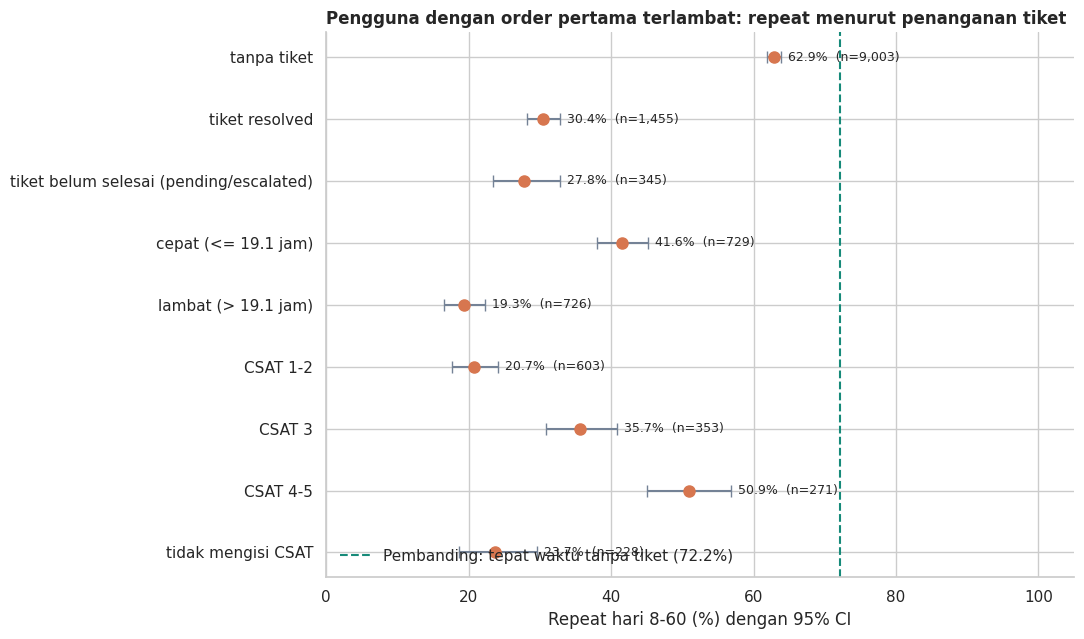

In [60]:
# 6.3 Service recovery: repeat hari 8-60 menurut penanganan tiket pada pengguna dengan order pertama terlambat
sr = cohort60.loc[~cohort60['repeat_days'].between(1, 7)].copy()          # landmark: keluarkan yang sudah repeat di hari 1-7
sr['repeat_8_60'] = sr['repeat_days'].between(8, 60).astype(int)

tk_sr = tickets.merge(sr[['order_id', 'order_date', 'delivery_date']], on='order_id')
tk_sr = tk_sr.loc[tk_sr['ticket_date'].ge(tk_sr['order_date'])
                  & tk_sr['ticket_date'].le(tk_sr['delivery_date'] + pd.Timedelta(days=7))]
tk_sr = tk_sr.sort_values(['order_id', 'ticket_date', 'ticket_id']).drop_duplicates('order_id')   # tiket pertama per order
sr = sr.merge(tk_sr[['order_id', 'complaint_category', 'resolution_status', 'resolution_time_hours', 'csat_score']],
              on='order_id', how='left')
late_sr = sr.loc[sr['late_delivery'].eq(1)].copy()
ontime_rate = sr.loc[sr['late_delivery'].eq(0) & sr['resolution_status'].isna(), 'repeat_8_60'].mean()

def grp_table(df, col, order=None):
    g = df.groupby(col, observed=True)['repeat_8_60'].agg(['size', 'sum', 'mean'])
    if order is not None: g = g.reindex([o for o in order if o in g.index])
    ci = [wilson(r['sum'], r['size']) for _, r in g.iterrows()]
    g['CI low'], g['CI high'] = [c[0] for c in ci], [c[1] for c in ci]
    return g.rename(columns={'size': 'user', 'sum': 'repeat', 'mean': 'repeat_8_60'})

# 1) Status tiket
late_sr['status_tiket'] = np.select(
    [late_sr['resolution_status'].isna().to_numpy(bool),
     late_sr['resolution_status'].eq('resolved').fillna(False).to_numpy(bool)],
    ['tanpa tiket', 'tiket resolved'], 'tiket belum selesai (pending/escalated)')
t_status = grp_table(late_sr, 'status_tiket', ['tanpa tiket', 'tiket resolved', 'tiket belum selesai (pending/escalated)'])
print(f'Pengguna dengan order pertama terlambat (landmark): {len(late_sr):,} | dengan tiket 7 hari: '
      f"{int(late_sr['resolution_status'].notna().sum()):,} | pembanding: tepat waktu tanpa tiket {pct(ontime_rate)}")
print('\n1) Repeat hari 8-60 menurut status tiket')
display(t_status.round(4))

# 2) Kecepatan penyelesaian & 3) CSAT (hanya tiket resolved)
res = late_sr.loc[late_sr['status_tiket'].eq('tiket resolved')].copy()
results = {}
if len(res) >= 30:
    med_h = res['resolution_time_hours'].median()
    res['kecepatan'] = np.where(res['resolution_time_hours'].le(med_h), f'cepat (<= {med_h:.1f} jam)', f'lambat (> {med_h:.1f} jam)')
    res['csat'] = pd.cut(res['csat_score'].astype('float64'), [0, 2, 3, 5], labels=['CSAT 1-2', 'CSAT 3', 'CSAT 4-5'])
    res['csat'] = res['csat'].astype('object').fillna('tidak mengisi CSAT')
    t_speed = grp_table(res, 'kecepatan', sorted(res['kecepatan'].unique()))
    t_csat = grp_table(res, 'csat', ['CSAT 1-2', 'CSAT 3', 'CSAT 4-5', 'tidak mengisi CSAT'])
    print('\n2) Tiket resolved: repeat menurut kecepatan penyelesaian')
    display(t_speed.round(4))
    print('3) Tiket resolved: repeat menurut skor CSAT')
    display(t_csat.round(4))
    print('Sebaran kategori keluhan pada pengguna terlambat yang membuat tiket:')
    display(late_sr['complaint_category'].value_counts().rename('tiket').to_frame())

    # Uji perbandingan utama
    def cmp(tab, a, b, label):
        if a in tab.index and b in tab.index:
            t = two_prop(tab.loc[a, 'repeat'], tab.loc[a, 'user'], tab.loc[b, 'repeat'], tab.loc[b, 'user'])
            results[label] = t
            print(f"{label}: {pct(t['p_a'])} vs {pct(t['p_b'])} -> {t['diff']*100:+.2f} pp "
                  f"(95% CI {t['low']*100:+.2f} s.d. {t['high']*100:+.2f}); p = {t['p']:.3g}")
    print('\nPerbandingan:')
    cmp(t_status, 'tiket resolved', 'tiket belum selesai (pending/escalated)', 'Resolved vs belum selesai')
    cmp(t_speed, t_speed.index[0], t_speed.index[1], 'Cepat vs lambat')
    cmp(t_csat, 'CSAT 4-5', 'CSAT 1-2', 'CSAT 4-5 vs CSAT 1-2')
    cmp(t_status, 'tiket resolved', 'tanpa tiket', 'Resolved vs terlambat tanpa tiket')

    # Grafik
    plot_tab = pd.concat([t_status, t_speed, t_csat])
    plot_tab = plot_tab.loc[~plot_tab.index.duplicated()]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(plot_tab) + 1.6))
    yy = np.arange(len(plot_tab))
    ax.errorbar(plot_tab['repeat_8_60'] * 100, yy,
                xerr=[(plot_tab['repeat_8_60'] - plot_tab['CI low']) * 100, (plot_tab['CI high'] - plot_tab['repeat_8_60']) * 100],
                fmt='o', color=ORANGE, ecolor=GRAY, capsize=4, ms=8)
    for y, (_, r) in zip(yy, plot_tab.iterrows()):
        ax.text(r['CI high'] * 100 + 1, y, f"{r['repeat_8_60']*100:.1f}%  (n={int(r['user']):,})", va='center', fontsize=9)
    ax.axvline(ontime_rate * 100, color=TEAL, ls='--', label=f'Pembanding: tepat waktu tanpa tiket ({pct(ontime_rate)})')
    ax.legend(frameon=False, loc='lower left')
    ax.set_yticks(yy, plot_tab.index); ax.invert_yaxis(); ax.set_xlim(0, 105)
    ax.set_xlabel('Repeat hari 8-60 (%) dengan 95% CI'); ax.spines[['top', 'right']].set_visible(False)
    ax.set_title('Pengguna dengan order pertama terlambat: repeat menurut penanganan tiket', loc='left', fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print('Tiket resolved pada pengguna terlambat < 30 - perbandingan kecepatan & CSAT tidak ditampilkan.')

**Insight:**
- **Pengguna terlambat yang membuat tiket jauh lebih jarang kembali.** Dari 10.803 pengguna terlambat pada landmark, 1.800 membuat tiket dalam 7 hari (1.297 di antaranya keluhan keterlambatan). Repeat hari 8–60 kelompok tiket *resolved* hanya **30,4%**, dibanding **62,9%** tanpa tiket (−32,4 pp, p < 0,001) dan 72,2% pada pengguna tepat waktu tanpa tiket. Membuat tiket adalah penanda pengguna yang paling kecewa, sehingga kelompok ini adalah sasaran utama service recovery.
- **Status *resolved* saja tidak memulihkan pengguna.** Repeat tiket *resolved* (30,4%) tidak berbeda bermakna dari tiket yang belum selesai (27,8%): selisih +2,6 pp, 95% CI −2,8 s.d. +7,7, p = 0,339. Menutup tiket tanpa memperbaiki pengalaman tidak cukup.
- **Kecepatan dan kualitas penanganan berasosiasi kuat dengan repeat.** Tiket yang selesai cepat (≤ 19,1 jam, median) memiliki repeat **41,6%** vs **19,3%** untuk yang lambat (+22,3 pp, CI +17,6 s.d. +26,8). Pengguna dengan CSAT 4–5 kembali **50,9%** vs **20,7%** pada CSAT 1–2 (+30,2 pp, CI +23,4 s.d. +36,8). Pengguna yang tidak mengisi CSAT (228) hanya 23,7%, mendekati kelompok CSAT rendah.
- **Hasil validasi (6.3a): selisih kecepatan dan CSAT berasal dari keparahan kasus, bukan dari penanganan.** Setelah dibandingkan di dalam kategori keluhan dan lama keterlambatan yang sama, selisih cepat vs lambat turun dari +22,3 pp menjadi +0,5 pp (p = 0,84), dan CSAT 4–5 vs 1–2 dari +30,2 pp menjadi +3,4 pp (p = 0,39). Penanganan tiket yang lebih cepat atau lebih memuaskan tidak terlihat memulihkan pengguna. *Service recovery* harus menyasar pengalaman pengirimannya: mencegah keterlambatan berat, memastikan order berikutnya tepat waktu (bagian 6.4), dan voucher pemulihan.


####  6.3a Validasi 1: Mengontrol Keparahan Kasus
Selisih cepat vs lambat (+22,3 pp) dan CSAT 4–5 vs 1–2 (+30,2 pp) di 6.3 bisa saja sebagian berasal dari **keparahan kasus**, bukan dari penanganannya. Kasus berat cenderung lebih lama selesai, diberi CSAT rendah, dan memang lebih jarang kembali. Validasi ini menguji seberapa besar selisih yang tersisa setelah keparahan dikontrol, dalam dua langkah:
1. **Cek pemicu bias:** apakah kategori keluhan dan lama keterlambatan (hari lewat SLA: 1, 2, 3–5, > 5) berkaitan dengan kecepatan penyelesaian dan CSAT. Bila ya, perbandingan mentah memang bercampur dengan keparahan.
2. **Perbandingan dalam strata yang sama:** cepat vs lambat dibandingkan di dalam kombinasi kategori keluhan × lama keterlambatan yang sama, lalu digabung dengan bobot Mantel–Haenszel. Ditampilkan juga rincian khusus keluhan keterlambatan.

Cara membaca: bila selisih yang tersisa masih besar dan signifikan, kecepatan/CSAT kemungkinan memang berperan. Bila selisih menyusut jauh, sebagian besar selisih mentah adalah efek keparahan kasus. Validasi ini tetap hanya mengontrol variabel yang tercatat; faktor seperti nada komunikasi agen atau kompensasi yang diberikan tidak teramati, sehingga bukti sebab-akibat tetap memerlukan pilot pada 6.3b.


Pengguna terlambat dengan tiket resolved yang dianalisis: 1,455 | ambang cepat: <= 19.1 jam

Langkah 1 - Keparahan kasus vs kecepatan penyelesaian, CSAT, dan repeat

kategori_keluhan: chi-square porsi cepat p = 1.56e-47 | Kruskal-Wallis jam penyelesaian p = 4.93e-55


,user,median_jam,porsi_cepat,rata_csat,repeat_8_60
kategori_keluhan,,,,,
keterlambatan,1043,26.4,0.379,2.185,0.183
kurir_kasar,74,9.0,0.824,3.426,0.581
lainnya,82,9.05,0.732,3.584,0.524
produk_rusak,135,7.5,0.874,3.617,0.644
refund,121,7.8,0.785,3.509,0.653



lewat_sla: chi-square porsi cepat p = 6.09e-103 | Kruskal-Wallis jam penyelesaian p = 2.94e-111


,user,median_jam,porsi_cepat,rata_csat,repeat_8_60
lewat_sla,,,,,
1 hari,526,8.8,0.831,2.985,0.498
2 hari,201,15.9,0.622,2.482,0.274
3-5 hari,25,14.9,0.680,2.591,0.160
> 5 hari,703,37.4,0.213,2.318,0.174



Langkah 2a - Hanya keluhan keterlambatan: cepat vs lambat per lama keterlambatan


,Lewat SLA,n cepat,n lambat,repeat cepat,repeat lambat,selisih (pp),CI low,CI high,p
0,1 hari,151,75,0.2119,0.1867,2.5254,-9.2434,12.7075,0.6570
1,2 hari,102,71,0.1863,0.2535,-6.7247,-19.6087,5.5184,0.2886
2,3-5 hari,11,7,0.0000,0.1429,-14.2857,-51.3128,14.1264,0.1971
3,> 5 hari,131,495,0.1756,0.1697,0.5876,-6.0164,8.6023,0.8738



Langkah 2b - Selisih repeat hari 8-60 sebelum dan sesudah kontrol keparahan


,Perbandingan,Metode,Selisih (pp),CI low,CI high,p,Tersisa dari selisih mentah (%)
0,Cepat vs lambat,1. Mentah,22.280,17.633,26.793,0.000,100.000
1,Cepat vs lambat,2. Dalam strata kategori x lewat SLA (MH),0.520,-4.550,5.590,0.841,2.334
2,CSAT 4-5 vs CSAT 1-2,1. Mentah,30.193,23.355,36.830,0.000,100.000
3,CSAT 4-5 vs CSAT 1-2,2. Dalam strata kategori x lewat SLA (MH),3.395,-4.333,11.122,0.389,11.243


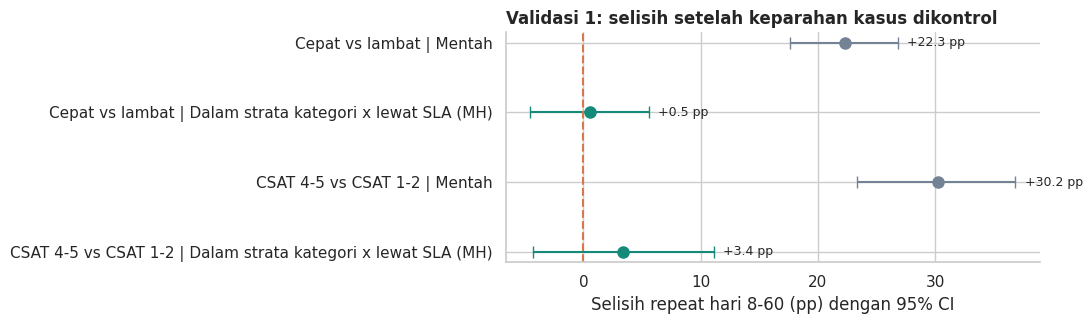

In [61]:
# 6.3a Validasi 1: apakah selisih cepat vs lambat dan CSAT tinggi vs rendah bertahan setelah keparahan kasus dikontrol?
# Populasi: pengguna dengan order pertama terlambat yang tiketnya resolved (objek `res` dan `med_h` dari sel 6.3)
va = res.copy()
va['cepat'] = va['resolution_time_hours'].astype('float64').le(med_h).astype(int)
va['lewat_sla'] = pd.cut(va['days_over_sla'].astype('float64'), [0, 1, 2, 5, np.inf],
                         labels=['1 hari', '2 hari', '3-5 hari', '> 5 hari'])
va['kategori_keluhan'] = va['complaint_category'].astype('object')
va = va.loc[va['lewat_sla'].notna()].copy()
print(f'Pengguna terlambat dengan tiket resolved yang dianalisis: {len(va):,} | ambang cepat: <= {med_h:.1f} jam')

# Langkah 1: apakah keparahan kasus berkaitan dengan kecepatan penyelesaian dan CSAT?
def sev_table(col):
    g = va.groupby(col, observed=True).agg(
        user=('user_id', 'size'), median_jam=('resolution_time_hours', 'median'),
        porsi_cepat=('cepat', 'mean'), rata_csat=('csat_score', lambda s: s.astype('float64').mean()),
        repeat_8_60=('repeat_8_60', 'mean'))
    p_speed = stats.chi2_contingency(pd.crosstab(va[col], va['cepat'])).pvalue
    p_hours = stats.kruskal(*[d['resolution_time_hours'].astype('float64').dropna() for _, d in va.groupby(col, observed=True)]).pvalue
    print(f'\n{col}: chi-square porsi cepat p = {p_speed:.3g} | Kruskal-Wallis jam penyelesaian p = {p_hours:.3g}')
    display(g.round(3))
    return g
print('\nLangkah 1 - Keparahan kasus vs kecepatan penyelesaian, CSAT, dan repeat')
sev_cat = sev_table('kategori_keluhan')
sev_late = sev_table('lewat_sla')

# Langkah 2: perbandingan di dalam strata yang sama (kategori keluhan x lama keterlambatan), bobot Mantel-Haenszel
def mh_diff(df, treat, strata):
    num = wsum = var = 0.0; used = 0
    for _, d in df.groupby(strata, observed=True):
        a, b = d.loc[d[treat].eq(1), 'repeat_8_60'], d.loc[d[treat].eq(0), 'repeat_8_60']
        n1, n0 = len(a), len(b)
        if n1 == 0 or n0 == 0: continue                      # strata tanpa pembanding tidak dipakai
        p1, p0 = a.mean(), b.mean(); w = n1 * n0 / (n1 + n0)
        num += w * (p1 - p0); wsum += w; var += w**2 * (p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0); used += n1 + n0
    rd, se = num / wsum, np.sqrt(var) / wsum
    return dict(diff=rd, low=rd - 1.959964 * se, high=rd + 1.959964 * se, p=2 * stats.norm.sf(abs(rd / se)), n=used)

strata = ['kategori_keluhan', 'lewat_sla']
va_csat = va.loc[va['csat'].isin(['CSAT 4-5', 'CSAT 1-2'])].copy()
va_csat['csat_tinggi'] = va_csat['csat'].eq('CSAT 4-5').astype(int)

print('\nLangkah 2a - Hanya keluhan keterlambatan: cepat vs lambat per lama keterlambatan')
rows = []
for k, d in va.loc[va['kategori_keluhan'].eq('keterlambatan')].groupby('lewat_sla', observed=True):
    a, b = d.loc[d['cepat'].eq(1), 'repeat_8_60'], d.loc[d['cepat'].eq(0), 'repeat_8_60']
    if len(a) and len(b):
        t = two_prop(a.sum(), len(a), b.sum(), len(b))
        rows.append({'Lewat SLA': k, 'n cepat': len(a), 'n lambat': len(b), 'repeat cepat': t['p_a'], 'repeat lambat': t['p_b'],
                     'selisih (pp)': t['diff'] * 100, 'CI low': t['low'] * 100, 'CI high': t['high'] * 100, 'p': t['p']})
display(pd.DataFrame(rows).round(4))

checks = {'Cepat vs lambat': (va, 'cepat'), 'CSAT 4-5 vs CSAT 1-2': (va_csat, 'csat_tinggi')}
val_rows = []
for label, (d, treat) in checks.items():
    raw = two_prop(d.loc[d[treat].eq(1), 'repeat_8_60'].sum(), int(d[treat].sum()),
                   d.loc[d[treat].eq(0), 'repeat_8_60'].sum(), int((1 - d[treat]).sum()))
    est = {'1. Mentah': raw, '2. Dalam strata kategori x lewat SLA (MH)': mh_diff(d, treat, strata)}
    for method, e in est.items():
        val_rows.append({'Perbandingan': label, 'Metode': method, 'Selisih (pp)': e['diff'] * 100,
                         'CI low': e['low'] * 100, 'CI high': e['high'] * 100, 'p': e['p'],
                         'Tersisa dari selisih mentah (%)': e['diff'] / raw['diff'] * 100})
val63 = pd.DataFrame(val_rows)
print('\nLangkah 2b - Selisih repeat hari 8-60 sebelum dan sesudah kontrol keparahan')
display(val63.round(3))

fig, ax = plt.subplots(figsize=(11, 3.4))
yy = np.arange(len(val63))
cols = [GRAY if m.startswith('1') else TEAL for m in val63['Metode']]
for y, (_, r), c in zip(yy, val63.iterrows(), cols):
    ax.errorbar(r['Selisih (pp)'], y, xerr=[[r['Selisih (pp)'] - r['CI low']], [r['CI high'] - r['Selisih (pp)']]],
                fmt='o', color=c, ecolor=c, capsize=4, ms=8)
    ax.text(r['CI high'] + 0.8, y, f"{r['Selisih (pp)']:+.1f} pp", va='center', fontsize=9)
ax.axvline(0, color=ORANGE, ls='--')
ax.set_yticks(yy, [f"{p} | {m[3:]}" for p, m in zip(val63['Perbandingan'], val63['Metode'])]); ax.invert_yaxis()
ax.set_xlabel('Selisih repeat hari 8-60 (pp) dengan 95% CI'); ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Validasi 1: selisih setelah keparahan kasus dikontrol', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()


**Insight:**
- **Keparahan kasus memang memicu bias.** Keluhan keterlambatan (1.043 dari 1.455 tiket *resolved*) diselesaikan jauh lebih lambat (median 26,4 jam; hanya 37,9% tergolong cepat) dibanding keluhan lain (median 7,5–9,1 jam; 73–87% cepat), dengan CSAT rata-rata lebih rendah (2,19 vs 3,43–3,62) dan repeat paling rendah (18,3% vs 52–65%). Pola yang sama muncul menurut lama keterlambatan: lewat 1 hari median 8,8 jam dan repeat 49,8%, sedangkan lewat > 5 hari median 37,4 jam dan repeat 17,4%. Semua perbedaan ini signifikan (p < 0,001).
- **Setelah keparahan dikontrol, selisihnya hampir hilang.** Cepat vs lambat turun dari +22,3 pp menjadi **+0,5 pp** (95% CI −4,6 s.d. +5,6; p = 0,84), hanya 2% dari selisih mentah. CSAT 4–5 vs 1–2 turun dari +30,2 pp menjadi **+3,4 pp** (95% CI −4,3 s.d. +11,1; p = 0,39). Pada keluhan keterlambatan saja, tiket cepat dan lambat juga tidak berbeda di setiap lama keterlambatan (semua p > 0,19).
- **Implikasi:** peluang kembali ditentukan oleh **seberapa berat kegagalan pengirimannya**, bukan oleh kecepatan atau kepuasan penanganan tiket. Mempercepat tiket saja kemungkinan kecil menaikkan retensi. Rekomendasi pemulihan diarahkan pada pengalaman pengiriman: mencegah ekor keterlambatan berat (bagian 6.5), memastikan order berikutnya tepat waktu (bagian 6.4), dan voucher pemulihan untuk kasus berat.
- Keterbatasan: hanya kategori keluhan dan lama keterlambatan yang dikontrol; faktor seperti kompensasi yang diberikan agen tidak tercatat.


####  6.3b Validasi 2: Desain Pilot A/B Prioritas Penanganan Tiket Keterlambatan
Data historis tidak dapat membuktikan bahwa **mempercepat** penanganan menaikkan repeat, karena kecepatan tidak pernah diberikan secara acak. Bukti sebab-akibat memerlukan pilot. Sel di bawah menyiapkan desainnya dari data historis: baseline, ukuran sampel, durasi, mekanisme pengacakan, fungsi analisis, dan uji A/A untuk memastikan prosedur pengacakan dan analisis tidak menghasilkan positif palsu berlebih.

| Komponen | Desain |
|---|---|
| Hipotesis | Tiket keterlambatan yang diselesaikan lebih cepat menaikkan repeat hari 8–60 |
| Populasi | Pengguna dengan order terlambat yang membuat tiket keterlambatan dalam 7 hari setelah barang diterima. Analisis utama pada order pertama; perluasan ke semua order menambah volume |
| Unit pengacakan | Pengguna (tiket pertama selama pilot), dibagi 50:50 dengan hash `user_id` agar konsisten dan dapat diaudit |
| Perlakuan | Antrean prioritas dengan target selesai ≤ median historis (lihat output 6.3) |
| Kontrol | Penanganan seperti biasa |
| Metrik utama | Repeat hari 8–60 (definisi sama dengan 6.3) |
| Metrik pendukung | Jam penyelesaian (cek kepatuhan perlakuan), status resolved, CSAT |
| Guardrail | Waktu penyelesaian tiket non-pilot, beban agen, biaya penanganan |
| Aturan analisis | Satu kali di akhir follow-up (tanpa mengintip hasil di tengah), uji dua proporsi dua sisi α = 5%, cek *sample ratio mismatch* (SRM) |
| Durasi | Masa rekrutmen sesuai tabel ukuran sampel + 60 hari follow-up |


Populasi historis: 1,297 pengguna | repeat hari 8-60 (kondisi saat ini / kontrol) = 18.0% | belum selesai cepat (<= 19.1 jam): 69.5%
Volume per bulan: (a) order pertama 56 pengguna | (b) semua order terlambat 318 pengguna

Ukuran sampel dan durasi rekrutmen (ditambah 60 hari follow-up untuk mengukur repeat)


,Skenario kenaikan (MDE),MDE (pp),n per kelompok,n total,Bulan rekrutmen (a) order pertama,Bulan rekrutmen (b) semua order
0,+3 pp,3.0,2733,5466,96.9,17.2
1,+5 pp,5.0,1021,2042,36.2,6.4
2,+10 pp,10.0,277,554,9.8,1.7



Uji A/A (1.000 pengacakan): rata-rata selisih -0.01 pp | positif palsu (p < 0,05) 5.0% | SRM p < 0,01: 1.7%


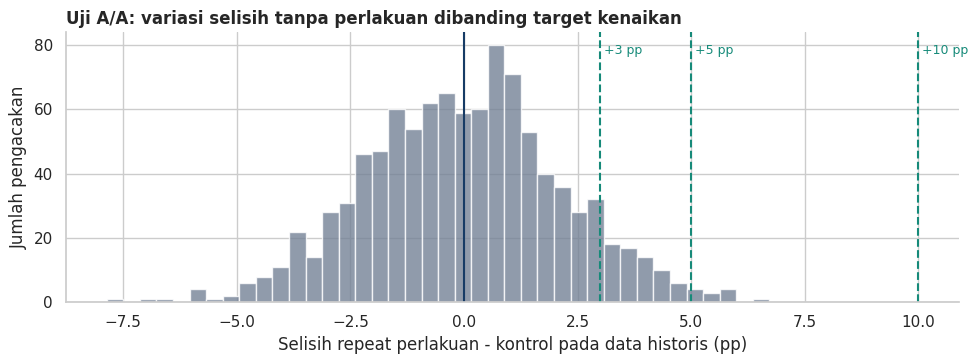

In [62]:
# 6.3b Validasi 2: desain pilot A/B antrean prioritas tiket keterlambatan (ukuran sampel, durasi, uji A/A)
import hashlib

# Populasi target: pengguna dengan order pertama terlambat yang membuat tiket keterlambatan dalam 7 hari (objek `late_sr` dari 6.3)
elig = late_sr.loc[late_sr['complaint_category'].eq('keterlambatan')].copy()
p0_pilot = elig['repeat_8_60'].mean()
elig_res = elig['resolution_status'].eq('resolved').fillna(False)
porsi_bukan_cepat = 1 - (elig_res & elig['resolution_time_hours'].astype('float64').le(med_h)).mean()
print(f'Populasi historis: {len(elig):,} pengguna | repeat hari 8-60 (kondisi saat ini / kontrol) = {pct(p0_pilot)} | '
      f'belum selesai cepat (<= {med_h:.1f} jam): {pct(porsi_bukan_cepat)}')

# Volume per bulan: (a) order pertama saja (kohort 60 hari), (b) semua order completed yang terlambat
months_a = elig['delivery_date'].dt.to_period('M').nunique()
vol_a = len(elig) / months_a
lo = base.loc[base['order_status'].eq('completed') & base['late_delivery'].eq(1), ['order_id', 'user_id', 'delivery_date']]
tk_all = tickets.loc[tickets['complaint_category'].eq('keterlambatan'), ['order_id', 'ticket_date']].merge(lo, on='order_id')
tk_all = tk_all.loc[tk_all['ticket_date'].le(tk_all['delivery_date'] + pd.Timedelta(days=7))]
tk_all['bulan'] = tk_all['delivery_date'].dt.to_period('M')
vol_b = tk_all.drop_duplicates(['user_id', 'bulan']).groupby('bulan').size().mean()
print(f'Volume per bulan: (a) order pertama {vol_a:,.0f} pengguna | (b) semua order terlambat {vol_b:,.0f} pengguna')

# Ukuran sampel per kelompok (uji dua proporsi dua sisi, alpha 5%, power 80%)
def n_per_arm(p0, mde, alpha=0.05, power=0.80):
    p1 = p0 + mde; pbar = (p0 + p1) / 2
    za, zb = stats.norm.isf(alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1)))**2 / mde**2))

skenario = {'+3 pp': 0.03, '+5 pp': 0.05, '+10 pp': 0.10}
rows = []
for k, mde in skenario.items():
    n = n_per_arm(p0_pilot, mde)
    rows.append({'Skenario kenaikan (MDE)': k, 'MDE (pp)': mde * 100, 'n per kelompok': n, 'n total': 2 * n,
                 'Bulan rekrutmen (a) order pertama': 2 * n / vol_a, 'Bulan rekrutmen (b) semua order': 2 * n / vol_b})
pilot_size = pd.DataFrame(rows)
print('\nUkuran sampel dan durasi rekrutmen (ditambah 60 hari follow-up untuk mengukur repeat)')
display(pilot_size.round(1))

# Penugasan acak deterministik per pengguna (hash), dipakai saat tiket pertama masuk
def assign_arm(user_id, salt='pilot_tiket_keterlambatan'):
    h = int(hashlib.sha256(f'{salt}:{user_id}'.encode()).hexdigest(), 16)
    return 'perlakuan' if h % 2 else 'kontrol'

def analyze_pilot(df, arm='arm', outcome='repeat_8_60'):
    """Analisis utama pilot: selisih repeat perlakuan - kontrol, plus cek sample ratio mismatch (SRM)."""
    t, c = df.loc[df[arm].eq('perlakuan'), outcome], df.loc[df[arm].eq('kontrol'), outcome]
    res_ = two_prop(t.sum(), len(t), c.sum(), len(c))
    res_['p_srm'] = stats.chisquare([len(t), len(c)]).pvalue
    return res_

# Uji A/A pada data historis: tanpa perlakuan, selisih harus ~0 dan positif palsu ~5%
aa = []
for i in range(1000):
    d = elig[['user_id', 'repeat_8_60']].copy()
    d['arm'] = [assign_arm(u, salt=f'aa{i}') for u in d['user_id']]
    aa.append(analyze_pilot(d))
aa = pd.DataFrame(aa)
print(f"\nUji A/A (1.000 pengacakan): rata-rata selisih {aa['diff'].mean()*100:+.2f} pp | "
      f"positif palsu (p < 0,05) {pct((aa['p'] < 0.05).mean())} | SRM p < 0,01: {pct((aa['p_srm'] < 0.01).mean())}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(aa['diff'] * 100, bins=40, color=GRAY, alpha=0.8)
for k, mde in list(skenario.items())[:3]:
    ax.axvline(mde * 100, color=TEAL, ls='--'); ax.text(mde * 100, ax.get_ylim()[1] * 0.92, f' {k}', color=TEAL, fontsize=9)
ax.axvline(0, color=PRIMARY)
ax.set_xlabel('Selisih repeat perlakuan - kontrol pada data historis (pp)'); ax.set_ylabel('Jumlah pengacakan')
ax.spines[['top', 'right']].set_visible(False)
ax.set_title('Uji A/A: variasi selisih tanpa perlakuan dibanding target kenaikan', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()


**Insight:**
- **Baseline pilot:** 1.297 pengguna dengan order pertama terlambat yang mengeluhkan keterlambatan, repeat hari 8–60 hanya **18,0%**. Volumenya ±56 pengguna per bulan bila hanya order pertama, atau ±318 pengguna per bulan bila mencakup semua order terlambat.
- **Ukuran sampel (α 5%, power 80%):** kenaikan +10 pp membutuhkan 277 pengguna per kelompok (±9,8 bulan rekrutmen untuk order pertama, atau ±1,7 bulan untuk semua order); +5 pp membutuhkan 1.021 per kelompok (±36,2 vs ±6,4 bulan); +3 pp membutuhkan 2.733 per kelompok (±96,9 vs ±17,2 bulan). Pilot hanya realistis bila populasinya diperluas ke semua order terlambat, ditambah 60 hari follow-up.
- **Prosedur pengacakan dan analisis dapat dipercaya:** pada 1.000 pengacakan data historis tanpa perlakuan, rata-rata selisih −0,01 pp dan positif palsu 5,0% (sesuai α 5%). Ketidakseimbangan jumlah kelompok (SRM p < 0,01) muncul pada 1,7% pengacakan, mendekati 1% yang diharapkan, sehingga cek SRM tetap wajib saat pilot berjalan.
- **Prioritas:** hasil 6.3a menunjukkan efek mempercepat tiket kemungkinan kecil, sehingga pilot antrean prioritas tiket **bukan prioritas utama**. Kerangka yang sama (pengacakan hash per pengguna, metrik repeat hari 8–60, analisis satu kali di akhir, cek SRM) lebih tepat dipakai untuk pilot rekomendasi #2 (voucher pemulihan + order berikutnya tepat waktu) dan #3 (estimasi tiba realistis).


###  6.4 Efek Bertumpuk: Apakah Kerusakan Berhenti Setelah Satu Keterlambatan?
Analisis kohort sebelumnya hanya melihat order pertama. Bagian ini mengikuti pengguna yang sudah melakukan **order kedua**: order pertama yang teramati dan order completed kedua sama-sama `delivered` dengan durasi & SLA valid, serta barang kedua diterima paling lambat 60 hari sebelum akhir data. Hasilnya adalah repeat ke **order ketiga**, yaitu order completed dengan `order_date` setelah barang kedua diterima dan paling lambat 60 hari sesudahnya. Hasil ini dibandingkan menurut jumlah keterlambatan pada dua order pertama (0, 1, 2) dan menurut kombinasinya (order mana yang terlambat).

Pengguna dengan dua order pertama delivered & follow-up 60 hari setelah order kedua: 28,362

1) Repeat ke order ketiga menurut jumlah keterlambatan pada dua order pertama


,user,repeat_order_3
jumlah_terlambat,,
0,12795,0.7966
1,12424,0.7281
2,3143,0.6624


2) Repeat ke order ketiga menurut pola keterlambatan


,user,repeat,repeat_order_3
pola,,,
order 1 tepat waktu | order 2 tepat waktu,12795,10192,0.7966
order 1 terlambat | order 2 tepat waktu,5774,4552,0.7884
order 1 tepat waktu | order 2 terlambat,6650,4494,0.6758
order 1 terlambat | order 2 terlambat,3143,2082,0.6624


Perbandingan:
- Terlambat lalu tepat waktu vs selalu tepat waktu: 78.8% vs 79.7% -> -0.82 pp (95% CI -2.09 s.d. +0.43); p = 0.201
- Tepat waktu lalu terlambat vs selalu tepat waktu: 67.6% vs 79.7% -> -12.08 pp (95% CI -13.40 s.d. -10.76); p = 4.5e-77
- Dua kali terlambat vs hanya order kedua terlambat: 66.2% vs 67.6% -> -1.34 pp (95% CI -3.35 s.d. +0.65); p = 0.189


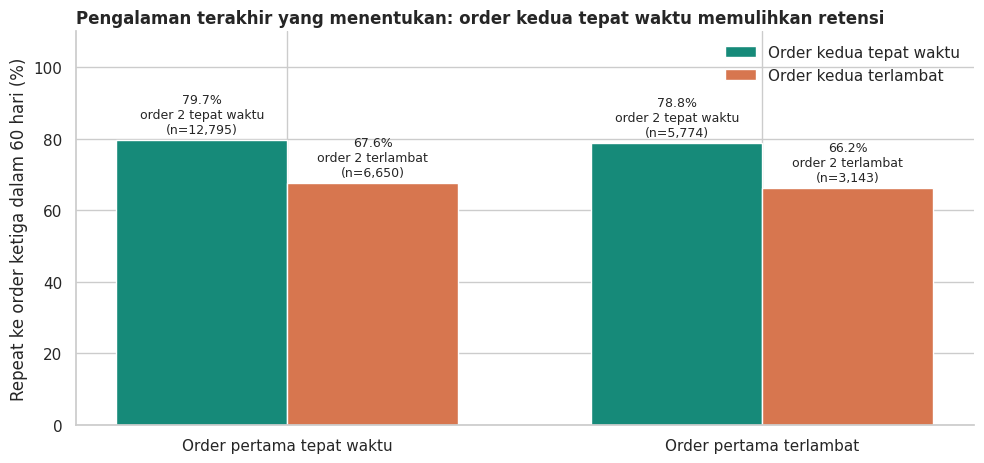

In [63]:
# 6.4 Efek bertumpuk: keterlambatan pada order ke-1 dan ke-2 terhadap repeat ke order ke-3 (60 hari)
seq = completed.loc[completed['user_id'].isin(first_order.loc[first_order['order_status'].eq('completed'), 'user_id'])]
seq = seq.merge(base[['order_id', 'late_delivery']], on='order_id', how='left', suffixes=('_x', ''))
seq = seq.sort_values(['user_id', 'order_date', 'order_id'])
seq['k'] = seq.groupby('user_id').cumcount() + 1

o1 = seq.loc[seq['k'].eq(1)].set_index('user_id')
o2 = seq.loc[seq['k'].eq(2)].set_index('user_id')
st = pd.DataFrame({'late_1': o1['late_delivery'], 'late_2': o2['late_delivery'], 'delivery_2': o2['delivery_date']}).dropna()
st = st.loc[st['delivery_2'].le(END - pd.Timedelta(days=60))]
later = seq.loc[seq['k'].ge(3), ['user_id', 'order_date']].merge(st[['delivery_2']], left_on='user_id', right_index=True)
later = later.loc[later['order_date'].gt(later['delivery_2']) & later['order_date'].le(later['delivery_2'] + pd.Timedelta(days=60))]
st['repeat_3'] = st.index.isin(later['user_id']).astype(int)
st[['late_1', 'late_2']] = st[['late_1', 'late_2']].astype(int)
st['jumlah_terlambat'] = st['late_1'] + st['late_2']
lab = {0: 'tepat waktu', 1: 'terlambat'}
st['pola'] = 'order 1 ' + st['late_1'].map(lab) + ' | order 2 ' + st['late_2'].map(lab)

print(f'Pengguna dengan dua order pertama delivered & follow-up 60 hari setelah order kedua: {len(st):,}')
t_n = st.groupby('jumlah_terlambat')['repeat_3'].agg(['size', 'mean']).rename(columns={'size': 'user', 'mean': 'repeat_order_3'})
print('\n1) Repeat ke order ketiga menurut jumlah keterlambatan pada dua order pertama')
display(t_n.round(4))
pola_order = ['order 1 tepat waktu | order 2 tepat waktu', 'order 1 terlambat | order 2 tepat waktu',
              'order 1 tepat waktu | order 2 terlambat', 'order 1 terlambat | order 2 terlambat']
t_p = st.groupby('pola')['repeat_3'].agg(['size', 'sum', 'mean']).reindex(pola_order)
print('2) Repeat ke order ketiga menurut pola keterlambatan')
display(t_p.rename(columns={'size': 'user', 'sum': 'repeat', 'mean': 'repeat_order_3'}).round(4))

print('Perbandingan:')
for a, b, label in [(pola_order[1], pola_order[0], 'Terlambat lalu tepat waktu vs selalu tepat waktu'),
                    (pola_order[2], pola_order[0], 'Tepat waktu lalu terlambat vs selalu tepat waktu'),
                    (pola_order[3], pola_order[2], 'Dua kali terlambat vs hanya order kedua terlambat')]:
    t = two_prop(t_p.loc[a, 'sum'], t_p.loc[a, 'size'], t_p.loc[b, 'sum'], t_p.loc[b, 'size'])
    print(f"- {label}: {pct(t['p_a'])} vs {pct(t['p_b'])} -> {t['diff']*100:+.2f} pp "
          f"(95% CI {t['low']*100:+.2f} s.d. {t['high']*100:+.2f}); p = {t['p']:.3g}")

# Grafik: repeat ke order ketiga menurut ketepatan order 1 (sumbu x) dan order 2 (warna)
fig, ax = plt.subplots(figsize=(10, 4.8))
xx = np.arange(2); w = .36
for j, (late2, color) in enumerate([(0, TEAL), (1, ORANGE)]):
    vals = [t_p.loc[f'order 1 {lab[l1]} | order 2 {lab[late2]}', 'mean'] * 100 for l1 in (0, 1)]
    ns_ = [t_p.loc[f'order 1 {lab[l1]} | order 2 {lab[late2]}', 'size'] for l1 in (0, 1)]
    bars = ax.bar(xx + (j - .5) * w, vals, w, color=color, label=f'Order kedua {lab[late2]}')
    for bar, v, n in zip(bars, vals, ns_):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f'{v:.1f}%\norder 2 {lab[late2]}\n(n={n:,})',
                ha='center', va='bottom', fontsize=9)
ax.set_xticks(xx, ['Order pertama tepat waktu', 'Order pertama terlambat']); ax.set_ylim(0, 110)
ax.set_ylabel('Repeat ke order ketiga dalam 60 hari (%)')
ax.set_title('Pengalaman terakhir yang menentukan: order kedua tepat waktu memulihkan retensi', loc='left', fontweight='bold')
ax.legend(frameon=False, loc='upper right'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Insight:**
- **Kerusakan tidak bertumpuk; yang menentukan adalah pengalaman terakhir.** Pada 28.362 pengguna yang sudah melakukan order kedua, repeat ke order ketiga hampir tidak berbeda antara "terlambat lalu tepat waktu" (78,8%) dan "selalu tepat waktu" (79,7%; −0,8 pp, p = 0,20). Sebaliknya, "tepat waktu lalu terlambat" turun ke 67,6% (−12,1 pp, p < 0,001). Dua kali terlambat (66,2%) hanya 1,4 pp lebih rendah daripada terlambat sekali di order kedua (p = 0,19).
- **Artinya dampak keterlambatan dapat dipulihkan.** Pengguna yang order pertamanya terlambat tetapi kembali dan mendapat order kedua tepat waktu, retensinya kembali normal. Ini memberi dasar data untuk *service recovery*, dengan sasaran yang lebih tajam: **pastikan order berikutnya dari pengguna yang baru mengalami keterlambatan dikirim tepat waktu** (mis. prioritas kurir atau SLA yang lebih longgar untuk order tersebut), di samping membawa mereka kembali (voucher pemulihan).
- **Catatan seleksi:** analisis ini hanya mencakup pengguna yang sudah kembali untuk order kedua, sehingga belum tentu berlaku bagi pengguna yang langsung churn setelah keterlambatan pertama. Untuk kelompok itu, bukti terkuat tetap dari pertanyaan 4 (repeat 66,2% vs 79,2%).

###  6.5 Akurasi Janji SLA vs Kecepatan Aktual
Sekitar sepertiga pengiriman terlambat di hampir semua segmen. Bila sebagian besar keterlambatan hanya lewat 1 hari dari SLA, masalah utamanya ada pada **janji (estimasi tiba) yang terlalu optimistis**, bukan pengiriman yang benar-benar lambat, dan perbaikannya (estimasi tiba realistis) hampir tanpa biaya. Bagian ini melihat sebaran `delivery_duration_days − sla_promised_days`, mensimulasikan tingkat keterlambatan bila janji diberi penyangga +1/+2 hari, dan mengaitkan besar keterlambatan dengan repeat.

Pengiriman delivered: 236,104 | terlambat 34.9%

1) Besar keterlambatan (hari lewat SLA)


,pengiriman terlambat,% dari terlambat,% dari seluruh delivered
1 hari,53577,65.07,22.69
2 hari,13523,16.42,5.73
3-5 hari,1400,1.70,0.59
6-7 hari,0,0.00,0.00
> 7 hari,13837,16.81,5.86


Per label zona (% dari pengiriman terlambat):


col_0,1 hari,2 hari,3-5 hari,> 7 hari
shipping_zone,,,,
dalam_kota,69.4,17.5,1.8,11.3
luar_kota,69.3,17.5,1.8,11.5
luar_pulau,46.0,11.8,1.1,41.1



2) Simulasi penyangga janji (tanpa mengubah kecepatan kurir)


,Penyangga janji,Tingkat terlambat,Turun (pp)
0,SLA saat ini,34.9%,0.00
1,+1 hari,12.2%,22.69
2,+2 hari,6.5%,28.42


,SLA saat ini,+1 hari,+2 hari
shipping_zone,,,
dalam_kota,33.6,10.3,4.4
luar_kota,33.4,10.3,4.4
luar_pulau,42.9,23.2,18.1



3) Repeat 60 hari menurut hari lewat SLA (order pertama)


,user,repeat_60d
0 hari,25767,0.7925
1 hari,8942,0.7501
2 hari,2317,0.7225
3 hari,220,0.6091
4 hari,11,0.1818
>= 8 hari,2106,0.2265


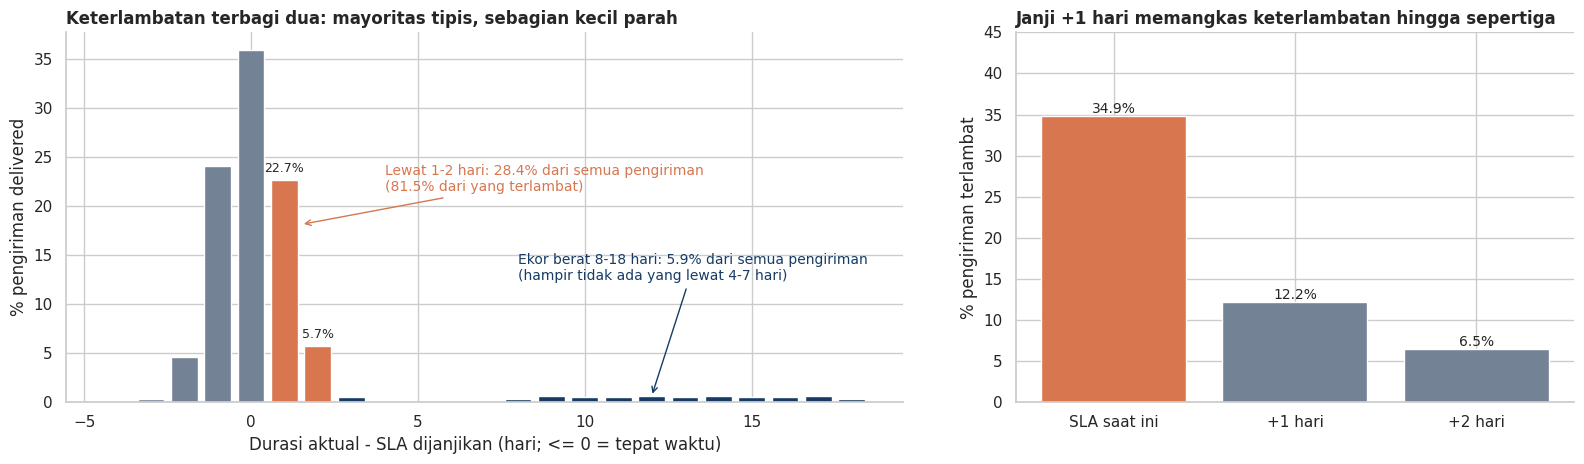

In [64]:
# 6.5 Akurasi janji SLA: sebaran (durasi - SLA), simulasi penyangga, dan kaitannya dengan repeat
sla_gap = (dl['delivery_duration_days'] - dl['sla_promised_days']).astype(int)
late_gap = sla_gap[sla_gap.gt(0)]
band = pd.cut(late_gap, [0, 1, 2, 5, 7, 100], labels=['1 hari', '2 hari', '3-5 hari', '6-7 hari', '> 7 hari'])
t_band = band.value_counts(sort=False).to_frame('pengiriman terlambat')
t_band['% dari terlambat'] = t_band['pengiriman terlambat'] / len(late_gap) * 100
t_band['% dari seluruh delivered'] = t_band['pengiriman terlambat'] / len(dl) * 100
print(f'Pengiriman delivered: {len(dl):,} | terlambat {pct(sla_gap.gt(0).mean())}')
print('\n1) Besar keterlambatan (hari lewat SLA)')
display(t_band.round(2))
by_zone_band = pd.crosstab(dl.loc[late_gap.index, 'shipping_zone'], band, normalize='index') * 100
print('Per label zona (% dari pengiriman terlambat):')
display(by_zone_band.round(1))

# 2) Simulasi: tingkat keterlambatan bila estimasi tiba yang dijanjikan = SLA + penyangga
sim = pd.DataFrame({'Penyangga janji': ['SLA saat ini', '+1 hari', '+2 hari'],
                    'Tingkat terlambat': [sla_gap.gt(b).mean() for b in (0, 1, 2)]})
sim['Turun (pp)'] = (sim['Tingkat terlambat'].iloc[0] - sim['Tingkat terlambat']) * 100
sim_zone = pd.DataFrame({f'+{b} hari' if b else 'SLA saat ini': sla_gap.gt(b).groupby(dl['shipping_zone']).mean() * 100
                         for b in (0, 1, 2)})
print('\n2) Simulasi penyangga janji (tanpa mengubah kecepatan kurir)')
display(sim.assign(**{'Tingkat terlambat': sim['Tingkat terlambat'].map(pct)}).round(2))
display(sim_zone.round(1))

# 3) Repeat 60 hari menurut hari lewat SLA pada order pertama
rp_gap = cohort60.groupby(cohort60['days_over_sla'].clip(upper=8).astype(int))['repeat'].agg(['size', 'mean'])
rp_gap.index = [f'{i} hari' if i < 8 else '>= 8 hari' for i in rp_gap.index]
print('\n3) Repeat 60 hari menurut hari lewat SLA (order pertama)')
display(rp_gap.rename(columns={'size': 'user', 'mean': 'repeat_60d'}).round(4))

# Grafik
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.5, 1]})
dist = sla_gap.clip(-4, 18).value_counts(normalize=True).sort_index() * 100
dist = dist.reindex(range(-4, 19), fill_value=0)
colors = [GRAY if d <= 0 else (ORANGE if d <= 2 else PRIMARY) for d in dist.index]
axes[0].bar(dist.index, dist.values, color=colors, width=.8)
for d in (1, 2):
    axes[0].text(d, dist[d] + .8, f'{dist[d]:.1f}%', ha='center', fontsize=9)
axes[0].annotate(f'Lewat 1-2 hari: {pct(sla_gap.between(1, 2).mean())} dari semua pengiriman\n'
                 f'({pct(late_gap.le(2).mean())} dari yang terlambat)', (1.5, dist[1] * .8), xytext=(4, dist[1] * .95),
                 fontsize=10, color=ORANGE, arrowprops=dict(arrowstyle='->', color=ORANGE))
axes[0].annotate(f'Ekor berat 8-18 hari: {pct(sla_gap.ge(8).mean())} dari semua pengiriman\n'
                 '(hampir tidak ada yang lewat 4-7 hari)', (12, dist.loc[8:18].max()), xytext=(8, dist[1] * .55),
                 fontsize=10, color=PRIMARY, arrowprops=dict(arrowstyle='->', color=PRIMARY))
axes[0].set_xlabel('Durasi aktual - SLA dijanjikan (hari; <= 0 = tepat waktu)'); axes[0].set_ylabel('% pengiriman delivered')
axes[0].set_title('Keterlambatan terbagi dua: mayoritas tipis, sebagian kecil parah', loc='left', fontweight='bold')
bars = axes[1].bar(sim['Penyangga janji'], sim['Tingkat terlambat'] * 100, color=[ORANGE, GRAY, GRAY])
axes[1].bar_label(bars, labels=[pct(v) for v in sim['Tingkat terlambat']], fontsize=10)
axes[1].set_ylim(0, 45); axes[1].set_ylabel('% pengiriman terlambat')
axes[1].set_title('Janji +1 hari memangkas keterlambatan hingga sepertiga', loc='left', fontweight='bold')
for ax in axes: ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Insight:**
- **Keterlambatan terbagi dua (bimodal).** Dari pengiriman yang terlambat, **65,1% hanya lewat 1 hari** dan 16,4% lewat 2 hari. Total 81,5% terlambat ≤ 2 hari, setara 28,4% dari seluruh pengiriman. Sisanya membentuk ekor terpisah: 16,8% lewat **8–18 hari** (5,9% dari seluruh pengiriman), dan hampir tidak ada yang lewat 4–7 hari. Ekor berat terkonsentrasi pada label `luar_pulau` (41% dari keterlambatannya, vs ±11% di label lain).
- **Sebagian besar masalah ada pada janji, bukan kecepatan.** Tanpa mengubah kecepatan kurir, estimasi tiba yang ditambah **1 hari menurunkan tingkat keterlambatan dari 34,9% menjadi 12,2%**, dan +2 hari menjadi 6,5%. Di label `luar_pulau`, penyangga hanya menurunkan ke 23,2% karena ekor beratnya.
- **Besar keterlambatan menentukan dampaknya ke retensi:** repeat 60 hari 79,3% (tepat waktu), 75,0% (lewat 1 hari), 72,3% (2 hari), 60,9% (3 hari), dan hanya **22,7% bila lewat ≥ 8 hari**.
- **Implikasi, dua masalah dengan dua solusi:**
  1. *Keterlambatan tipis* (mayoritas). Solusinya **estimasi tiba realistis** (SLA + penyangga) dan notifikasi proaktif, yang hampir tanpa biaya. Yang belum diketahui: apakah pengguna yang "terlambat 1 hari" dari janji yang lebih jujur tetap kehilangan kepercayaan (retensi 75,0% vs 79,3%), dan apakah janji yang lebih panjang menurunkan konversi checkout. Keduanya perlu diuji A/B.
  2. *Ekor berat* (5,9% pengiriman, retensi ±23%). Solusinya **deteksi dini dan eskalasi**: paket yang belum tiba H+2 dari SLA ditangani khusus, disertai voucher pemulihan.

###  6.6 Apakah Promo Memengaruhi Nilai, Bukan Hanya Retensi?
Pertanyaan 1–3 hanya menguji repeat (ya/tidak). Promo mungkin tetap bermanfaat bila pengguna berpromo **lebih sering berbelanja, berbelanja lebih besar per order, atau menghasilkan GMV jangka panjang lebih tinggi**. Bagian ini memakai kohort dengan follow-up penuh 365 hari (`c365`, bagian 5.1) dan membandingkan tiga kelompok promo pada order pertama (tanpa promo, promo normal, voucher besar ≥ Rp400 ribu) pada: repeat 365 hari, frekuensi order berikutnya, AOV order berikutnya, GMV 365 hari, serta nilai order pertama itu sendiri. Uji yang dipakai: Mann-Whitney U (sebaran miring) dan selisih rata-rata dengan 95% CI bootstrap. Untuk GMV, selisih juga dihitung per kategori lalu dibobot porsi kategori.

Kohort follow-up 365 hari: 28,436 pengguna (setelah memangkas 1% GMV tertinggi)


,user,Repeat 365 hari,Order berikutnya (365 hari),AOV order berikutnya,GMV 365 hari,Nilai order pertama,median GMV 365 hari
kelompok_promo,,,,,,,
tanpa promo,11918,0.77,3.74,1142482.75,4163343.25,1276428.06,1300169.5
promo normal,14806,0.77,3.69,1145565.25,4118362.5,1165907.41,1310713.5
voucher besar,1712,0.78,3.69,1233468.63,4141269.27,1101268.42,1397205.0



Promo pada order pertama vs tanpa promo


,Metrik,Promo,Tanpa promo,Selisih,CI low,CI high,Selisih (%),p (Mann-Whitney)
0,Repeat 365 hari,7.728000e-01,7.737000e-01,-0.0009,-0.0108,0.0087,-0.1177,0.8565
1,Order berikutnya (365 hari),3.687100e+00,3.737000e+00,-0.0499,-0.1515,0.0469,-1.3349,0.5920
2,AOV order berikutnya,1.154731e+06,1.142483e+06,12248.1381,-41558.6602,62309.8856,1.0721,0.2497
3,GMV 365 hari,4.120737e+06,4.163343e+06,-42606.5883,-201448.3480,104901.5221,-1.0234,0.8053
4,Nilai order pertama,1.159208e+06,1.276428e+06,-117220.1323,-193910.5755,-37230.1328,-9.1834,0.0481


Selisih GMV 365 hari setelah distandardisasi kategori: Rp-42.954 per pengguna (rata-rata tanpa promo Rp4.163.343)


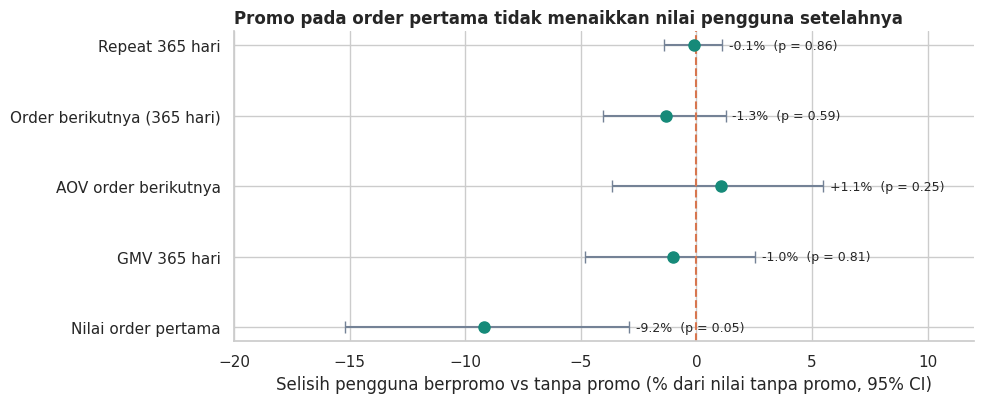

In [65]:
# 6.6 Promo vs metrik nilai (kohort follow-up 365 hari)
pv = c365.copy()
pv['kelompok_promo'] = np.select([pv['promo_amount'].eq(0), pv['promo_amount'].ge(400_000)],
                                 ['tanpa promo', 'voucher besar'], 'promo normal')
pv['order_berikutnya'] = pv['repeat_orders'].fillna(0)
pv['aov_berikutnya'] = np.where(pv['order_berikutnya'].gt(0), pv['repeat_gmv'] / pv['order_berikutnya'].replace(0, np.nan), np.nan)
pv = pv.loc[pv['repeat_gmv'].le(pv['repeat_gmv'].quantile(.99))]          # buang 1% GMV tertinggi (sama dengan 5.1)
GRP = ['tanpa promo', 'promo normal', 'voucher besar']
metrics = {'repeat': 'Repeat 365 hari', 'order_berikutnya': 'Order berikutnya (365 hari)',
           'aov_berikutnya': 'AOV order berikutnya', 'repeat_gmv': 'GMV 365 hari', 'total_amount': 'Nilai order pertama'}
summ = pv.groupby('kelompok_promo').agg(user=('user_id', 'size'), **{k: (k, 'mean') for k in metrics}).reindex(GRP)
summ['median GMV 365 hari'] = pv.groupby('kelompok_promo')['repeat_gmv'].median()
print(f'Kohort follow-up 365 hari: {len(pv):,} pengguna (setelah memangkas 1% GMV tertinggi)')
display(summ.rename(columns=metrics).round(2))

# Uji promo (normal + voucher besar) vs tanpa promo
rng_b = np.random.default_rng(7)
def boot_diff(a, b, n=1000):
    a, b = np.asarray(a, float), np.asarray(b, float)
    d = [rng_b.choice(a, len(a)).mean() - rng_b.choice(b, len(b)).mean() for _ in range(n)]
    return a.mean() - b.mean(), *np.percentile(d, [2.5, 97.5])
rows = []
pro, non = pv.loc[pv['promo_first'].eq(1)], pv.loc[pv['promo_first'].eq(0)]
for k, label in metrics.items():
    a, b = pro[k].dropna(), non[k].dropna()
    diff, lo, hi = boot_diff(a, b)
    rows.append({'Metrik': label, 'Promo': a.mean(), 'Tanpa promo': b.mean(), 'Selisih': diff,
                 'CI low': lo, 'CI high': hi, 'Selisih (%)': diff / b.mean() * 100,
                 'p (Mann-Whitney)': stats.mannwhitneyu(a, b).pvalue})
promo_value = pd.DataFrame(rows)
print('\nPromo pada order pertama vs tanpa promo')
display(promo_value.round(4))
w_cat = pv['product_category'].value_counts(normalize=True)
gm = pv.groupby(['product_category', 'promo_first'])['repeat_gmv'].mean().unstack()
print(f"Selisih GMV 365 hari setelah distandardisasi kategori: {rp((gm[1] - gm[0]).mul(w_cat).sum())} per pengguna "
      f"(rata-rata tanpa promo {rp(non['repeat_gmv'].mean())})")

# Grafik: selisih relatif (%) promo vs tanpa promo per metrik, dengan 95% CI
fig, ax = plt.subplots(figsize=(10, 4.2))
yy = np.arange(len(promo_value))
rel = promo_value['Selisih (%)']
lo = promo_value['CI low'] / promo_value['Tanpa promo'] * 100
hi = promo_value['CI high'] / promo_value['Tanpa promo'] * 100
ax.errorbar(rel, yy, xerr=[rel - lo, hi - rel], fmt='o', color=TEAL, ecolor=GRAY, capsize=4, ms=8)
for y, r, h, p in zip(yy, rel, hi, promo_value['p (Mann-Whitney)']):
    ax.text(h + .3, y, f'{r:+.1f}%  (p = {p:.2f})', va='center', fontsize=9)
ax.axvline(0, color=ORANGE, ls='--'); ax.set_xlim(-20, 12)
ax.set_yticks(yy, promo_value['Metrik']); ax.invert_yaxis()
ax.set_xlabel('Selisih pengguna berpromo vs tanpa promo (% dari nilai tanpa promo, 95% CI)')
ax.set_title('Promo pada order pertama tidak menaikkan nilai pengguna setelahnya', loc='left', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Insight:**
- **Promo tidak menaikkan nilai pengguna di metrik mana pun selama 365 hari.** Dibanding pengguna tanpa promo, pengguna berpromo pada order pertama memiliki repeat 365 hari yang sama (−0,1%; p = 0,86), jumlah order berikutnya sedikit lebih rendah (−1,3%; p = 0,59), AOV order berikutnya setara (+1,1%; p = 0,25), dan GMV 365 hari setara (−1,0%; p = 0,81). Semua interval kepercayaan melintasi nol, dan hasil tidak berubah setelah distandardisasi kategori (selisih GMV ±−Rp43 ribu dari ±Rp4,16 juta per pengguna).
- **Voucher besar pun tidak menghasilkan pengguna yang lebih bernilai:** GMV 365 hari ±Rp4,14 juta, setara kelompok tanpa promo (±Rp4,16 juta), padahal biaya promonya ±Rp750 ribu per order.
- **Satu-satunya perbedaan ada di order pertama itu sendiri:** rata-rata nilai order pertama berpromo 9,2% lebih rendah (p = 0,048; median relatif sama). Ini tidak mendukung dugaan bahwa promo mendorong keranjang yang lebih besar.
- **Implikasi:** celah "promo mungkin bermanfaat di metrik lain" tertutup untuk metrik pasca-pembelian. Manfaat promo yang belum dapat diukur dari data ini hanya pada **akuisisi** (apakah pengguna akan bertransaksi sama sekali tanpa promo), karena data tidak memuat pengguna yang tidak jadi membeli.

###  6.7 Heatmap Kurir × Label Zona × Kampanye
Dasar untuk alokasi kurir per rute: tingkat keterlambatan setiap kurir pada setiap label zona, dipisah antara periode non-kampanye dan kampanye. Skala warna disamakan di kedua panel supaya kenaikan saat kampanye langsung terlihat. Sel dengan < 300 pengiriman diberi tanda. Ingat temuan 6.1: label zona adalah kelas SLA menurut sistem, bukan jarak geografis.

Tingkat keterlambatan per kurir x label zona (%)


Non-kampanye (%)                      Kampanye (%)            \
shipping_zone         dalam_kota luar_kota luar_pulau   dalam_kota luar_kota   
courier                                                                        
SiCepat                     32.3      33.5       38.4         33.0      34.1   
JNE                         32.9      32.9       38.3         34.8      33.8   
AnterAja                    33.2      32.5       39.2         34.6      34.4   
GoTo Logistics              33.3      32.5       38.5         35.1      34.9   
Tidak diketahui             33.8      31.9       40.5         35.1      35.1   

                            
shipping_zone   luar_pulau  
courier                     
SiCepat               39.7  
JNE                   39.4  
AnterAja              39.5  
GoTo Logistics        67.7  
Tidak diketahui       47.3

Jumlah pengiriman per sel


Non-kampanye                        Kampanye            \
shipping_zone     dalam_kota luar_kota luar_pulau dalam_kota luar_kota   
courier                                                                  
SiCepat                11960     13156       4471       6133      7123   
JNE                    14828     16796       5468       7858      9021   
AnterAja                8771      9980       3274       4924      5352   
GoTo Logistics         23504     26778       8802      12758     14322   
Tidak diketahui         1194      1368        442       2456      2686   

                            
shipping_zone   luar_pulau  
courier                     
SiCepat               2337  
JNE                   2996  
AnterAja              1745  
GoTo Logistics        4752  
Tidak diketahui        849

Kenaikan saat kampanye (pp):


shipping_zone,dalam_kota,luar_kota,luar_pulau
courier,,,
SiCepat,0.7,0.6,1.2
JNE,2.0,0.9,1.1
AnterAja,1.5,2.0,0.3
GoTo Logistics,1.8,2.4,29.1
Tidak diketahui,1.3,3.2,6.9


Label luar_pulau saat kampanye: terbaik JNE (39.4%) vs terburuk GoTo Logistics (67.7%)
GoTo Logistics menangani 37.5% pengiriman luar_pulau saat kampanye, terlambat 67.7% vs kurir lain 39.5%.
Kelebihan pengiriman terlambat: 1,337 dalam 2 tahun (669 per tahun). Tanpa selisih ini, keterlambatan luar_pulau saat kampanye 50.6% -> 40.0% (non-kampanye 38.6%).
Order pertama yang terdampak (kohort 60 hari): 589 pengguna, terlambat 66.0%, repeat 60 hari 51.8%


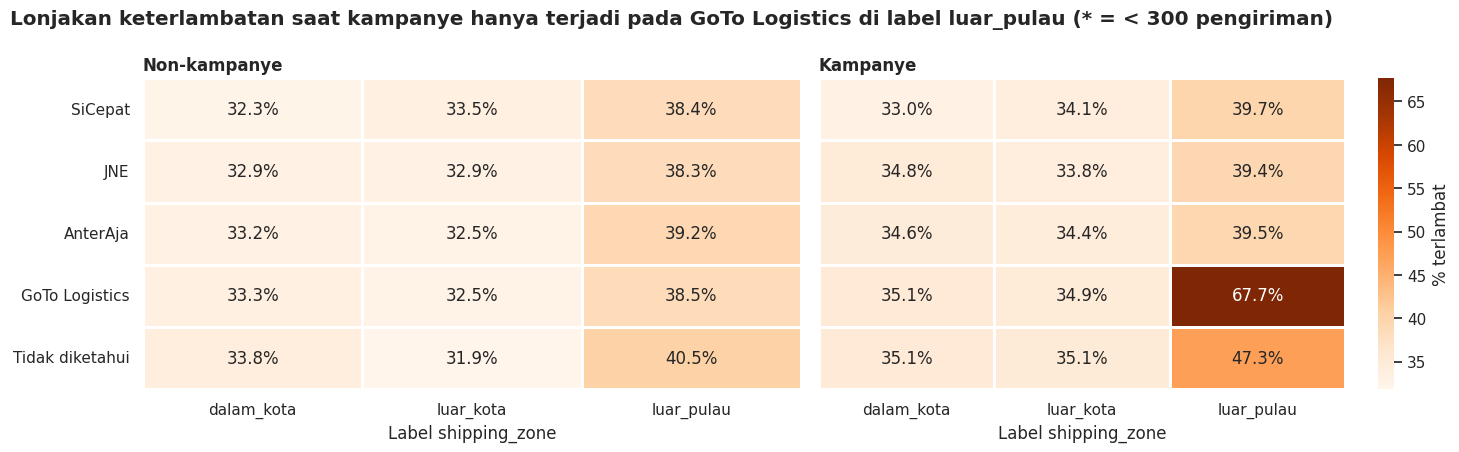

In [66]:
# 6.7 Heatmap tingkat keterlambatan: kurir x label zona, non-kampanye vs kampanye
hm = dl.copy()
courier_order = ['SiCepat', 'JNE', 'AnterAja', 'GoTo Logistics', 'Tidak diketahui']
rate = hm.pivot_table(index='courier', columns=['is_campaign_period', 'shipping_zone'], values='late_delivery', aggfunc='mean') * 100
size = hm.groupby(['courier', 'is_campaign_period', 'shipping_zone']).size().unstack(['is_campaign_period', 'shipping_zone'])
rate, size = rate.reindex(courier_order), size.reindex(courier_order)
tbl = pd.concat({'Non-kampanye (%)': rate[False], 'Kampanye (%)': rate[True]}, axis=1)
print('Tingkat keterlambatan per kurir x label zona (%)')
display(tbl.round(1))
print('Jumlah pengiriman per sel')
display(pd.concat({'Non-kampanye': size[False], 'Kampanye': size[True]}, axis=1))
jump = (rate[True] - rate[False]).round(1)
print('Kenaikan saat kampanye (pp):')
display(jump)
best = rate[True]['luar_pulau'].drop('Tidak diketahui').idxmin(); worst = rate[True]['luar_pulau'].drop('Tidak diketahui').idxmax()
print(f"Label luar_pulau saat kampanye: terbaik {best} ({rate[True].loc[best, 'luar_pulau']:.1f}%) vs "
      f"terburuk {worst} ({rate[True].loc[worst, 'luar_pulau']:.1f}%)")

# Kuantifikasi: berapa keterlambatan kampanye luar_pulau yang berasal dari selisih kurir terburuk vs kurir lain
cl = hm.loc[hm['is_campaign_period'].astype(bool) & hm['shipping_zone'].eq('luar_pulau') & hm['courier'].ne('Tidak diketahui')]
others = cl.loc[cl['courier'].ne(worst), 'late_delivery'].mean()
w_cl = cl.loc[cl['courier'].eq(worst)]
excess = len(w_cl) * (w_cl['late_delivery'].mean() - others)
cl_all = hm.loc[hm['is_campaign_period'].astype(bool) & hm['shipping_zone'].eq('luar_pulau')]
camp_lp_noncamp = hm.loc[~hm['is_campaign_period'].astype(bool) & hm['shipping_zone'].eq('luar_pulau'), 'late_delivery'].mean()
rate_wo = (cl_all['late_delivery'].sum() - excess) / len(cl_all)
print(f"{worst} menangani {pct(len(w_cl) / len(cl_all))} pengiriman luar_pulau saat kampanye, terlambat "
      f"{pct(w_cl['late_delivery'].mean())} vs kurir lain {pct(others)}.")
print(f"Kelebihan pengiriman terlambat: {excess:,.0f} dalam 2 tahun ({excess / YEARS:,.0f} per tahun). "
      f"Tanpa selisih ini, keterlambatan luar_pulau saat kampanye {pct(cl_all['late_delivery'].mean())} -> {pct(rate_wo)} "
      f"(non-kampanye {pct(camp_lp_noncamp)}).")
worst_fo = cohort60.loc[cohort60['campaign_first'].eq(1) & cohort60['shipping_zone'].eq('luar_pulau')
                        & cohort60['courier_name'].eq(worst)]
print(f"Order pertama yang terdampak (kohort 60 hari): {len(worst_fo):,} pengguna, terlambat {pct(worst_fo['late_delivery'].mean())}, "
      f"repeat 60 hari {pct(worst_fo['repeat'].mean())}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
vmin, vmax = np.nanmin(rate.values), np.nanmax(rate.values)
for ax, flag, title in [(axes[0], False, 'Non-kampanye'), (axes[1], True, 'Kampanye')]:
    annot = rate[flag].round(1).astype(str) + np.where(size[flag] < 300, '*', '') + '%'
    sns.heatmap(rate[flag][ZONE_ORDER], annot=annot[ZONE_ORDER], fmt='', cmap='Oranges', vmin=vmin, vmax=vmax,
                linewidths=2, linecolor='white', cbar=flag, cbar_kws={'label': '% terlambat'}, ax=ax)
    ax.set_title(title, loc='left', fontweight='bold'); ax.set_xlabel('Label shipping_zone'); ax.set_ylabel('')
fig.suptitle(f'Lonjakan keterlambatan saat kampanye hanya terjadi pada {worst} di label luar_pulau (* = < 300 pengiriman)',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

**Insight:**
- **Lonjakan keterlambatan saat kampanye hampir seluruhnya berasal dari satu sel: GoTo Logistics pada label `luar_pulau`.** Di luar kampanye, keempat kurir setara di setiap label (luar_pulau 38,3–39,2%). Saat kampanye, SiCepat, JNE, dan AnterAja hanya naik 0,3–1,2 pp (39,4–39,7%), sedangkan **GoTo Logistics melonjak +29,1 pp menjadi 67,7%**.
- GoTo Logistics menangani 37,5% pengiriman `luar_pulau` saat kampanye. Selisihnya terhadap kurir lain setara **±1.337 pengiriman terlambat tambahan dalam 2 tahun (±669 per tahun)**. Tanpa selisih ini, keterlambatan `luar_pulau` saat kampanye turun dari 50,6% ke **40,0%**, hampir sama dengan periode non-kampanye (38,6%).
- Dampaknya ke pengguna baru: 589 pengguna kohort 60 hari yang order pertamanya ditangani GoTo Logistics pada label `luar_pulau` saat kampanye hanya **51,8%** yang kembali dalam 60 hari (keterlambatan 66,0%).
- **Implikasi:** temuan R06 "kampanye memperburuk pengiriman luar pulau" lebih tepat dibaca sebagai **"kapasitas GoTo Logistics untuk kelas SLA panjang tidak tahan lonjakan kampanye"**. Rekomendasi alokasi kurir menjadi jauh lebih tajam: saat kampanye, alihkan sebagian volume label `luar_pulau` dari GoTo Logistics ke JNE/SiCepat/AnterAja, atau tambah kapasitasnya khusus untuk kelas ini. Kelompok "Tidak diketahui" (47,3%) juga perlu ditelusuri karena kemungkinan mencakup sebagian pengiriman GoTo Logistics.

<a id="Visualisasi-Eksekutif"></a>
## <span style="color:darkorange">Visualisasi Eksekutif</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Tujuh grafik berikut merangkum analisis untuk pengambilan keputusan. Prinsipnya satu grafik untuk satu keputusan, dengan judul berupa kesimpulan. Semua angka dihitung ulang dari variabel analisis di atas (bukan diketik manual), sehingga grafik ikut berubah bila data diperbarui. Nilai finansial berlaku pada skala dataset; manfaat retensi dinyatakan dalam GMV, bukan pendapatan.
</p>

In [67]:
# Angka-angka untuk visualisasi eksekutif (semua dihitung dari variabel analisis sebelumnya)
INK, MUTED = '#1F2933', '#5B6573'

def rp_short(x):
    """Rupiah ringkas: Rp2,33 M (miliar) / Rp45 jt (juta)."""
    sign = '−' if x < 0 else ''; x = abs(x)
    if x >= 1e9: return f'{sign}Rp{x/1e9:,.2f} M'.replace('.', ',')
    if x >= 1e6: return f'{sign}Rp{x/1e6:,.0f} jt'.replace(',', '.')
    return sign + rp(x)

def clean_axes(ax, grid_axis='y'):
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x' if grid_axis == 'y' else 'y', visible=False)

# Promo vs GMV dan batas promo
cap_saving = (pc['promo_amount'] - np.minimum(pc['promo_amount'], pc['total_amount'])).sum() / YEARS
gt = pc['promo_amount'].gt(pc['total_amount'])
EX = dict(
    promo_year=tot_promo, gmv_year=tot_gmv, promo_to_gmv=tot_promo / tot_gmv,
    gt_share=pc.loc[gt, 'promo_amount'].sum() / pc['promo_amount'].sum(),
    gt_promo=pc.loc[gt, 'promo_amount'].sum() / YEARS, gt_gmv=pc.loc[gt, 'total_amount'].sum() / YEARS,
    gt_order_share=gt.mean(),
    big_share=pg.loc[pg['voucher_besar'], 'promo_amount'].sum() / pg['promo_amount'].sum(),
    cap_saving=cap_saving,
    repeat60=cohort60['repeat'].mean(), late_rate=dl['late_delivery'].mean(),
    n_late_year=n_late_year, gmv_at_risk=n_late_year * gmv_late_gap)

# Dua tuas: efek promo vs efek keterlambatan pada repeat 60 hari
lt = cohort60.groupby('late_delivery')['repeat'].agg(['sum', 'size'])
t_late = two_prop(lt.loc[1, 'sum'], lt.loc[1, 'size'], lt.loc[0, 'sum'], lt.loc[0, 'size'])

# Prioritas rekomendasi: nilai per tahun dengan dasarnya masing-masing (tidak dijumlahkan/dibandingkan lintas satuan)
first_year = len(cohort60) * per_year
goto_share = cohort60['courier_name'].eq('GoTo Logistics').mean()
goto_diff = late_by_courier['GoTo Logistics'] - late_by_courier[['SiCepat', 'JNE', 'AnterAja']].mean()
priority = pd.DataFrame([
    ['Batas promo ≤ nilai belanja\n+ minimum belanja voucher besar', f"hemat {rp_short(EX['cap_saving'])} promo", 1, 'tinggi'],
    ['Alihkan volume luar_pulau GoTo\nsaat kampanye ke kurir lain',
     f"{rp_short(first_year * goto_share * goto_diff * gmv_late_gap)} GMV dari retensi", 2, 'tinggi'],
    ['Estimasi tiba realistis (+1 hari)\n& notifikasi proaktif', f"{rp_short(n_late_year * .01 * gmv_retained)} GMV per +1 pp retensi", 1, 'sedang'],
    ['Voucher pemulihan kasus berat',
     f"{rp_short(n_severe * .10 * gmv_retained)} GMV pada +10 pp, biaya {rp_short(n_severe * (p0 + .10) * median_promo)}", 2, 'sedang'],
    ['Stok regional luar Jawa', f"{rp_short(inv.iloc[0, 1] * gmv_late_gap)} GMV dari retensi", 5, 'rendah'],
    ['Kapasitas kargo semua kampanye', f"{rp_short(inv.iloc[1, 1] * gmv_late_gap)} GMV dari retensi", 4, 'rendah'],
], columns=['Rekomendasi', 'Nilai per tahun', 'Usaha (1-5)', 'Keyakinan data'])

# Skenario menutup gap keterlambatan (horizon GMV 365 hari)
scen_ex = pd.DataFrame({'Gap ditutup': [.10, .25, .50, 1.0]})
scen_ex['GMV per tahun'] = EX['gmv_at_risk'] * scen_ex['Gap ditutup']

display(pd.Series({
    'Promo per tahun': rp_short(EX['promo_year']), 'GMV completed per tahun': rp_short(EX['gmv_year']),
    'Promo / GMV': pct(EX['promo_to_gmv'], 2), 'Porsi anggaran promo pada order promo > belanja': pct(EX['gt_share']),
    'Porsi anggaran promo dari voucher besar': pct(EX['big_share']),
    'Penghematan batas promo per tahun': rp_short(EX['cap_saving']), 'Repeat 60 hari': pct(EX['repeat60']),
    'Tingkat keterlambatan': pct(EX['late_rate']), 'GMV berisiko per tahun': rp_short(EX['gmv_at_risk'])},
    name='Nilai').to_frame())
display(priority.assign(Rekomendasi=priority['Rekomendasi'].str.replace('\n', ' ')))

,Nilai
Promo per tahun,"Rp6,39 M"
GMV completed per tahun,"Rp143,52 M"
Promo / GMV,4.45%
Porsi anggaran promo pada order promo > belanja,59.0%
Porsi anggaran promo dari voucher besar,80.3%
Penghematan batas promo per tahun,"Rp2,33 M"
Repeat 60 hari,74.7%
Tingkat keterlambatan,34.9%
GMV berisiko per tahun,"Rp5,03 M"


,Rekomendasi,Nilai per tahun,Usaha (1-5),Keyakinan data
0,Batas promo ≤ nilai belanja + minimum belanja ...,"hemat Rp2,33 M promo",1,tinggi
1,Alihkan volume luar_pulau GoTo saat kampanye k...,Rp100 jt GMV dari retensi,2,tinggi
2,Estimasi tiba realistis (+1 hari) & notifikasi...,Rp382 jt GMV per +1 pp retensi,1,sedang
3,Voucher pemulihan kasus berat,"Rp1,31 M GMV pada +10 pp, biaya Rp15 jt",2,sedang
4,Stok regional luar Jawa,Rp190 jt GMV dari retensi,5,rendah
5,Kapasitas kargo semua kampanye,Rp59 jt GMV dari retensi,4,rendah


### 1. Ringkasan Angka Kunci
**Keputusan yang didukung:** apakah masalahnya cukup besar untuk ditindaklanjuti, dan di mana: efisiensi promo atau fulfillment.

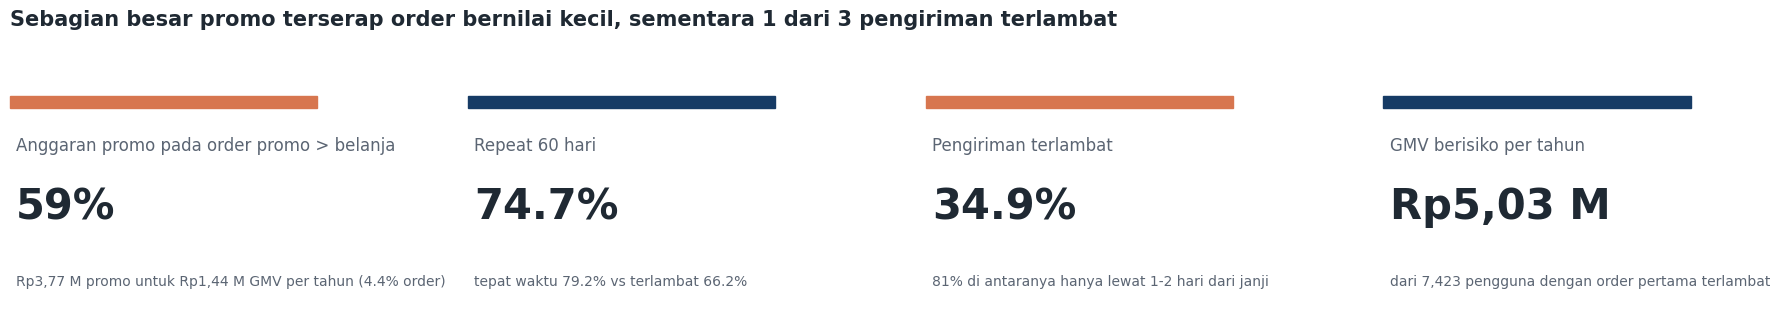

In [68]:
# Grafik eksekutif 1: baris KPI
tiles = [
    (pct(EX['gt_share'], 0), 'Anggaran promo pada order promo > belanja',
     f"{rp_short(EX['gt_promo'])} promo untuk {rp_short(EX['gt_gmv'])} GMV per tahun ({pct(EX['gt_order_share'], 1)} order)", ORANGE),
    (pct(EX['repeat60']), 'Repeat 60 hari',
     f"tepat waktu {pct(t_late['p_b'])} vs terlambat {pct(t_late['p_a'])}", PRIMARY),
    (pct(EX['late_rate']), 'Pengiriman terlambat',
     f"{pct(late_gap.le(2).mean(), 0)} di antaranya hanya lewat 1-2 hari dari janji", ORANGE),
    (rp_short(EX['gmv_at_risk']), 'GMV berisiko per tahun',
     f"dari {EX['n_late_year']:,.0f} pengguna dengan order pertama terlambat", PRIMARY),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.3))
for ax, (value, label, context, accent) in zip(axes, tiles):
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0.93), 1, 0.05, color=accent, transform=ax.transAxes, clip_on=False))
    ax.text(0.02, 0.80, label, fontsize=12, color=MUTED, va='top', transform=ax.transAxes)
    ax.text(0.02, 0.58, value, fontsize=30, fontweight='bold', color=INK, va='top', transform=ax.transAxes)
    ax.text(0.02, 0.12, context, fontsize=10, color=MUTED, va='bottom', transform=ax.transAxes, wrap=True)
fig.suptitle('Sebagian besar promo terserap order bernilai kecil, sementara 1 dari 3 pengiriman terlambat',
             x=0.01, ha='left', fontsize=15, fontweight='bold', color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

### 2. Dua Tuas Retensi: Promo vs Ketepatan Pengiriman
**Keputusan yang didukung:** ke mana anggaran retensi diarahkan. Kedua efek digambar pada skala yang sama.

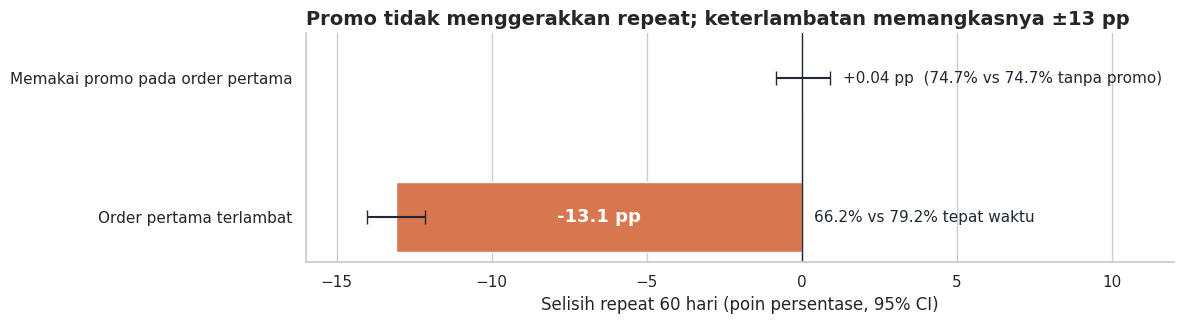

In [69]:
# Grafik eksekutif 2: efek promo vs efek keterlambatan pada repeat 60 hari (pp, 95% CI)
levers = pd.DataFrame({
    'Tuas': ['Memakai promo pada order pertama', 'Order pertama terlambat'],
    'Efek': [t_all['diff'] * 100, t_late['diff'] * 100],
    'Low': [t_all['low'] * 100, t_late['low'] * 100], 'High': [t_all['high'] * 100, t_late['high'] * 100],
    'Ket': [f"{pct(t_all['p_a'])} vs {pct(t_all['p_b'])} tanpa promo", f"{pct(t_late['p_a'])} vs {pct(t_late['p_b'])} tepat waktu"]})
fig, ax = plt.subplots(figsize=(12, 3.4))
bars = ax.barh(levers['Tuas'], levers['Efek'], color=[GRAY, ORANGE], height=.5,
               xerr=[levers['Efek'] - levers['Low'], levers['High'] - levers['Efek']], capsize=5, ecolor=INK)
for b, (_, r) in zip(bars, levers.iterrows()):
    y = b.get_y() + b.get_height() / 2
    if abs(r['Efek']) < 2:
        ax.text(r['High'] + 0.4, y, f"{r['Efek']:+.2f} pp  ({r['Ket']})", va='center', fontsize=11, color=INK)
    else:
        ax.text(r['Efek'] / 2, y, f"{r['Efek']:+.1f} pp", va='center', ha='center', fontsize=13, color='white', fontweight='bold')
        ax.text(0.4, y, r['Ket'], va='center', fontsize=11, color=INK)
ax.axvline(0, color=INK, lw=1); ax.set_xlim(-16, 12); ax.invert_yaxis()
ax.set_xlabel('Selisih repeat 60 hari (poin persentase, 95% CI)')
ax.set_title('Promo tidak menggerakkan repeat; keterlambatan memangkasnya ±13 pp', loc='left', fontsize=14, fontweight='bold')
clean_axes(ax, 'x'); plt.tight_layout(); plt.show()

### 3. Waterfall Anggaran Promo
**Keputusan yang didukung:** menerapkan batas promo ≤ nilai belanja (dan minimum belanja untuk voucher besar).

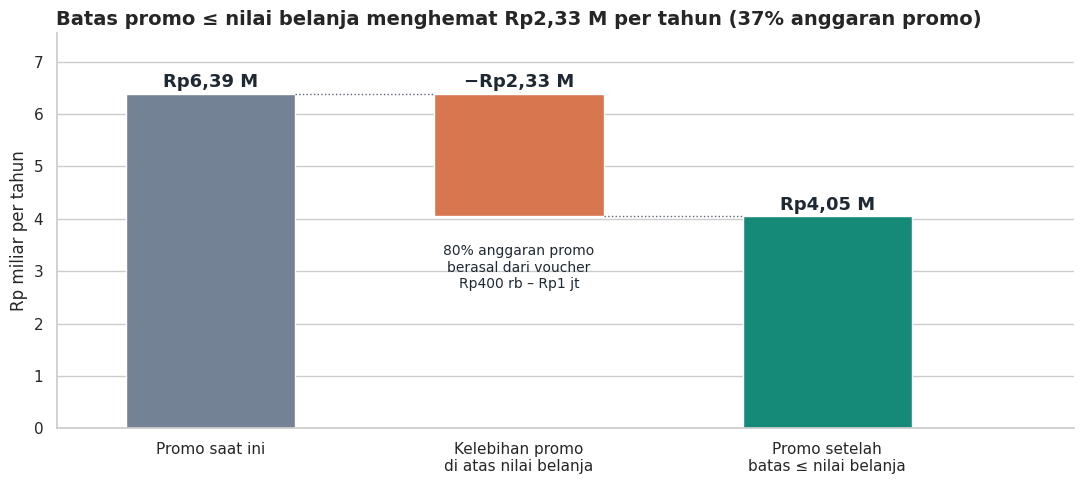

In [70]:
# Grafik eksekutif 3: waterfall anggaran promo per tahun
after_cap = EX['promo_year'] - EX['cap_saving']
steps = [('Promo saat ini', EX['promo_year'], 0, GRAY),
         ('Kelebihan promo\ndi atas nilai belanja', -EX['cap_saving'], EX['promo_year'], ORANGE),
         ('Promo setelah\nbatas ≤ nilai belanja', after_cap, 0, TEAL)]
fig, ax = plt.subplots(figsize=(11, 5))
for i, (label, val, bottom, color) in enumerate(steps):
    b = bottom + val if val < 0 else bottom
    ax.bar(i, abs(val) / 1e9, bottom=b / 1e9, color=color, width=.55)
    ax.text(i, (b + abs(val)) / 1e9 + 0.12, rp_short(val), ha='center', fontsize=13, fontweight='bold', color=INK)
ax.plot([0.275, 0.725], [EX['promo_year'] / 1e9] * 2, color=MUTED, lw=1, ls=':')
ax.plot([1.275, 1.725], [after_cap / 1e9] * 2, color=MUTED, lw=1, ls=':')
ax.set_xticks(range(3), [s[0] for s in steps], fontsize=11); ax.set_xlim(-0.5, 2.8)
ax.set_ylim(0, EX['promo_year'] / 1e9 * 1.18); ax.set_ylabel('Rp miliar per tahun')
ax.text(1, EX['promo_year'] / 1e9 * 0.42,
        f"{pct(EX['big_share'], 0)} anggaran promo\nberasal dari voucher\nRp400 rb – Rp1 jt", ha='center', fontsize=10, color=INK)
ax.set_title(f"Batas promo ≤ nilai belanja menghemat {rp_short(EX['cap_saving'])} per tahun ({pct(EX['cap_saving'] / EX['promo_year'], 0)} anggaran promo)",
             loc='left', fontsize=14, fontweight='bold')
clean_axes(ax); plt.tight_layout(); plt.show()

### 4. Dosis-Respons: Lama Keterlambatan vs Peluang Kembali
**Keputusan yang didukung:** siapa yang mendapat intervensi pemulihan. Fokuskan pada kasus berat (lewat > 5 hari dan pengiriman gagal), bukan semua pengguna yang terlambat.

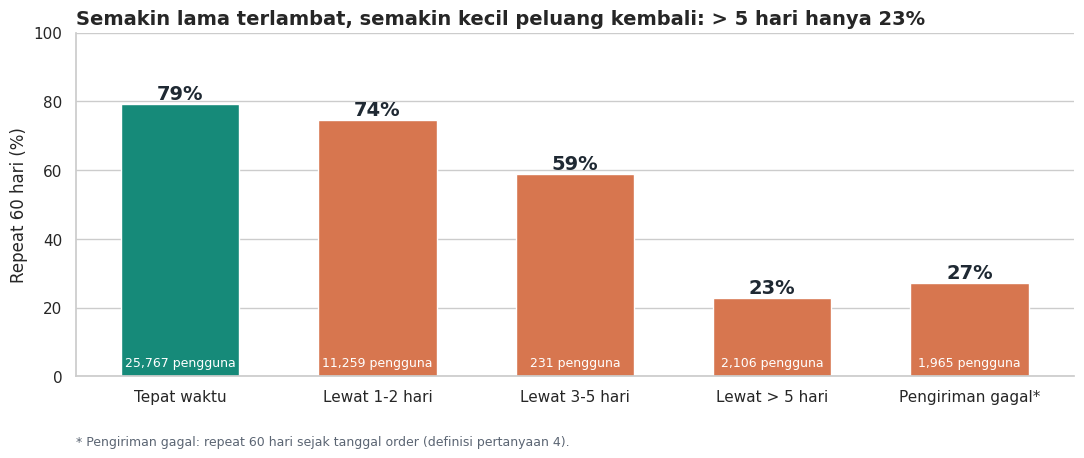

In [71]:
# Grafik eksekutif 4: repeat 60 hari menurut lama keterlambatan order pertama + pengiriman gagal
dose = cohort60.groupby(pd.cut(cohort60['days_over_sla'], [-1, 0, 2, 5, 100],
                               labels=['Tepat waktu', 'Lewat 1-2 hari', 'Lewat 3-5 hari', 'Lewat > 5 hari']),
                        observed=True)['repeat'].agg(['size', 'mean'])
fr_ex = fo.groupby('status_kirim')['rep'].agg(['size', 'mean'])
dose.loc['Pengiriman gagal*'] = fr_ex.loc['failed', ['size', 'mean']].values
fig, ax = plt.subplots(figsize=(11, 4.8))
colors_d = [TEAL, ORANGE, ORANGE, ORANGE, ORANGE]
bars = ax.bar(dose.index.astype(str), dose['mean'] * 100, color=colors_d, width=.6)
for b, (_, r) in zip(bars, dose.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r['mean'] * 100 + 1.5, f"{r['mean']*100:.0f}%", ha='center',
            fontsize=14, fontweight='bold', color=INK)
    ax.text(b.get_x() + b.get_width() / 2, 3, f"{int(r['size']):,} pengguna", ha='center', fontsize=9, color='white')
ax.set_ylim(0, 100); ax.set_ylabel('Repeat 60 hari (%)')
ax.text(0, -0.2, '* Pengiriman gagal: repeat 60 hari sejak tanggal order (definisi pertanyaan 4).', transform=ax.transAxes,
        fontsize=9, color=MUTED)
ax.set_title('Semakin lama terlambat, semakin kecil peluang kembali: > 5 hari hanya 23%', loc='left', fontsize=14, fontweight='bold')
clean_axes(ax); plt.tight_layout(); plt.show()

### 5. Kurva Retensi: Kapan Gap Terbentuk
**Keputusan yang didukung:** kapan intervensi dilakukan. Jendela efektif adalah 30 hari pertama setelah barang diterima.

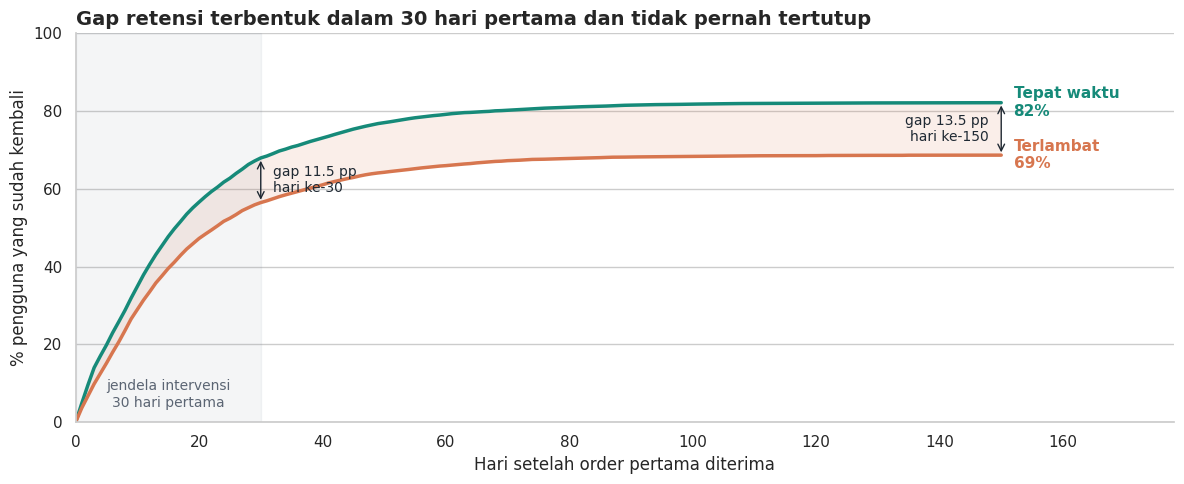

In [72]:
# Grafik eksekutif 5: kurva retensi kumulatif harian tepat waktu vs terlambat (kohort 150 hari, bagian 0.1)
days = np.arange(0, MAX_DAY + 1)
curves = {f: [coh.loc[coh['fulfillment'].eq(f), 'first_repeat_day'].le(d).mean() * 100 for d in days]
          for f in ['Tepat waktu', 'Terlambat']}
on, lt_c = np.array(curves['Tepat waktu']), np.array(curves['Terlambat'])
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(days, lt_c, on, color=ORANGE, alpha=.12, lw=0)
ax.plot(days, on, color=TEAL, lw=2.5); ax.plot(days, lt_c, color=ORANGE, lw=2.5)
ax.text(days[-1] + 2, on[-1], f'Tepat waktu\n{on[-1]:.0f}%', color=TEAL, va='center', fontsize=11, fontweight='bold')
ax.text(days[-1] + 2, lt_c[-1], f'Terlambat\n{lt_c[-1]:.0f}%', color=ORANGE, va='center', fontsize=11, fontweight='bold')
for d in (30, 150):
    ax.annotate('', xy=(d, lt_c[d]), xytext=(d, on[d]), arrowprops=dict(arrowstyle='<->', color=INK, lw=1))
    ax.text(d - 2 if d == 150 else d + 2, (on[d] + lt_c[d]) / 2, f'gap {on[d]-lt_c[d]:.1f} pp\nhari ke-{d}',
            ha='right' if d == 150 else 'left', va='center', fontsize=10, color=INK)
ax.axvspan(0, 30, color=GRAY, alpha=.08); ax.text(15, 4, 'jendela intervensi\n30 hari pertama', ha='center', fontsize=10, color=MUTED)
ax.set_xlim(0, MAX_DAY + 28); ax.set_ylim(0, 100)
ax.set_xlabel('Hari setelah order pertama diterima'); ax.set_ylabel('% pengguna yang sudah kembali')
ax.set_title('Gap retensi terbentuk dalam 30 hari pertama dan tidak pernah tertutup', loc='left', fontsize=14, fontweight='bold')
clean_axes(ax); plt.tight_layout(); plt.show()

### 6. Matriks Prioritas Rekomendasi
**Keputusan yang didukung:** urutan eksekusi rekomendasi. Sumbu horizontal adalah skor usaha implementasi 1–5 dan sumbu vertikal keyakinan data. Nilai per tahun ditulis pada label dengan dasarnya masing-masing (penghematan promo atau GMV dari retensi) dan tidak digambar pada satu sumbu, karena satuannya berbeda. **Skor usaha dan keyakinan adalah penilaian analis yang perlu dikalibrasi bersama tim Operations dan Growth.**

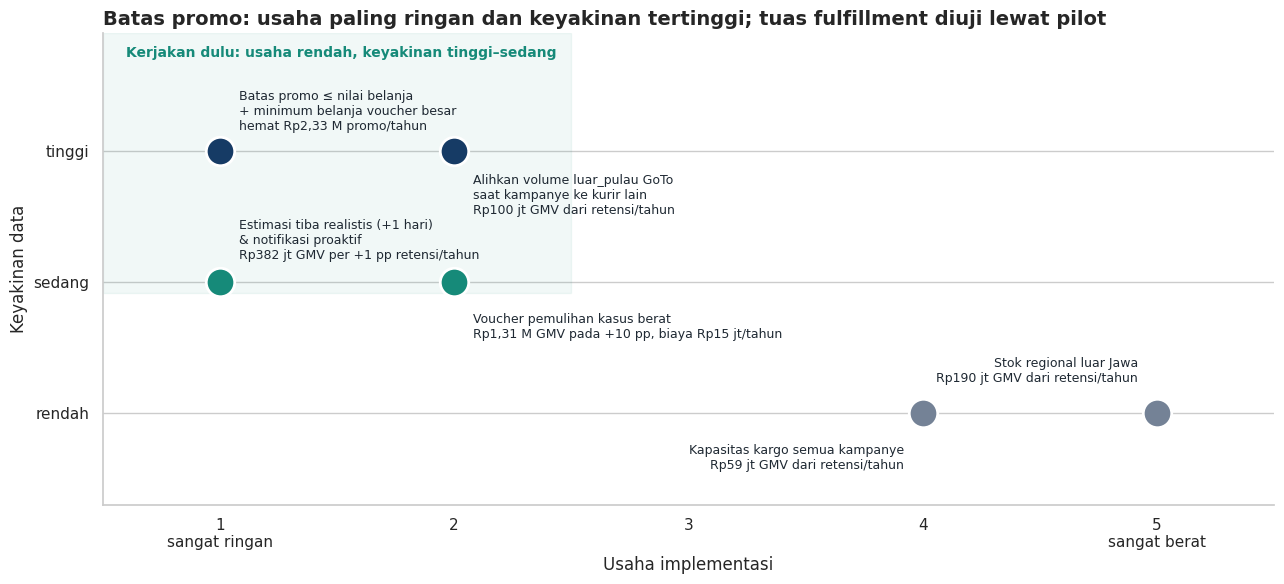

In [73]:
# Grafik eksekutif 6: matriks prioritas (usaha vs keyakinan data; nilai per tahun pada label dengan dasarnya)
conf_y = {'tinggi': 3, 'sedang': 2, 'rendah': 1}
conf_color = {'tinggi': PRIMARY, 'sedang': TEAL, 'rendah': GRAY}
fig, ax = plt.subplots(figsize=(13, 6))
ax.axvspan(0.5, 2.5, ymin=0.45, ymax=1, color=TEAL, alpha=.06)
ax.text(0.6, 3.72, 'Kerjakan dulu: usaha rendah, keyakinan tinggi–sedang', fontsize=10, color=TEAL, fontweight='bold')
label_pos = {0: (1.08, 3.30, 'left'), 1: (2.08, 2.66, 'left'), 2: (1.08, 2.32, 'left'),
             3: (2.08, 1.66, 'left'), 4: (4.92, 1.32, 'right'), 5: (3.92, 0.66, 'right')}
for i, r in priority.iterrows():
    x, y = r['Usaha (1-5)'], conf_y[r['Keyakinan data']]
    ax.scatter(x, y, s=420, color=conf_color[r['Keyakinan data']], edgecolor='white', lw=2, zorder=3)
    tx, ty, ha = label_pos[i]
    ax.text(tx, ty, f"{r['Rekomendasi']}\n{r['Nilai per tahun']}/tahun", fontsize=9, color=INK, ha=ha, va='center')
ax.set_xlim(0.5, 5.5); ax.set_ylim(0.3, 3.9)
ax.set_xticks(range(1, 6), ['1\nsangat ringan', '2', '3', '4', '5\nsangat berat'])
ax.set_yticks([1, 2, 3], ['rendah', 'sedang', 'tinggi'])
ax.set_xlabel('Usaha implementasi'); ax.set_ylabel('Keyakinan data')
ax.set_title('Batas promo: usaha paling ringan dan keyakinan tertinggi; tuas fulfillment diuji lewat pilot',
             loc='left', fontsize=14, fontweight='bold')
clean_axes(ax); plt.tight_layout(); plt.show()


### 7. Skenario Target Retensi
**Keputusan yang didukung:** besaran target perbaikan fulfillment. Setiap batang menunjukkan GMV per tahun bila sebagian gap retensi akibat keterlambatan berhasil ditutup (horizon GMV 365 hari, bagian 5.1).

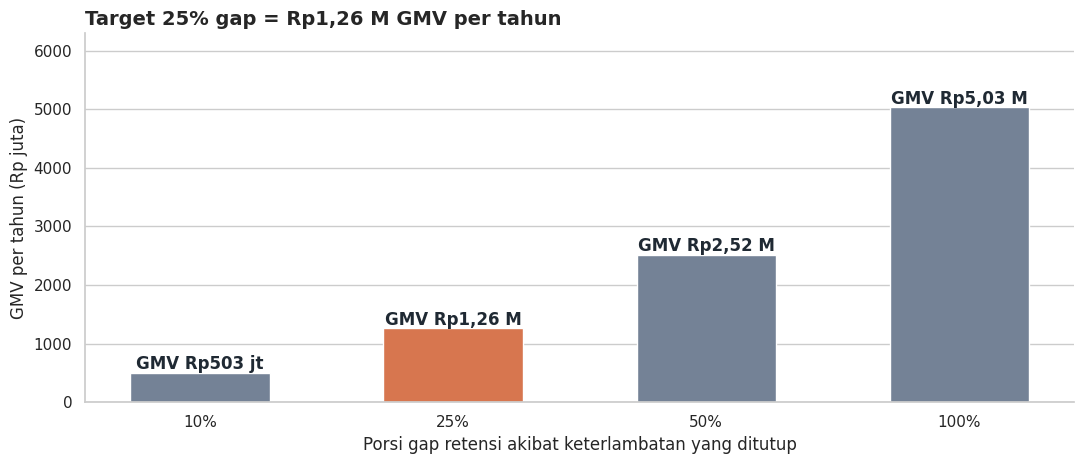

In [74]:
# Grafik eksekutif 7: skenario porsi gap keterlambatan yang ditutup -> GMV per tahun
fig, ax = plt.subplots(figsize=(11, 4.8))
labels_s = scen_ex['Gap ditutup'].map('{:.0%}'.format)
colors_s = [GRAY, ORANGE, GRAY, GRAY]
bars = ax.bar(labels_s, scen_ex['GMV per tahun'] / 1e6, color=colors_s, width=.55)
for b, (_, r) in zip(bars, scen_ex.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, r['GMV per tahun'] / 1e6 + 60, f"GMV {rp_short(r['GMV per tahun'])}",
            ha='center', fontsize=12, fontweight='bold', color=INK)
ax.set_ylim(0, EX['gmv_at_risk'] / 1e6 * 1.25); ax.set_ylabel('GMV per tahun (Rp juta)')
ax.set_xlabel('Porsi gap retensi akibat keterlambatan yang ditutup')
t25 = scen_ex.loc[scen_ex['Gap ditutup'].eq(.25)].iloc[0]
ax.set_title(f"Target 25% gap = {rp_short(t25['GMV per tahun'])} GMV per tahun",
             loc='left', fontsize=14, fontweight='bold')
clean_axes(ax); plt.tight_layout(); plt.show()

<a id="PENUTUP"></a>
# <span style="color:darkorange">Penutup</span>


<a id="Kesimpulan"></a>
## <span style="color:darkorange">Kesimpulan</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
<strong>Jawaban atas pertanyaan utama: ya — data menunjukkan bahwa masalah fulfillment berkaitan dengan hilangnya peluang repeat revenue, dan insentif promo tidak terlihat mengimbanginya.</strong> Kesimpulan ini bersifat asosiasi, bukan sebab-akibat.
</p>

1. **Promo bukan pembeda retensi maupun nilai.** Pemakaian, nominal, rasio, maupun jenis voucher pada order pertama tidak berbeda antara pengguna yang kembali dan yang churn, di semua kanal akuisisi. Efek promo terhadap repeat 60 hari, jika ada, kemungkinan kurang dari ±1 pp, dan promo juga tidak menaikkan frekuensi, AOV, maupun GMV 365 hari (bagian 6.6).
2. **Pengalaman pengiriman adalah faktor terkuat yang teridentifikasi.** Keterlambatan menurunkan repeat 60 hari ±13 pp (−13,1 pp mentah; −12,5 pp setelah stratifikasi; muncul di seluruh 29 segmen), semakin buruk seiring lamanya keterlambatan, dan paling ekstrem pada pengiriman gagal (27,1%) serta keterlambatan yang dikeluhkan pelanggan (17,9%). Dampaknya tidak bertumpuk dan dapat dipulihkan: yang menentukan adalah pengalaman terakhir (bagian 6.4). Penanganan tiket yang lebih cepat tidak terlihat memulihkan setelah keparahan kasus dikontrol (bagian 6.3).
3. **Risiko terkonsentrasi pada kelas SLA, bukan jenis layanan maupun geografi.** Pengiriman berlabel zona luar_pulau (SLA rata-rata 7,5 hari) memiliki tingkat keterlambatan tertinggi (42,9%) dan repeat terendah. Namun label ini tidak cocok dengan rute kota seller → kota tujuan dan tidak dijelaskan oleh perbedaan gudang (bagian 6.1), sehingga tidak dapat dibaca sebagai pengiriman antarpulau. Tingkat keterlambatan juga hampir sama di semua jenis layanan kurir (33,9–35,4%); order pertama saat kampanye juga sedikit lebih berisiko (keterlambatan 36,9% vs 33,7%; repeat −1,9 pp pada status ketepatan yang sama).
4. **Pengeluaran promo tidak efisien.** Promo ±Rp6,39 miliar per tahun (4,45% GMV completed), dan 59% di antaranya terserap oleh 4,4% order dengan promo melebihi nilai belanja (median promo ±3,2× median belanja) tanpa retensi yang lebih baik. Pola ini tidak dijelaskan oleh kemungkinan `total_amount` bernilai net. Sumbernya adalah voucher Rp400 ribu–Rp1 juta (80% anggaran promo) yang nominalnya tidak berkaitan dengan nilai belanja dan tersebar acak di seluruh pengguna dan seller. Ini masalah aturan voucher, bukan penyalahgunaan (bagian 6.2).
5. **Lonjakan keterlambatan saat kampanye bersumber dari GoTo Logistics pada label luar_pulau** (38,6% → 67,7%), sementara kurir lain tetap ±39,5%. Tanpa selisih ini, keterlambatan luar_pulau saat kampanye 40,0%, bukan 50,6% (bagian 6.7). Seller, produk, dan jenis layanan tidak berkaitan dengan keterlambatan.
6. **Sebagian besar keterlambatan adalah janji yang terlalu optimistis.** 81,5% keterlambatan hanya lewat 1–2 hari; janji +1 hari menurunkan tingkat keterlambatan dari 34,9% ke 12,2%. Ekor berat (lewat 8–18 hari, 5,9% pengiriman) adalah kasus yang paling merusak retensi (±23%) (bagian 6.5).
7. **Besaran peluang:** GMV 365 hari berisiko ±Rp5,03 miliar per tahun; pada horizon 60 hari, ±Rp2,10 miliar GMV repeat berisiko akibat keterlambatan dan ±Rp1,32 miliar akibat pengiriman gagal pada kohort ±22 bulan; Rp246 juta promo telah dikeluarkan untuk pengguna terlambat yang tidak kembali.

**Keterbatasan:** analisis observasional (promo dan keterlambatan tidak ditetapkan secara acak); GMV adalah proksi nilai transaksi, bukan pendapatan bersih atau laba; porsi promo yang ditanggung platform vs seller, take rate, dan margin tidak tersedia, sehingga nilai finansial dinyatakan dalam GMV dan rupiah promo, bukan pendapatan atau laba; "order pertama" adalah order pertama yang teramati sejak Januari 2023; indikasi penurunan repeat pada brief tidak tercermin pada dataset ini; label `shipping_zone` tidak mencerminkan geografi dan asal gudang tidak tersedia; dan analisis *service recovery* (bagian 6.3) hanya mengontrol kategori keluhan dan lama keterlambatan.

<a id="Rekomendasi"></a>
## <span style="color:darkorange">Rekomendasi</span>
### <span style="color:darkorange">Rekomendasi Bisnis</span>

| Prioritas | Rekomendasi | Dasar temuan | Dampak finansial per tahun (skala dataset) | Ukuran keberhasilan |
|---|---|---|---|---|
| 1 | **Perbaiki aturan voucher.** Promo tidak boleh melebihi nilai belanja, voucher ≥ Rp400 ribu wajib memiliki minimum belanja, dan audit diarahkan ke konfigurasi kampanye yang menerbitkan voucher besar (bukan akun satu per satu). | 4,4% order menyerap 59% promo; 96% berasal dari voucher Rp400 rb–Rp1 jt (80% anggaran) yang nominalnya tidak berkaitan dengan nilai belanja dan tersebar acak (bukan abuse); tidak ada manfaat retensi maupun GMV 365 hari | Hemat ±Rp2,33 miliar promo (±37% anggaran); risiko terburuk GMV ±Rp1,44 miliar bila seluruh order terdampak batal | Anggaran promo per tahun (±Rp6,39 → ±Rp4,05 miliar), repeat 60 hari tidak turun |
| 2 | **Voucher pemulihan terarah untuk kasus berat** — terlambat > 5 hari, pengiriman pertama gagal, atau mengeluhkan keterlambatan — dibayar saat pengguna kembali berbelanja, didanai dari penghematan prioritas 1, **dan pastikan order berikutnya dikirim tepat waktu** (prioritas kurir). | Repeat kelompok ini hanya 25,0% (22,6% / 27,1% / 17,9%); order kedua yang tepat waktu memulihkan retensi (78,8% vs 79,7%, bagian 6.4); mempercepat tiket saja tidak (bagian 6.3) | Pada +10 pp: tambahan GMV ±Rp1,31 miliar, biaya voucher ±Rp15,4 juta; kelayakan dihitung ulang dengan margin aktual | Repeat 60 hari kelompok perlakuan vs kontrol |
| 3 | **Estimasi tiba yang realistis (SLA + 1 hari) dan notifikasi proaktif**, serta deteksi dini paket yang belum tiba H+2 dari SLA, terutama dalam 30 hari pertama setelah order pertama. | 81,5% keterlambatan hanya lewat 1–2 hari; janji +1 hari: 34,9% → 12,2% terlambat; ekor berat 8–18 hari retensi ±23%; gap retensi terbentuk dalam 30 hari pertama | ±Rp382 juta GMV per +1 pp retensi; biaya hampir nol | Repeat 60 hari, keluhan keterlambatan |
| 4 | **Alihkan volume label luar_pulau dari GoTo Logistics ke JNE/SiCepat/AnterAja saat kampanye** (atau tambah kapasitas GoTo khusus kelas SLA panjang), dan prioritaskan order pertama berlabel luar_pulau bila biaya upgrade sepadan dengan nilai retensinya. | GoTo Logistics pada label luar_pulau saat kampanye 67,7% terlambat vs kurir lain 39,5%; tanpa selisih ini 50,6% → 40,0% (bagian 6.7) | ±669 pengiriman terlambat lebih sedikit per tahun; nilai retensi order pertama ±Rp100 juta GMV per tahun, manfaat utama pada pengalaman seluruh pengguna | Keterlambatan label luar_pulau saat kampanye per kurir |
| 5 | **Validasi melalui pilot A/B sebelum skala penuh** (termasuk dampak janji +1 hari terhadap konversi checkout), serta lengkapi data porsi promo platform vs seller, gudang asal, rute, dan kapasitas hub. | Seluruh dampak retensi berbasis asosiasi | — | Selisih repeat dan GMV kelompok perlakuan vs kontrol |

**Belum direkomendasikan:** stok regional di luar Jawa (±Rp190 juta GMV per tahun dari retensi, kecil dibanding biaya tetap gudang, dan dasar geografisnya tidak didukung karena label zona tidak mencerminkan lokasi), kapasitas kargo tambahan untuk semua pengiriman kampanye (±Rp59 juta GMV per tahun dari retensi untuk ±6.344 paket kampanye luar_pulau), dan voucher untuk semua pengguna terlambat (66,2% pengguna terlambat tetap kembali tanpa voucher, sehingga sebagian besar biaya tidak menambah retensi). Opsi ini dapat dievaluasi ulang bila tersedia data penghematan ongkos kirim, kenaikan konversi, dan biaya aktual.
### <span style="color:darkorange">Rekomendasi Kualitas Data</span>
<p style="text-indent: 30px; font-family: 'Roboto', sans-serif; font-size: 16px; line-height: 1.5;">
Sesuai brief, celah kualitas data yang signifikan dilaporkan sebagai bagian dari rekomendasi. Berdasarkan proses cleansing:
</p>

1. **Definisi `total_amount` dan `promo_amount`** — 11.681 transaksi (11.667 pada pengguna terdaftar) memiliki promo melebihi total belanja dan menyerap 59% anggaran promo, dengan nominal promo terkonsentrasi di Rp400 ribu–Rp1 juta. Data tidak mendukung kemungkinan `total_amount` sudah dikurangi promo; konfirmasi definisi kedua kolom, apakah `promo_amount` mencakup cashback, dan porsi promo yang ditanggung platform vs seller.
2. **Nominal ekstrem dan tidak valid** — 384 transaksi ≥ Rp200 juta (45,02% nilai belanja completed) dikeluarkan dari analisis, dan 390 transaksi dengan `total_amount` negatif (termasuk 58 refund/retur/batal) dikarantina; keduanya perlu verifikasi ke sistem sumber. Penyesuaian nominal akibat refund sebaiknya dicatat di tabel tersendiri.
3. **Konflik primary key** — 16 `order_id` transaksi dan 12 `order_id` pengiriman memiliki lebih dari satu record dengan atribut berbeda.
4. **Tanggal transaksi** — 792 `order_date` bernilai 1970/2030 dikoreksi dari `order_id`; konfirmasi sumber tanggal otoritatif.
5. **Integritas relasi & urutan tanggal** — 399 transaksi merujuk ke `user_id` yang tidak ada di tabel users; 531 pengiriman (140 di antaranya juga dengan `delivery_date`) dan 5 tiket tercatat sebelum `order_date` dengan selisih konsisten 1–4 hari, sehingga sumber pencatatan `dispatch_date`, `delivery_date`, dan `ticket_date` perlu diperiksa.
6. **Data pengiriman** — `delivery_date` terisi pada 100% record termasuk status `in_transit`, `failed`, dan `returned` (konfirmasi apakah tanggal estimasi atau aktual); 9.976 nama kurir kosong padahal 7.049 di antaranya memiliki rating; dan label `courier_service_type` tidak mencerminkan kecepatan (instant/same_day memiliki SLA hingga 10 hari dan durasi aktual sama dengan reguler), sehingga definisi layanan dan SLA perlu divalidasi di sumber. Tingkat keterlambatan juga hampir sama di semua jenis layanan (33,9–35,4%).
7. **Standardisasi input** — metode pembayaran dan nama kota (Jakarta) perlu divalidasi di sumber (mis. dropdown) agar tidak terpecah; 952 pengguna memiliki provinsi yang tidak sesuai kota, sehingga provinsi sebaiknya diturunkan otomatis dari kota.
8. **Definisi tanggal pada tabel dimensi** — 792 `last_active_date` mendahului `join_date` dan 78,2% pengguna bertransaksi setelah `last_active_date`; 63.548 transaksi (23,7%) terjadi sebelum `seller_join_date`. Definisi kedua kolom perlu dikonfirmasi sebelum dipakai untuk analisis aktivitas pengguna atau umur toko.
9. **Konsistensi status** — sekitar 21 ribu order `completed` memiliki pengiriman `failed`, `in_transit`, atau `returned`, sementara order `refund`/`returned` banyak yang `delivered`; sinkronisasi status order dan pengiriman perlu diperiksa di sumber.
10. **Label `shipping_zone`** — label zona tidak cocok dengan rute kota seller → kota tujuan (cocok 30,4%, sama dengan acak; mis. 3.164 pengiriman Jakarta → Jakarta berlabel luar_pulau) dan tidak dijelaskan oleh perbedaan gudang. Konfirmasi cara label ditentukan dan tambahkan kolom `origin_warehouse_city` agar analisis rute dan pemetaan lokasi dapat dilakukan.